# **Proyecto Aplicado — Predicción del Puntaje Global en las Pruebas Saber 11**
## **Deep Learning · Fases 1, 2, 3 y 4**

Este proyecto estudia la predicción del puntaje global de Saber 11 mediante **redes neuronales con aprendizaje por transferencia y ajuste fino** (*fine-tuning*). Su propósito es analizar la capacidad de las representaciones neuronales para aprender relaciones entre condiciones socioeconómicas, familiares, institucionales y geográficas y el desempeño en el examen.

El cuaderno integra el **entendimiento del negocio y la carga de datos**, el **entendimiento y la preparación de los datos** y el **diseño e implementación experimental**. Compara MLP, ResNet tabular y FT-Transformer adaptado, con transferencia entre cohortes y comprobaciones de funcionamiento. La fase 4 ejecuta el entrenamiento comparativo, la búsqueda con Optuna, la evaluación reservada, la persistencia y la aplicación del modelo. Las cuatro fases comparten los mismos datos y una única secuencia de ejecución.

**Inicio del proyecto:** jueves 8 de octubre de 2026. **Entrega de la fase 1:** jueves 15 de octubre de 2026. **Fecha de carga y verificación de los datos:** 14 de octubre de 2026.

La fuente es **Resultados únicos Saber 11**, publicada por el Icfes en Datos Abiertos de Colombia. La versión de estudio se distribuye desde el repositorio del proyecto en GitHub. Este cuaderno incluye el código de descarga, verificación de integridad, descompresión y lectura de todos los registros.

| Fase | Nombre | Producto |
|---|---|---|
| 1 | Entendimiento del negocio y carga de datos | Contexto, objetivos, alcance, cronograma y carga verificada |
| 2 | Entendimiento y preparación de los datos | Exploración, decisiones de calidad y datos preparados |
| 3 | Diseño e implementación | Diseño neuronal y mecanismo de transferencia |
| 4 | Entrenamiento, validación y entrega final | Comparación, Optuna, prueba reservada, persistencia y conclusiones |

**Entrega de la fase 2:** jueves 22 de octubre de 2026. **Verificación de la preparación:** 19 de octubre de 2026. **Entrega de la fase 3:** jueves 29 de octubre de 2026. **Verificación del diseño e implementación:** 26 de octubre de 2026. **Entrega final de la fase 4:** jueves 5 de noviembre de 2026. La evaluación final se integra en esta cuarta entrega, después de cerrar todas las decisiones mediante validación.
### **Resultado principal del proyecto**

La selección por validación conserva una **MLP entrenada desde cero con todos los registros de entrenamiento**. En los **339.584 registros de prueba** obtiene **MAE de 29,88 puntos, RMSE de 37,56 y R² de 0,431**; reduce el MAE en **25,79 %** frente a la mediana de entrenamiento. El ajuste fino mejora la transferencia congelada, pero no supera en promedio al control entrenado solo en destino. La propuesta de Optuna tampoco mejora el resultado confirmado, por lo que se conserva la configuración inicial. El análisis final documenta estas decisiones, los errores por grupos y puntajes extremos y el alcance de la validación interna.

## Sobre esta edición

Esta edición conserva las fases, el código y la discusión de la entrega académica. Las salidas guardadas se limitan a resultados agregados y figuras seleccionadas. Los resultados corresponden a la ejecución original.

**Reproducción.** La reproducción del entrenamiento requiere los insumos y las particiones del corte Saber 11, TensorFlow/Keras y Optuna. Los bloques documentan la selección, el entrenamiento y la evaluación en el conjunto reservado.

[Volver al README del proyecto](../README.md)


## Integrantes del equipo

- Manuela Zapata Jiménez
- David Cardona Duque

---
# **Fase 1 — Entendimiento del negocio y carga de datos**

Esta fase investiga el contexto educativo, define el objetivo del negocio y del proyecto, identifica la fuente y verifica la cantidad y calidad inicial de los datos cargados. **CRISP-DM** orienta el trabajo como una metodología iterativa (Chapman et al., 2000), organizada en las cuatro entregas integradas del proyecto. El entendimiento y la preparación se reúnen en la segunda entrega; el modelamiento se distribuye entre diseño, implementación, entrenamiento y validación; la evaluación y comunicación integran la entrega final.

## **1. Marco del proyecto**
### **1.1. Trasfondo del negocio**
#### **Contexto**

En Colombia, el examen **Saber 11** es una evaluación externa estandarizada aplicada por el **Instituto Colombiano para la Evaluación de la Educación (Icfes)** a quienes finalizan la educación media y a otras personas habilitadas para presentarlo. La guía de orientación 2026-2 describe cinco pruebas: **Lectura Crítica, Matemáticas, Sociales y Ciudadanas, Ciencias Naturales e Inglés**, además de cuestionarios de contexto. El puntaje global se reporta en una escala de **0 a 500**; los resultados de las áreas forman parte de su cálculo, como documenta la metodología de resultados individuales (Icfes, 2020a).

Los resultados aportan información sobre el desempeño educativo y sirven como referente para procesos de ingreso a la educación superior, seguimiento de la calidad y estudios nacionales, territoriales e institucionales. La literatura colombiana identifica asociaciones del rendimiento con condiciones familiares, socioeconómicas y escolares. Cerquera Losada et al. (2016) estudian el logro en matemáticas en varias regiones, y Rodríguez Rosero et al. (2021) analizan la educación media en Nariño. Sus resultados justifican examinar estas dimensiones, sin asumir que describan exactamente todas las cohortes o que prueben relaciones causales en este dataset.

Las brechas educativas hacen pertinente este problema. En PISA 2018, la diferencia de lectura entre estudiantes socioeconómicamente favorecidos y desfavorecidos en Colombia fue de **86 puntos** (OECD, 2019). Este antecedente corresponde a otra evaluación y población: contextualiza la desigualdad, pero no es una cifra de Saber 11. En este proyecto se estudiarán las asociaciones presentes en los registros disponibles mediante representaciones neuronales.

#### **Cliente o beneficiarios potenciales**

Los beneficiarios potenciales son actores del sistema educativo que pueden utilizar el conocimiento producido para estudiar el desempeño y sus diferencias entre grupos.

| Beneficiario potencial | Necesidad | Utilidad esperada |
|---|---|---|
| Icfes | Estudiar patrones del desempeño y condiciones de contexto | Evidencia predictiva reproducible y análisis de sus límites |
| Ministerio de Educación Nacional | Comprender brechas educativas | Insumos para formular preguntas de política y acompañamiento |
| Secretarías departamentales y municipales | Conocer diferencias territoriales e institucionales | Análisis agregado con cobertura y errores visibles |
| Instituciones educativas | Examinar necesidades de apoyo | Referente exploratorio para acompañamiento académico |
| Investigadores en educación | Reproducir análisis del rendimiento | Datos trazables, código y documentación de decisiones |

#### **Dominio y problema a solucionar**

El proyecto pertenece a la **analítica educativa**, en la intersección de *Educational Data Mining*, *Learning Analytics* y aprendizaje profundo (Romero & Ventura, 2020). La unidad prevista es un registro de examinando por periodo; su unicidad se verifica en la carga. El problema se formula como **regresión supervisada de `PUNT_GLOBAL`** a partir de variables socioeconómicas, familiares, institucionales y geográficas.

La relevancia está en reconocer patrones asociados al rendimiento, explorar la viabilidad de una estimación anticipada y producir evidencia para el estudio de brechas. La importancia predictiva de una variable no demostrará que cambiarla cause una mejora en el puntaje. El volumen de registros tampoco garantiza representatividad, actualidad ni generalización a nuevas cohortes.

### **1.2. Objetivos del negocio y del proyecto**

#### **Objetivo del negocio**

Producir información educativa reproducible sobre la asociación entre las condiciones de contexto de los estudiantes y su puntaje global, que pueda servir como insumo exploratorio para estudiar necesidades de acompañamiento y diferencias entre grupos. Su utilidad se valorará por la claridad de la evidencia, la cobertura y los límites del análisis; el proyecto no mide aún el efecto de una intervención educativa.

#### **Pregunta del proyecto**

**¿En qué medida una red neuronal que reutilice representaciones aprendidas y se adapte mediante ajuste fino permite estimar el puntaje global de Saber 11 a partir de variables de contexto, y cómo cambia su desempeño frente a una red entrenada desde cero en registros no utilizados para el ajuste?**

#### **Objetivo general del proyecto**

Desarrollar y evaluar un modelo neuronal de regresión para estimar `PUNT_GLOBAL` con el conjunto Resultados únicos Saber 11 del Icfes, incorporando aprendizaje por transferencia y fine-tuning, con controles de fuga de información, validación interna, análisis por cohortes y estudio de errores.

#### **Objetivos específicos del proyecto completo**

1. Investigar el contexto de Saber 11, delimitar el problema, documentar la fuente y cargar íntegramente la versión seleccionada.
2. Comprender y preparar los datos, definiendo comparabilidad temporal, población con etiqueta, tratamiento de faltantes, duplicados y disponibilidad de los predictores.
3. Diseñar e implementar una red para datos tabulares y un mecanismo verificable de preentrenamiento, transferencia y ajuste fino, sin fijar todavía una arquitectura.
4. Entrenar y validar la propuesta frente a una red desde cero y una referencia simple, usando las mismas particiones y métricas.
5. Evaluar MAE, RMSE y R² en prueba, estudiar errores por grupos y comunicar resultados, recursos utilizados y limitaciones.

#### **Objetivos verificables de esta primera entrega**

| Objetivo de la entrega | Evidencia en el cuaderno |
|---|---|
| Investigar el contexto y definir el objetivo | Contexto, beneficiarios, pregunta, objetivos y sustento teórico |
| Identificar fuentes y cargar los datos | Ficha de origen, manifiesto, descarga verificada y lectura completa por bloques |
| Verificar cantidad y calidad inicial | Dimensiones, esquema, faltantes, objetivo, periodos y repetición de claves |
| Documentar proceso y fuentes | Protocolo reproducible, salidas ejecutadas, decisiones y bibliografía |

### **1.3. Alcance y forma de uso**

#### **Solución propuesta**

La solución académica será una red neuronal para regresión sobre datos tabulares, con una representación reutilizable de los predictores y una salida escalar para `PUNT_GLOBAL`. La ruta principal estudiará transferencia entre cohortes del **mismo conjunto de datos**. El tipo de representación, la profundidad de la red, el procedimiento de preentrenamiento y las capas ajustadas se decidirán en las fases 2 y 3 a partir de la calidad, compatibilidad y recursos disponibles.

#### **Incluye el proyecto completo**

- Análisis de las 51 variables originales y definición posterior del conjunto de predictores admisibles.
- Preparación de faltantes, variables categóricas y numéricas; las transformaciones se ajustarán únicamente sobre entrenamiento.
- Ingeniería de características justificada, conservando los datos originales y documentando cada cambio.
- Diseño neuronal, preentrenamiento, transferencia y ajuste fino con controles experimentales.
- Evaluación con MAE, RMSE y R²; análisis de errores, contribución predictiva de variables y diferencias entre grupos.
- Documentación de datos, pesos, particiones, hiperparámetros y consumo de recursos.

#### **Límites**

La salida se limita al puntaje global. No se predicen las subpruebas, no se atribuye causalidad, no se incorporan nuevos registros externos ni se despliega un servicio en producción. El producto no se utilizará para admisión, exclusión o decisiones automáticas sobre estudiantes. La primera entrega se limita al planteamiento y a la carga: no limpia, imputa, deduplica, divide ni entrena los datos.

#### **Escenario de uso y prevención de fuga**

Se plantea una estimación con atributos que podrían conocerse antes del examen. **El CSV no demuestra por sí mismo esa disponibilidad anticipada**: parte de la información procede de cuestionarios aplicados con el examen, por lo que una utilización real requeriría comprobar la fecha de captura de cada atributo. En este trabajo se estudia primero la viabilidad retrospectiva del escenario.

`PUNT_GLOBAL` será exclusivamente la etiqueta. Se excluirán de los predictores `PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_SOCIALES_CIUDADANAS`, `PUNT_C_NATURALES`, `PUNT_LECTURA_CRITICA` y `DESEMP_INGLES`, que dependen del mismo examen. `ESTU_CONSECUTIVO` se reservará para trazabilidad; `ESTU_ESTADOINVESTIGACION` requiere tratamiento como información administrativa posterior. Los códigos geográficos o institucionales no se interpretarán como magnitudes numéricas por el hecho de tener dígitos. Estas reglas se documentan ahora y se implementarán al preparar las entradas.

Los beneficiarios podrán explorar asociaciones y errores agregados, reproducir el procedimiento y estudiar su adaptación a cohortes posteriores. Se comunicarán las condiciones bajo las cuales una predicción tiene soporte y las situaciones en que su generalización permanece sin evaluar.

### **1.4. Sustento teórico y propuesta neuronal abierta**

#### Redes neuronales para la predicción del puntaje de Saber 11

La predicción de `PUNT_GLOBAL` se formula como un problema de regresión supervisada: cada registro describe el contexto de un examinando y la salida es una estimación numérica de su puntaje. El propósito académico del proyecto es estudiar redes neuronales para aprender representaciones de variables socioeconómicas, familiares, institucionales y geográficas, e investigar su adaptación mediante aprendizaje por transferencia y ajuste fino (*fine-tuning*). El aprendizaje profundo permite estudiar representaciones aprendidas y relaciones no lineales entre atributos de contexto. El modelamiento se centra en redes neuronales tabulares y en su adaptación entre cohortes del examen.

Existe un antecedente colombiano directamente relacionado con este dominio. Mosquera-Mosquera et al. (2024) utilizaron un perceptrón multicapa en el análisis del puntaje global de Saber 11 de 2020-2 y de sus relaciones con variables socioeconómicas y características de los colegios. Este trabajo respalda la pertinencia de explorar redes neuronales con información contextual del examen. Sin embargo, su objetivo analítico y su protocolo difieren del presente proyecto: no demuestra que una red profunda con transferencia logre un error determinado ni que sea superior para las cohortes que aquí se estudiarán. [Artículo original](https://educacioneningenieria.org/index.php/edi/article/download/1309/1227).

#### Representaciones tabulares, transferencia y ajuste fino

Los datos tabulares combinan atributos numéricos, categorías, códigos y ausencias; no deben tratarse como imágenes ni como secuencias de palabras sin una justificación. Las redes pueden aprender representaciones continuas de las categorías y relaciones no lineales entre atributos. Huang et al. (2020) presentan un ejemplo de representaciones tabulares contextualizadas y un procedimiento de preentrenamiento seguido de ajuste supervisado. Sus resultados en tareas de clasificación sustentan la existencia de ese mecanismo, pero no se extrapolarán como mejoras garantizadas en la regresión de Saber 11. Además, emplear una arquitectura con atención o denominada *Transformer* no implica disponer de pesos preentrenados: arquitectura, preentrenamiento y transferencia son decisiones distintas. [Prepublicación original](https://arxiv.org/abs/2012.06678).

La transferencia consiste en reutilizar conocimiento aprendido en un dominio o tarea de origen para mejorar el aprendizaje en un dominio o tarea de destino. Levin et al. (2023) estudiaron esta posibilidad con modelos neuronales tabulares y datos médicos, especialmente cuando existen datos auxiliares de origen y pocos registros etiquetados de destino. Su evidencia justifica investigar la reutilización de representaciones; no basta para asegurar beneficios en este proyecto, cuyo volumen y dominio son diferentes. El ajuste fino adaptaría parte o todos los pesos reutilizados a la regresión objetivo, con una salida escalar y un protocolo de optimización definido en fases posteriores. [Artículo original de ICLR](https://arxiv.org/abs/2206.15306).

Se estudiarán dos rutas, sin seleccionar todavía una arquitectura. La primera, coherente con el uso exclusivo del mismo dataset, sería preentrenar una representación con cohortes históricas y transferirla a cohortes posteriores del conjunto de entrenamiento. El origen y el destino se definirían por periodos y por compatibilidad del esquema. Se podrá considerar preentrenamiento supervisado en cohortes anteriores o autosupervisado sobre predictores, seguido de ajuste fino con etiquetas de la cohorte de destino. Esta es una propuesta metodológica que aún requiere comprobar disponibilidad y comparabilidad de las variables.

La segunda ruta sería evaluar la viabilidad de un modelo tabular previamente entrenado y publicado, si sus pesos, licencia, requisitos computacionales y representación son compatibles. CARTE muestra que pueden diseñarse modelos que transfieren conocimiento entre tablas con columnas diferentes, atendiendo las dificultades de correspondencia entre esquemas y entidades (Kim et al., 2024). Es un antecedente de factibilidad, no una selección del modelo del proyecto. Reutilizar pesos externos tampoco supondría añadir nuevas observaciones al dataset Saber 11; esa decisión se documentaría expresamente. [Publicación original de ICML](https://proceedings.mlr.press/v235/kim24d.html).

#### Validación futura y controles del planteamiento

La utilidad de la transferencia será una hipótesis contrastable. Wang et al. (2019) muestran que una fuente poco relacionada puede perjudicar el desempeño, fenómeno denominado transferencia negativa. Por ello se propone comparar una red entrenada desde cero con una versión que reutilice pesos, utilizando las mismas entradas, particiones y métricas. MAE, RMSE y R² permitirán evaluar el error y la variación explicada; también se registrarán tiempo, memoria y desempeño por subgrupos. La fase actual no presenta resultados de entrenamiento. [Artículo original de CVPR](https://openaccess.thecvf.com/content_CVPR_2019/html/Wang_Characterizing_and_Avoiding_Negative_Transfer_CVPR_2019_paper.html).

El protocolo inicial reserva conjuntos de validación y prueba mediante una partición aleatoria estratificada. Ambos conjuntos quedan fuera del preentrenamiento y del ajuste de transformaciones. Validación orientará la selección de hiperparámetros y la parada temprana; prueba se reserva exclusivamente para la evaluación final. La transferencia entre cohortes se estudia dentro de entrenamiento; evaluar una cohorte futura completa requerirá un corte temporal adicional y no se presupone a partir de esta partición. Todas las rutas excluirán de sus entradas `PUNT_GLOBAL`, los cinco puntajes de área y `DESEMP_INGLES`; los resultados del mismo examen no estarían disponibles en una predicción previa y el puntaje global se construye a partir de las subpruebas. También se revisarán identificadores y disponibilidad real de cada atributo antes del examen. Las predicciones se plantean como apoyo investigativo para reconocer patrones y orientar acompañamiento, sin atribuir causalidad ni convertir el perfil socioeconómico en una decisión automática sobre el estudiante.

#### **Formulación de la regresión y del ajuste fino**

De manera general, una representación neuronal del contexto puede expresarse como $h_\theta(\mathbf{x})$ y una cabeza de regresión como $g_\phi$, de modo que $\hat{y}=g_\phi(h_\theta(\mathbf{x}))$. Esta formulación no define una arquitectura particular. Una pérdida de referencia sería el error cuadrático medio, $\mathcal{L}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$; su elección final, regularización y tratamiento de errores extremos se justificarán posteriormente.

La transferencia reutilizaría los parámetros del codificador obtenidos en el origen. El ajuste fino partiría de esos pesos y actualizaría capas seleccionadas junto con la cabeza de regresión sobre el destino de entrenamiento. El preentrenamiento autosupervisado aprendería de los predictores sin usar el puntaje como entrada; el supervisado requeriría etiquetas comparables de la cohorte de origen. En ambos casos, validación y prueba permanecerán fuera de cualquier ajuste, incluido el preentrenamiento y la preparación de variables.

#### **Qué debe demostrar la transferencia en las fases posteriores**

| Elemento | Definición propuesta | Evidencia que se registrará |
|---|---|---|
| Origen | Cohortes históricas compatibles, dentro del conjunto de entrenamiento | Periodos, entradas, tarea de preentrenamiento y pesos obtenidos |
| Destino | Cohortes posteriores reservadas para ajuste dentro de entrenamiento | Población etiquetada y correspondencia de variables |
| Transferencia | Reutilizar el codificador aprendido en el origen | Identidad del checkpoint y pesos efectivamente cargados |
| Fine-tuning | Actualizar parte o todo el codificador, además de la cabeza de regresión | Capas entrenables, tasas de aprendizaje y cambios en pesos |
| Control | Misma familia neuronal entrenada desde cero | Mismas entradas, particiones y presupuesto de comparación |
| Evaluación | Conjuntos de validación y prueba independientes | MAE, RMSE, R², errores por grupos y costo computacional |

Entrenar solamente una cabeza nueva sobre un codificador congelado constituye una evaluación de extracción de características; para hablar de **ajuste fino** se documentará también la actualización de pesos reutilizados. La compatibilidad de `PUNT_GLOBAL` y de las variables entre periodos es un requisito previo. La estructura del examen cambió desde la segunda aplicación de 2014, como registra el antecedente histórico de la Resolución 503 (Icfes, 2014), de modo que no se asumirá una única escala comparable para toda la ventana histórica.

Como criterio técnico se buscará reducir MAE y RMSE respecto de una referencia simple y evaluar si la transferencia mejora la red desde cero. La media de entrenamiento puede servir como referencia de RMSE y la mediana como referencia de MAE. La fase 2 fijará población, particiones y criterios cuantitativos antes del ajuste; no se promete ahora un R² ni una ventaja de la transferencia.

### **1.5. Plan del proyecto**

El proyecto se organiza en **cuatro fases con entregas semanales**. El cronograma vincula actividades y productos verificables. El trabajo inicia el **jueves 8 de octubre de 2026** y todas las entregas ocurren en jueves. Cada intervalo conecta el inicio de trabajo con su fecha de entrega; el día de entrega funciona también como transición a la fase siguiente.

| Fase | Periodo de trabajo | Entrega | Actividades y producto verificable |
|---|---|---|---|
| **1. Entendimiento del negocio y carga de datos** | 8–15 oct 2026 | **Jueves 15 oct** | Contexto, objetivos, teoría inicial, fuente, descarga, carga, cantidad y calidad documentadas |
| **2. Entendimiento y preparación de los datos** | 15–22 oct 2026 | **Jueves 22 oct** | EDA, comparabilidad, faltantes, duplicados, variables admisibles y particiones sin fuga |
| **3. Diseño e implementación** | 22–29 oct 2026 | **Jueves 29 oct** | Arquitectura seleccionada, representación tabular, origen/destino y mecanismo de transferencia implementados |
| **4. Entrenamiento, validación y entrega final** | 29 oct–5 nov 2026 | **Jueves 5 nov** | Comparación, Optuna, prueba reservada, errores, persistencia, aplicación y conclusiones |

#### **Detalle de la primera semana**

| Periodo | Actividad prevista | Evidencia |
|---|---|---|
| 8–10 oct | Contexto educativo, beneficiarios y problema | Fuentes y planteamiento documentados |
| 10–11 oct | Objetivos, alcance y propuesta de aprendizaje profundo | Pregunta, objetivos y sustento teórico |
| 11–13 oct | Identificación de la fuente y diseño de carga reproducible | Ficha de origen y protocolo de descarga |
| 13–14 oct | Carga y verificación del archivo completo | Salidas de integridad, cantidad y calidad |
| 14–15 oct | Revisión conjunta y preparación de la entrega | Cuaderno ejecutado y documentación de resultados |

**Organización del equipo:** los tres integrantes participan en el planteamiento, el desarrollo y la revisión cruzada. Las actividades integran investigación del contexto, desarrollo del código y revisión de los resultados.

**Dependencias y contingencias:** el diseño requiere completar la revisión de comparabilidad y fuga; el entrenamiento requiere particiones congeladas; la evaluación final requiere reservar prueba sin utilizarla para decisiones previas. Si el preentrenamiento externo no es compatible, se estudiará la ruta de cohortes del mismo dataset. Si el costo computacional exige reducir el presupuesto de experimentación, se documentará cualquier selección realizada sobre entrenamiento, sin cambiar la población cargada ni utilizar validación o prueba como fuente de preentrenamiento.

#### **Preparación del entorno y diagrama de Gantt**

Las dependencias de la primera entrega se verifican antes del primer gráfico. La fase de carga reutiliza este entorno.

In [ ]:
# Dependencias y recursos del cuaderno completo. Configurar antes de importar TensorFlow.
import os
import platform
import shutil
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "8")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
import importlib.util
import subprocess
import sys

dependencias = {
    "pandas": "pandas>=2.2,<4",
    "numpy": "numpy>=1.26,<3",
    "matplotlib": "matplotlib>=3.8,<4",
    "sklearn": "scikit-learn>=1.5,<2",
    "scipy": "scipy>=1.13,<2",
    "pyarrow": "pyarrow>=17,<30",
    "tensorflow": "tensorflow>=2.19,<2.22",
    "certifi": "certifi>=2024.8.30",
    "optuna": "optuna>=4.5,<5",
}
faltantes = [especificacion for modulo, especificacion in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])

# En Linux con driver NVIDIA se incorporan las bibliotecas CUDA compatibles
# con la versión de TensorFlow instalada; el driver debe existir en la instancia.
if platform.system() == "Linux" and shutil.which("nvidia-smi"):
    from importlib.metadata import version
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "tensorflow[and-cuda]==" + version("tensorflow")])

import ssl
import certifi

# Conserva las CA del entorno; añade el almacén público si el entorno no tiene uno.
CONTEXTO_TLS = ssl.create_default_context()
if not CONTEXTO_TLS.get_ca_certs():
    CONTEXTO_TLS.load_verify_locations(certifi.where())

from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from collections import Counter
from datetime import datetime, timezone
import csv
import gzip
import hashlib
import json
import sqlite3
import time
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", "{:.2f}".format)
SEED = 42
np.random.seed(SEED)
print({"Python": sys.version.split()[0], "pandas": pd.__version__,
       "numpy": np.__version__})

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

fases = [
    ("Fase 1: Negocio y carga", "2026-10-08", "2026-10-15"),
    ("Fase 2: Entendimiento y preparación", "2026-10-15", "2026-10-22"),
    ("Fase 3: Diseño e implementación", "2026-10-22", "2026-10-29"),
    ("Fase 4: Entrenamiento y entrega final", "2026-10-29", "2026-11-05"),
]
colores = ["#1b5e20", "#2e7d32", "#388e3c", "#43a047", "#558b2f"]
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (nombre, inicio, entrega) in enumerate(fases):
    inicio_dt, entrega_dt = map(datetime.fromisoformat, (inicio, entrega))
    assert inicio_dt.weekday() == entrega_dt.weekday() == 3
    ax.barh(i, (entrega_dt - inicio_dt).days, left=inicio_dt, height=.55,
            color=colores[i], edgecolor="white")
    ax.text(inicio_dt + timedelta(days=.3), i,
            f"{inicio_dt:%d/%m}–{entrega_dt:%d/%m}", color="white", va="center", fontsize=9)
    ax.scatter(entrega_dt, i, color="#c45122", marker="D", s=40, zorder=3)
    ax.text(entrega_dt + timedelta(days=.3), i, f"Entrega {entrega_dt:%d/%m}",
            va="center", color="#9f3d18", fontsize=9)
ax.set_yticks(range(len(fases)), [f[0] for f in fases])
ax.invert_yaxis()
ax.set_xlim(datetime(2026, 10, 7), datetime(2026, 11, 10))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.TH))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title("Cronograma Saber 11 · Deep Learning · Entregas semanales en jueves", weight="bold")
ax.set_xlabel("Fecha de 2026")
ax.grid(axis="x", linestyle="--", alpha=.3)
plt.tight_layout()
plt.show()

## **2. Datos**
### **2.1. Origen y procedencia**

El conjunto **Resultados únicos Saber 11** es publicado por el Icfes en **Datos Abiertos de Colombia**, plataforma administrada por el Ministerio de Tecnologías de la Información y las Comunicaciones. Para garantizar una versión reproducible, el repositorio del proyecto distribuye una copia del CSV en formato comprimido, acompañada de los metadatos de la fuente.

| Campo | Información |
|---|---|
| Portal y conjunto | [Resultados únicos Saber 11](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data) |
| Identificador | `kgxf-xxbe` |
| Entidad | Instituto Colombiano para la Evaluación de la Educación |
| Cobertura declarada | Nacional; resultados de 2010 a 2022 |
| Sector e idioma | Educación; español |
| Frecuencia declarada | Semestral |
| Licencia publicada | [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) |
| Creación del recurso | 7 de junio de 2022 |
| Última actualización de filas indicada por el portal | 23 de agosto de 2023 |
| Modificación de metadatos indicada por el portal | 18 de mayo de 2026 |
| Consulta de metadatos y carga de esta entrega | 14 de octubre de 2026 |
| Repositorio del proyecto | [celthion/deeplearning-icfes](https://github.com/celthion/deeplearning-icfes) |
| Versión de los datos | `datos-saber11-v1` |

La adquisición en el entorno de trabajo se realiza mediante descarga desde GitHub. El archivo `saber11_original.csv.gz` contiene el CSV `data.csv`, sin selección de filas o columnas. La descompresión recupera exactamente sus bytes y la identidad de ambos archivos se comprueba mediante SHA-256.

La instantánea `fuente_icfes.json` documenta los metadatos oficiales consultados. Las URLs, huellas, tamaños y esquema de la versión de estudio están declarados en el código y documentados en el manifiesto del repositorio. La fecha de modificación de metadatos se distingue de la actualización de filas; el análisis se circunscribe a la versión identificada. La redistribución mantiene la atribución al Icfes y la licencia publicada.

#### **Descripción general y tipos de variables**

El archivo original contiene **7.109.704 registros y 51 columnas**, con códigos de periodo entre `20101` y `20224`. Estas dimensiones se comprueban nuevamente sobre la población completa en las celdas de carga. La variable objetivo de la regresión es `PUNT_GLOBAL`, cuya escala actual es 0–500.

Las variables se organizan en categorías temáticas según su significado. Un campo identificado como puntaje o código no se convierte automáticamente en predictor: la admisibilidad se decidirá según su significado y disponibilidad.

Las 51 columnas del conjunto de datos se pueden agrupar en las siguientes categorías temáticas:

| Categoría | Variables | Descripción |
|-----------|-----------|-------------|
| **Periodo** | `PERIODO` | Identificador del periodo de aplicación del examen |
| **Estudiante** | `ESTU_TIPODOCUMENTO`, `ESTU_CONSECUTIVO`, `ESTU_FECHANACIMIENTO`, `ESTU_GENERO`, `ESTU_NACIONALIDAD`, `ESTU_ESTUDIANTE`, `ESTU_PRIVADO_LIBERTAD`, `ESTU_ESTADOINVESTIGACION`, `ESTU_PAIS_RESIDE` | Información demográfica y de identificación del examinando |
| **Ubicación del estudiante** | `ESTU_COD_DEPTO_PRESENTACION`, `ESTU_DEPTO_PRESENTACION`, `ESTU_COD_MCPIO_PRESENTACION`, `ESTU_MCPIO_PRESENTACION`, `ESTU_COD_RESIDE_DEPTO`, `ESTU_DEPTO_RESIDE`, `ESTU_COD_RESIDE_MCPIO`, `ESTU_MCPIO_RESIDE` | Ubicación geográfica del estudiante (presentación y residencia) |
| **Colegio** | `COLE_AREA_UBICACION`, `COLE_BILINGUE`, `COLE_CALENDARIO`, `COLE_CARACTER`, `COLE_COD_DANE_ESTABLECIMIENTO`, `COLE_COD_DANE_SEDE`, `COLE_COD_DEPTO_UBICACION`, `COLE_COD_MCPIO_UBICACION`, `COLE_CODIGO_ICFES`, `COLE_DEPTO_UBICACION`, `COLE_GENERO`, `COLE_JORNADA`, `COLE_MCPIO_UBICACION`, `COLE_NATURALEZA`, `COLE_NOMBRE_ESTABLECIMIENTO`, `COLE_NOMBRE_SEDE`, `COLE_SEDE_PRINCIPAL` | Características del establecimiento educativo |
| **Familia** | `FAMI_CUARTOSHOGAR`, `FAMI_EDUCACIONMADRE`, `FAMI_EDUCACIONPADRE`, `FAMI_ESTRATOVIVIENDA`, `FAMI_PERSONASHOGAR`, `FAMI_TIENEAUTOMOVIL`, `FAMI_TIENECOMPUTADOR`, `FAMI_TIENEINTERNET`, `FAMI_TIENELAVADORA` | Características socioeconómicas del hogar del examinando |
| **Puntajes (variable objetivo y relacionadas)** | `DESEMP_INGLES`, `PUNT_INGLES`, `PUNT_MATEMATICAS`, `PUNT_SOCIALES_CIUDADANAS`, `PUNT_C_NATURALES`, `PUNT_LECTURA_CRITICA`, `PUNT_GLOBAL` | Resultados de las pruebas |

### **2.2. Carga reproducible desde GitHub**

La carga utiliza URLs explícitas, huellas SHA-256 y verificación de integridad antes del análisis. El cuaderno se ejecuta en Jupyter o Google Colab con conexión a internet: instala las dependencias ausentes y descarga automáticamente los recursos declarados del repositorio [celthion/deeplearning-icfes](https://github.com/celthion/deeplearning-icfes).

El CSV ocupa **3,69 GB** y se distribuye como `saber11_original.csv.gz` (**537,42 MiB**) en la versión `datos-saber11-v1` de GitHub. Esta modalidad permite alojar el archivo completo dentro del repositorio del proyecto sin incorporarlo al historial ordinario de Git, cuyo límite por archivo es 100 MiB; los archivos de Release admiten tamaños menores de 2 GiB (GitHub, s. f.). La compresión mantiene todos los registros y variables.

**Procedimiento de carga:**

1. Verificar las dependencias del entorno.
2. Descargar y verificar los metadatos de la fuente.
3. Descargar el archivo comprimido por bloques y comprobar su tamaño y SHA-256.
4. Descomprimir el CSV por bloques y verificar la identidad del contenido recuperado.
5. Leer el archivo completo, comprobar el esquema y calcular los indicadores de cantidad y calidad.

Los archivos se almacenan automáticamente en `_saber11_fase1`. En ejecuciones posteriores, una copia local se utiliza únicamente si su huella coincide con la versión declarada. Se recomienda disponer de aproximadamente **12 GB de disco libre** para ejecutar ambas fases para datos y archivos temporales. La lectura en bloques de 100.000 filas evita almacenar todos los registros simultáneamente en memoria.

In [ ]:
# Solo se reutilizan archivos locales si coinciden con la versión declarada.
REPO_RAW = "https://raw.githubusercontent.com/celthion/deeplearning-icfes/refs/heads/main"
ROOT = Path.cwd() / "_saber11_fase1"
ROOT.mkdir(parents=True, exist_ok=True)
ARCHIVOS_REQUERIDOS = {
    "datos/fuente_icfes.json": "00106aa1a937deebf6ac8171e6bf89e4ea7626a546404ec150f8d2934bd964e3",
}

def sha256_archivo(ruta):
    huella = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(8 * 1024**2), b""):
            huella.update(bloque)
    return huella.hexdigest()

def descargar_verificado(url, destino, sha_esperado, bytes_esperados=None):
    """Descarga por streaming a un temporal; publica la caché solo tras verificarla."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        tamano_ok = bytes_esperados is None or destino.stat().st_size == bytes_esperados
        if tamano_ok and sha256_archivo(destino) == sha_esperado:
            return {"archivo": destino.name, "estado": "caché verificada", "url": url}
    temporal = destino.with_name(destino.name + ".part")
    huella, total = hashlib.sha256(), 0
    try:
        solicitud = Request(url, headers={"User-Agent": "Saber11-DeepLearning-Fase1"})
        with urlopen(solicitud, timeout=60, context=CONTEXTO_TLS) as respuesta, temporal.open("wb") as salida:
            for bloque in iter(lambda: respuesta.read(8 * 1024**2), b""):
                salida.write(bloque)
                huella.update(bloque)
                total += len(bloque)
        if huella.hexdigest() != sha_esperado:
            raise ValueError(f"SHA-256 incorrecto: {destino.name}")
        if bytes_esperados is not None and total != bytes_esperados:
            raise ValueError(f"Tamaño incorrecto: {destino.name}")
        temporal.replace(destino)
    except (HTTPError, URLError) as exc:
        temporal.unlink(missing_ok=True)
        raise RuntimeError(
            f"No se pudo descargar {url}. Verifique la conexión a internet "
            "y el acceso al repositorio del proyecto."
        ) from exc
    except Exception:
        temporal.unlink(missing_ok=True)
        raise
    return {"archivo": destino.name, "estado": "descargado y verificado", "url": url}

inventario_descarga = [
    descargar_verificado(f"{REPO_RAW}/{ruta}", ROOT / ruta, sha)
    for ruta, sha in ARCHIVOS_REQUERIDOS.items()
]
VERSION_DATOS = "datos-saber11-v1"
especificacion = {
    "url": "https://github.com/celthion/deeplearning-icfes/releases/download/datos-saber11-v1/saber11_original.csv.gz",
    "nombre": "saber11_original.csv.gz",
    "compresion": "gzip",
    "sha256": "51caad179fa9c61178e999c9835d964c6b966321d6b27f1e8c5225ecf194e530",
    "bytes": 563530684,
    "csv_nombre": "data.csv",
    "csv_sha256": "38eeab94d884a798d90d4a6352816ad8993fb2cac6b7d647cff645ec9d164131",
    "csv_bytes": 3685262330,
    "encoding": "utf-8",
    "separador": ",",
    "filas": 7109704,
    "columnas": [
        "PERIODO",
        "ESTU_TIPODOCUMENTO",
        "ESTU_CONSECUTIVO",
        "COLE_AREA_UBICACION",
        "COLE_BILINGUE",
        "COLE_CALENDARIO",
        "COLE_CARACTER",
        "COLE_COD_DANE_ESTABLECIMIENTO",
        "COLE_COD_DANE_SEDE",
        "COLE_COD_DEPTO_UBICACION",
        "COLE_COD_MCPIO_UBICACION",
        "COLE_CODIGO_ICFES",
        "COLE_DEPTO_UBICACION",
        "COLE_GENERO",
        "COLE_JORNADA",
        "COLE_MCPIO_UBICACION",
        "COLE_NATURALEZA",
        "COLE_NOMBRE_ESTABLECIMIENTO",
        "COLE_NOMBRE_SEDE",
        "COLE_SEDE_PRINCIPAL",
        "ESTU_COD_DEPTO_PRESENTACION",
        "ESTU_COD_MCPIO_PRESENTACION",
        "ESTU_COD_RESIDE_DEPTO",
        "ESTU_COD_RESIDE_MCPIO",
        "ESTU_DEPTO_PRESENTACION",
        "ESTU_DEPTO_RESIDE",
        "ESTU_ESTADOINVESTIGACION",
        "ESTU_ESTUDIANTE",
        "ESTU_FECHANACIMIENTO",
        "ESTU_GENERO",
        "ESTU_MCPIO_PRESENTACION",
        "ESTU_MCPIO_RESIDE",
        "ESTU_NACIONALIDAD",
        "ESTU_PAIS_RESIDE",
        "ESTU_PRIVADO_LIBERTAD",
        "FAMI_CUARTOSHOGAR",
        "FAMI_EDUCACIONMADRE",
        "FAMI_EDUCACIONPADRE",
        "FAMI_ESTRATOVIVIENDA",
        "FAMI_PERSONASHOGAR",
        "FAMI_TIENEAUTOMOVIL",
        "FAMI_TIENECOMPUTADOR",
        "FAMI_TIENEINTERNET",
        "FAMI_TIENELAVADORA",
        "DESEMP_INGLES",
        "PUNT_INGLES",
        "PUNT_MATEMATICAS",
        "PUNT_SOCIALES_CIUDADANAS",
        "PUNT_C_NATURALES",
        "PUNT_LECTURA_CRITICA",
        "PUNT_GLOBAL"
    ]
}
RUTA_GZIP = ROOT / "datos" / especificacion["nombre"]
inventario_descarga.append(descargar_verificado(
    especificacion["url"], RUTA_GZIP, especificacion["sha256"], especificacion["bytes"]
))
display(pd.DataFrame(inventario_descarga))

In [ ]:
def descomprimir_verificado(origen, destino, sha_esperado, bytes_esperados):
    """Recupera exactamente el CSV original sin cargarlo completo en memoria."""
    destino = Path(destino)
    if (destino.exists() and destino.stat().st_size == bytes_esperados
            and sha256_archivo(destino) == sha_esperado):
        return "CSV de caché verificado"
    temporal = destino.with_name(destino.name + ".part")
    huella, total = hashlib.sha256(), 0
    try:
        with gzip.open(origen, "rb") as entrada, temporal.open("wb") as salida:
            for bloque in iter(lambda: entrada.read(8 * 1024**2), b""):
                if total + len(bloque) > bytes_esperados:
                    raise ValueError("El CSV descomprimido excede el tamaño declarado.")
                salida.write(bloque)
                huella.update(bloque)
                total += len(bloque)
        if total != bytes_esperados or huella.hexdigest() != sha_esperado:
            raise ValueError("El CSV descomprimido no coincide con el original.")
        temporal.replace(destino)
    except Exception:
        temporal.unlink(missing_ok=True)
        raise
    return "CSV descomprimido y verificado"

RUTA_DATOS = ROOT / "datos" / especificacion["csv_nombre"]
estado_csv = descomprimir_verificado(
    RUTA_GZIP, RUTA_DATOS, especificacion["csv_sha256"], especificacion["csv_bytes"]
)
print(estado_csv)
print(f"Archivo original: {RUTA_DATOS.stat().st_size:,} bytes")
print("SHA-256:", especificacion["csv_sha256"])
metadata_fuente = json.loads((ROOT / "datos/fuente_icfes.json").read_text(encoding="utf-8"))
print("Fuente documentada:", metadata_fuente["name"], "·", metadata_fuente["id"])

### **2.3. Protocolo de lectura y verificación inicial**

La verificación comprende dimensiones, inspección de filas, estructura, tipos, variable objetivo, faltantes, periodos, categorías y repetición de la clave de registro. Todos los indicadores agregados recorren **la población completa**.

La lectura emplea `pandas.read_csv` con separador coma, UTF-8, bloques de 100.000 filas y detención ante líneas mal formadas. Las columnas se leen como texto para conservar códigos, categorías y literales. `keep_default_na=False` y `na_filter=False` mantienen la diferencia entre campos vacíos y textos como `NA`. El diagnóstico distingue campos vacíos, marcadores convencionales de ausencia y valores formados únicamente por espacios. También calcula el recuento de ausencias equivalente a la política estándar de pandas.

Los puntajes se convierten en series numéricas temporales de diagnóstico y las fechas se verifican sobre sus literales distintos con la biblioteca estándar de Python, conservando el contenido crudo. Un segundo recorrido registra los tipos que pandas inferiría con su política habitual, sin equiparar los códigos numéricos con magnitudes. La clave `ESTU_CONSECUTIVO` + `PERIODO` se cuenta con SQLite sobre cadenas exactas: una clave repetida no prueba que todas las variables de las filas sean idénticas. El diagnóstico caracteriza los datos sin aplicar limpieza, imputación ni deduplicación.

In [ ]:
NA_TOKENS = {"", "#N/A", "#N/A N/A", "#NA", "-1.#IND", "-1.#QNAN", "-NaN", "-nan", "1.#IND", "1.#QNAN", "<NA>", "N/A", "NA", "NULL", "NaN", "None", "n/a", "nan", "null"}
CATEGORICAL = ["ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_BILINGUE", "COLE_CALENDARIO", "COLE_CARACTER", "COLE_GENERO", "COLE_JORNADA", "COLE_NATURALEZA", "FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE", "FAMI_TIENEAUTOMOVIL", "FAMI_TIENECOMPUTADOR", "FAMI_TIENEINTERNET", "FAMI_TIENELAVADORA"]

def weighted_quantile(counter, q):
    pairs = sorted((float(k), v) for k, v in counter.items())
    n = sum(v for _, v in pairs)
    pos = q * (n - 1)
    indices = [int(np.floor(pos)), int(np.ceil(pos))]
    found = []
    for idx in indices:
        cumulative = 0
        for val, count in pairs:
            cumulative += count
            if cumulative > idx:
                found.append(val)
                break
    return found[0] + (pos - indices[0]) * (found[1] - found[0])

In [ ]:
# Auditoría modular: no elimina, imputa ni recodifica registros.
def audit_csv(csv_path, json_path, sqlite_path, chunksize=100000, infer_types=True):
    t0 = time.perf_counter()
    csv_path, json_path, sqlite_path = map(Path, [csv_path, json_path, sqlite_path])
    stat0 = csv_path.stat()
    h = hashlib.sha256()
    with csv_path.open('rb') as fh:
        for buf in iter(lambda: fh.read(8 * 1024**2), b''):
            h.update(buf)
    with csv_path.open(encoding='utf-8', newline='') as fh:
        columns = next(csv.reader(fh, delimiter=','))
    if len(columns) != len(set(columns)):
        raise ValueError('El encabezado tiene nombres de columna repetidos.')
    sqlite_path.unlink(missing_ok=True)
    db = sqlite3.connect(sqlite_path)
    db.executescript('PRAGMA journal_mode=OFF; PRAGMA synchronous=OFF; PRAGMA temp_store=FILE; PRAGMA cache_size=-131072; CREATE TABLE claves (id TEXT NOT NULL, periodo TEXT NOT NULL, n INTEGER NOT NULL, PRIMARY KEY(id,periodo)) WITHOUT ROWID;')
    nulls, empties, whitespace, na_literals = [Counter({c: 0 for c in columns}) for _ in range(4)]
    period_counts, target_counts = Counter(), Counter()
    per_period = {}
    categories = {c: Counter() for c in CATEGORICAL if c in columns}
    storage_dtypes = {c: Counter() for c in columns}
    target_missing = target_invalid = target_out_of_range = target_noninteger = target_zero = 0
    target_invalid_examples = Counter()
    n_rows = 0
    date_valid = date_missing = date_invalid = date_whitespace = 0
    date_min = date_max = None
    date_counts = Counter()
    first = None
    for idx, chunk in enumerate(pd.read_csv(csv_path, sep=',', encoding='utf-8', dtype=str, keep_default_na=False, na_filter=False, chunksize=chunksize, low_memory=False, on_bad_lines='error'), start=1):
        if list(chunk.columns) != columns:
            raise ValueError('Cambió el esquema durante la lectura.')
        if first is None: first = chunk.head(5).to_dict(orient='records')
        last = chunk.tail(5).to_dict(orient='records')
        n_rows += len(chunk)
        masks = {}
        for c in columns:
            s = chunk[c]
            m = s.isin(NA_TOKENS)
            masks[c] = m
            nulls[c] += int(m.sum())
            empties[c] += int(s.eq('').sum())
            whitespace[c] += int((s.str.fullmatch(r'\s+', na=False)).sum())
            na_literals[c] += int((m & s.ne('')).sum())
            storage_dtypes[c][str(s.dtype)] += 1
        period_counts.update(chunk['PERIODO'].value_counts().to_dict())
        raw_target = chunk['PUNT_GLOBAL']
        y = pd.to_numeric(raw_target.mask(masks['PUNT_GLOBAL']), errors='coerce')
        numeric = y.notna()
        finite = pd.Series(np.isfinite(y), index=y.index)
        invalid = ~masks['PUNT_GLOBAL'] & (~numeric | ~finite)
        target_missing += int(masks['PUNT_GLOBAL'].sum())
        target_invalid += int(invalid.sum())
        target_invalid_examples.update(raw_target[invalid].value_counts().to_dict())
        target_out_of_range += int((finite & ((y < 0) | (y > 500))).sum())
        target_noninteger += int((finite & (y % 1 != 0)).sum())
        target_zero += int(y.eq(0).sum())
        target_counts.update({f'{float(k):g}': int(v) for k, v in y[finite].value_counts().items()})
        tmp = pd.DataFrame({'periodo':chunk['PERIODO'], 'missing':masks['PUNT_GLOBAL'].astype('int64'), 'invalid':invalid.astype('int64'), 'valid_numeric':finite.astype('int64')})
        for p, rec in tmp.groupby('periodo', sort=False).agg(rows=('periodo','size'), missing=('missing','sum'), invalid=('invalid','sum'), valid_numeric=('valid_numeric','sum')).to_dict(orient='index').items():
            out = per_period.setdefault(p, Counter())
            out.update({k: int(v) for k,v in rec.items()})
        for c in categories:
            categories[c].update(chunk.loc[~masks[c], c].value_counts().to_dict())
        # Frecuencias de todos los literales: verificar cada valor distinto una vez.
        date_counts.update(chunk['ESTU_FECHANACIMIENTO'].value_counts().to_dict())
        db.executemany('INSERT INTO claves(id,periodo,n) VALUES(?,?,1) ON CONFLICT(id,periodo) DO UPDATE SET n=n+1', chunk[['ESTU_CONSECUTIVO','PERIODO']].itertuples(index=False,name=None))
        db.commit()
        if idx % 10 == 0:
            print(f'Bloques {idx}: {n_rows:,} filas examinadas; {time.perf_counter()-t0:.1f}s', flush=True)
    key = db.execute('SELECT COUNT(*), SUM(n-1), SUM(CASE WHEN n>1 THEN 1 ELSE 0 END), SUM(CASE WHEN n>1 THEN n ELSE 0 END) FROM claves').fetchone()
    key_period = {p: {'unique_keys':int(a),'surplus_rows':int(b),'repeated_groups':int(c),'involved_rows':int(d)} for p,a,b,c,d in db.execute('SELECT periodo,COUNT(*),SUM(n-1),SUM(CASE WHEN n>1 THEN 1 ELSE 0 END),SUM(CASE WHEN n>1 THEN n ELSE 0 END) FROM claves GROUP BY periodo')}
    multiplicity = {str(n): int(g) for n,g in db.execute('SELECT n,COUNT(*) FROM claves WHERE n>1 GROUP BY n ORDER BY n')}
    unique_identifiers = int(db.execute('SELECT COUNT(DISTINCT id) FROM claves').fetchone()[0])
    db.close()
    for literal, cantidad in date_counts.items():
        if literal in NA_TOKENS:
            date_missing += cantidad
            continue
        if literal.isspace():
            date_whitespace += cantidad
        try:
            fecha = datetime.strptime(literal, '%d/%m/%Y')
        except ValueError:
            date_invalid += cantidad
        else:
            date_valid += cantidad
            date_min = fecha if date_min is None else min(date_min, fecha)
            date_max = fecha if date_max is None else max(date_max, fecha)
    dtype_inference = {c:Counter() for c in columns}
    if infer_types:
        for chunk in pd.read_csv(csv_path, sep=',', encoding='utf-8', chunksize=chunksize, low_memory=False, on_bad_lines='error'):
            for c,t in chunk.dtypes.items(): dtype_inference[c][str(t)] += 1
    n_target = sum(target_counts.values())
    sum_y = sum(float(k)*v for k,v in target_counts.items())
    sum_yy = sum(float(k)**2*v for k,v in target_counts.items())
    mean = sum_y/n_target
    std = ((sum_yy - sum_y**2/n_target)/(n_target-1))**0.5
    stat1 = csv_path.stat()
    if (stat0.st_size,stat0.st_mtime_ns)!=(stat1.st_size,stat1.st_mtime_ns): raise RuntimeError('El CSV cambió durante la auditoría.')
    result = {
        'schema_version':1,'audit_date_utc':datetime.now(timezone.utc).isoformat(),'csv_path':str(csv_path.resolve()),
        'file_bytes':stat0.st_size, 'sha256':h.hexdigest(), 'encoding':'utf-8 (lectura completa sin errores)','bom':False,'delimiter':',',
        'first_rows':first, 'last_rows':last, 'rows':n_rows,'columns_count':len(columns),'columns':columns,'chunksize':chunksize,'loaded_storage_dtypes_chunks':storage_dtypes,
        'pandas_inferred_dtypes_chunks':dtype_inference,'versions':{'pandas':pd.__version__,'numpy':np.__version__},
        'missing_policy':{'note':'Equivalentes a keep_default_na=True; auditados desde lectura textual sin pérdida de literales','tokens':sorted(NA_TOKENS)},
        'nulls':dict(nulls),'empty_fields':dict(empties),'literal_whitespace_only':dict(whitespace),'nonempty_na_literals':dict(na_literals),
        'period_counts':dict(sorted(period_counts.items())),'target_by_period':{p:dict(v) for p,v in sorted(per_period.items())},
        'target':{'column':'PUNT_GLOBAL','missing':target_missing,'valid_finite_numeric':n_target,'invalid_nonmissing':target_invalid,'invalid_examples':dict(target_invalid_examples),'out_of_0_500':target_out_of_range,'noninteger':target_noninteger,'zeros':target_zero,'unique_numeric':len(target_counts),'min':min(map(float,target_counts)),'max':max(map(float,target_counts)),'mean':mean,'std_sample':std,'q25':weighted_quantile(target_counts,.25),'median':weighted_quantile(target_counts,.5),'q75':weighted_quantile(target_counts,.75),'numeric_distribution':dict(sorted(target_counts.items(),key=lambda kv:float(kv[0])))},
        'date':{'column':'ESTU_FECHANACIMIENTO','format_tested':'%d/%m/%Y','missing':date_missing,'valid':date_valid,'invalid_nonmissing':date_invalid,'literal_whitespace_only':date_whitespace,'min':date_min.date().isoformat() if date_min is not None else None,'max':date_max.date().isoformat() if date_max is not None else None,'note':'Diagnóstico con datetime.strptime de la biblioteca estándar; no se calcula ni filtra edad.'},
        'duplicates':{'key_columns':['ESTU_CONSECUTIVO','PERIODO'],'method':'SQLite, claves textuales exactas sin hash; n-1 filas excedentes por clave','unique_keys':int(key[0]),'surplus_rows':int(key[1]),'repeated_groups':int(key[2]),'involved_rows':int(key[3]),'unique_identifiers':unique_identifiers,'by_period':key_period,'multiplicity':multiplicity,'exact_all_51_columns':'La verificación caracteriza claves estudiante-periodo repetidas; no implica igualdad de las demás variables.'},
        'categorical_counts':{c:dict(sorted(v.items())) for c,v in categories.items()},
        'source_unchanged_during_audit':True,'total_seconds':round(time.perf_counter()-t0,2),'audit_scope':'Población completa; sin dropna, deduplicación, recodificación, imputación ni filtrado temporal.'}
    json_path.write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
    compact = {k:result[k] for k in ['file_bytes','sha256','rows','columns_count','period_counts']}
    compact['target']={k:v for k,v in result['target'].items() if k not in ['numeric_distribution','invalid_examples']}
    compact['duplicates']={k:v for k,v in result['duplicates'].items() if k not in ['by_period','multiplicity']}
    compact['date']=result['date']
    compact['literal_whitespace_nonzero']={k:v for k,v in whitespace.items() if v}
    compact['nonempty_na_literals_nonzero']={k:v for k,v in na_literals.items() if v}
    compact['total_seconds']=result['total_seconds']
    print(f'Lectura completa terminada: {n_rows:,} filas × {len(columns)} columnas.')
    sqlite_path.unlink(missing_ok=True)
    return result

In [ ]:
EVIDENCIAS = ROOT / "resultados"
EVIDENCIAS.mkdir(exist_ok=True)
auditoria = audit_csv(
    RUTA_DATOS,
    EVIDENCIAS / "auditoria_carga_fase1.json",
    ROOT / "claves_temporales.sqlite",
    chunksize=100_000,
    infer_types=True,
)
assert auditoria["sha256"] == especificacion["csv_sha256"]
assert auditoria["file_bytes"] == especificacion["csv_bytes"]
assert auditoria["rows"] == especificacion["filas"]
assert auditoria["columns"] == especificacion["columnas"]
assert sum(auditoria["period_counts"].values()) == auditoria["rows"]
objetivo = auditoria["target"]
assert (objetivo["missing"] + objetivo["valid_finite_numeric"]
        + objetivo["invalid_nonmissing"]) == auditoria["rows"]
assert auditoria["source_unchanged_during_audit"]
print("Integridad, esquema y reconciliación de conteos: verificados.")

#### **2.3.1. Dimensiones y muestras de inspección**

La tabla de cantidad resume la lectura completa. Las primeras y últimas cinco filas son únicamente vistas de inspección; no se usan como evidencia de calidad del resto. Se muestran columnas seleccionadas para mantener la legibilidad.

In [8]:
indicadores = pd.DataFrame({
    "Indicador": ["Registros cargados", "Columnas originales", "Periodos distintos",
                  "Bytes del CSV", "Bloque de lectura (filas)", "Objetivos numéricos finitos",
                  "Objetivos ausentes", "Columnas con ausencias"],
    "Valor": [auditoria["rows"], auditoria["columns_count"], len(auditoria["period_counts"]),
              auditoria["file_bytes"], auditoria["chunksize"], objetivo["valid_finite_numeric"],
              objetivo["missing"], sum(v > 0 for v in auditoria["nulls"].values())],
})
display(indicadores)
vista = ["PERIODO", "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_NATURALEZA",
         "FAMI_ESTRATOVIVIENDA", "PUNT_GLOBAL"]
print("Primeras cinco filas:")
display(pd.DataFrame(auditoria["first_rows"])[vista])
print("Últimas cinco filas:")
display(pd.DataFrame(auditoria["last_rows"])[vista])

Indicador       Valor
0           Registros cargados     7109704
1          Columnas originales          51
2           Periodos distintos          23
3                Bytes del CSV  3685262330
4    Bloque de lectura (filas)      100000
5  Objetivos numéricos finitos     4500181
6           Objetivos ausentes     2609523
7       Columnas con ausencias          43


#### **2.3.2. Estructura, tipos y cantidad de datos por variable**

La carga conserva las 51 columnas como texto. La tabla registra ausencias sobre todas las filas y los tipos observados al inferir bloques: pueden coexistir varios tipos en una columna por diferencias temporales o faltantes. Esa inferencia no reemplaza el diccionario semántico ni las decisiones de preparación.

In [ ]:
calidad = pd.DataFrame({
    "Columna": auditoria["columns"],
    "Tipo de carga": "texto original",
    "Tipos inferidos por bloques": [", ".join(auditoria["pandas_inferred_dtypes_chunks"][c])
                                  for c in auditoria["columns"]],
    "Ausencias estándar": [auditoria["nulls"][c] for c in auditoria["columns"]],
    "Campos vacíos": [auditoria["empty_fields"][c] for c in auditoria["columns"]],
    "Marcadores NA no vacíos": [auditoria["nonempty_na_literals"][c] for c in auditoria["columns"]],
    "Solo espacios": [auditoria["literal_whitespace_only"][c] for c in auditoria["columns"]],
})
calidad["Ausencias (%)"] = calidad["Ausencias estándar"] / auditoria["rows"] * 100
with pd.option_context("display.max_rows", 60):
    display(calidad)
print("Los campos vacíos y marcadores NA son componentes del recuento de ausencias.")
print("Los valores solo de espacios se reportan por separado, sin convertirlos en ausencias.")

#### **2.3.3. Variable objetivo y fechas**

Se verifica que el puntaje observado pueda interpretarse numéricamente, que esté en 0–500 y que los conteos reconcilien. La revisión de la fecha de nacimiento comprueba el formato `%d/%m/%Y`; se realiza sobre los literales distintos con `datetime.strptime`, para que el resultado no dependa del rango de fechas de la versión de pandas. No valida automáticamente edades plausibles ni elimina registros. Los ceros del puntaje se cuentan como valores observados y requieren una revisión de significado en la fase 2.

In [ ]:
resumen_objetivo = {k: v for k, v in objetivo.items()
                    if k not in {"numeric_distribution", "invalid_examples", "column"}}
display(pd.DataFrame(resumen_objetivo.items(), columns=["Verificación de PUNT_GLOBAL", "Valor"]))
print(f"Ausencias del objetivo: {objetivo['missing'] / auditoria['rows']:.2%}")
print("Ejemplos de objetivos no interpretables:", objetivo["invalid_examples"])
display(pd.DataFrame(auditoria["date"].items(), columns=["Verificación de fecha", "Valor"]))

#### **2.3.4. Periodos, etiquetas disponibles y repetición de claves**

Los códigos se conservan literalmente: no se convierte `20194` o `20224` a otro periodo por su apariencia. Se verifica la cobertura de etiquetas y la repetición de la clave por periodo. Los datos no constituyen una serie semestral completa por el solo hecho de cubrir 2010–2022.

In [ ]:
periodos = pd.DataFrame.from_dict(auditoria["target_by_period"], orient="index")
periodos.index.name = "PERIODO original"
periodos = periodos.rename(columns={"rows": "Filas", "missing": "Objetivo ausente",
                                   "invalid": "Objetivo no numérico", "valid_numeric": "Objetivo numérico"})
periodos["Objetivo ausente (%)"] = periodos["Objetivo ausente"] / periodos["Filas"] * 100
periodos["Filas excedentes por clave"] = [
    auditoria["duplicates"]["by_period"][p]["surplus_rows"] for p in periodos.index
]
display(periodos)
duplicados = auditoria["duplicates"]
display(pd.DataFrame({
    "Indicador": ["Claves estudiante-periodo distintas", "Grupos de clave repetida",
                  "Filas excedentes por clave (n−1)", "Filas involucradas en claves repetidas"],
    "Valor": [duplicados["unique_keys"], duplicados["repeated_groups"],
              duplicados["surplus_rows"], duplicados["involved_rows"]],
}))
print("El diagnóstico exacto de los 51 campos y los ejemplos por clave se presentan en la sección 4.2.")

#### **2.3.5. Categorías presentes en variables de contexto**

Los conteos siguientes caracterizan las variables cualitativas sobre todos los registros. Para contar categorías se distinguen los marcadores de ausencia de los valores observados. Categorías como `No sabe`, `No Aplica` y `Sin Estrato` mantienen sus etiquetas originales; su significado y tratamiento se analizarán en la fase de preparación.

In [ ]:
filas_categoricas = [
    {"Variable": variable, "Categoría original": categoria, "Frecuencia": cantidad}
    for variable, conteos in auditoria["categorical_counts"].items()
    for categoria, cantidad in conteos.items()
]
categorias = pd.DataFrame(filas_categoricas)
with pd.option_context("display.max_rows", len(categorias)):
    display(categorias)

### **2.4. Lectura de la verificación y decisiones de continuidad**

La ejecución sobre el archivo completo confirma **7,109,704 filas y 51 columnas**, distribuidas en **23 códigos de periodo**. Se verificó que el CSV recuperado coincide byte a byte con el original mediante SHA-256. La lectura UTF-8 y el esquema se comprobaron durante todo el recorrido; no se encontraron errores de lectura que obligaran a omitir líneas.

`PUNT_GLOBAL` tiene **4,500,181 valores numéricos finitos** y **2,609,523 ausencias (36.70 %)**. Los valores observados van de **0 a 495**, con media **252.30**, mediana **249.00** y desviación estándar muestral **50.43**. Se contaron **0 valores no ausentes no interpretables**, **0 fuera de 0–500** y **114 puntajes iguales a cero**. La etiqueta faltante no se imputará como si fuera un resultado verdadero para entrenamiento o evaluación supervisada.

Las ausencias del objetivo se concentran exactamente en los códigos anteriores a `20142`; desde `20142`, todas las filas de este archivo tienen etiqueta. Este patrón es compatible con la necesidad de estudiar la transición de estructura del examen y debe contrastarse con su documentación. No se interpreta como una ausencia aleatoria ni se generaliza a todos los archivos oficiales.

La clave examinando-periodo contiene **5,720,733 combinaciones distintas**, **1,174,364 grupos repetidos** y **1,388,971 filas excedentes (suma de n−1 por clave)**. Esto impide asumir de entrada que cada fila represente una observación independiente. En `20194` y `20224`, todas las filas están involucradas en claves repetidas. La repetición de claves se distingue de la duplicación completa de observaciones. La comparación de sus atributos forma parte de la preparación de los datos. Las repeticiones deberán resolverse antes de dividir los datos, evitando que registros del mismo caso queden en entrenamiento y prueba.

La fecha de nacimiento contiene **165 campos ausentes** y **0 valores no interpretables con el formato ensayado**. Entre los valores interpretables aparecen extremos de **0001-01-01 a 2099-05-25**. El éxito del parseo no acredita plausibilidad; antes de calcular edad se revisarán estas anomalías.

| Hallazgo o riesgo | Implicación | Decisión para la siguiente fase |
|---|---|---|
| Puntaje global faltante en parte del archivo | El volumen total no equivale a población etiquetada | Delimitar cohortes con etiqueta comparable, sin imputar el resultado |
| Cambio de estructura del examen desde 2014 | La ventana histórica no garantiza comparabilidad | Contrastar documentación y presencia de resultados por periodo |
| Claves repetidas | Posible inflación de conteos y fuga entre particiones | Comparar atributos por clave y documentar la regla aplicada |
| Códigos de periodo poco habituales y cobertura desigual | No se pueden interpretar como fechas sin verificación | Conservar códigos originales y contrastar procedencia |
| Faltantes, espacios y categorías administrativas | Requieren decisiones semánticas antes del modelo | Revisar diccionario, patrones de ausencia y disponibilidad |
| Fecha de nacimiento con rango problemático | La conversión no prueba edad válida | Revisar plausibilidad antes de derivar edad |
| Diferencias temporales e institucionales | Riesgo de cambio de distribución y transferencia negativa | Separar origen, destino, validación y prueba; evaluar por grupos |

Las salidas documentan **carga y diagnóstico inicial**, no una población ya preparada ni un desempeño predictivo. Las decisiones de preparación y modelamiento se desarrollarán en sus respectivas fases, a partir de estos resultados.

## **3. Resultados de la fase 1**

La fase establece el contexto de Saber 11, los beneficiarios potenciales, los objetivos y el alcance del proyecto. El problema se formula como regresión del puntaje global con redes neuronales, aprendizaje por transferencia y ajuste fino, sustentado en literatura sobre analítica educativa y representaciones tabulares. El cronograma define cuatro entregas semanales, desde el 15 de octubre hasta el 5 de noviembre de 2026.

La carga verifica el conjunto completo de **7.109.704 registros y 51 variables**, su identidad mediante SHA-256 y su distribución en **23 códigos de periodo**. Se documentan **4.500.181 puntajes globales numéricos**, **2.609.523 ausencias del objetivo** y **1.388.971 filas excedentes por la clave estudiante-periodo**. La revisión distingue integridad de archivos, cantidad de datos y calidad de las observaciones.

| Objetivo de la fase | Resultado |
|---|---|
| Investigar el contexto y definir el objetivo | Contexto educativo, beneficiarios, pregunta de investigación y objetivos documentados |
| Identificar la fuente y cargar los datos | Fuente Icfes identificada; descarga, descompresión y lectura completa verificadas |
| Verificar cantidad y calidad | Dimensiones, esquema, ausencias, objetivo, periodos, categorías, claves repetidas y fechas caracterizados |
| Documentar el proceso y las fuentes | Procedimiento ejecutable, salidas de carga, URLs, huellas y bibliografía incluidos |

Los hallazgos delimitan las decisiones de la fase 2: comparabilidad temporal, definición de población etiquetada, tratamiento de ausencias y claves repetidas y selección de predictores disponibles en el escenario de uso. Estos resultados constituyen el entendimiento inicial y la carga documentada sobre los que se desarrollarán el diseño y la evaluación neuronal.

### **3.1. Conclusiones**

El puntaje global de Saber 11 constituye una variable objetivo numérica pertinente para estudiar predicción mediante redes neuronales a partir de información de contexto. La propuesta distingue la reutilización de representaciones, su ajuste fino y la comparación frente a una red entrenada desde cero, manteniendo abierta la elección de arquitectura.

La cantidad de registros permite estudiar diferentes cohortes, pero no elimina los problemas de calidad. Las ausencias del puntaje se concentran en periodos anteriores a `20142`, las claves repetidas afectan la independencia de las observaciones y las fechas extremas requieren una interpretación cuidadosa. Por ello, el volumen total se diferencia de la población con etiqueta comparable y de la población que finalmente se utilizará para entrenamiento.

El procedimiento de carga preserva el contenido de la versión seleccionada y documenta su integridad, estructura y cobertura. La evidencia obtenida permite continuar con el entendimiento y la preparación de los datos, de acuerdo con el cronograma del proyecto.

---
# **Fase 2 — Entendimiento y preparación de los datos**

Esta fase caracteriza la estructura, distribución y calidad de la información y aplica la preparación necesaria para el diseño de una red neuronal de regresión. Se utiliza el archivo **`RUTA_DATOS`** descargado y verificado en la fase 1, junto con sus indicadores de integridad, ausencias, periodos y claves repetidas. La fuente y el conjunto de estudio son los mismos durante toda la ejecución.

Los objetivos son: analizar distribuciones y asociaciones; tratar faltantes, duplicados, valores imposibles e inconsistencias; transformar los predictores; y documentar el efecto de cada decisión. La preparación produce conjuntos de entrenamiento, validación y prueba y parámetros reproducibles de transformación, sin entrenar todavía una red neuronal.

La exploración se realiza sobre la población completa para los estadísticos, frecuencias, cajas y perfiles temporales. Se declaran explícitamente las muestras utilizadas para Spearman y V de Cramér. Los análisis describen asociaciones y diferencias entre grupos; no establecen efectos causales ni garantizan representatividad por el volumen de registros.

## **4. Reglas de limpieza y población de trabajo**

### **4.1. Criterios de preparación**

| Aspecto | Decisión y justificación |
|---|---|
| Clave de observación | `ESTU_CONSECUTIVO` + `PERIODO` original; conservar la primera aparición y mantener al examinando si presenta el examen en periodos diferentes |
| Duplicados | Eliminar las apariciones posteriores de una misma clave antes de normalizar los periodos; no promediar resultados ni elegir por completitud |
| Periodos | Normalizar el dígito final `4` a `2`: `20194→20192` y `20224→20222`; conservar el periodo como metadato de seguimiento |
| Comparabilidad temporal | Retener periodos desde `20142`, correspondientes a la estructura con puntaje global; no inventar registros para periodos ausentes |
| Variable objetivo | Excluir resultados ausentes, no numéricos o fuera de `[0,500]`; nunca imputar el puntaje |
| Valores atípicos | Identificar cercas de Tukey de `1,5×IQR` y conservar los puntajes extremos dentro del rango del examen |
| Texto geográfico | Retirar espacios exteriores, convertir a mayúsculas y consolidar `BOGOTA` en `BOGOTÁ`; mantener las demás tildes y categorías |
| Fecha de nacimiento | Derivar edad aproximada respecto del 15 de marzo para semestre 1 o 15 de agosto para semestre 2; marcar edades fuera de 13–80 o ausentes para imputación |
| Tiempo como predictor | Utilizar `SEMESTRE` como categoría; excluir el año y el periodo bruto de las entradas |
| Aprendizaje de transformaciones | Estimar modas, mediana de edad, categorías y escalado exclusivamente con entrenamiento |

La regla de deduplicación define la unidad de trabajo y conserva la primera observación según el orden del archivo. Se examinan también diferencias entre registros de una misma clave. Una diferencia de huellas de los 51 campos demuestra que existen atributos distintos; la igualdad de huellas no sustituye una comparación exhaustiva campo a campo. La eliminación por clave no depende de esa huella.

El corte desde 2014-2 responde a la estructura del examen y a la disponibilidad de `PUNT_GLOBAL`, identificada en la fase 1 (Icfes, 2014, 2020a). La normalización del segundo semestre permite una nomenclatura homogénea y no añade aplicaciones del examen. Las ausencias de ciertos periodos se describen como limitaciones de esta versión, sin atribuirlas a una causa no comprobada.

### **4.1.1. Periodos ausentes y contexto de la pandemia**

En el archivo analizado no aparecen **2018-2, 2020-2 y 2021-2**. La pandemia de COVID-19 alteró la programación de Saber 11: en 2020 el Icfes reprogramó calendario B para el 18 de octubre y calendario A para el 7, 8, 14 y 15 de noviembre (Icfes, 2020b). El [*Informe de gestión 2021*](https://www.icfes.gov.co/wp-content/uploads/2024/12/Informe-de-Gestion-2021-1.pdf) (Icfes, s. f.) documenta la aplicación de calendario A el 4 y 5 de septiembre de 2021, dentro de las medidas de bioseguridad de ese periodo.

Estas disrupciones aportan contexto para interpretar las cohortes de 2020 y 2021 y la posible relación entre pandemia, participación y disponibilidad de información. Las aplicaciones sí se realizaron; por tanto, esta relación se considera una **hipótesis contextual**, no una causa demostrada de que falten sus registros en esta versión. La ausencia de 2018-2 constituye también una limitación de cobertura. Los periodos faltantes no se completan mediante interpolación ni observaciones sintéticas.

In [ ]:
from pathlib import Path

from collections import Counter

from datetime import datetime, date

import gc

import json

import sqlite3

import time

import numpy as np

import pandas as pd

from pandas.api.types import union_categoricals

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

import pyarrow as pa

import pyarrow.parquet as pq

TARGET = 'PUNT_GLOBAL'

LEAKAGE_COLS = ['PUNT_INGLES', 'PUNT_MATEMATICAS', 'PUNT_SOCIALES_CIUDADANAS',
                'PUNT_C_NATURALES', 'PUNT_LECTURA_CRITICA', 'DESEMP_INGLES']

ID_COLS = ['ESTU_CONSECUTIVO', 'COLE_COD_DANE_ESTABLECIMIENTO', 'COLE_COD_DANE_SEDE',
           'COLE_CODIGO_ICFES', 'COLE_NOMBRE_ESTABLECIMIENTO', 'COLE_NOMBRE_SEDE']

LOW_INFO_COLS = ['ESTU_TIPODOCUMENTO', 'ESTU_ESTADOINVESTIGACION', 'ESTU_PAIS_RESIDE',
                 'ESTU_NACIONALIDAD', 'ESTU_PRIVADO_LIBERTAD', 'ESTU_ESTUDIANTE']

REDUNDANT_CODE_COLS = ['COLE_COD_DEPTO_UBICACION', 'COLE_COD_MCPIO_UBICACION',
                       'ESTU_COD_DEPTO_PRESENTACION', 'ESTU_COD_MCPIO_PRESENTACION',
                       'ESTU_COD_RESIDE_DEPTO', 'ESTU_COD_RESIDE_MCPIO']

EXCLUSIONES = LEAKAGE_COLS + ID_COLS + LOW_INFO_COLS + REDUNDANT_CODE_COLS

GEOGRAFICAS = ['COLE_DEPTO_UBICACION', 'COLE_MCPIO_UBICACION', 'ESTU_DEPTO_PRESENTACION',
               'ESTU_MCPIO_PRESENTACION', 'ESTU_DEPTO_RESIDE', 'ESTU_MCPIO_RESIDE']

MUNICIPIOS = ['COLE_MCPIO_UBICACION', 'ESTU_MCPIO_PRESENTACION', 'ESTU_MCPIO_RESIDE']

BINARIAS_FAMILIA = ['FAMI_TIENEINTERNET', 'FAMI_TIENECOMPUTADOR',
                    'FAMI_TIENEAUTOMOVIL', 'FAMI_TIENELAVADORA']

ORDEN_MAPAS = {
    'FAMI_ESTRATOVIVIENDA': {'Sin Estrato': 0, 'No reporta': 0, 'Estrato 1': 1,
        'Estrato 2': 2, 'Estrato 3': 3, 'Estrato 4': 4, 'Estrato 5': 5, 'Estrato 6': 6},
    'FAMI_EDUCACIONMADRE': {'Ninguno': 0, 'No sabe': 0, 'No reporta': 0,
        'Primaria incompleta': 1, 'Primaria completa': 2,
        'Secundaria (Bachillerato) incompleta': 3, 'Secundaria (Bachillerato) completa': 4,
        'Técnica o tecnológica incompleta': 5, 'Técnica o tecnológica completa': 6,
        'Educación profesional incompleta': 7, 'Educación profesional completa': 8, 'Postgrado': 9},
    'FAMI_EDUCACIONPADRE': {'Ninguno': 0, 'No sabe': 0, 'No reporta': 0,
        'Primaria incompleta': 1, 'Primaria completa': 2,
        'Secundaria (Bachillerato) incompleta': 3, 'Secundaria (Bachillerato) completa': 4,
        'Técnica o tecnológica incompleta': 5, 'Técnica o tecnológica completa': 6,
        'Educación profesional incompleta': 7, 'Educación profesional completa': 8, 'Postgrado': 9},
    'FAMI_CUARTOSHOGAR': {'No reporta': 0, 'Uno': 1, 'Dos': 2, 'Tres': 3,
        'Cuatro': 4, 'Cinco': 5, 'Seis': 6, 'Seis o mas': 6, 'Siete': 7,
        'Ocho': 8, 'Ocho o más': 8, 'Nueve': 9, 'Diez o más': 10},
    'FAMI_PERSONASHOGAR': {'No reporta': 0, 'Una': 1, '1 a 2': 1,
        'Dos': 2, 'Tres': 3, '3 a 4': 3, 'Cuatro': 4, 'Cinco': 5, '5 a 6': 5,
        'Seis': 6, 'Siete': 7, '7 a 8': 7, 'Ocho': 8, 'Nueve': 9,
        '9 a 10': 9, '9 o más': 9, 'Diez': 10, 'Once': 11, '11 a 12': 11,
        'Doce o más': 12, 'Más de 12': 12},
}

BINARIOS_MAPAS = {
    'ESTU_GENERO': {'F': 0, 'M': 1},
    'COLE_AREA_UBICACION': {'RURAL': 0, 'URBANO': 1},
    'COLE_NATURALEZA': {'OFICIAL': 0, 'NO OFICIAL': 1},
    'COLE_BILINGUE': {'N': 0, 'S': 1}, 'COLE_SEDE_PRINCIPAL': {'N': 0, 'S': 1},
    'FAMI_TIENEINTERNET': {'No': 0, 'Si': 1},
    'FAMI_TIENECOMPUTADOR': {'No': 0, 'Si': 1},
    'FAMI_TIENEAUTOMOVIL': {'No': 0, 'Si': 1},
    'FAMI_TIENELAVADORA': {'No': 0, 'Si': 1},
}

ESCALADAS = ['EDAD_PRESENTACION', *ORDEN_MAPAS]

In [ ]:
def _guardar_json(ruta, valor):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    ruta.write_text(json.dumps(valor, ensure_ascii=False, indent=2), encoding='utf-8')

def _nulos_periodo(frame, acumulado):
    for periodo, bloque in frame.groupby('PERIODO', observed=True, sort=False):
        entrada = acumulado.setdefault(str(int(periodo)), {'filas': 0, 'nulos': Counter()})
        entrada['filas'] += len(bloque)
        entrada['nulos'].update({c: int(v) for c, v in bloque.isna().sum().items()})

def _calcular_edad(fechas, periodos, cache):
    # Los ordinales de datetime evitan desbordamientos para fechas históricas corruptas.
    for literal in fechas.dropna().unique():
        if literal not in cache:
            try:
                cache[literal] = float(datetime.strptime(literal, '%d/%m/%Y').date().toordinal())
            except (ValueError, TypeError, OverflowError):
                temporal = pd.to_datetime(literal, format='mixed', dayfirst=True, errors='coerce')
                cache[literal] = (float(temporal.date().toordinal())
                                  if pd.notna(temporal) else np.nan)
    nac = fechas.map(cache).to_numpy(dtype='float64', na_value=np.nan)
    fechas_examen = {int(p): date(int(p)//10, 3 if int(p)%10 == 1 else 8, 15).toordinal()
                     for p in periodos.unique()}
    examen = periodos.map(fechas_examen).to_numpy(dtype='float64')
    edad = np.round((examen-nac)/365.25, 1)
    edad[(edad < 13) | (edad > 80) | ~np.isfinite(edad)] = np.nan
    return edad.astype('float32')

def cargar_y_limpiar_datos(ruta_datos, root, chunksize=100_000):
    """Lectura completa y limpieza determinista; no ajusta parámetros predictivos."""
    inicio = time.perf_counter()
    root = Path(root)
    salida = root / 'resultados_fase2'
    salida.mkdir(parents=True, exist_ok=True)
    sqlite_path = salida / 'claves_limpieza_temporales.sqlite'
    sqlite_path.unlink(missing_ok=True)
    db = sqlite3.connect(sqlite_path)
    db.executescript('''PRAGMA journal_mode=OFF; PRAGMA synchronous=OFF;
        PRAGMA temp_store=FILE; PRAGMA cache_size=-65536;
        CREATE TABLE claves (id TEXT NOT NULL, periodo TEXT NOT NULL, primera INTEGER NOT NULL,
            huella INTEGER NOT NULL, n INTEGER NOT NULL, PRIMARY KEY(id,periodo)) WITHOUT ROWID;
        CREATE TABLE bloque (id TEXT NOT NULL, periodo TEXT NOT NULL, fila INTEGER NOT NULL, huella INTEGER NOT NULL);''')
    piezas, cache_fechas = [], {}
    balance = Counter()
    nulos_originales_periodo, nulos_limpios_periodo = {}, {}
    duplicados_periodo, diferencias_periodo = Counter(), Counter()
    conversion_puntajes = Counter()
    normalizacion = {c: Counter() for c in GEOGRAFICAS}
    periodos_corregidos = Counter()
    columnas_originales = None
    try:
        for numero, raw in enumerate(pd.read_csv(
                ruta_datos, dtype=str, chunksize=chunksize, encoding='utf-8',
                low_memory=False, on_bad_lines='error'), 1):
            if columnas_originales is None:
                columnas_originales = raw.columns.tolist()
            assert raw.columns.tolist() == columnas_originales
            offset = int(raw.index[0])
            balance['filas_originales'] += len(raw)
            periodo_numerico = pd.to_numeric(raw['PERIODO'], errors='coerce')
            if periodo_numerico.isna().any() or (periodo_numerico % 1 != 0).any():
                raise ValueError('PERIODO contiene valores no enteros; se requiere revisión de la fuente.')
            raw_periodo = raw['PERIODO'].fillna('\x00NA')
            ids = raw['ESTU_CONSECUTIVO'].fillna('\x00NA')
            if raw['ESTU_CONSECUTIVO'].eq('\x00NA').any():
                raise ValueError('Un identificador coincide con el marcador interno de ausencias.')
            huellas = pd.util.hash_pandas_object(raw, index=False).to_numpy().view('int64')
            registros = [(str(i), str(p), int(f), int(h)) for i, p, f, h in
                         zip(ids, raw_periodo, raw.index, huellas)]
            db.execute('DELETE FROM bloque')
            db.executemany('INSERT INTO bloque VALUES(?,?,?,?)', registros)
            db.executemany('''INSERT INTO claves VALUES(?,?,?,?,1)
                ON CONFLICT(id,periodo) DO UPDATE SET n=n+1''', registros)
            primeras = [r[0] for r in db.execute('''SELECT b.fila FROM bloque b JOIN claves c
                ON b.id=c.id AND b.periodo=c.periodo WHERE b.fila=c.primera''')]
            for p, cantidad in db.execute('''SELECT b.periodo,COUNT(*) FROM bloque b JOIN claves c
                    ON b.id=c.id AND b.periodo=c.periodo WHERE b.fila<>c.primera GROUP BY b.periodo'''):
                duplicados_periodo[p] += int(cantidad)
            for p, cantidad in db.execute('''SELECT b.periodo,COUNT(*) FROM bloque b JOIN claves c
                    ON b.id=c.id AND b.periodo=c.periodo WHERE b.fila<>c.primera
                    AND b.huella<>c.huella GROUP BY b.periodo'''):
                diferencias_periodo[p] += int(cantidad)
            db.commit()
            unico = np.zeros(len(raw), dtype=bool)
            unico[np.asarray(primeras, dtype='int64')-offset] = True
            balance['duplicados_eliminados_clave_original'] += int((~unico).sum())
            bloque = raw.loc[unico].copy()
            bloque['FILA_ORIGEN'] = bloque.index.to_numpy(dtype='int32')
            periodo = pd.to_numeric(bloque['PERIODO']).astype('int32')
            corregir = periodo % 10 == 4
            periodos_corregidos.update({str(int(p)): int(n) for p, n in
                                        periodo[corregir].value_counts().items()})
            periodo = periodo.where(~corregir, periodo-2)
            bloque['PERIODO'] = periodo
            _nulos_periodo(bloque[columnas_originales], nulos_originales_periodo)
            anterior = bloque['PERIODO'] < 20142
            balance['periodos_anteriores_20142_eliminados'] += int(anterior.sum())
            bloque = bloque.loc[~anterior].copy()
            if bloque.empty:
                continue
            if not bloque['PERIODO'].mod(10).isin([1, 2]).all():
                raise ValueError('Un periodo conservado tiene un semestre diferente de 1 o 2.')
            for c in [v for v in bloque if v.startswith('PUNT_')]:
                original = bloque[c]
                valor = pd.to_numeric(original, errors='coerce')
                conversion_puntajes[c] += int((original.notna() & valor.isna()).sum())
                bloque[c] = valor.astype('float32')
            ausente = bloque[TARGET].isna() | ~np.isfinite(bloque[TARGET])
            balance['objetivo_ausente_no_numerico_eliminado'] += int(ausente.sum())
            bloque = bloque.loc[~ausente].copy()
            imposible = ~bloque[TARGET].between(0, 500)
            balance['objetivo_fuera_0_500_eliminado'] += int(imposible.sum())
            bloque = bloque.loc[~imposible].copy()
            candidatos = [c for c in columnas_originales
                          if c not in EXCLUSIONES + [TARGET, 'ESTU_FECHANACIMIENTO']]
            vacio = bloque[candidatos].isna().all(axis=1)
            balance['sin_predictores_eliminados'] += int(vacio.sum())
            bloque = bloque.loc[~vacio].copy()
            for c in GEOGRAFICAS:
                antes = bloque[c]
                despues = antes.str.strip().str.upper().replace({'BOGOTA': 'BOGOTÁ', 'NAN': np.nan})
                normalizacion[c]['valores_cambiados'] += int((antes.notna() & antes.ne(despues)).sum())
                bloque[c] = despues
            bloque['EDAD_PRESENTACION'] = _calcular_edad(
                bloque['ESTU_FECHANACIMIENTO'], bloque['PERIODO'], cache_fechas)
            bloque['SEMESTRE'] = bloque['PERIODO'].mod(10).astype(str)
            _nulos_periodo(bloque, nulos_limpios_periodo)
            for c in bloque.columns:
                # El tipo se fija por columna, incluso si el bloque contiene ausencias.
                if pd.api.types.is_string_dtype(bloque[c].dtype):
                    bloque[c] = bloque[c].astype('category')
            piezas.append(bloque.reset_index(drop=True))
            balance['filas_limpias'] += len(bloque)
            del registros, raw, huellas, bloque
            if numero % 10 == 0:
                print(f'Limpieza: {balance["filas_originales"]:,} filas leídas; '
                      f'{balance["filas_limpias"]:,} conservadas ({time.perf_counter()-inicio:.1f}s).', flush=True)
        grupos_repetidos = int(db.execute('SELECT COUNT(*) FROM claves WHERE n>1').fetchone()[0])
        identificadores_repetidos = int(db.execute('''SELECT COUNT(*) FROM
            (SELECT id FROM claves GROUP BY id HAVING COUNT(*)>1)''').fetchone()[0])
    finally:
        db.close()
        sqlite_path.unlink(missing_ok=True)
    # Concatenación por columna: preserva categorías compactas sin objetos intermedios completos.
    columnas = piezas[0].columns.tolist()
    series = {}
    for c in columnas:
        if any(isinstance(p[c].dtype, pd.CategoricalDtype) for p in piezas):
            categoricas = [p[c].array if isinstance(p[c].dtype, pd.CategoricalDtype)
                           else pd.Categorical(p[c].astype(object)) for p in piezas]
            series[c] = pd.Series(union_categoricals(categoricas, sort_categories=True))
        else:
            series[c] = pd.Series(np.concatenate([p[c].to_numpy() for p in piezas]))
    df_limpio = pd.DataFrame(series)
    del piezas, series
    gc.collect()
    eliminaciones = sum(balance[k] for k in [
        'duplicados_eliminados_clave_original', 'periodos_anteriores_20142_eliminados',
        'objetivo_ausente_no_numerico_eliminado', 'objetivo_fuera_0_500_eliminado',
        'sin_predictores_eliminados'])
    assert balance['filas_originales'] == eliminaciones + len(df_limpio)
    assert df_limpio['FILA_ORIGEN'].is_unique
    assert df_limpio[TARGET].between(0, 500).all()
    duplicados_clave_normalizada = int(df_limpio.duplicated(['ESTU_CONSECUTIVO', 'PERIODO']).sum())
    q1, q3 = df_limpio[TARGET].quantile([.25, .75])
    iqr = q3-q1
    atipicos = ~df_limpio[TARGET].between(q1-1.5*iqr, q3+1.5*iqr)
    auditoria_limpieza = {
        'balance_filas': dict(balance), 'balance_reconciliado': True,
        'columnas_originales': columnas_originales,
        'periodos_finales': sorted(map(int, df_limpio.PERIODO.unique())),
        'correccion_periodos_4_a_2': dict(periodos_corregidos),
        'duplicados': {'criterio': 'ESTU_CONSECUTIVO+PERIODO original; primera aparición',
            'grupos_repetidos_originales': grupos_repetidos,
            'filas_descartadas_por_periodo_original': dict(duplicados_periodo),
            'filas_descartadas_con_diferencias_detectadas_en_51_campos': dict(diferencias_periodo),
            'metodo_diferencias': 'Huella pandas de 64 bits de los 51 campos originales: las huellas diferentes demuestran diferencias; las iguales no constituyen una comparación exhaustiva campo a campo.',
            'duplicados_clave_tras_normalizar_periodo': duplicados_clave_normalizada,
            'identificadores_con_varios_periodos_originales': identificadores_repetidos},
        'conversion_no_numerica_puntajes_periodos_elegibles': dict(conversion_puntajes),
        'nulos_por_periodo_post_dedup_antes_filtro': nulos_originales_periodo,
        'nulos_por_periodo_limpios_sin_imputacion': nulos_limpios_periodo,
        'normalizacion_geografica': {c: dict(v) for c, v in normalizacion.items()},
        'edad_ausente_o_fuera_13_80': int(df_limpio.EDAD_PRESENTACION.isna().sum()),
        'outliers_target_conservados': {'q1': float(q1), 'q3': float(q3), 'iqr': float(iqr),
            'cerca_inferior': float(q1-1.5*iqr), 'cerca_superior': float(q3+1.5*iqr),
            'cantidad': int(atipicos.sum()), 'porcentaje': float(atipicos.mean()*100)},
        'memoria_df_limpio_bytes': int(df_limpio.memory_usage(deep=True).sum()),
        'tiempo_segundos': round(time.perf_counter()-inicio, 2),
    }
    _guardar_json(salida/'auditoria_limpieza.json', auditoria_limpieza)
    print(f'Limpieza completa: {len(df_limpio):,} filas × {len(df_limpio.columns)} columnas; '
          f'{auditoria_limpieza["memoria_df_limpio_bytes"]/1024**2:.1f} MiB. Balance de filas verificado.')
    return df_limpio, auditoria_limpieza

In [15]:
# Materializar la población de trabajo a partir del archivo ya disponible.
df_limpio, auditoria_limpieza = cargar_y_limpiar_datos(RUTA_DATOS, ROOT)
balance = auditoria_limpieza["balance_filas"]
assert balance["filas_originales"] == auditoria["rows"]
assert balance["duplicados_eliminados_clave_original"] == auditoria["duplicates"]["surplus_rows"]
assert auditoria_limpieza["duplicados"]["duplicados_clave_tras_normalizar_periodo"] == 0
assert auditoria_limpieza["balance_reconciliado"]
tabla_balance = pd.DataFrame([
    ("Filas del archivo", balance["filas_originales"]),
    ("Duplicados por clave eliminados", balance["duplicados_eliminados_clave_original"]),
    ("Periodos anteriores a 2014-2 excluidos", balance["periodos_anteriores_20142_eliminados"]),
    ("Objetivo ausente o no numérico excluido", balance["objetivo_ausente_no_numerico_eliminado"]),
    ("Objetivo fuera de 0–500 excluido", balance["objetivo_fuera_0_500_eliminado"]),
    ("Filas sin predictores excluidas", balance["sin_predictores_eliminados"]),
    ("Población de trabajo", len(df_limpio)),
], columns=["Etapa", "Registros"])
display(tabla_balance)
display(pd.DataFrame(auditoria_limpieza["correccion_periodos_4_a_2"].items(),
                     columns=["Periodo original normalizado", "Primeras apariciones afectadas"]))
print("Periodos de trabajo:", auditoria_limpieza["periodos_finales"])
print("La etiqueta mantiene su escala; los ceros válidos no se eliminan.")

Etapa  Registros
0                        Filas del archivo    7109704
1          Duplicados por clave eliminados    1388971
2   Periodos anteriores a 2014-2 excluidos    2324899
3  Objetivo ausente o no numérico excluido          0
4         Objetivo fuera de 0–500 excluido          0
5          Filas sin predictores excluidas          0
6                     Población de trabajo    3395834


Periodo original normalizado  Primeras apariciones afectadas
0                        20194                          546211
1                        20224                          532792


Periodos de trabajo: [20142, 20151, 20152, 20161, 20162, 20171, 20172, 20181, 20191, 20192, 20201, 20211, 20221, 20222]
La etiqueta mantiene su escala; los ceros válidos no se eliminan.


### **4.2. Duplicados y efecto de la limpieza**

Los indicadores de claves originales calculados en la fase 1 permiten estudiar la concentración temporal de las repeticiones. La siguiente visualización distingue filas involucradas —incluida la primera aparición— de las filas excedentes que se eliminan. El balance de preparación reconcilia cada exclusión con la población final.

Se complementa la repetición de claves con el **conteo exacto de filas idénticas en los 51 campos**, la distribución de copias por clave y la inspección de cinco grupos repetidos. La comparación exacta respeta los tipos del archivo y considera equivalentes los marcadores de ausencia estándar dentro de cada columna; no normaliza el contenido antes de comparar. Se utiliza igualdad del contenido completo, sin decidir la igualdad mediante una huella.

Los cinco primeros grupos se seleccionan en orden lexicográfico de identificador y periodo. Si sus copias son idénticas, se informa explícitamente que no hay columnas discrepantes. Se añaden ejemplos con discrepancias reales para ilustrar qué atributos cambian. Estos diagnósticos describen la calidad del archivo y no modifican la regla de conservar la primera aparición por clave.

In [16]:
import textwrap
from matplotlib.ticker import FuncFormatter

def numero_corto(x, _=None):
    return f"{x/1e6:.1f} M" if abs(x) >= 1e6 else f"{x/1e3:.0f} mil" if abs(x) >= 1000 else f"{x:.0f}"

def etiquetas_cortas(valores, ancho=28):
    return [textwrap.fill(str(v), width=ancho) for v in valores]

dup = pd.DataFrame.from_dict(auditoria["duplicates"]["by_period"], orient="index").sort_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
axes[0].bar(dup.index, dup["involved_rows"], color="#a5d6a7", label="Filas involucradas")
axes[0].bar(dup.index, dup["surplus_rows"], color="#c45122", label="Filas excedentes eliminadas")
axes[0].set(title="Repetición de claves por periodo original", ylabel="Registros")
axes[0].yaxis.set_major_formatter(FuncFormatter(numero_corto))
axes[0].tick_params(axis="x", rotation=65, labelsize=8)
axes[0].legend(fontsize=8)
porcentaje_duplicado = dup["involved_rows"] / pd.Series(auditoria["period_counts"]) * 100
axes[1].bar(dup.index, porcentaje_duplicado, color="#2e7d32")
axes[1].set(title="Filas de cada periodo en una clave repetida", ylabel="Porcentaje del periodo", ylim=(0, 105))
axes[1].tick_params(axis="x", rotation=65, labelsize=8)
plt.show()
display(pd.DataFrame({
    "Excedentes por periodo original": pd.Series(auditoria_limpieza["duplicados"]["filas_descartadas_por_periodo_original"]),
    "Descartadas con atributos diferentes detectados": pd.Series(auditoria_limpieza["duplicados"]["filas_descartadas_con_diferencias_detectadas_en_51_campos"]),
}).fillna(0).astype(int))
print(auditoria_limpieza["duplicados"]["metodo_diferencias"])
print("Duplicados por clave después de normalizar periodos:",
      auditoria_limpieza["duplicados"]["duplicados_clave_tras_normalizar_periodo"])

Excedentes por periodo original  \
20101                            11257   
20102                            87829   
20111                             1265   
20112                            76738   
20121                             8022   
20122                            91815   
20131                             6813   
20132                              868   
20141                               17   
20142                             2192   
20151                               26   
20152                             2041   
20161                               31   
20162                             2069   
20172                             2008   
20181                            12550   
20191                               21   
20194                           550313   
20224                           533096   

       Descartadas con atributos diferentes detectados  
20101                                              133  
20102                                              8

Huella pandas de 64 bits de los 51 campos originales: las huellas diferentes demuestran diferencias; las iguales no constituyen una comparación exhaustiva campo a campo.
Duplicados por clave después de normalizar periodos: 0


In [ ]:
import json
import sqlite3
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd


def diagnosticar_duplicados_exactos(ruta_csv, directorio_resultados, chunksize=100_000):
    """Compara los 51 campos con tipos estables y ausencias equivalentes.

    Dos lecturas por bloques: claves y comparación de filas de grupos repetidos.
    Las claves forman parte de los 51 campos: una clave única no puede
    pertenecer a un duplicado exacto, por lo que se omite su almacenamiento.
    SQLite compara las representaciones completas; no se utilizan hashes para
    decidir la igualdad. La representación conserva texto, números y ausencias
    de la carga CSV, sin aplicar normalización ni limpieza del proyecto.
    """
    inicio = time.perf_counter()
    destino = Path(directorio_resultados)
    destino.mkdir(parents=True, exist_ok=True)
    claves = ['ESTU_CONSECUTIVO', 'PERIODO']
    columnas = pd.read_csv(ruta_csv, nrows=0).columns.tolist()
    numericas = [
        'COLE_COD_DANE_ESTABLECIMIENTO', 'COLE_COD_DANE_SEDE',
        'COLE_COD_DEPTO_UBICACION', 'COLE_COD_MCPIO_UBICACION',
        'COLE_CODIGO_ICFES', 'ESTU_COD_DEPTO_PRESENTACION',
        'ESTU_COD_MCPIO_PRESENTACION', 'ESTU_COD_RESIDE_DEPTO',
        'ESTU_COD_RESIDE_MCPIO', 'PUNT_SOCIALES_CIUDADANAS',
        'PUNT_C_NATURALES', 'PUNT_LECTURA_CRITICA', 'PUNT_GLOBAL',
    ]
    tipos = {c: 'object' for c in columnas}
    tipos.update({c: 'float64' for c in numericas if c in columnas})
    tipos['PERIODO'] = 'int64'
    id_pos, periodo_pos = [columnas.index(c) for c in claves]
    with tempfile.TemporaryDirectory(prefix='comparacion_duplicados_', dir=destino) as temporal:
        conexion = sqlite3.connect(Path(temporal) / 'comparacion.sqlite')
        conexion.executescript('''
            PRAGMA journal_mode=OFF; PRAGMA synchronous=OFF;
            PRAGMA temp_store=FILE; PRAGMA cache_size=-65536;
            CREATE TABLE claves (
                estudiante TEXT NOT NULL, periodo INTEGER NOT NULL, n INTEGER NOT NULL,
                PRIMARY KEY (estudiante, periodo)
            ) WITHOUT ROWID;
            CREATE TABLE filas (
                estudiante TEXT NOT NULL, periodo INTEGER NOT NULL, contenido BLOB NOT NULL,
                PRIMARY KEY (estudiante, periodo, contenido)
            ) WITHOUT ROWID;
        ''')
        total = 0
        for bloque in pd.read_csv(ruta_csv, usecols=claves,
                                  dtype={claves[0]: 'object', claves[1]: 'int64'},
                                  chunksize=chunksize, low_memory=False):
            if bloque[claves].isna().any().any():
                raise ValueError('La clave de identificación contiene ausencias.')
            grupos = bloque.groupby(claves, sort=False, observed=True).size()
            conexion.executemany(
                'INSERT INTO claves VALUES (?, ?, ?) '
                'ON CONFLICT(estudiante, periodo) DO UPDATE SET n=n+excluded.n',
                ((str(k[0]), int(k[1]), int(n)) for k, n in grupos.items()),
            )
            total += len(bloque)
        conexion.commit()
        distribucion = {int(c): int(n) for c, n in conexion.execute(
            'SELECT n, COUNT(*) FROM claves WHERE n>1 GROUP BY n ORDER BY n')}
        repetidas = set(conexion.execute('SELECT estudiante, periodo FROM claves WHERE n>1'))
        primeros = list(conexion.execute(
            'SELECT estudiante, periodo, n FROM claves WHERE n>1 '
            'ORDER BY estudiante, periodo LIMIT 5'))
        involucradas = sum(c * n for c, n in distribucion.items())
        excedentes_clave = sum((c - 1) * n for c, n in distribucion.items())
        conteo_comparadas = 0
        for bloque in pd.read_csv(ruta_csv, dtype=tipos, chunksize=chunksize, low_memory=False):
            mascara = np.fromiter(
                ((str(e), int(p)) in repetidas
                 for e, p in bloque[claves].itertuples(index=False, name=None)),
                dtype=bool, count=len(bloque),
            )
            seleccion = bloque.loc[mascara].copy()
            for columna in numericas:
                if columna in seleccion:
                    seleccion.loc[seleccion[columna].eq(0), columna] = 0.0
            # pandas considera iguales las ausencias de una misma columna.
            seleccion = seleccion.astype(object).where(seleccion.notna(), None)
            conexion.executemany(
                'INSERT OR IGNORE INTO filas VALUES (?, ?, ?)',
                ((str(fila[id_pos]), int(fila[periodo_pos]), json.dumps(fila, ensure_ascii=False, separators=(',', ':'), allow_nan=False).encode('utf-8'))
                 for fila in seleccion.itertuples(index=False, name=None)),
            )
            conteo_comparadas += len(seleccion)
        conexion.commit()
        if conteo_comparadas != involucradas:
            raise AssertionError('El número de filas comparadas no coincide con las claves repetidas.')
        distintas = int(conexion.execute('SELECT COUNT(*) FROM filas').fetchone()[0])
        exactas = involucradas - distintas

        def describir_grupo(estudiante, periodo, copias):
            representaciones = [json.loads(r[0]) for r in conexion.execute(
                'SELECT contenido FROM filas WHERE estudiante=? AND periodo=?',
                (estudiante, periodo))]
            diferencias = {}
            for i, columna in enumerate(columnas):
                valores = list(dict.fromkeys(fila[i] for fila in representaciones))
                if len(valores) > 1:
                    diferencias[columna] = valores
            return {
                'ESTU_CONSECUTIVO': estudiante, 'PERIODO': int(periodo),
                'copias': int(copias), 'filas_distintas': len(representaciones),
                'n_columnas_discrepantes': len(diferencias),
                'columnas_discrepantes': list(diferencias), 'valores_discrepantes': diferencias,
            }

        ejemplos = [describir_grupo(*grupo) for grupo in primeros]
        contrastes = list(conexion.execute(
            'SELECT f.estudiante, f.periodo, c.n FROM filas f JOIN claves c '
            'ON f.estudiante=c.estudiante AND f.periodo=c.periodo '
            'GROUP BY f.estudiante, f.periodo HAVING COUNT(*)>1 '
            'ORDER BY f.estudiante, f.periodo LIMIT 3'))
        ejemplos_discrepantes = [describir_grupo(*grupo) for grupo in contrastes]
        grupos_discrepantes = int(conexion.execute(
            'SELECT COUNT(*) FROM (SELECT estudiante, periodo FROM filas '
            'GROUP BY estudiante, periodo HAVING COUNT(*)>1)').fetchone()[0])
        conexion.close()
    resultado = {
        'filas_originales': total, 'columnas_comparadas': len(columnas),
        'duplicados_exactos_51_campos': exactas,
        'porcentaje_duplicados_exactos': exactas / total * 100,
        'duplicados_excedentes_por_clave': excedentes_clave,
        'grupos_repetidos': sum(distribucion.values()),
        'filas_involucradas': involucradas,
        'distribucion_copias': distribucion,
        'grupos_con_discrepancias': grupos_discrepantes,
        'primeros_cinco_grupos_lexicograficos': ejemplos,
        'ejemplos_adicionales_con_discrepancias': ejemplos_discrepantes,
        'metodo': 'Igualdad de los 51 campos canónicos completos en SQLite; sin hashes.',
        'tipos_comparacion': tipos,
        'tratamiento_ausencias': 'NA estándar de pandas, equivalentes dentro de cada columna.',
        'segundos': round(time.perf_counter() - inicio, 2),
    }
    (destino / 'diagnostico_duplicados_exactos.json').write_text(
        json.dumps(resultado, ensure_ascii=False, indent=2), encoding='utf-8')
    return resultado


In [18]:
diagnostico_duplicados = diagnosticar_duplicados_exactos(
    RUTA_DATOS, ROOT/"resultados_fase2")
assert diagnostico_duplicados["columnas_comparadas"]==51
assert diagnostico_duplicados["filas_originales"]==auditoria["rows"]
assert diagnostico_duplicados["duplicados_exactos_51_campos"]==1_387_111
assert diagnostico_duplicados["duplicados_excedentes_por_clave"]==auditoria["duplicates"]["surplus_rows"]
display(pd.DataFrame({
    "Indicador":["Filas exactamente duplicadas en los 51 campos", "Excedentes por clave estudiante-periodo", "Grupos con atributos discrepantes"],
    "Registros o grupos":[diagnostico_duplicados["duplicados_exactos_51_campos"],diagnostico_duplicados["duplicados_excedentes_por_clave"],diagnostico_duplicados["grupos_con_discrepancias"]],
}))
copias = pd.Series(diagnostico_duplicados["distribucion_copias"],name="Grupos").sort_index()
copias.index=copias.index.astype(int)
copias=copias.sort_index()
assert {str(k):int(v) for k,v in copias.items()}==auditoria["duplicates"]["multiplicity"]
tabla_copias=copias.to_frame();tabla_copias.index.name="Copias por clave"
tabla_copias["Filas involucradas"]=tabla_copias.index*tabla_copias["Grupos"]
tabla_copias["Filas excedentes"]=(tabla_copias.index-1)*tabla_copias["Grupos"]
assert tabla_copias["Filas excedentes"].sum()==auditoria["duplicates"]["surplus_rows"]
display(tabla_copias)
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
ax.bar(copias.index.astype(str),copias.values,color="#2e7d32")
ax.set_yscale("log")
ax.set(title="Número de copias por clave repetida",xlabel="Copias estudiante-periodo",ylabel="Grupos (escala logarítmica)")
plt.show()

print("Cinco primeros grupos repetidos, en orden lexicográfico:")
ejemplos=diagnostico_duplicados["primeros_cinco_grupos_lexicograficos"]
display(pd.DataFrame(ejemplos).drop(columns="valores_discrepantes"))
print("Las listas vacías indican que no hay columnas discrepantes: las copias son idénticas.")
print("Ejemplos adicionales con discrepancias reales:")
for grupo in diagnostico_duplicados["ejemplos_adicionales_con_discrepancias"]:
    print(f"{grupo['ESTU_CONSECUTIVO']} / {grupo['PERIODO']}: {grupo['copias']} copias; {grupo['filas_distintas']} filas distintas")
    display(pd.DataFrame([{"Columna":c,"Valores observados":repr(v)} for c,v in grupo["valores_discrepantes"].items()]))
print("Comparación exacta completa: 51 campos, sin utilizar hashes para decidir igualdad.")

Indicador  Registros o grupos
0  Filas exactamente duplicadas en los 51 campos             1387111
1        Excedentes por clave estudiante-periodo             1388971
2              Grupos con atributos discrepantes                1860


Grupos  Filas involucradas  Filas excedentes
Copias por clave                                               
2                 1125853             2251706           1125853
3                   15048               45144             30096
4                    5820               23280             17460
5                    7033               35165             28132
6                    1043                6258              5215
7                    2576               18032             15456
8                    1018                8144              7126
10                    119                1190              1071
11                  15852              174372            158520
22                      2                  44                42


## **5. Entendimiento y análisis exploratorio**

El análisis exploratorio resume las características de los datos mediante estadísticos y visualizaciones, y orienta la preparación sin sustituir el conocimiento del dominio (Tukey, 1977; Romero & Ventura, 2020). Los resultados de esta sección corresponden a la población delimitada en la sección 4, antes de imputar predictores o aprender codificaciones.

### **5.1. Estructura y estadísticos descriptivos**

Los códigos identificadores se distinguen de las magnitudes numéricas. Para mantener la trazabilidad se conservan metadatos como el identificador y la fila de origen en la tabla de trabajo, aunque se excluyen de las matrices neuronales. Los puntajes por área se analizan únicamente como resultados del examen; no se incorporan como predictores.

In [ ]:
import numpy as np

import pandas as pd

from scipy.stats import spearmanr, chi2_contingency, skew, kurtosis

TARGET_EDA = "PUNT_GLOBAL"

PUNTAJES_EDA = [
    "PUNT_INGLES", "PUNT_MATEMATICAS", "PUNT_SOCIALES_CIUDADANAS",
    "PUNT_C_NATURALES", "PUNT_LECTURA_CRITICA", "PUNT_GLOBAL",
]

FAMILIARES_EDA = [
    "FAMI_ESTRATOVIVIENDA", "FAMI_EDUCACIONMADRE", "FAMI_EDUCACIONPADRE",
    "FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR", "FAMI_TIENEAUTOMOVIL",
    "FAMI_TIENELAVADORA", "FAMI_CUARTOSHOGAR", "FAMI_PERSONASHOGAR",
]

CONTEXTUALES_EDA = [
    "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_NATURALEZA", "COLE_BILINGUE",
    "COLE_JORNADA", "COLE_CALENDARIO", "COLE_CARACTER", "COLE_GENERO",
    "COLE_SEDE_PRINCIPAL", "COLE_DEPTO_UBICACION", "COLE_MCPIO_UBICACION",
    "ESTU_DEPTO_PRESENTACION", "ESTU_MCPIO_PRESENTACION", "ESTU_DEPTO_RESIDE",
    "ESTU_MCPIO_RESIDE", "SEMESTRE",
] + FAMILIARES_EDA

GRUPOS_GRAFICOS_EDA = [
    "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_NATURALEZA", "COLE_BILINGUE",
    "COLE_JORNADA", "COLE_CALENDARIO", "COLE_CARACTER", "COLE_GENERO",
    "COLE_SEDE_PRINCIPAL", "COLE_DEPTO_UBICACION",
] + FAMILIARES_EDA

def mapas_exploratorios():
    """Codificaciones ordinales definidas; no son parámetros aprendidos.

    La posición 0 agrupa categorías informativas de no respuesta con el nivel
    inferior en varias escalas. Se conserva esta convención y se declara su
    limitación: Spearman no separa desconocimiento de escolaridad nula.
    Los intervalos del hogar se representan por su extremo inferior según la
    convención de representación. No se interpretan como cantidades observadas.
    """
    escolaridad = {
        "Ninguno": 0, "No sabe": 0, "No reporta": 0, "No Aplica": 0,
        "Primaria incompleta": 1, "Primaria completa": 2,
        "Secundaria (Bachillerato) incompleta": 3,
        "Secundaria (Bachillerato) completa": 4,
        "Técnica o tecnológica incompleta": 5,
        "Técnica o tecnológica completa": 6,
        "Educación profesional incompleta": 7,
        "Educación profesional completa": 8, "Postgrado": 9,
    }
    ordinales = {
        "FAMI_ESTRATOVIVIENDA": {
            "Sin Estrato": 0, "No reporta": 0,
            **{f"Estrato {i}": i for i in range(1, 7)},
        },
        "FAMI_EDUCACIONMADRE": dict(escolaridad),
        "FAMI_EDUCACIONPADRE": dict(escolaridad),
        "FAMI_CUARTOSHOGAR": {
            "No reporta": 0, "Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4,
            "Cinco": 5, "Seis": 6, "Seis o mas": 6, "Siete": 7,
            "Ocho": 8, "Ocho o más": 8, "Nueve": 9, "Diez o más": 10,
        },
        "FAMI_PERSONASHOGAR": {
            "No reporta": 0, "Una": 1, "1 a 2": 1, "Dos": 2, "Tres": 3,
            "3 a 4": 3, "Cuatro": 4, "Cinco": 5, "5 a 6": 5, "Seis": 6,
            "Siete": 7, "7 a 8": 7, "Ocho": 8, "Nueve": 9, "9 a 10": 9,
            "9 o más": 9, "Diez": 10, "Once": 11, "11 a 12": 11,
            "Doce o más": 12, "Más de 12": 12,
        },
    }
    binarias = {
        c: {"No": 0, "Si": 1}
        for c in ["FAMI_TIENEINTERNET", "FAMI_TIENECOMPUTADOR",
                  "FAMI_TIENEAUTOMOVIL", "FAMI_TIENELAVADORA"]
    }
    return ordinales, binarias

def descriptivo_numerico_eda(serie):
    """Estadísticos poblacionales; desviación muestral para comparar con describe."""
    x = pd.to_numeric(serie, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
    x = x[np.isfinite(x)]
    if not len(x):
        return {"n": 0, "ausentes": len(serie)}
    qs = np.quantile(x, [.01, .05, .25, .5, .75, .95, .99], method="linear")
    resultado = {
        "n": len(x), "ausentes": len(serie) - len(x),
        "media": np.mean(x, dtype=np.float64),
        "desviacion": np.std(x, ddof=1, dtype=np.float64) if len(x) > 1 else np.nan,
        "minimo": x.min(), "p01": qs[0], "p05": qs[1], "q1": qs[2],
        "mediana": qs[3], "q3": qs[4], "p95": qs[5], "p99": qs[6],
        "maximo": x.max(),
        "asimetria": skew(x, bias=False) if len(x) > 2 and np.ptp(x) else np.nan,
        "curtosis_exceso": kurtosis(x, fisher=True, bias=False)
        if len(x) > 3 and np.ptp(x) else np.nan,
    }
    return resultado

def resumen_por_grupo_eda(df, variable, target=TARGET_EDA):
    """Frecuencias y puntajes completos por categoría, sin imputar ausencias."""
    # Solo se materializa una columna numérica; no se copia el conjunto original.
    y = pd.Series(df[target].to_numpy(dtype="float64"), index=df.index)
    agrupado = y.groupby(df[variable], observed=True, dropna=False, sort=True)
    tabla = agrupado.agg(n="size", n_objetivo="count", media="mean", mediana="median",
                         desviacion="std", minimo="min", maximo="max")
    cuantiles = agrupado.quantile([.25, .75], interpolation="linear").unstack()
    tabla["q1"], tabla["q3"] = cuantiles[.25], cuantiles[.75]
    tabla["porcentaje"] = tabla["n"] / len(df) * 100
    # '± desviación' describe dispersión, no incertidumbre de la media.
    tabla["rango_intercuartilico"] = tabla["q3"] - tabla["q1"]
    tabla.index = tabla.index.astype("object")
    tabla.index = tabla.index.where(pd.notna(tabla.index), "No reporta")
    tabla.index.name = variable
    return tabla

def cajas_por_grupo_eda(df, variable, tabla, target=TARGET_EDA):
    """Cajas exactas mediante frecuencias categoría–puntaje, sin dibujar millones."""
    frecuencias = df.groupby([variable, target], observed=True, dropna=False,
                            sort=False).size()
    cajas = []
    for categoria, fila in tabla.iterrows():
        # El grupo de ausencias se representa como No reporta solo en la salida.
        if categoria == "No reporta":
            seleccion = frecuencias.index.get_level_values(0).isna()
            seleccion |= frecuencias.index.get_level_values(0).astype("object") == categoria
        else:
            seleccion = frecuencias.index.get_level_values(0) == categoria
        vals = frecuencias.loc[seleccion].index.get_level_values(1).to_numpy(dtype="float64")
        vals = vals[np.isfinite(vals)]
        lim_inf = fila.q1 - 1.5 * fila.rango_intercuartilico
        lim_sup = fila.q3 + 1.5 * fila.rango_intercuartilico
        internos = vals[(vals >= lim_inf) & (vals <= lim_sup)]
        cajas.append({
            "label": str(categoria), "q1": float(fila.q1), "med": float(fila.mediana),
            "q3": float(fila.q3), "mean": float(fila.media),
            "whislo": float(internos.min()) if len(internos) else float(fila.q1),
            "whishi": float(internos.max()) if len(internos) else float(fila.q3),
            "fliers": [],
        })
    return cajas

def asociacion_cramer_eda(x, y):
    """V sin corrección de continuidad; ausencias como nivel independiente."""
    # factorize deja las ausencias en -1, que se convierte en una categoría más.
    a = pd.factorize(x, sort=False)[0] + 1
    b = pd.factorize(y, sort=False)[0] + 1
    # Compactar quita huecos y evita filas/columnas marginales de total cero.
    _, a = np.unique(a, return_inverse=True)
    _, b = np.unique(b, return_inverse=True)
    return cramer_desde_codigos_eda(a, b)

def cramer_desde_codigos_eda(a, b):
    """Calcula V con códigos contiguos, ya calculados una sola vez por variable."""
    na, nb = int(a.max()) + 1, int(b.max()) + 1
    if min(na, nb) < 2:
        return np.nan
    tabla = np.bincount(a * nb + b, minlength=na * nb).reshape(na, nb)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return float(np.sqrt(chi2 / (tabla.sum() * (min(tabla.shape) - 1))))

def construir_eda(df_limpio, auditoria_fase1, auditoria_limpieza=None,
                  mapas_ordinales=None, mapas_binarios=None, columnas_contexto=None,
                  seed=42):
    """Devuelve tablas compactas; cada cálculo declara su población o muestra.

    Las correlaciones describen relaciones y no seleccionan automáticamente
    variables. La exclusión de puntajes de área obedece a su indisponibilidad
    antes del examen y a la definición del puntaje global, no a un umbral de r.
    """
    if len(df_limpio) == 0:
        raise ValueError("La población limpia está vacía.")
    if df_limpio[TARGET_EDA].isna().any():
        raise ValueError("El EDA de trabajo requiere objetivo válido, sin imputación.")
    ordinales_defecto, binarias_defecto = mapas_exploratorios()
    ordinales = ordinales_defecto if mapas_ordinales is None else mapas_ordinales
    binarias = binarias_defecto if mapas_binarios is None else mapas_binarios
    contexto = CONTEXTUALES_EDA if columnas_contexto is None else columnas_contexto
    contexto = [c for c in contexto if c in df_limpio]
    n = len(df_limpio)

    estructura = pd.DataFrame({
        "variable": df_limpio.columns,
        "tipo": [str(df_limpio[c].dtype) for c in df_limpio],
        "categorias_o_valores_distintos": [df_limpio[c].nunique(dropna=True) for c in df_limpio],
        "ausentes": [df_limpio[c].isna().sum() for c in df_limpio],
    }).set_index("variable")
    estructura["ausentes_pct"] = estructura["ausentes"] / n * 100
    estructura["memoria_mib"] = [df_limpio[c].memory_usage(index=False, deep=True) / 1024**2
                                 for c in df_limpio]
    columnas_numericas = [c for c in PUNTAJES_EDA + ["EDAD_PRESENTACION"] if c in df_limpio]
    descriptivos = pd.DataFrame({c: descriptivo_numerico_eda(df_limpio[c])
                                for c in columnas_numericas}).T
    target = df_limpio[TARGET_EDA]
    distribucion = target.value_counts(sort=False).sort_index().rename("n")
    distribucion.index.name = "puntaje"
    qs = descriptivos.loc[TARGET_EDA]
    q1, q3 = float(qs.q1), float(qs.q3)
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bajo, alto = int((target < inferior).sum()), int((target > superior).sum())
    internos = distribucion.index[(distribucion.index >= inferior) &
                                  (distribucion.index <= superior)]
    box = {"label": "PUNT_GLOBAL", "q1": q1, "med": float(qs.mediana), "q3": q3,
           "mean": float(qs.media), "whislo": float(internos.min()),
           "whishi": float(internos.max()), "fliers": []}
    resumen_iqr = pd.DataFrame([{
        "n": n, "q1": q1, "q3": q3, "iqr": iqr,
        "limite_inferior": inferior, "limite_superior": superior,
        "extremos_inferiores": bajo, "extremos_superiores": alto,
        "extremos_totales": bajo + alto, "extremos_pct": (bajo + alto) / n * 100,
        "eliminados_por_iqr": 0, "ceros_conservados": int(target.eq(0).sum()),
    }])

    grupos = {c: resumen_por_grupo_eda(df_limpio, c)
              for c in GRUPOS_GRAFICOS_EDA if c in df_limpio}
    cajas = {c: cajas_por_grupo_eda(df_limpio, c, grupos[c]) for c in grupos}
    por_periodo = resumen_por_grupo_eda(df_limpio, "PERIODO")
    por_semestre = resumen_por_grupo_eda(df_limpio, "SEMESTRE")
    rangos_medias = pd.DataFrame([
        {"variable": c, "categorias_incluida_ausencia": len(t),
         "rango_medias": t.media.max() - t.media.min(),
         "categoria_mayor_media": t.media.idxmax(),
         "categoria_menor_media": t.media.idxmin()}
        for c, t in grupos.items()
    ]).set_index("variable").sort_values("rango_medias", ascending=False)

    # Correlaciones de puntajes: casos completos para mantener la definición
    # del análisis conjunto, y tamaños pareados aparte para hacer visible la cobertura.
    puntajes = [c for c in PUNTAJES_EDA if c in df_limpio]
    matriz_puntajes = df_limpio[puntajes].astype("float64")
    validos = matriz_puntajes.notna().to_numpy(dtype="int64")
    conteos_pares = pd.DataFrame(validos.T @ validos, index=puntajes, columns=puntajes)
    del validos
    completos = matriz_puntajes.notna().all(axis=1)
    n_completos = int(completos.sum())
    corr_puntajes = matriz_puntajes.loc[completos].corr(method="pearson")
    del matriz_puntajes, completos

    # Se muestra cobertura para no ocultar categorías sin representación ordinal.
    columnas_rho = [c for c in FAMILIARES_EDA if c in df_limpio] + [TARGET_EDA]
    muestra_rho = df_limpio[columnas_rho].sample(n=min(300_000, n), random_state=seed)
    resultados_rho, coberturas = [], []
    for c in FAMILIARES_EDA:
        if c not in muestra_rho:
            continue
        mapping = ordinales.get(c, binarias.get(c))
        if mapping is None:
            continue
        original = muestra_rho[c]
        # map sobre categorías produce categorías en mapeos no biyectivos;
        # convertir a object garantiza la conversión numérica posterior.
        codificada = pd.to_numeric(original.astype("object").map(mapping), errors="coerce")
        # Los literales no previstos conservan el código 0 de la convención
        # definida; las ausencias físicas no se imputan para esta asociación.
        codificada.loc[original.notna() & codificada.isna()] = 0
        validos = codificada.notna() & muestra_rho[TARGET_EDA].notna()
        rho = (spearmanr(codificada[validos], muestra_rho.loc[validos, TARGET_EDA]).statistic
               if validos.sum() > 2 and codificada[validos].nunique() > 1 else np.nan)
        resultados_rho.append({"variable": c, "rho_spearman": float(rho),
                               "n_pares": int(validos.sum()),
                               "tipo": "ordinal" if c in ordinales else "binaria"})
        frecuencias = df_limpio[c].value_counts(dropna=False)
        sin_mapeo = frecuencias.loc[[pd.notna(v) and v not in mapping for v in frecuencias.index]]
        cero = frecuencias.loc[[pd.notna(v) and mapping.get(v, 0) == 0
                                for v in frecuencias.index]]
        coberturas.append({
            "variable": c, "n_muestra": len(original),
            "n_pares": int(validos.sum()), "cobertura_muestra_pct": float(validos.mean() * 100),
            "ausentes_poblacion": int(df_limpio[c].isna().sum()),
            "sin_mapeo_poblacion": int(sin_mapeo.sum()),
            "categorias_sin_mapeo": "; ".join(map(str, sin_mapeo.index)),
            "tratamiento_sin_mapeo": "código 0, declarado como fallback",
            "categorias_en_cero": "; ".join(map(str, cero.index)),
        })
    spearman = pd.DataFrame(resultados_rho).set_index("variable")
    spearman = spearman.reindex(spearman.rho_spearman.abs().sort_values(ascending=False).index)
    cobertura = pd.DataFrame(coberturas).set_index("variable")
    del muestra_rho

    muestra_v = df_limpio[contexto].sample(n=min(200_000, n), random_state=seed)
    codigos_v = {}
    for c in contexto:
        codigos = pd.factorize(muestra_v[c], sort=False)[0] + 1
        codigos_v[c] = np.unique(codigos, return_inverse=True)[1]
    cramer = pd.DataFrame(np.eye(len(contexto)), index=contexto, columns=contexto)
    pares = []
    for i, c in enumerate(contexto):
        if np.unique(codigos_v[c]).size < 2:
            cramer.iloc[i, i] = np.nan
        for j in range(i + 1, len(contexto)):
            otra = contexto[j]
            v = cramer_desde_codigos_eda(codigos_v[c], codigos_v[otra])
            cramer.iloc[i, j] = cramer.iloc[j, i] = v
            pares.append({"variable_1": c, "variable_2": otra, "v_cramer": v,
                          "n_muestra": len(muestra_v)})
    pares = pd.DataFrame(pares).sort_values("v_cramer", ascending=False).reset_index(drop=True)
    del muestra_v, codigos_v

    nulos = pd.DataFrame({
        "ausentes_origen": pd.Series(auditoria_fase1["nulls"]),
        "ausentes_limpios": estructura["ausentes"],
        "ausentes_limpios_pct": estructura["ausentes_pct"],
    })
    nulos["ausentes_origen_pct"] = nulos["ausentes_origen"] / auditoria_fase1["rows"] * 100
    nulos.index.name = "variable"
    resultado = {
        "estructura": estructura, "descriptivos": descriptivos,
        "distribucion_objetivo": distribucion, "box_objetivo": box,
        "por_periodo": por_periodo, "por_semestre": por_semestre,
        "grupos": grupos, "cajas_grupos": cajas, "rangos_medias": rangos_medias,
        "nulos": nulos, "iqr": resumen_iqr, "spearman": spearman,
        "cobertura_spearman": cobertura, "cramer": cramer, "pares_cramer": pares,
        "corr_puntajes": corr_puntajes, "conteos_corr_puntajes": conteos_pares,
        "metodo": {
            "poblacion_descriptiva": n,
            "poblacion_casos_completos_corr_puntajes": n_completos,
            "muestra_spearman": min(300_000, n), "muestra_cramer": min(200_000, n),
            "semilla": seed, "muestreo": "aleatorio simple sin reemplazo",
            "cajas": "cuantiles exactos; puntos atípicos no dibujados, conservados",
            "desviacion": "desviación estándar muestral; no error estándar",
            "cramer": "sin corrección de continuidad; ausencias como categoría",
            "spearman": "mapas ordinales/binarios definidos; sin imputación previa",
            "interpretacion": "asociaciones descriptivas, sin inferencia causal",
            "aprendizaje": "no ajusta parámetros, selecciona variables ni entrena modelos",
        },
    }
    # La auditoría inicial ya contiene periodos y repeticiones por clave; no releer CSV.
    resultado["periodos_origen"] = pd.Series(auditoria_fase1["period_counts"], name="n").sort_index()
    resultado["duplicados_origen"] = pd.DataFrame.from_dict(
        auditoria_fase1["duplicates"]["by_period"], orient="index").sort_index()
    if auditoria_limpieza is not None:
        resultado["auditoria_limpieza"] = auditoria_limpieza
    return resultado

In [ ]:
eda = construir_eda(df_limpio, auditoria, auditoria_limpieza,
                     mapas_ordinales=ORDEN_MAPAS, mapas_binarios=BINARIOS_MAPAS, seed=SEED)
print("Registros de trabajo:", len(df_limpio))
print("Variables originales:", len(auditoria_limpieza["columnas_originales"]))
print("Columnas de trabajo, incluidas derivadas y trazabilidad:", len(df_limpio.columns))
display(eda["descriptivos"].round(3))
display(eda["estructura"])
print("Método de los análisis:")
display(pd.DataFrame(eda["metodo"].items(), columns=["Aspecto", "Definición"]))

### **5.2. Valores faltantes y patrón temporal**

Se reutiliza el recuento completo de ausencias de la fase 1 y se contrasta con la población de trabajo. La reducción de nulidad del objetivo responde al corte temporal y a la delimitación de registros; no a una imputación. La ausencia en predictores se mantiene visible para definir el tratamiento según su naturaleza.

El mapa temporal se calcula **después de deduplicar y normalizar los periodos, antes del corte desde 2014-2**. Cada porcentaje utiliza como denominador los registros únicos de su propio periodo. Este diagnóstico permite distinguir ausencias asociadas con cambios del instrumento de una falta de respuesta dispersa. Por sí solo no identifica mecanismos MCAR, MAR o MNAR (Rubin, 1976).

In [21]:
nulos = eda["nulos"].loc[auditoria_limpieza["columnas_originales"]].fillna(0)
mostrar = nulos.sort_values("ausentes_origen_pct", ascending=False).head(18).sort_values("ausentes_origen_pct")
fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
pos = np.arange(len(mostrar))
ax.barh(pos-.18, mostrar["ausentes_origen_pct"], height=.35, color="#c45122", label="Archivo completo")
ax.barh(pos+.18, mostrar["ausentes_limpios_pct"], height=.35, color="#2e7d32", label="Población de trabajo")
ax.set_yticks(pos, mostrar.index, fontsize=8)
ax.set(title="Ausencias antes y después de delimitar la población", xlabel="Porcentaje de registros")
ax.legend()
plt.show()

altas = [c for c in auditoria_limpieza["columnas_originales"] if auditoria["nulls"][c]/auditoria["rows"] > .05]
pre = auditoria_limpieza["nulos_por_periodo_post_dedup_antes_filtro"]
mapa_nulos = pd.DataFrame({p:{c:100*r["nulos"].get(c,0)/r["filas"] for c in altas} for p,r in pre.items()}).sort_index(axis=1)
fig, ax = plt.subplots(figsize=(14, max(3, len(altas)*.7)), layout="constrained")
imagen = ax.imshow(mapa_nulos, vmin=0, vmax=100, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(mapa_nulos.columns)), mapa_nulos.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(mapa_nulos.index)), mapa_nulos.index, fontsize=8)
for (i,j),v in np.ndenumerate(mapa_nulos.to_numpy()):
    ax.text(j,i,f"{v:.0f}",ha="center",va="center",fontsize=7,color="white" if v>65 else "black")
ax.set(title="Ausencias por periodo normalizado: registros únicos antes del corte", xlabel="Periodo")
fig.colorbar(imagen, ax=ax, label="Ausencias (%)", shrink=.8)
plt.show()
display(nulos.loc[nulos["ausentes_origen"]>0].sort_values("ausentes_origen_pct",ascending=False).round(3))

ausentes_origen  ausentes_limpios  \
variable                                                           
PUNT_C_NATURALES                    2609523.00                 0   
PUNT_LECTURA_CRITICA                2609523.00                 0   
PUNT_GLOBAL                         2609523.00                 0   
PUNT_SOCIALES_CIUDADANAS            2609523.00                 0   
COLE_BILINGUE                        916870.00            481836   
FAMI_ESTRATOVIVIENDA                 218219.00            107735   
FAMI_EDUCACIONMADRE                  212826.00             96698   
FAMI_EDUCACIONPADRE                  212423.00             96737   
FAMI_TIENEINTERNET                   191624.00             98857   
FAMI_TIENECOMPUTADOR                 151217.00             59113   
FAMI_TIENEAUTOMOVIL                  134769.00             62742   
FAMI_CUARTOSHOGAR                    128762.00             59133   
FAMI_PERSONASHOGAR                   128228.00             59905   
FAMI_TIENEL

### **5.3. Distribución del puntaje global, periodos y semestre**

Se presentan la distribución, los cuartiles y la evolución del puntaje. Las frecuencias y estadísticos se calculan sobre toda la población de trabajo; los diagramas de caja muestran cuantiles exactos y omiten únicamente el dibujo individual de puntos extremos. La banda temporal de ±1 desviación estándar describe dispersión de resultados, no un intervalo de confianza.

La comparación por semestre examina composición y estacionalidad. Se retiene `SEMESTRE` como predictor categórico y se excluye el año del conjunto de entradas. La diferencia descriptiva entre semestres no demuestra un efecto causal del calendario.

En la población de trabajo, la media es **253,38 puntos**, la mediana **250** y la asimetría **+0,362**: la distribución presenta una prolongación moderada hacia puntajes altos. El semestre 1 reúne aproximadamente **3,99 %** de los registros. Por esta composición, una métrica agregada puede ocultar diferencias entre semestres; la evaluación posterior deberá acompañarse de resultados por grupo, sin interpretar esta concentración como representatividad nacional.

La curva **KDE gaussiana** complementa el histograma de densidad. Se calcula con todos los puntajes, utilizando sus frecuencias y el ancho de banda de Scott de la población completa; agrupar valores idénticos evita repetir millones de evaluaciones sin cambiar el estimador. El suavizado es descriptivo y no impone normalidad al objetivo. La evolución temporal muestra tanto **media como mediana**, junto con la banda de dispersión de ±1 desviación estándar.

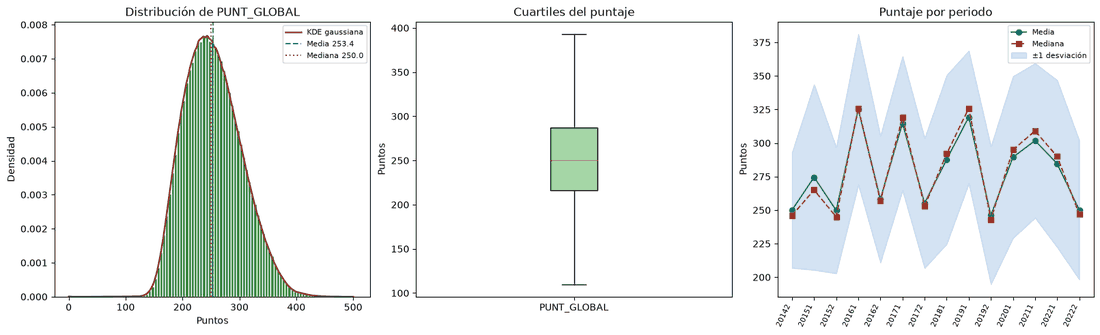

n  n_objetivo  media  mediana  desviacion  minimo  maximo  \
PERIODO                                                                   
20142    544535      544535 250.03   246.00       43.08    0.00  482.00   
20151     25947       25947 274.57   265.00       69.19   51.00  488.00   
20152    542450      542450 249.85   245.00       46.98    0.00  492.00   
20161     13064       13064 325.00   326.00       56.18  139.00  494.00   
20162    548206      548206 258.24   257.00       47.37    0.00  468.00   
20171     13018       13018 314.67   319.00       50.06  145.00  476.00   
20172    546261      546261 255.23   253.00       48.48    0.00  476.00   
20181     19798       19798 287.75   292.00       62.98  103.00  475.00   
20191     12540       12540 319.29   326.00       49.50  127.00  470.00   
20192    546211      546211 246.19   243.00       51.39    0.00  477.00   
20201     15435       15435 289.43   295.00       60.30    0.00  479.00   
20211     15528       15528 301.82   30

n  n_objetivo  media  mediana  desviacion  minimo  maximo  \
SEMESTRE                                                                    
1          135379      135379 295.67   302.00       62.70    0.00  495.00   
2         3260455     3260455 251.63   248.00       48.43    0.00  492.00   

             q1     q3  porcentaje  rango_intercuartilico  
SEMESTRE                                                   
1        248.00 344.00        3.99                  96.00  
2        216.00 284.00       96.01                  68.00


KDE: 3,395,834 puntajes; ancho de Scott = 2.4621 puntos; sin muestreo.


In [22]:
import numpy as np

def kde_desde_frecuencias(frecuencias, puntos=1000):
    """KDE gaussiana poblacional; ancho de Scott equivalente a repetir cada puntaje."""
    valores = frecuencias.index.to_numpy(dtype='float64')
    pesos = frecuencias.to_numpy(dtype='float64')
    n = pesos.sum()
    if n <= 1:
        raise ValueError('La KDE requiere al menos dos puntajes.')
    media = np.average(valores, weights=pesos)
    varianza = np.dot(pesos, (valores-media)**2)/(n-1)
    ancho = np.sqrt(varianza)*n**(-1/5)
    if not np.isfinite(ancho) or ancho <= 0:
        raise ValueError('La KDE requiere variación en el puntaje.')
    eje = np.linspace(0, 500, puntos)
    distancia = (eje[:, None]-valores[None, :])/ancho
    densidad = np.exp(-.5*distancia**2) @ pesos/(n*ancho*np.sqrt(2*np.pi))
    return eje, densidad, float(ancho)


objetivo_eda = eda["descriptivos"].loc[TARGET]
distribucion = eda["distribucion_objetivo"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
axes[0].hist(distribucion.index.to_numpy(), weights=distribucion.to_numpy(), bins=np.arange(0,506,5), density=True, color="#2e7d32", edgecolor="white")
eje_kde, densidad_kde, ancho_kde = kde_desde_frecuencias(distribucion)
axes[0].plot(eje_kde,densidad_kde,color="#8e2430",linewidth=1.8,label="KDE gaussiana")
axes[0].axvline(objetivo_eda["media"],color="#1565c0",linestyle="--",label=f"Media {objetivo_eda['media']:.1f}")
axes[0].axvline(objetivo_eda["mediana"],color="#c45122",linestyle=":",label=f"Mediana {objetivo_eda['mediana']:.1f}")
axes[0].set(title="Distribución de PUNT_GLOBAL",xlabel="Puntos",ylabel="Densidad")
axes[0].legend(fontsize=8)
axes[1].bxp([eda["box_objetivo"]],showfliers=False,patch_artist=True,boxprops={"facecolor":"#a5d6a7"})
axes[1].set(title="Cuartiles del puntaje",ylabel="Puntos")
p=eda["por_periodo"]; xx=np.arange(len(p))
axes[2].plot(xx,p["media"],marker="o",color="#1565c0",label="Media")
axes[2].plot(xx,p["mediana"],marker="s",linestyle="--",color="#c45122",label="Mediana")
axes[2].fill_between(xx,p["media"]-p["desviacion"],p["media"]+p["desviacion"],alpha=.18,color="#1565c0",label="±1 desviación")
axes[2].set_xticks(xx,p.index.astype(str),rotation=65,ha="right",fontsize=8)
axes[2].set(title="Puntaje por periodo",ylabel="Puntos");axes[2].legend(fontsize=8)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4),layout="constrained")
axes[0].bar(p.index.astype(str),p["n"],color="#2e7d32")
axes[0].tick_params(axis="x",rotation=65,labelsize=8);axes[0].yaxis.set_major_formatter(FuncFormatter(numero_corto))
axes[0].set(title="Registros por periodo de trabajo",ylabel="Registros")
sem=eda["por_semestre"]
axes[1].bar(sem.index.astype(str),sem["media"],color=["#1565c0","#2e7d32"])
for j,(_,r) in enumerate(sem.iterrows()):axes[1].text(j,r["media"]+2,f"n={int(r['n']):,}; media={r['media']:.1f}",ha="center",fontsize=8)
axes[1].set(title="Comparación descriptiva entre semestres",xlabel="Semestre",ylabel="Puntaje promedio",ylim=(0,sem["media"].max()+40))
plt.show()
display(p.round(2))
display(sem.round(2))
print(f"KDE: {int(distribucion.sum()):,} puntajes; ancho de Scott = {ancho_kde:.4f} puntos; sin muestreo.")

### **5.4. Frecuencias y distribución del puntaje según contexto**

Se examinan género, área, naturaleza y características del colegio, estrato, escolaridad de los padres y recursos del hogar. Las frecuencias muestran el soporte de cada categoría y las cajas permiten comparar mediana y dispersión del puntaje. Las ausencias se representan como `No reporta` en las tablas y gráficas sin imputar todavía los datos. Los contrastes corresponden a grupos observados; una diferencia de medias no acredita causalidad ni capacidad predictiva fuera de esta población.

Los estudiantes que reportan computador tienen una media **31,51 puntos** superior a quienes no lo reportan; para internet, la diferencia es **30,55 puntos**. Son contrastes sin ajuste por las demás características y con tamaños de grupo visibles en las tablas. Motivan estudiar conjuntamente las dimensiones del contexto, pero no permiten atribuir esas diferencias al efecto aislado de un recurso ni afirmar que una intervención produzca ese incremento.

**Interpretación de las diferencias observadas**

- **Estrato:** el puntaje medio aumenta entre los estratos 1 y 6, de **237,96** a **309,95 puntos**. La diferencia de **71,99 puntos** es coherente con la relación entre condiciones socioeconómicas y rendimiento académico descrita por Sirin (2005).
- **Escolaridad de los padres:** para la madre, las medias de `Ninguno` y `Postgrado` son **217,80** y **320,40**; para el padre, **226,35** y **324,95**. Las diferencias son compatibles con el papel del capital cultural y de los recursos del hogar, sin identificar un efecto causal aislado de la escolaridad (Rodríguez Rosero et al., 2021).
- **Brecha urbano-rural:** las instituciones urbanas presentan una mediana de **253 puntos**, frente a **230** en las rurales, y una media **20,58 puntos** superior. La media urbana es **significativamente superior** en el contraste exploratorio de Welch (**p<0,001**), bajo el supuesto de independencia entre registros que se explicita junto a sus resultados.
- **Naturaleza del colegio:** los colegios no oficiales muestran una media de **272,30 puntos**, frente a **246,24** en los oficiales, con una diferencia de **26,06 puntos**.
- **Bilingüismo:** los colegios que reportan ser bilingües presentan una media de **293,49 puntos**, frente a **254,06** en los no bilingües. Esta diferencia debe interpretarse junto con la composición socioeconómica e institucional de cada grupo.
- **Brecha digital:** internet y computador se asocian con promedios **30,55** y **31,51 puntos** superiores, respectivamente. Estos resultados respaldan estudiar los recursos tecnológicos conjuntamente con estrato y escolaridad familiar.

Los contrastes son anteriores a la imputación y no ajustan simultáneamente las demás características. Por ello, no equivalen al incremento de puntaje que produciría una intervención.

In [ ]:
import inspect

orientacion_caja = ({"orientation": "horizontal"}
                    if "orientation" in inspect.signature(plt.Axes.bxp).parameters
                    else {"vert": False})

variables_graficas = [
    "ESTU_GENERO","COLE_AREA_UBICACION","COLE_NATURALEZA","COLE_BILINGUE",
    "COLE_JORNADA","COLE_CALENDARIO","COLE_CARACTER","COLE_GENERO",
    "FAMI_ESTRATOVIVIENDA","FAMI_EDUCACIONMADRE","FAMI_EDUCACIONPADRE",
    "FAMI_TIENEINTERNET","FAMI_TIENECOMPUTADOR","FAMI_TIENEAUTOMOVIL","FAMI_TIENELAVADORA",
]
for inicio in range(0,len(variables_graficas),3):
    bloque=variables_graficas[inicio:inicio+3]
    fig,axes=plt.subplots(1,len(bloque),figsize=(19,6.8),layout="constrained",squeeze=False)
    for ax,c in zip(axes[0],bloque):
        t=eda["grupos"][c].sort_values("n")
        ax.barh(range(len(t)),t["n"],color="#43a047")
        ax.set_yticks(range(len(t)),etiquetas_cortas(t.index,25),fontsize=7)
        ax.xaxis.set_major_formatter(FuncFormatter(numero_corto))
        ax.set(title=c,xlabel="Registros")
        ax.title.set_fontsize(9)
    plt.show()
    fig,axes=plt.subplots(1,len(bloque),figsize=(19,6.8),layout="constrained",squeeze=False)
    for ax,c in zip(axes[0],bloque):
        cajas=sorted(eda["cajas_grupos"][c],key=lambda x:x["med"])
        for caja in cajas:caja["label"]=textwrap.fill(caja["label"],25)
        ax.bxp(cajas,**orientacion_caja,showfliers=False,patch_artist=True,boxprops={"facecolor":"#a5d6a7"},medianprops={"color":"#1565c0"})
        ax.tick_params(axis="y",labelsize=7)
        ax.set(title=c,xlabel="PUNT_GLOBAL");ax.title.set_fontsize(9)
    plt.show()
display(eda["rangos_medias"].round(2))

# Contraste exploratorio de medias urbano-rural, con varianzas diferentes.
from scipy.stats import ttest_ind_from_stats, t as distribucion_t
from IPython.display import Markdown

urbano = eda["grupos"]["COLE_AREA_UBICACION"].loc["URBANO"]
rural = eda["grupos"]["COLE_AREA_UBICACION"].loc["RURAL"]
n_u, n_r = int(urbano.n_objetivo), int(rural.n_objetivo)
prueba_welch = ttest_ind_from_stats(urbano.media,urbano.desviacion,n_u,
                                  rural.media,rural.desviacion,n_r,equal_var=False)
var_u, var_r = urbano.desviacion**2/n_u, rural.desviacion**2/n_r
grados_libertad = (var_u+var_r)**2/(var_u**2/(n_u-1)+var_r**2/(n_r-1))
diferencia_medias = float(urbano.media-rural.media)
margen_95 = distribucion_t.ppf(.975,grados_libertad)*np.sqrt(var_u+var_r)
presentacion_p = "<0,001" if prueba_welch.pvalue<.001 else f"{prueba_welch.pvalue:.4f}"
display(pd.DataFrame([{
    "Contraste":"Urbano − rural", "n urbano":n_u, "n rural":n_r,
    "Diferencia de medias":diferencia_medias,"t Welch":prueba_welch.statistic,
    "Grados de libertad":grados_libertad,"p valor":presentacion_p,
    "IC95% inferior":diferencia_medias-margen_95,"IC95% superior":diferencia_medias+margen_95,
}]).round(4))
display(Markdown(
    "Las instituciones urbanas presentan una **media estadísticamente superior** a las rurales "
    f"en el contraste exploratorio de Welch (**p {presentacion_p}**). La diferencia de medianas "
    "se describe por separado; Welch contrasta medias. Este cálculo supone independencia entre "
    "registros y no incorpora la agrupación por colegio o cohorte. Sus valores p e intervalo "
    "son exploratorios bajo esos supuestos; se interpretan junto con la magnitud de la brecha "
    "y no acreditan un efecto causal ni representatividad nacional."
))

### **5.5. Relaciones socioeconómicas y cobertura de la codificación**

Se conservan dos lecturas complementarias: medias por categoría y correlación de Spearman de las variables familiares ordinales o binarias con el puntaje (Spearman, 1904). Spearman utiliza una muestra aleatoria de hasta **300.000 registros**, sin reemplazo y con semilla 42; sus tamaños pareados y cobertura se presentan para cada variable.

Los mapas ordinales expresan el orden definido para estrato, escolaridad, cuartos y personas del hogar (Agresti, 2010). La convención asigna 0 a categorías de no respuesta y a niveles inferiores en algunas escalas; por ello, ese código no equivale siempre a ausencia de escolaridad o recursos. Los intervalos del hogar se representan mediante valores ordinales de referencia, no como conteos individuales exactos. Las tablas mantienen las etiquetas originales y documentan las categorías sin mapeo.

La mayor asociación familiar de esta exploración corresponde a la escolaridad de la madre (**ρ≈0,382**). La relación es positiva bajo la codificación declarada y no determina por sí sola el puntaje individual. Se conservan las variables familiares para estudiar relaciones conjuntas; ni estas correlaciones ni las diferencias de medias constituyen una selección basada en el desempeño de prueba.

In [ ]:
for c in FAMILIARES_EDA:
    print(c)
    display(eda["grupos"][c][["n","porcentaje","media","mediana","q1","q3"]].round(3))
rho=eda["spearman"].sort_values("rho_spearman")
fig,ax=plt.subplots(figsize=(10,5.5),layout="constrained")
ax.barh(rho.index,rho["rho_spearman"],color=["#2e7d32" if v>=0 else "#c45122" for v in rho["rho_spearman"]])
ax.axvline(0,color="black",linewidth=.8)
ax.set_xlim(rho["rho_spearman"].min()-.07,rho["rho_spearman"].max()+.07)
ax.set(title="Asociación de Spearman con el puntaje global",xlabel="ρ de Spearman")
ax.tick_params(axis="y",labelsize=8)
for j,v in enumerate(rho["rho_spearman"]):ax.text(v+.006*np.sign(v),j,f"{v:.3f}",va="center",ha="left" if v>=0 else "right",fontsize=8)
plt.show()
display(eda["spearman"].round(4))
display(eda["cobertura_spearman"])
principales=eda["spearman"].head(3)
print("Mayores asociaciones absolutas observadas:", ", ".join(f"{c}: {r.rho_spearman:.3f}" for c,r in principales.iterrows()))

### **5.6. Variación territorial**

Se comparan los puntajes por departamento de ubicación del colegio después de consolidar las variantes geográficas. Se muestran tamaños y estadísticos completos para evitar interpretar por igual categorías con soportes diferentes.

La línea de referencia representa la **media nacional del conjunto analizado: 253,38 puntos**, calculada sobre los **3.395.834 registros** de los departamentos y periodos disponibles después de la limpieza. Es una referencia agregada multianual de cobertura nacional, no el promedio nacional oficial de una aplicación completa. El gráfico y el contraste territorial excluyen la categoría sin departamento; la tabla conserva esa ausencia y su soporte.

Bogotá presenta la mayor media (**273,04**) y Chocó la menor (**212,24**), una brecha de **60,81 puntos**. Santander (**264,76**), Boyacá (**264,74**) y Cundinamarca (**261,38**) se sitúan por encima de la referencia; Vaupés (**218,01**) y Amazonas (**221,53**) se encuentran entre los promedios inferiores. Estas diferencias ilustran las brechas territoriales del conjunto estudiado y respaldan conservar la ubicación geográfica y examinar posteriormente el error por territorio.

In [ ]:
dept_completo=eda["grupos"]["COLE_DEPTO_UBICACION"].sort_values("media")
dept=dept_completo.drop(index="No reporta",errors="ignore")
fig,ax=plt.subplots(figsize=(12,9),layout="constrained")
ax.barh(dept.index.astype(str),dept["media"],color="#43a047")
ax.axvline(objetivo_eda["media"],color="#c45122",linestyle="--",label=f"Media nacional del conjunto analizado: {objetivo_eda['media']:.2f}")
ax.set(title="Puntaje promedio por departamento del colegio",xlabel="PUNT_GLOBAL promedio")
ax.tick_params(axis="y",labelsize=8);ax.legend(fontsize=8)
plt.show()
display(dept_completo[["n","porcentaje","media","mediana","desviacion"]].round(3))
print(f"Rango descriptivo de medias departamentales: {dept['media'].max()-dept['media'].min():.2f} puntos.")

### **5.7. Asociación entre variables y prevención de fuga**

La correlación entre los puntajes de áreas y el puntaje global se calcula sobre casos completos y se acompaña de su cobertura. La definición del puntaje y la disponibilidad posterior al examen justifican la exclusión de esas áreas y de `DESEMP_INGLES`; una correlación alta por sí sola no demuestra que una variable sea un componente del resultado (Icfes, 2020a; Kaufman et al., 2012).

La **V de Cramér** examina asociaciones entre predictores categóricos sobre una muestra aleatoria de hasta **200.000 registros**, con semilla 42. Se señalan pares desde 0,7 sin eliminarlos automáticamente: departamento y municipio describen niveles geográficos relacionados, y la asociación no equivale a importancia predictiva. Esta versión de V no corrige el sesgo asociado con cardinalidades altas; se utiliza como diagnóstico descriptivo. Las ausencias se incluyen como una categoría: un patrón de ausencia compartida también puede producir una asociación elevada y debe interpretarse junto con el diagnóstico de nulidad.

In [ ]:
def mapa_asociacion(tabla,titulo,tamano=(10,8),anotar=True):
    valores=tabla.to_numpy(dtype=float)
    mascara=np.triu(np.ones_like(valores,dtype=bool),1)
    fig,ax=plt.subplots(figsize=tamano,layout="constrained")
    imagen=ax.imshow(np.ma.array(valores,mask=mascara),vmin=0,vmax=1,cmap="YlGnBu")
    ax.set_xticks(range(len(tabla.columns)),tabla.columns,rotation=60,ha="right",fontsize=7)
    ax.set_yticks(range(len(tabla.index)),tabla.index,fontsize=7)
    if anotar:
        for (i,j),v in np.ndenumerate(valores):
            if j<=i and np.isfinite(v):ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7,color="white" if v>.65 else "black")
    ax.set_title(titulo);fig.colorbar(imagen,ax=ax,shrink=.7)
    plt.show()

mapa_asociacion(eda["corr_puntajes"],"Correlación de Pearson entre resultados del examen",(9,7))
print("Casos completos para esta matriz:",eda["metodo"]["poblacion_casos_completos_corr_puntajes"])
display(eda["corr_puntajes"][[TARGET]].round(4))
display(eda["conteos_corr_puntajes"])
mapa_asociacion(eda["cramer"],"V de Cramér entre variables de contexto",(15,13),anotar=False)
pares_altos=eda["pares_cramer"].loc[eda["pares_cramer"]["v_cramer"]>=.7]
print("Pares de contexto con V ≥0,7:",len(pares_altos))
display(pares_altos.round(4))

### **5.8. Valores atípicos y rangos admisibles**

Las cercas de Tukey distinguen extremos estadísticos de resultados imposibles. Se conservan todos los puntajes dentro de **0–500**, incluidos los ceros y las observaciones por fuera de `Q1−1,5×IQR` o `Q3+1,5×IQR`. No se aplica winsorización ni eliminación automática por distancia respecto de la mediana (Aguinis et al., 2013).

En una red neuronal, los extremos pueden influir en gradientes y pérdidas. Su conservación mantiene el problema educativo y su rango; el diseño y la validación deberán estudiar esa sensibilidad. El escalado de entradas no modifica la etiqueta ni acredita por sí mismo resistencia a valores extremos. Para edad, los valores no plausibles se marcan como ausentes y se imputan con la mediana de entrenamiento, sin eliminar al estudiante.

In [ ]:
display(eda["iqr"].round(4))
r=eda["iqr"].iloc[0]
fig,axes=plt.subplots(1,2,figsize=(14,4.5),layout="constrained")
axes[0].hist(distribucion.index,weights=distribucion,bins=np.arange(0,506,5),color="#2e7d32",edgecolor="white")
for v in [r.limite_inferior,r.limite_superior]:axes[0].axvline(v,color="#c45122",linestyle="--")
axes[0].set(title="Distribución y cercas de Tukey",xlabel="PUNT_GLOBAL",ylabel="Registros")
extremos=distribucion.loc[(distribucion.index<r.limite_inferior)|(distribucion.index>r.limite_superior)]
axes[1].bar(extremos.index,extremos,width=1,color="#c45122")
axes[1].set(title=f"Extremos conservados: {int(r.extremos_totales):,} ({r.extremos_pct:.2f} %)",xlabel="PUNT_GLOBAL",ylabel="Registros")
for ax in axes:ax.yaxis.set_major_formatter(FuncFormatter(numero_corto))
plt.show()
display(pd.DataFrame(auditoria_limpieza["normalizacion_geografica"]).T)
display(pd.DataFrame(auditoria_limpieza["conversion_no_numerica_puntajes_periodos_elegibles"].items(),columns=["Puntaje", "Valores no convertibles, excluyendo ausencias"]))
print("Edades ausentes o fuera de 13–80 años antes de imputar:",auditoria_limpieza["edad_ausente_o_fuera_13_80"])

## **6. Preparación de entradas para redes neuronales**

### **6.1. Selección de variables**

Se mantienen las dimensiones socioeconómicas, familiares, institucionales y geográficas definidas en el planteamiento. Se excluyen las seis variables de resultados del mismo examen, seis identificadores o nombres, seis campos de baja información para el alcance definido y seis códigos geográficos redundantes. `ESTU_ESTADOINVESTIGACION` se excluye como campo administrativo del resultado; no se interpreta como una medida del contexto de aprendizaje.

La fecha de nacimiento se sustituye por edad aproximada. El periodo y la fila de origen se retienen para trazabilidad, pero no entran a la red; el componente de semestre se utiliza como categoría. Los identificadores excluidos no se recuperan como embeddings. La selección responde al significado y disponibilidad de las variables, no a seleccionar un subconjunto que optimice las métricas de prueba (Guyon & Elisseeff, 2003).

In [ ]:
grupos_exclusion={
    "Resultados del mismo examen":LEAKAGE_COLS,
    "Identificadores y nombres":ID_COLS,
    "Campos de baja información o administrativos":LOW_INFO_COLS,
    "Códigos geográficos redundantes":REDUNDANT_CODE_COLS,
}
display(pd.DataFrame([{"Grupo":g,"Variable":c} for g,cols in grupos_exclusion.items() for c in cols]))
predictores_trabajo=[c for c in df_limpio if c not in EXCLUSIONES+[TARGET,"ESTU_FECHANACIMIENTO","PERIODO","FILA_ORIGEN"]]
display(pd.DataFrame({"Predictor":predictores_trabajo,"Tipo de tratamiento":[
    "Ordinal + estandarización" if c in ORDEN_MAPAS else "Binaria 0/1" if c in BINARIOS_MAPAS
    else "Índice de municipio" if c in MUNICIPIOS else "Edad estandarizada" if c=="EDAD_PRESENTACION"
    else "One-hot" for c in predictores_trabajo]}))
assert not set(LEAKAGE_COLS+ID_COLS+["PERIODO","FILA_ORIGEN","ESTU_FECHANACIMIENTO"]) & set(predictores_trabajo)
print("Predictores antes de la expansión one-hot:",len(predictores_trabajo))

### **6.2. Partición y ajuste de transformaciones**

La partición principal es **80 % / 10 % / 10 %**, aleatoria y estratificada por quintiles de `PUNT_GLOBAL`, con semilla **42**. Se reserva primero 10 % para prueba y después 11,11 % del 90 % restante para validación, por lo que las proporciones finales son aproximadamente 80/10/10. La etiqueta se discretiza solo para estratificar; la regresión conserva el puntaje numérico.

La unidad de partición es el registro único estudiante-periodo. Se comprueba la separación de filas y se informa el eventual solapamiento de identificadores entre particiones. Este diseño evalúa generalización interna a registros reservados; no constituye una prueba de instituciones, estudiantes o cohortes futuras completamente inéditos. Los periodos se conservan como metadatos para los análisis posteriores. El origen y destino del preentrenamiento se delimitarán dentro de entrenamiento, sin incorporar validación o prueba.

| Tipo de variable | Tratamiento |
|---|---|
| Objetivo | Puntos originales de Saber 11; sin imputación ni escalado |
| Familiares binarias | Moda estimada en entrenamiento; representación 0/1 |
| Familiares ordinales | Categoría `No reporta` para ausencias, mapa de orden definido y código 0 para categorías fuera del mapa |
| Otras categóricas | Si su ausencia en entrenamiento supera 5 %, categoría explícita; en caso contrario, moda de entrenamiento |
| Edad no plausible o ausente | Mediana de edades válidas de entrenamiento |
| Edad y cinco ordinales | Estandarización con media y desviación de entrenamiento, manteniendo el orden de las ordinales |
| Binarias y one-hot | Mantener valores 0/1 |
| Nominales de baja cardinalidad | Categorías de entrenamiento y one-hot con categoría de referencia |
| Tres municipios | Vocabulario aprendido en entrenamiento, índices desde 1 y código 0 para categorías no vistas |

La normalización de magnitudes y la codificación de alta cardinalidad responden al enfoque neuronal. Los índices de municipios son entradas para posibles capas de embeddings; **todavía no son vectores aprendidos** ni fijan una arquitectura. Los vocabularios no utilizan el puntaje para codificar categorías (Hancock & Khoshgoftaar, 2020; Keras, s. f.). Las estadísticas y categorías aprendidas se ajustan únicamente en entrenamiento y se aplican sin reajuste a validación y prueba (scikit-learn developers, s. f.).

La convención ordinal mantiene un código de referencia 0 para varias categorías, por ejemplo `Ninguno`, `No sabe` o `No reporta`; no permite distinguirlas después de mapear. En bilingüismo, `No reporta` también se codifica con 0. Se documenta esta pérdida de distinción. Las categorías nominales no vistas se representan como el vector de ceros, igual que la referencia de one-hot, y se contabilizan. Los municipios no vistos tienen un índice 0 explícito.

In [ ]:
def _serie_imputada(frame, columna, imputacion):
    s = frame[columna].astype(object)
    return s.fillna(imputacion[columna]['valor'])

def _bloque_base(frame, imputacion):
    columnas = {}
    for c in ORDEN_MAPAS:
        columnas[c] = _serie_imputada(frame, c, imputacion).map(ORDEN_MAPAS[c]).fillna(0).to_numpy(dtype='float32')
    for c in BINARIOS_MAPAS:
        columnas[c] = _serie_imputada(frame, c, imputacion).map(BINARIOS_MAPAS[c]).fillna(0).to_numpy(dtype='float32')
    columnas['EDAD_PRESENTACION'] = frame.EDAD_PRESENTACION.fillna(imputacion['EDAD_PRESENTACION']['valor']).to_numpy(dtype='float32')
    return columnas

def ajustar_preprocesamiento(df_limpio, root, seed=42, batch_size=100_000):
    """Divide primero, ajusta solo en train y transforma sin aprender del target."""
    inicio = time.perf_counter()
    salida = Path(root)/'resultados_fase2'
    salida.mkdir(parents=True, exist_ok=True)
    n = len(df_limpio)
    indices = np.arange(n, dtype='int32')
    y_total = df_limpio[TARGET].to_numpy(dtype='float32')
    quintiles = pd.qcut(y_total, q=5, labels=False, duplicates='drop')
    idx_tv, idx_test, bins_tv, _ = train_test_split(
        indices, quintiles, test_size=.10, random_state=seed, stratify=quintiles)
    idx_train, idx_val = train_test_split(
        idx_tv, test_size=.1111, random_state=seed, stratify=bins_tv)
    idx_particiones = {'train': idx_train, 'validation': idx_val, 'test': idx_test}
    assert len(np.unique(np.concatenate(list(idx_particiones.values())))) == n
    train = df_limpio.iloc[idx_train]
    predictores = [c for c in df_limpio if c not in EXCLUSIONES+
                   [TARGET, 'ESTU_FECHANACIMIENTO', 'PERIODO', 'FILA_ORIGEN']]
    nominales = [c for c in predictores if c not in
                list(ORDEN_MAPAS)+list(BINARIOS_MAPAS)+['EDAD_PRESENTACION']+MUNICIPIOS]
    imputacion = {}
    for c in predictores:
        s = train[c]
        nulos = int(s.isna().sum())
        fraccion = nulos/len(train)
        if c == 'EDAD_PRESENTACION':
            valor, metodo = float(s.median()), 'mediana de edades válidas de entrenamiento'
            if not np.isfinite(valor):
                raise ValueError('No existen edades válidas en entrenamiento.')
        elif c in ORDEN_MAPAS:
            valor, metodo = 'No reporta', 'categoría explícita'
        elif c in BINARIAS_FAMILIA or fraccion <= .05:
            moda = s.mode()
            if moda.empty:
                raise ValueError(f'No se puede estimar la moda de {c} con entrenamiento.')
            valor, metodo = str(moda.iloc[0]), 'moda de entrenamiento'
        else:
            valor = 'NO REPORTA' if c in GEOGRAFICAS else 'No reporta'
            metodo = 'categoría explícita por ausencias >5% en entrenamiento'
        imputacion[c] = {'valor': valor, 'metodo': metodo,
                         'nulos_train': nulos, 'proporcion_nulos_train': fraccion}
    vocabularios, onehot = {}, {}
    for c in MUNICIPIOS:
        valores = sorted(_serie_imputada(train, c, imputacion).unique())
        vocabularios[c] = {v: i+1 for i, v in enumerate(valores)}
    for c in nominales:
        categorias = sorted(_serie_imputada(train, c, imputacion).unique())
        onehot[c] = {'categorias_train': categorias, 'referencia': categorias[0],
                     'columnas': [f'{c}_{v}' for v in categorias[1:]]}
    base_num = [*ORDEN_MAPAS, *BINARIOS_MAPAS, 'EDAD_PRESENTACION']
    nombres_numericos = base_num + [f for v in onehot.values() for f in v['columnas']]
    scaler = StandardScaler()
    for i in range(0, len(train), batch_size):
        bloque = _bloque_base(train.iloc[i:i+batch_size], imputacion)
        scaler.partial_fit(np.column_stack([bloque[c] for c in ESCALADAS]))
    medias = dict(zip(ESCALADAS, map(float, scaler.mean_)))
    escalas = dict(zip(ESCALADAS, map(float, scaler.scale_)))
    estado = {'version': 1, 'semilla': seed, 'variable_objetivo': TARGET,
        'unidad_objetivo': 'puntos originales [0,500]; sin escalado',
        'orden_predictor_numerico': nombres_numericos,
        'orden_predictor_categorico': MUNICIPIOS, 'tipos': {'X_num': 'float32', 'X_cat': 'int32', 'y': 'float32'},
        'imputacion': imputacion, 'mapas_ordinales': ORDEN_MAPAS,
        'mapas_binarios': BINARIOS_MAPAS, 'codigo_fallback_ordinal_binario': 0,
        'one_hot': onehot, 'vocabularios_municipio': vocabularios,
        'municipio_oov_id': 0, 'scaler': {'variables': ESCALADAS, 'media_train': medias,
        'escala_train': escalas, 'varianza_train': dict(zip(ESCALADAS, map(float, scaler.var_))),
        'n_train': int(scaler.n_samples_seen_)},
        'particion': {'metodo': 'aleatoria estratificada por quintiles de PUNT_GLOBAL',
            'test_size': .10, 'validation_size_del_90_restante': .1111,
            'tamano': {k: len(v) for k, v in idx_particiones.items()}},
        'ajuste_solo_entrenamiento': True, 'exclusiones_modelado': EXCLUSIONES+
            ['PERIODO', 'ESTU_FECHANACIMIENTO', 'FILA_ORIGEN'],
        'edad': {'fecha_aproximada': '15 de marzo semestre1;15 de agosto semestre2',
            'divisor_anual': 365.25, 'decimales': 1, 'rango_valido': [13, 80]},
        'geografia': 'strip+upper;BOGOTA→BOGOTÁ;sin retirar otros acentos'}
    del train
    gc.collect()
    particiones, resumen_particiones = {}, {}
    for nombre, idx in idx_particiones.items():
        carpeta = salida/'particiones'
        carpeta.mkdir(parents=True, exist_ok=True)
        num = np.lib.format.open_memmap(carpeta/f'X_num_{nombre}.npy', mode='w+', dtype='float32', shape=(len(idx), len(nombres_numericos)))
        cat = np.lib.format.open_memmap(carpeta/f'X_cat_{nombre}.npy', mode='w+', dtype='int32', shape=(len(idx), len(MUNICIPIOS)))
        y = np.lib.format.open_memmap(carpeta/f'y_{nombre}.npy', mode='w+', dtype='float32', shape=(len(idx),))
        y[:] = y_total[idx]
        np.save(carpeta/f'indices_{nombre}.npy', idx, allow_pickle=False)
        oov, nominales_desconocidas, no_mapeados, nulos_tratados = Counter(), Counter(), Counter(), Counter()
        parquet_path = carpeta/f'saber11_{nombre}.parquet'
        writer = None
        try:
            for i in range(0, len(idx), batch_size):
                seleccion = idx[i:i+batch_size]
                frame = df_limpio.iloc[seleccion]
                nulos_tratados.update({c: int(frame[c].isna().sum()) for c in predictores})
                base = _bloque_base(frame, imputacion)
                matriz = np.zeros((len(frame), len(nombres_numericos)), dtype='float32')
                for j, c in enumerate(base_num):
                    valor = base[c]
                    matriz[:, j] = (valor-medias[c])/escalas[c] if c in ESCALADAS else valor
                    if c in ORDEN_MAPAS or c in BINARIOS_MAPAS:
                        mapa = ORDEN_MAPAS.get(c, BINARIOS_MAPAS.get(c))
                        no_mapeados[c] += int((~_serie_imputada(frame, c, imputacion).isin(mapa)).sum())
                j = len(base_num)
                for c, spec in onehot.items():
                    valores = _serie_imputada(frame, c, imputacion)
                    codigos = pd.Categorical(valores, categories=spec['categorias_train']).codes
                    nominales_desconocidas[c] += int((codigos < 0).sum())
                    presentes = codigos > 0
                    matriz[np.flatnonzero(presentes), j+codigos[presentes]-1] = 1
                    j += len(spec['columnas'])
                matriz_cat = np.zeros((len(frame), len(MUNICIPIOS)), dtype='int32')
                for j, c in enumerate(MUNICIPIOS):
                    matriz_cat[:, j] = _serie_imputada(frame, c, imputacion).map(vocabularios[c]).fillna(0).to_numpy(dtype='int32')
                    oov[c] += int((matriz_cat[:, j] == 0).sum())
                assert np.isfinite(matriz).all() and np.isfinite(y[i:i+len(frame)]).all()
                num[i:i+len(frame)] = matriz
                cat[i:i+len(frame)] = matriz_cat
                tabla = pa.table({**{c: matriz[:, j] for j, c in enumerate(nombres_numericos)},
                    **{f'{c}_ID': matriz_cat[:, j] for j, c in enumerate(MUNICIPIOS)},
                    TARGET: y[i:i+len(frame)]})
                if writer is None:
                    writer = pq.ParquetWriter(parquet_path, tabla.schema, compression='snappy')
                writer.write_table(tabla)
            num.flush(); cat.flush(); y.flush()
        finally:
            if writer is not None:
                writer.close()
        # Verificación completa por bloques contra los arrays, sin cargar otra copia de la población.
        leidas, par = 0, pq.ParquetFile(parquet_path)
        for lote in par.iter_batches(batch_size=batch_size):
            tabla = pa.Table.from_batches([lote])
            a, b = leidas, leidas+lote.num_rows
            for j, c in enumerate(nombres_numericos):
                assert np.array_equal(tabla[c].to_numpy(), num[a:b, j])
                assert pa.types.is_float32(tabla[c].type)
            for j, c in enumerate(MUNICIPIOS):
                assert np.array_equal(tabla[f'{c}_ID'].to_numpy(), cat[a:b, j])
                assert pa.types.is_int32(tabla[f'{c}_ID'].type)
            assert np.array_equal(tabla[TARGET].to_numpy(), y[a:b])
            leidas = b
        assert leidas == len(idx)
        particiones[nombre] = {'X_num': num, 'X_cat': cat, 'y': y, 'indices': idx}
        resumen_particiones[nombre] = {'filas': len(idx), 'porcentaje': 100*len(idx)/n,
            'dimensiones_X_num': list(num.shape), 'dimensiones_X_cat': list(cat.shape),
            'target_media': float(np.mean(y, dtype='float64')),
            'target_desviacion_muestral': float(np.std(y, ddof=1, dtype='float64')),
            'target_minimo': float(y.min()), 'target_maximo': float(y.max()),
            'municipios_no_vistos': dict(oov), 'nominales_no_vistas': dict(nominales_desconocidas),
            'categorias_ordinal_binario_fuera_mapa': dict(no_mapeados),
            'nulos_imputados': dict(nulos_tratados), 'salida_sin_nulos_infinitos': True,
            'parquet': str(parquet_path), 'parquet_bytes': parquet_path.stat().st_size,
            'parquet_verificado_contra_arrays_completo': True}
        print(f'{nombre}: {len(idx):,} filas; X_num {num.shape} float32; '
              f'X_cat {cat.shape} int32. Exportación y lectura completa verificadas.', flush=True)
    # Las siguientes comprobaciones consultan claves de auditoría y no crean predictores.
    grupos_ids = df_limpio['ESTU_CONSECUTIVO'].astype('category').cat.codes.to_numpy()
    sets_ids = {k: np.unique(grupos_ids[v]) for k, v in idx_particiones.items()}
    solapamiento_id = {f'{a}-{b}': int(np.intersect1d(sets_ids[a], sets_ids[b]).size)
        for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]}
    auditoria_preprocesamiento = {'particiones': resumen_particiones,
        'filas_disjuntas_y_cobertura_completa': True,
        'identificadores_presentes_en_varias_particiones': solapamiento_id,
        'advertencia_identificadores': 'El split aleatorio por registro no garantiza evaluación por estudiante, institución ni cohorte inédita; esta limitación se conserva explícita.',
        'scaler_solo_train': True, 'vocabularios_solo_train': True, 'imputadores_solo_train': True,
        'objetivo_no_usado_en_codificacion_predictor': True,
        'total_filas': n, 'n_features_numericos': len(nombres_numericos),
        'n_features_categoricos': len(MUNICIPIOS),
        'tiempo_segundos': round(time.perf_counter()-inicio, 2)}
    _guardar_json(salida/'estado_preprocesamiento.json', estado)
    _guardar_json(salida/'auditoria_preprocesamiento.json', auditoria_preprocesamiento)
    print('Preprocesamiento completo: parámetros ajustados en entrenamiento; objetivo conservado en puntos.')
    return particiones, estado, auditoria_preprocesamiento

In [ ]:
particiones, estado_preprocesamiento, auditoria_preprocesamiento = ajustar_preprocesamiento(
    df_limpio, ROOT, seed=SEED, batch_size=100_000)
display(pd.DataFrame.from_dict(estado_preprocesamiento["imputacion"],orient="index"))
display(pd.DataFrame({k:estado_preprocesamiento["scaler"][k] for k in ["media_train","escala_train","varianza_train"]}))
print("Mapas ordinales:")
display(pd.DataFrame([{"Variable":c,"Categoría":v,"Código":codigo} for c,mapa in ORDEN_MAPAS.items() for v,codigo in mapa.items()]))
print("Mapas binarios:")
display(pd.DataFrame([{"Variable":c,"Categoría":v,"Código":codigo} for c,mapa in BINARIOS_MAPAS.items() for v,codigo in mapa.items()]))

## **7. Verificación y persistencia de los datos preparados**

Las entradas neuronales se organizan en dos bloques: **`X_num`**, con edad, ordinales estandarizadas, binarias y one-hot en `float32`; y **`X_cat`**, con los tres índices de municipio en `int32`. La etiqueta `y` es `float32` en puntos originales. El orden de columnas, categorías, vocabularios y parámetros se guarda para reproducir exactamente la transformación.

Las matrices se escriben por lotes mediante archivos NumPy con acceso por memoria mapeada y tablas **Parquet**, evitando copias completas adicionales. Se verifica toda la exportación por bloques contra las matrices de origen: dimensiones, valores y tipos. La preparación genera estos archivos dentro de `resultados_fase2`; la ejecución completa del cuaderno puede reconstruirlos desde el dataset de GitHub sin cargar archivos procesados externos.

In [31]:
resumen_particiones=pd.DataFrame.from_dict(auditoria_preprocesamiento["particiones"],orient="index")
display(resumen_particiones[["filas","porcentaje","dimensiones_X_num","dimensiones_X_cat","target_media","target_desviacion_muestral","target_minimo","target_maximo"]].round(4))
display(pd.DataFrame({nombre:r["nulos_imputados"] for nombre,r in auditoria_preprocesamiento["particiones"].items()}))
display(pd.DataFrame({nombre:r["municipios_no_vistos"] for nombre,r in auditoria_preprocesamiento["particiones"].items()}).fillna(0))
display(pd.DataFrame({nombre:r["nominales_no_vistas"] for nombre,r in auditoria_preprocesamiento["particiones"].items()}).fillna(0))
display(pd.DataFrame({nombre:r["categorias_ordinal_binario_fuera_mapa"] for nombre,r in auditoria_preprocesamiento["particiones"].items()}).fillna(0))
print("Identificadores compartidos entre particiones:",auditoria_preprocesamiento["identificadores_presentes_en_varias_particiones"])
print(auditoria_preprocesamiento["advertencia_identificadores"])

n_total=sum(len(p["y"]) for p in particiones.values())
assert n_total==len(df_limpio)
assert auditoria_preprocesamiento["filas_disjuntas_y_cobertura_completa"]
assert estado_preprocesamiento["scaler"]["n_train"]==len(particiones["train"]["y"])
assert auditoria_preprocesamiento["scaler_solo_train"] and auditoria_preprocesamiento["vocabularios_solo_train"]
for nombre,p in particiones.items():
    assert p["X_num"].dtype==np.float32 and p["X_cat"].dtype==np.int32 and p["y"].dtype==np.float32
    assert p["X_num"].shape[0]==p["X_cat"].shape[0]==len(p["y"])
    assert p["X_num"].shape[1]==len(estado_preprocesamiento["orden_predictor_numerico"])
    assert p["X_cat"].shape[1]==len(estado_preprocesamiento["orden_predictor_categorico"])
    for j,c in enumerate(MUNICIPIOS):
        assert p["X_cat"][:,j].min()>=0
        assert p["X_cat"][:,j].max()<=len(estado_preprocesamiento["vocabularios_municipio"][c])
    assert np.array_equal(p["y"],df_limpio[TARGET].to_numpy(dtype=np.float32)[p["indices"]])
    assert auditoria_preprocesamiento["particiones"][nombre]["salida_sin_nulos_infinitos"]
    assert auditoria_preprocesamiento["particiones"][nombre]["parquet_verificado_contra_arrays_completo"]
print("Cobertura, separación de filas, ausencia de nulos, escala del objetivo, tipos y exportación: verificados.")

fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
for nombre,p in particiones.items():
    axes[0].hist(p["y"],bins=np.arange(0,506,10),density=True,histtype="step",linewidth=1.8,label=nombre)
axes[0].set(title="Distribución del objetivo por partición",xlabel="PUNT_GLOBAL",ylabel="Densidad");axes[0].legend()
j=estado_preprocesamiento["orden_predictor_numerico"].index("EDAD_PRESENTACION")
bordes_edad=np.linspace(min(p["X_num"][:,j].min() for p in particiones.values()),max(p["X_num"][:,j].max() for p in particiones.values()),81)
for nombre,p in particiones.items():
    frecuencia,bordes=np.histogram(p["X_num"][:,j],bins=bordes_edad,density=True)
    axes[1].stairs(frecuencia,bordes,label=nombre)
axes[1].set(title="Edad estandarizada con parámetros de entrenamiento",xlabel="(edad − media de train) / escala de train",ylabel="Densidad");axes[1].legend()
plt.show()

filas  porcentaje dimensiones_X_num dimensiones_X_cat  \
train       2716700       80.00    [2716700, 125]      [2716700, 3]   
validation   339550       10.00     [339550, 125]       [339550, 3]   
test         339584       10.00     [339584, 125]       [339584, 3]   

            target_media  target_desviacion_muestral  target_minimo  \
train             253.38                       49.82           0.00   
validation        253.43                       49.93           0.00   
test              253.38                       49.80           0.00   

            target_maximo  
train              495.00  
validation         492.00  
test               490.00


train  validation   test
COLE_AREA_UBICACION           5           0      1
COLE_BILINGUE            384734       48648  48454
COLE_CALENDARIO               0           0      1
COLE_CARACTER             48235        6047   6076
COLE_DEPTO_UBICACION          0           0      1
COLE_GENERO                   0           0      1
COLE_JORNADA                  0           0      1
COLE_MCPIO_UBICACION          0           0      1
COLE_NATURALEZA               0           0      1
COLE_SEDE_PRINCIPAL           0           0      1
ESTU_DEPTO_PRESENTACION      67          10      9
ESTU_DEPTO_RESIDE          1349         155    171
ESTU_GENERO                2454         325    306
ESTU_MCPIO_PRESENTACION      67          10      9
ESTU_MCPIO_RESIDE          1349         155    171
FAMI_CUARTOSHOGAR         47257        5870   6006
FAMI_EDUCACIONMADRE       77364        9694   9640
FAMI_EDUCACIONPADRE       77422        9687   9628
FAMI_ESTRATOVIVIENDA      86226       10771  10738
FAMI_P

train  validation  test
COLE_MCPIO_UBICACION         0           0     0
ESTU_MCPIO_PRESENTACION      0           0     0
ESTU_MCPIO_RESIDE            0           1     0


train  validation  test
COLE_CALENDARIO              0           0     0
COLE_CARACTER                0           0     0
COLE_DEPTO_UBICACION         0           0     0
COLE_GENERO                  0           0     0
COLE_JORNADA                 0           0     0
ESTU_DEPTO_PRESENTACION      0           0     0
ESTU_DEPTO_RESIDE            0           0     0
SEMESTRE                     0           0     0


train  validation   test
FAMI_ESTRATOVIVIENDA       0           0      0
FAMI_EDUCACIONMADRE     2686         345    347
FAMI_EDUCACIONPADRE    15392        1944   1937
FAMI_CUARTOSHOGAR          0           0      0
FAMI_PERSONASHOGAR         0           0      0
ESTU_GENERO                0           0      0
COLE_AREA_UBICACION        0           0      0
COLE_NATURALEZA            0           0      0
COLE_BILINGUE         384734       48648  48454
COLE_SEDE_PRINCIPAL        0           0      0
FAMI_TIENEINTERNET         0           0      0
FAMI_TIENECOMPUTADOR       0           0      0
FAMI_TIENEAUTOMOVIL        0           0      0
FAMI_TIENELAVADORA         0           0      0


Identificadores compartidos entre particiones: {'train-validation': 0, 'train-test': 0, 'validation-test': 0}
El split aleatorio por registro no garantiza evaluación por estudiante, institución ni cohorte inédita; esta limitación se conserva explícita.
Cobertura, separación de filas, ausencia de nulos, escala del objetivo, tipos y exportación: verificados.


## **8. Resultados y conclusiones de la fase 2**

La fase integra el entendimiento de los datos y su preparación. El balance documenta el paso desde el archivo completo hasta la población de trabajo, con deduplicación por clave, normalización de periodos y delimitación de la estructura comparable del examen. Los puntajes extremos dentro del dominio permanecen en el análisis y las edades no plausibles se tratan como ausencias, sin descartar automáticamente al examinando.

Las distribuciones y comparaciones de contexto permiten examinar diferencias de soporte, mediana y dispersión. Las tablas socioeconómicas, Spearman y V de Cramér describen asociaciones bajo los mapas y muestras declarados. Las variables de resultados del examen se mantienen fuera de las entradas y los identificadores se reservan para trazabilidad.

La preparación entrega matrices neuronales consistentes y parámetros estimados únicamente en entrenamiento. La representación de municipios mediante índices evita utilizar estadísticas del puntaje para construir sus entradas y deja abierta la selección de embeddings, codificador y mecanismo de transferencia en la fase 3. La partición estratificada permite una evaluación interna comparable; no demuestra por sí misma desempeño en cohortes futuras.

| Objetivo de la fase | Evidencia producida |
|---|---|
| Analizar estructura y distribución | Esquema, descriptivos, frecuencias, cajas y perfiles por periodo y semestre |
| Identificar y tratar faltantes, duplicados y outliers | Balance de filas, diagnóstico de repeticiones, tratamiento por tipo y conservación de extremos válidos |
| Transformar y limpiar los datos | Normalización geográfica, edad, semestre, selección, codificaciones y escalado |
| Documentar decisiones y resultados | Tablas, controles, parámetros, vocabularios, particiones y exportaciones verificadas |

Los datos quedan preparados para el diseño e implementación de la red neuronal. La arquitectura, el preentrenamiento y el ajuste fino se desarrollarán en las fases correspondientes del proyecto.

In [32]:
from IPython.display import Markdown

rho_principal=eda["spearman"].iloc[0]
variable_rho=eda["spearman"].index[0]
texto_resultados=(
    f"**Síntesis cuantitativa.** De {auditoria['rows']:,} registros se conservan "
    f"{len(df_limpio):,} observaciones de trabajo. La mediana del puntaje es "
    f"{objetivo_eda['mediana']:.1f} y su rango intercuartílico va de "
    f"{objetivo_eda['q1']:.1f} a {objetivo_eda['q3']:.1f}. Se conservan "
    f"{int(eda['iqr'].iloc[0].extremos_totales):,} extremos estadísticos válidos "
    f"({eda['iqr'].iloc[0].extremos_pct:.2f} %). La mayor asociación de Spearman "
    f"entre las variables familiares analizadas corresponde a `{variable_rho}` "
    f"(ρ={rho_principal.rho_spearman:.3f}), bajo el protocolo de muestreo y codificación declarado. "
    f"Las entradas finales tienen {auditoria_preprocesamiento['n_features_numericos']} columnas "
    f"numéricas y {auditoria_preprocesamiento['n_features_categoricos']} columnas de índices categóricos. "
    f"Las tres particiones cubren todos los registros preparados y sus exportaciones coinciden "
    f"con las matrices verificadas."
)
display(Markdown(texto_resultados))

**Síntesis cuantitativa.** De 7,109,704 registros se conservan 3,395,834 observaciones de trabajo. La mediana del puntaje es 250.0 y su rango intercuartílico va de 216.0 a 287.0. Se conservan 15,035 extremos estadísticos válidos (0.44 %). La mayor asociación de Spearman entre las variables familiares analizadas corresponde a `FAMI_EDUCACIONMADRE` (ρ=0.382), bajo el protocolo de muestreo y codificación declarado. Las entradas finales tienen 125 columnas numéricas y 3 columnas de índices categóricos. Las tres particiones cubren todos los registros preparados y sus exportaciones coinciden con las matrices verificadas.


---
# **Fase 3 — Diseño e implementación**

**Periodo de trabajo:** 22–29 de octubre de 2026. **Entrega:** jueves 29 de octubre de 2026.

Esta fase define y materializa el experimento de regresión sobre `PUNT_GLOBAL`. Se utilizan la población, las particiones y las transformaciones verificadas en la fase 2. El diseño compara **tres familias neuronales** y, para cada una, entrenamiento desde cero, transferencia con codificador congelado y ajuste fino. El preentrenamiento supervisado usa exclusivamente cohortes de origen pertenecientes a entrenamiento.

La evidencia de esta entrega comprende la asignación de roles a los datos, las arquitecturas construidas, la ingesta por minilotes, la diferenciabilidad, la transferencia de parámetros, la congelación/descongelación y la persistencia reproducible. **Los pesos de esta fase son inicializaciones sin entrenamiento**. Las comprobaciones de funcionamiento no se interpretan como desempeño predictivo. El entrenamiento, las curvas y la selección empírica de hiperparámetros forman parte de la fase 4.

| Aspecto de la entrega | Evidencia |
|---|---|
| Partición del conjunto | Reutilización del holdout 80/10/10, definición de origen/destino y controles de separación |
| Diseño experimental | Preguntas, hipótesis, controles, métricas, presupuesto y reglas de selección establecidos |
| Selección y diseño de modelos | Tres arquitecturas tabulares justificadas, salidas de regresión y representación común |
| Implementación | Modelos TensorFlow/Keras, generador de lotes, transferencia y comprobaciones ejecutadas |

## **1. Partición y roles experimentales**

### **1.1. Conservación del conjunto reservado**

Se conserva íntegramente la partición aleatoria estratificada por quintiles y semilla 42 definida en la sección 6.2 de la fase 2: **2.716.700 registros de entrenamiento, 339.550 de validación y 339.584 de prueba**. No se vuelve a dividir ni se recalculan imputaciones, escalas o vocabularios. `PERIODO` permite asignar dominios y analizar resultados; no ingresa a la red.

La unidad es el registro único estudiante-periodo. Las comprobaciones de la fase 2 verifican filas disjuntas y reportan identificadores compartidos. El diseño no garantiza instituciones inéditas ni representa una predicción prospectiva de cohortes futuras completas. Los mismos colegios y periodos pueden aparecer en distintas particiones.

### **1.2. Origen y destino de la transferencia**

El **origen** comprende los periodos observados entre **2014-2 y 2019-2**; el **destino**, los observados entre **2020-1 y 2022-2**. El corte separa una ventana histórica de una posterior, ambas bajo la estructura del examen adoptada desde 2014-2. No se agregan periodos ausentes ni se atribuye causalmente a la pandemia cualquier cambio de distribución. La separación se fija antes del entrenamiento y de observar métricas de modelos.

Solo `train_origen` preentrena y solo `train_destino` adapta los pesos. Validación orientará selección y parada; prueba permanecerá fuera del desarrollo de modelos. Los subconjuntos de validación de origen y destino se identifican mediante metadatos. El origen y el destino de prueba se cuentan para documentar cobertura; no se construye un generador de prueba ni se obtienen predicciones sobre él.

**Alcance de la adaptación:** el preprocesamiento común ya fue ajustado con todo entrenamiento, incluidos sus predictores de destino. Por tanto, el esquema y los vocabularios de destino son conocidos dentro de entrenamiento. Se estudia adaptación de pesos con una representación común; no se afirma una simulación temporal estricta donde ni siquiera se conocen los predictores posteriores.

In [ ]:
import tensorflow as tf
from tensorflow import keras

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # Un kernel ya inicializado conserva su asignación vigente.
keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy("float32")
tf.config.experimental.enable_op_determinism()
RUTA_FASE3 = ROOT / "resultados_fase3"
RUTA_FASE3.mkdir(parents=True, exist_ok=True)
entorno_fase3 = {"Python": sys.version.split()[0], "TensorFlow": tf.__version__,
                 "Keras": keras.__version__, "pandas": pd.__version__, "NumPy": np.__version__,
                 "GPU_disponibles": len(tf.config.list_physical_devices("GPU")), "semilla": SEED}
display(pd.DataFrame([entorno_fase3]))

In [ ]:
import math
from tensorflow import keras


def huella_json(objeto):
    texto = json.dumps(objeto, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()


def huella_indices(indices):
    return hashlib.sha256(np.asarray(indices, dtype="<i8").tobytes()).hexdigest()


def definir_dominios(particiones, df_limpio):
    """Selecciona posiciones locales; mantiene intacta la partición principal."""
    periodos_totales = df_limpio["PERIODO"].to_numpy(dtype="int32")
    dominios, conteos = {}, []
    for nombre, p in particiones.items():
        periodos = periodos_totales[p["indices"]]
        origen = np.flatnonzero(periodos <= 20192).astype("int32")
        destino = np.flatnonzero(periodos >= 20201).astype("int32")
        assert len(origen) > 0 and len(destino) > 0
        assert len(origen) + len(destino) == len(periodos)
        assert not np.intersect1d(origen, destino).size
        dominios[nombre] = {"origen": origen, "destino": destino, "periodos": periodos}
        for dominio, posiciones in [("origen", origen), ("destino", destino)]:
            conteos.append({"partición": nombre, "dominio": dominio,
                            "filas": len(posiciones),
                            "periodos observados": ", ".join(map(str, np.unique(periodos[posiciones])))})
    train_global = particiones["train"]["indices"]
    origen_global = train_global[dominios["train"]["origen"]]
    destino_global = train_global[dominios["train"]["destino"]]
    reservadas = np.concatenate([particiones[n]["indices"] for n in ["validation", "test"]])
    assert not np.intersect1d(origen_global, reservadas).size
    assert not np.intersect1d(destino_global, reservadas).size
    assert np.array_equal(np.sort(np.concatenate([origen_global, destino_global])), np.sort(train_global))
    return dominios, pd.DataFrame(conteos)


class LotesSaber11(keras.utils.PyDataset):
    """Lee únicamente el minilote solicitado de las matrices de la fase 2."""
    def __init__(self, particion, posiciones=None, batch_size=512, shuffle=False, seed=42):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=2)
        self.particion = particion
        self.posiciones = (np.arange(len(particion["y"]), dtype="int32") if posiciones is None
                           else np.asarray(posiciones, dtype="int32").copy())
        if len(self.posiciones) == 0 or batch_size <= 0:
            raise ValueError("El conjunto y el tamaño de lote deben ser positivos.")
        if self.posiciones.min() < 0 or self.posiciones.max() >= len(particion["y"]):
            raise IndexError("Posición fuera de la partición.")
        self.batch_size, self.shuffle, self.seed = int(batch_size), bool(shuffle), int(seed)
        self.epoca = 0
        self._ordenar()

    def _ordenar(self):
        self.orden = self.posiciones.copy()
        if self.shuffle:
            np.random.default_rng(self.seed + self.epoca).shuffle(self.orden)

    def __len__(self):
        return math.ceil(len(self.orden) / self.batch_size)

    def __getitem__(self, indice):
        if indice < 0 or indice >= len(self):
            raise IndexError("Índice de lote fuera de rango.")
        idx = self.orden[indice * self.batch_size:(indice + 1) * self.batch_size]
        x = {"numericas": np.asarray(self.particion["X_num"][idx], dtype="float32"),
             "municipios": np.asarray(self.particion["X_cat"][idx], dtype="int32")}
        y = np.asarray(self.particion["y"][idx], dtype="float32").reshape(-1, 1)
        return x, y

    def on_epoch_end(self):
        self.epoca += 1
        self._ordenar()


def crear_lotes(rol, batch_size=512, seed=42):
    """Los roles admitidos excluyen prueba durante el desarrollo experimental."""
    especificaciones = {
        "train_completo": ("train", None, True),
        "train_origen": ("train", "origen", True),
        "train_destino": ("train", "destino", True),
        "validation_completa": ("validation", None, False),
        "validation_origen": ("validation", "origen", False),
        "validation_destino": ("validation", "destino", False),
    }
    if rol not in especificaciones:
        raise ValueError(f"Rol no habilitado para desarrollo: {rol}")
    particion, dominio, shuffle = especificaciones[rol]
    posiciones = None if dominio is None else dominios[particion][dominio]
    return LotesSaber11(particiones[particion], posiciones, batch_size, shuffle, seed)


def crear_plan_experimental(familias):
    reglas = [
        ("desde_cero_completo", 0, 0, 20000, "train_completo", "Todos los registros disponibles"),
        ("desde_cero_destino", 0, 0, 20000, "train_destino", "Control con el mismo presupuesto total"),
        ("transferencia_congelada", 10000, 10000, 0, "train_destino", "Ablación: solo aprende la nueva cabeza"),
        ("transferencia_fina", 10000, 1000, 9000, "train_destino", "Reutilización y actualización del codificador"),
    ]
    filas = []
    for familia in familias:
        for regimen, pre, cabeza, ajuste, rol, proposito in reglas:
            filas.append({"experimento": f"{familia}__{regimen}", "familia": familia,
                          "régimen": regimen, "preentrenamiento_máx": pre,
                          "cabeza_congelada_máx": cabeza, "ajuste_máx": ajuste,
                          "actualizaciones_máx": pre + cabeza + ajuste,
                          "rol_ajuste": rol, "monitor_ajuste": "según panel: global/destino" if regimen == "desde_cero_completo" else "destino",
                          "propósito": proposito})
    return pd.DataFrame(filas)

In [35]:
dominios, tabla_dominios = definir_dominios(particiones, df_limpio)
display(tabla_dominios)
contrato_experimental = {
    "version": 1, "semilla_particion": SEED, "origen_hasta": 20192, "destino_desde": 20201,
    "esquema_sha256": huella_json(estado_preprocesamiento),
    "indices_particiones_sha256": {n: huella_indices(p["indices"]) for n, p in particiones.items()},
    "indices_origen_sha256": huella_indices(particiones["train"]["indices"][dominios["train"]["origen"]]),
    "indices_destino_sha256": huella_indices(particiones["train"]["indices"][dominios["train"]["destino"]]),
    "n_origen_train": int(len(dominios["train"]["origen"])),
    "n_destino_train": int(len(dominios["train"]["destino"])),
    "preprocesamiento": "Ajustado con todo train; ningún ajuste usa validation o test",
    "objetivo": "PUNT_GLOBAL en puntos originales; sin escalado ni imputación",
    "entrada": {"numericas": [125, "float32"], "municipios": [3, "int32"]},
    "prueba_habilitada_para_desarrollo": False,
}
filas_perfiles = []
for dominio in ["origen", "destino"]:
    posiciones = dominios["train"][dominio]
    y_dominio = particiones["train"]["y"][posiciones]
    filas_perfiles.append({"dominio train": dominio, "filas": len(posiciones),
        "media PUNT_GLOBAL": float(y_dominio.mean()), "mediana PUNT_GLOBAL": float(np.median(y_dominio)),
        "desviación": float(y_dominio.std(ddof=1)),
        "mínimo": float(y_dominio.min()), "máximo": float(y_dominio.max())})
display(pd.DataFrame(filas_perfiles))
municipios_nuevos = []
for j, nombre in enumerate(estado_preprocesamiento["orden_predictor_categorico"]):
    vistos = np.unique(particiones["train"]["X_cat"][dominios["train"]["origen"], j])
    cat_destino = particiones["train"]["X_cat"][dominios["train"]["destino"], j]
    nuevos = ~np.isin(cat_destino, vistos)
    municipios_nuevos.append({"municipio": nombre, "categorías vistas en origen": len(vistos),
                              "filas destino con código ausente en origen": int(nuevos.sum()),
                              "% destino": 100 * float(nuevos.mean())})
display(pd.DataFrame(municipios_nuevos))
conteos_periodo = pd.Series(dominios["train"]["periodos"]).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
ax.bar(conteos_periodo.index.astype(str), conteos_periodo.values,
       color=["#275d8c" if p <= 20192 else "#d57b22" for p in conteos_periodo.index])
ax.tick_params(axis="x", rotation=45)
ax.set(title="Cohortes de entrenamiento: origen (azul) y destino (naranja)",
       xlabel="Periodo observado", ylabel="Registros")
plt.show()
print("Origen y destino son disjuntos, cubren train y no contienen filas de validación o prueba.")

partición  dominio    filas  \
0       train   origen  2249616   
1       train  destino   467084   
2  validation   origen   281499   
3  validation  destino    58051   
4        test   origen   280915   
5        test  destino    58669   

                                                    periodos observados  
0  20142, 20151, 20152, 20161, 20162, 20171, 20172, 20181, 20191, 20192  
1                                            20201, 20211, 20221, 20222  
2  20142, 20151, 20152, 20161, 20162, 20171, 20172, 20181, 20191, 20192  
3                                            20201, 20211, 20221, 20222  
4  20142, 20151, 20152, 20161, 20162, 20171, 20172, 20181, 20191, 20192  
5                                            20201, 20211, 20221, 20222


dominio train    filas  media PUNT_GLOBAL  mediana PUNT_GLOBAL  desviación  \
0        origen  2249616             253.31               250.00       48.93   
1       destino   467084             253.69               250.00       53.91   

   mínimo  máximo  
0    0.00  494.00  
1    0.00  495.00


municipio  categorías vistas en origen  \
0     COLE_MCPIO_UBICACION                         1409   
1  ESTU_MCPIO_PRESENTACION                          474   
2        ESTU_MCPIO_RESIDE                         1035   

   filas destino con código ausente en origen  % destino  
0                                          10       0.00  
1                                        3635       0.78  
2                                           1       0.00


Origen y destino son disjuntos, cubren train y no contienen filas de validación o prueba.


Los perfiles anteriores describen el soporte disponible para adaptar las redes. En validación de destino, 52.935 de 58.051 registros (91,2 %) corresponden a 2022-2; por ello se exige acompañar el MAE agregado con su desglose por periodo y tamaño de grupo, sin extrapolarlo como precisión uniforme entre cohortes. Una diferencia de medias entre ventanas no establece un efecto causal ni demuestra que la transferencia será beneficiosa. Los municipios presentes en destino pero ausentes en origen tienen códigos válidos del vocabulario común; sus embeddings aún no habrán aprendido del origen y podrán actualizarse durante el ajuste fino. La variante congelada conserva esa limitación y permite examinarla como ablación. El código **OOV 0** tiene representación nula en todas las arquitecturas.

### **1.3. Ingesta por minilotes**

El generador `LotesSaber11` reutiliza las matrices de la fase 2, incluidas las matrices NumPy con acceso por memoria mapeada. Solo extrae el lote solicitado, preserva el último lote incompleto y devuelve entradas por nombre y la etiqueta con forma `(B,1)`. El orden se mezcla exclusivamente en entrenamiento, con semilla y época reproducibles; validación mantiene orden fijo. No se materializan millones de tensores ni se vuelve a preparar cada fila.

In [ ]:
lotes_train = crear_lotes("train_completo", batch_size=512)
lotes_origen = crear_lotes("train_origen", batch_size=512)
lotes_destino = crear_lotes("train_destino", batch_size=512)
lotes_val = crear_lotes("validation_completa", batch_size=512)
lotes_val_destino = crear_lotes("validation_destino", batch_size=512)
x_comprobacion, y_comprobacion = lotes_train[0]
assert set(x_comprobacion) == {"numericas", "municipios"}
assert x_comprobacion["numericas"].shape == (512, 125)
assert x_comprobacion["municipios"].shape == (512, 3)
assert y_comprobacion.shape == (512, 1)
assert x_comprobacion["numericas"].dtype == y_comprobacion.dtype == np.float32
assert x_comprobacion["municipios"].dtype == np.int32
assert np.isfinite(x_comprobacion["numericas"]).all() and np.isfinite(y_comprobacion).all()
# Comprobación exhaustiva de cobertura del generador sobre un subconjunto conocido.
subconjunto = np.arange(137, dtype="int32")
lotes_cortos = LotesSaber11(particiones["train"], subconjunto, batch_size=64)
assert [len(lotes_cortos[i][1]) for i in range(len(lotes_cortos))] == [64, 64, 9]
etiquetas_recorridas = np.concatenate([lotes_cortos[i][1].ravel() for i in range(len(lotes_cortos))])
assert np.array_equal(etiquetas_recorridas, particiones["train"]["y"][subconjunto])
replica_orden = crear_lotes("train_completo", batch_size=512)
assert np.array_equal(lotes_train.orden, replica_orden.orden)
replica_orden.on_epoch_end()
assert not np.array_equal(lotes_train.orden, replica_orden.orden)
display(pd.DataFrame([
    {"rol": n, "filas": len(l.posiciones), "lotes por recorrido": len(l),
     "último lote": len(l[len(l)-1][1]), "mezcla": l.shuffle}
    for n, l in [("train completo", lotes_train), ("train origen", lotes_origen),
                 ("train destino", lotes_destino), ("validación completa", lotes_val),
                 ("validación destino", lotes_val_destino)]
]))
print("Formas, tipos, último lote, cobertura y orden reproducible: verificados.")

## **2. Selección y diseño de los modelos**

### **2.1. Fundamento y pertinencia**

Los predictores son tabulares: 26 atributos conceptuales de contexto representados por **125 columnas numéricas y tres índices de municipio**. No existen imágenes, textos de respuestas ni secuencias de ejercicios por estudiante. Las redes seleccionadas aprenden interacciones entre atributos de una misma fila. La MLP ofrece una referencia eficiente; ResNet tabular incorpora conexiones residuales; FT-Transformer permite estudiar atención entre atributos. Estas familias cuentan con evidencia comparativa en aprendizaje tabular, sin una superioridad universal demostrada (Gorishniy et al., 2021). [Artículo original](https://arxiv.org/abs/2106.11959).

El antecedente colombiano de Mosquera-Mosquera et al. (2024) respalda el uso de una MLP para estudiar el puntaje Saber 11 y sus factores contextuales. No aporta en las fuentes consultadas un checkpoint compatible que podamos verificar y cargar para este experimento. La selección se basa en el tipo de datos y en la tarea; no se asume que cualquier red usada en educación transfiera al puntaje global. Por ejemplo, *Deep Knowledge Tracing* requiere historiales de respuestas a ejercicios que aquí no están disponibles (Piech et al., 2015). [Estudio Saber 11](https://educacioneningenieria.org/index.php/edi/article/download/1309/1227), [DKT original](https://proceedings.neurips.cc/paper_files/paper/2015/hash/bac9162b47c56fc8a4d2a519803d51b3-Abstract.html).

La ruta principal es **preentrenamiento supervisado en origen y ajuste fino en destino con el mismo objetivo `PUNT_GLOBAL`**. Reutilizar las representaciones de una tarea relacionada es una hipótesis sustentada por trabajos de transferencia tabular, cuya evidencia en otros dominios no garantiza mejora con los millones de registros de este estudio (Levin et al., 2023). [Publicación original](https://arxiv.org/abs/2206.15306).

| Familia | Diseño implementado | Propósito y limitación |
|---|---|---|
| **MLP con embeddings** | Municipios de 16 dimensiones cada uno; concatenación de 125+48 valores; capas 256→128→64, LayerNorm, Swish y Dropout 0,10; cabeza lineal | Referencia neuronal de menor complejidad operativa; interacciones aprendidas por capas densas |
| **ResNet tabular** | Misma entrada y embeddings; proyección a 128; tres bloques pre-LayerNorm 128→256→128 con suma residual y Dropout 0,10; cabeza lineal | Contrasta conexiones residuales y mayor profundidad; no corresponde a una ResNet visual |
| **FT-Transformer adaptado** | 26 tokens de atributos + CLS, dimensión 32; dos bloques de atención de cuatro cabezas y FFN de 64; cabeza 64→1 | Estudia interacciones mediante atención; tiene mayor costo por lote y no dispone de pesos aprendidos por el hecho de ser Transformer |

Son implementaciones compactas inspiradas en las familias publicadas, **no reproducciones exactas de sus hiperparámetros**. Se emplea Swish y normalización de capa; FT agrupa las columnas one-hot de cada variable conceptual y no usa ReGLU. Se explicitan estas adaptaciones para conservar la representación aprobada y controlar memoria y cómputo.

### **2.2. Representación y salida de regresión**

Los tres municipios se procesan con tablas independientes de embeddings. Cada índice es una categoría nominal, no una magnitud geográfica; no se incorpora el puntaje a su codificación. El OOV se multiplica por una máscara que produce exactamente el vector cero, evitando usar un vector aleatorio para una categoría sin ejemplos de entrenamiento.

FT utiliza **15 tokens escalares** —edad, cinco ordinales y nueve binarias—, **ocho tokens nominales**, cada uno proyectado desde el bloque one-hot de su variable, y **tres tokens de municipio**. Con CLS suma **27 tokens por registro**, en lugar de interpretar 125 columnas expandidas como 125 variables independientes. Los campos tienen parámetros propios y no se introduce una secuencia temporal artificial ni atención entre estudiantes.

Todas las redes implementan $\hat y=g_\phi(h_\theta(x))$: un codificador reutilizable y una cabeza escalar separable. La salida final es **lineal en puntos originales**, sin sigmoide ni escalado de `y`. El dominio observado es 0–500, pero una salida lineal puede excederlo; se registrará esa frecuencia al evaluar. Las métricas se calcularán sin recorte para no ocultar errores. No se aumentan datos ni se sintetizan perfiles socioeconómicos.

### **2.3. Modelos preentrenados externos examinados**

Se revisó la viabilidad de pesos publicados, manteniendo como requisitos el esquema común, el volumen de entrenamiento y la ejecución sin credenciales:

| Alternativa | Evidencia y decisión |
|---|---|
| Modelo específico del puntaje con el esquema de este proyecto | Las fuentes educativas consultadas no permiten verificar un checkpoint público compatible. Esto describe el alcance de la revisión, no prueba que no exista ningún modelo educativo publicado |
| TabPFN | La documentación consultada de TabPFN-3.5 indica hasta un millón de filas, inferior a las 2.716.700 de train, y requiere aceptar condiciones de los pesos y autenticación. No se introduce una submuestra exclusiva ni una dependencia con credenciales en la comparación principal. Su ajuste en contexto tampoco debe confundirse con actualización por gradientes |
| CARTE | Sí dispone de pesos publicados, pero utiliza grafos por fila y representaciones textuales fastText. Cambiaría las entradas comunes y añadiría un costo de memoria que no está validado para esta población. Se conserva como antecedente de transferencia entre tablas |

Consulta de documentación: 26 de octubre de 2026. Fuentes primarias: [versiones de TabPFN](https://docs.priorlabs.ai/models), [acceso a pesos](https://docs.priorlabs.ai/models/accessing-model-weights), [fine-tuning de TabPFN](https://docs.priorlabs.ai/capabilities/fine-tuning), [CARTE y código de los autores](https://proceedings.mlr.press/v235/kim24d.html). La elección de transferencia interna mantiene el mismo dataset y permite verificar la procedencia de cada peso aprendido durante la fase 4.

## **3. Configuración experimental y controles**

### **3.1. Preguntas e hipótesis contrastables**

1. **Arquitectura:** con todos los registros de entrenamiento disponibles, ¿qué familia obtiene menor MAE en validación global bajo el mismo presupuesto de búsqueda y optimización?
2. **Adaptación:** en las cohortes de destino reservadas para validación, ¿preentrenar en origen y ajustar en destino mejora respecto de entrenar desde cero en destino y respecto de utilizar todos los registros desde cero?
3. **Ajuste fino:** ¿actualizar el codificador mejora respecto de conservarlo congelado y aprender solamente la cabeza?

El experimento admite ausencia de mejora o transferencia negativa. Más datos de origen y una inicialización aprendida son factores distintos: comparar solamente transferencia con entrenamiento en destino no permite atribuir toda diferencia a la reutilización. Por ello se incluye el control **desde cero con origen∪destino**, que tiene acceso a los mismos registros que la transferencia.

### **3.2. Matriz de comparación**

Para cada familia se implementan cuatro regímenes. El preentrenamiento aprende el puntaje en `train_origen`; su codificador se copia a una red con cabeza nueva. El calentamiento actualiza esa cabeza con el codificador congelado. El ajuste fino conserva ambos componentes del calentamiento, habilita el codificador y usa una tasa diez veces menor. El optimizador se crea de nuevo tras cambiar las capas entrenables, conforme al mecanismo de Keras. [Documentación oficial](https://keras.io/guides/transfer_learning/).

| Régimen | Datos y etapas | Control aportado |
|---|---|---|
| Desde cero completo | Inicialización nueva; aprende con todo train | Comparación de arquitecturas y control de acceso a origen∪destino |
| Desde cero destino | Inicialización nueva; aprende solo con train destino | Control de aprendizaje sin pesos ni observaciones de origen |
| Transferencia congelada | Preentrena en origen; cabeza nueva aprende en destino; codificador fijo | Ablación de extracción de características |
| Transferencia fina | Preentrena en origen; cabeza nueva y calentamiento; luego actualiza ambos componentes en destino | Adaptación de la representación aprendida |

Son **12 combinaciones de familia y régimen**. Se presentan dos paneles de validación: arquitectura, con las tres variantes desde cero completo y MAE global; adaptación, con los cuatro regímenes de cada familia y MAE de destino. Cada ensayo registra ambos MAE. El control completo selecciona su tasa por separado para cada panel sobre los mismos ensayos: MAE global para arquitectura y MAE de destino para adaptación. La parada temprana y la restauración del control completo también siguen el panel: MAE global para arquitectura y MAE de destino para adaptación. Se confirman las configuraciones de ambos paneles con las mismas tres semillas y registros separados; solo se reutiliza una ejecución cuando coinciden familia, tasa, datos, presupuesto, semilla y criterio de parada/restauración. Así el control de adaptación también queda optimizado para destino. Las 12 combinaciones describen familia y régimen; las variantes del control completo por panel y las tasas y semillas requieren sus propias ejecuciones. No se escoge un ganador global utilizando solo cohortes de destino.

### **3.3. Presupuesto, hiperparámetros y regla de selección**

| Elemento | Definición experimental |
|---|---|
| Entradas y preparación | Las mismas de fase 2 para todas las familias y regímenes; sin variables adicionales |
| Pérdida | MSE en puntos originales; penaliza errores grandes sin eliminar puntajes extremos válidos |
| Optimizador | AdamW, weight decay 0,0001 y clipnorm 1,0 |
| Lote | 512 registros; se conserva el último lote incompleto |
| Búsqueda de tasa base | 0,001; 0,0003; 0,0001, con semilla 42 y el mismo presupuesto por combinación |
| Ajuste fino | Tasa base / 10 para toda la red; sin reiniciar la cabeza del calentamiento |
| Exploración de fase 4 | Máximo 4.000 actualizaciones por candidato: scratch 4.000; transferencia 2.000 origen + 200 cabeza + 1.800 fino, o 2.000 origen + 2.000 cabeza congelada |
| Comparación confirmatoria | Máximo 20.000 actualizaciones totales: scratch 20.000; transferencia 10.000 origen + 1.000 cabeza + 9.000 fino, o 10.000 origen + 10.000 cabeza congelada |
| Repeticiones | Semillas 42, 43 y 44; igual conjunto de semillas en todas las alternativas comparadas |
| Validación durante ajuste | Cada 500 actualizaciones; control completo según panel (MAE global en arquitectura, MAE de destino en adaptación); MAE de origen en preentrenamiento y de destino en las demás etapas de adaptación |
| Parada temprana | Paciencia de cuatro controles, mejora mínima 0,1 puntos y restauración del mejor estado de la etapa. Calentamiento fijo hasta su tope; tras él se inicia el ajuste fino |
| Selección | Arquitectura: menor MAE global medio; adaptación: menor MAE de destino medio. Si difieren menos de 0,1 puntos, menor RMSE y luego menor costo total |
| Costo | Registrar actualizaciones efectivas, ejemplos procesados, tiempo de todas las etapas, memoria máxima, parámetros y hardware |
| Reserva de prueba | Sin selección ni predicciones durante diseño y desarrollo; evaluación final con configuración cerrada al final de la fase 4 |

El presupuesto se expresa en **actualizaciones**, no solamente en épocas, porque origen y destino tienen tamaños distintos. Son topes comunes, no tiempos garantizados ni hiperparámetros ya ganadores. La parada temprana puede reducir el costo efectivo y este se reportará; reutilizar un checkpoint de origen no elimina del informe su costo de preentrenamiento. Las pruebas piloto se ejecutarán secuencialmente en fase 4. Si se modifica el presupuesto por recursos, deberá registrarse y aplicarse a todas las alternativas afectadas antes de compararlas.

Los hiperparámetros estructurales de la sección 2 se mantienen fijos durante esta búsqueda acotada para poder atribuir diferencias a familia y régimen. Se comparan igual número de tasas candidatas y semillas, sin *K-fold* completo sobre millones de filas. Cada confirmación comienza desde una nueva inicialización o desde su checkpoint de origen correspondiente; no se confunde una ejecución exploratoria con una repetición independiente. Se registra la variabilidad entre semillas. La significancia no se deduce de una sola diferencia de medias.

### **3.4. Métricas, referencias y lectura de resultados**

La métrica primaria es $MAE=n^{-1}\sum|y_i-\hat y_i|$, expresada en puntos. Se acompaña de $RMSE=\sqrt{n^{-1}\sum(y_i-\hat y_i)^2}$ y $R^2=1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$. MAE no es un intervalo de confianza individual; R² puede ser negativo y es inestable en subgrupos de baja varianza. La pérdida MSE y la selección por MAE cumplen propósitos diferentes: optimización sensible a errores grandes y comparación interpretable en puntos.

Se definen referencias constantes de **media** y **mediana**, calculadas tanto en train completo como en train destino para alinear cada referencia con el régimen correspondiente. La media minimiza MSE y la mediana minimiza MAE en su población de ajuste. No constituyen una cota matemática que toda red necesariamente supere. Las métricas sobre validación y prueba, los residuales, las curvas y el análisis por género, área, naturaleza, semestre y periodo se producirán con modelos entrenados en las fases correspondientes. El análisis por subgrupos describe errores y soporte; no prueba causalidad ni ausencia de sesgo.

Se considerará una ganancia de transferencia sustantiva para este ejercicio una reducción de **al menos 1 punto de MAE de destino** frente al control desde cero destino, acompañada del contraste con el control completo y de su variabilidad entre semillas. El umbral es una convención académica previa, no un criterio oficial del Icfes. Si no se cumple, se informará sin forzar una conclusión favorable. Prueba no se incorpora a entrenamiento ni a decisiones de arquitectura, tasas o parada.

In [37]:
plan_experimentos = crear_plan_experimental(["mlp", "resnet", "ft_transformer"])
assert len(plan_experimentos) == 12 and plan_experimentos["experimento"].is_unique
assert plan_experimentos["actualizaciones_máx"].eq(20000).all()
display(plan_experimentos.drop(columns=["propósito"]))
config_experimental = {
    "batch_size": 512, "loss": "mse", "weight_decay": 1e-4, "clipnorm": 1.0,
    "tasas_base_candidatas": [1e-3, 3e-4, 1e-4], "factor_tasa_fino": 0.1,
    "semillas_confirmacion": [42, 43, 44], "semilla_exploracion": 42,
    "tope_actualizaciones_exploracion": 4000, "tope_actualizaciones_confirmacion": 20000,
    "presupuesto_exploracion": {
        "scratch": {"ajuste": 4000},
        "transferencia_congelada": {"origen": 2000, "cabeza": 2000, "fino": 0},
        "transferencia_fina": {"origen": 2000, "cabeza": 200, "fino": 1800}},
    "presupuesto_confirmacion": {
        "scratch": {"ajuste": 20000},
        "transferencia_congelada": {"origen": 10000, "cabeza": 10000, "fino": 0},
        "transferencia_fina": {"origen": 10000, "cabeza": 1000, "fino": 9000}},
    "mae_parada_y_restauracion_por_panel": {
        "arquitectura": {"train_completo": "validation_completa"},
        "adaptacion": {"train_completo": "validation_destino", "train_origen": "validation_origen",
                       "train_destino": "validation_destino"}},
    "reutilizacion_ejecuciones": "Solo si coinciden familia, tasa, datos, presupuesto, semilla y monitor de parada/restauración",
    "seleccion_control_completo": "Tasa seleccionada por panel; confirmar ambas si difieren",
    "control_validacion_cada": 500, "paciencia_controles": 4, "mejora_minima_mae": 0.1,
    "seleccion_arquitectura": "MAE medio en validation completa",
    "seleccion_adaptacion": "MAE medio en validation destino",
    "ganancia_sustantiva_destino_puntos": 1.0,
    "estado": "diseño definido; ninguna actualización de pesos ejecutada en fase 3",
}
referencias_constantes = {
    "media_train": float(np.mean(particiones["train"]["y"], dtype=np.float64)),
    "mediana_train": float(np.median(particiones["train"]["y"])),
    "media_train_destino": float(np.mean(particiones["train"]["y"][dominios["train"]["destino"]], dtype=np.float64)),
    "mediana_train_destino": float(np.median(particiones["train"]["y"][dominios["train"]["destino"]])),
}
display(pd.DataFrame([referencias_constantes]))
print("12 combinaciones definidas. No se han calculado métricas predictivas ni elegido hiperparámetros.")

experimento         familia  \
0                  mlp__desde_cero_completo             mlp   
1                   mlp__desde_cero_destino             mlp   
2              mlp__transferencia_congelada             mlp   
3                   mlp__transferencia_fina             mlp   
4               resnet__desde_cero_completo          resnet   
5                resnet__desde_cero_destino          resnet   
6           resnet__transferencia_congelada          resnet   
7                resnet__transferencia_fina          resnet   
8       ft_transformer__desde_cero_completo  ft_transformer   
9        ft_transformer__desde_cero_destino  ft_transformer   
10  ft_transformer__transferencia_congelada  ft_transformer   
11       ft_transformer__transferencia_fina  ft_transformer   

                    régimen  preentrenamiento_máx  cabeza_congelada_máx  \
0       desde_cero_completo                     0                     0   
1        desde_cero_destino                     0             

media_train  mediana_train  media_train_destino  mediana_train_destino
0       253.38         250.00               253.69                 250.00


12 combinaciones definidas. No se han calculado métricas predictivas ni elegido hiperparámetros.


## **4. Implementación de las arquitecturas**

Se utiliza **TensorFlow con la API Keras**, mediante componentes separables `encoder` y `cabeza_regresion`. Las capas de tokenización y embeddings declaran su configuración para guardarse en formato `.keras` y recargarse sin funciones anónimas. La implementación utiliza directamente `estado_preprocesamiento` para obtener orden, grupos one-hot y cardinalidades; no depende de archivos de código externos.

In [ ]:
"""Arquitecturas tabulares comparables para la regresión del puntaje Saber 11.

La construcción y la compilación no entrenan los modelos. Los pesos se
inicializan al construirlos; la transferencia copia el estado del encoder
recibido, cuya procedencia debe registrarse en el experimento de entrenamiento.
"""

from copy import deepcopy

import numpy as np
import tensorflow as tf

keras = tf.keras
ops = keras.ops


CONFIG_MODELOS = {
    "mlp": {
        "unidades": [256, 128, 64],
        "dimension_embedding": 16,
        "dropout": 0.10,
        "unidades_cabeza": 0,
    },
    "resnet": {
        "ancho": 128,
        "expansion": 256,
        "bloques": 3,
        "dimension_embedding": 16,
        "dropout": 0.10,
        "unidades_cabeza": 0,
    },
    "ft_transformer": {
        "dimension_token": 32,
        "cabezas": 4,
        "bloques": 2,
        "unidades_ffn": 64,
        "dropout_atencion": 0.05,
        "dropout": 0.10,
        "unidades_cabeza": 64,
    },
}


@keras.utils.register_keras_serializable(package="Saber11")
class EmbeddingsMunicipios(keras.layers.Layer):
    """Un embedding por municipio; el código OOV 0 produce vector nulo."""

    def __init__(self, tamanos_vocabulario, dimension=16, **kwargs):
        super().__init__(**kwargs)
        self.tamanos_vocabulario = [int(n) for n in tamanos_vocabulario]
        self.dimension = int(dimension)
        self.tablas = [
            keras.layers.Embedding(
                input_dim=n + 1,
                output_dim=self.dimension,
                dtype=self.dtype_policy,
                name=f"tabla_municipio_{i + 1}",
            )
            for i, n in enumerate(self.tamanos_vocabulario)
        ]

    def build(self, input_shape):
        if int(input_shape[-1]) != len(self.tablas):
            raise ValueError("La entrada no coincide con los municipios definidos.")
        for tabla in self.tablas:
            tabla.build((input_shape[0],))
        super().build(input_shape)

    def call(self, inputs):
        vectores = []
        for i, tabla in enumerate(self.tablas):
            ids = ops.cast(ops.take(inputs, i, axis=-1), "int32")
            mascara = ops.cast(ops.not_equal(ids, 0), self.compute_dtype)
            vectores.append(tabla(ids) * ops.expand_dims(mascara, axis=-1))
        return ops.stack(vectores, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], len(self.tablas), self.dimension)

    def get_config(self):
        return {
            **super().get_config(),
            "tamanos_vocabulario": self.tamanos_vocabulario,
            "dimension": self.dimension,
        }


@keras.utils.register_keras_serializable(package="Saber11")
class TokensNumericosAgrupados(keras.layers.Layer):
    """Un token por escalar y por variable nominal previamente codificada.

    Cada escalar x_j usa x_j W_j + b_j. Cada grupo one-hot se proyecta
    conjuntamente para conservar una variable conceptual por token.
    """

    def __init__(self, indices_escalares, grupos_one_hot, dimension=32, **kwargs):
        super().__init__(**kwargs)
        self.indices_escalares = [int(i) for i in indices_escalares]
        self.grupos_one_hot = [[int(i) for i in g] for g in grupos_one_hot]
        self.dimension = int(dimension)
        self.proyecciones = [
            keras.layers.Dense(self.dimension, dtype=self.dtype_policy, name=f"proyeccion_nominal_{i + 1}")
            for i in range(len(self.grupos_one_hot))
        ]

    def build(self, input_shape):
        self.pesos_escalares = self.add_weight(
            name="pesos_escalares",
            shape=(len(self.indices_escalares), self.dimension),
            initializer="glorot_uniform",
        )
        self.sesgos_escalares = self.add_weight(
            name="sesgos_escalares",
            shape=(len(self.indices_escalares), self.dimension),
            initializer="zeros",
        )
        for indices, proyeccion in zip(self.grupos_one_hot, self.proyecciones):
            proyeccion.build((input_shape[0], len(indices)))
        super().build(input_shape)

    def call(self, inputs):
        escalares = ops.take(inputs, self.indices_escalares, axis=-1)
        tokens = [
            ops.expand_dims(escalares, axis=-1) * self.pesos_escalares
            + self.sesgos_escalares
        ]
        for indices, proyeccion in zip(self.grupos_one_hot, self.proyecciones):
            grupo = ops.take(inputs, indices, axis=-1)
            tokens.append(ops.expand_dims(proyeccion(grupo), axis=1))
        return ops.concatenate(tokens, axis=1)

    def compute_output_shape(self, input_shape):
        n_tokens = len(self.indices_escalares) + len(self.grupos_one_hot)
        return (input_shape[0], n_tokens, self.dimension)

    def get_config(self):
        return {
            **super().get_config(),
            "indices_escalares": self.indices_escalares,
            "grupos_one_hot": self.grupos_one_hot,
            "dimension": self.dimension,
        }


@keras.utils.register_keras_serializable(package="Saber11")
class AgregarTokenCLS(keras.layers.Layer):
    """Añade un token aprendible destinado a resumir el registro completo."""

    def build(self, input_shape):
        self.dimension = int(input_shape[-1])
        self.token_cls = self.add_weight(
            name="token_cls",
            shape=(1, 1, self.dimension),
            initializer=keras.initializers.RandomNormal(stddev=0.02),
        )
        super().build(input_shape)

    def call(self, inputs):
        cls = ops.broadcast_to(
            self.token_cls, (ops.shape(inputs)[0], 1, self.dimension)
        )
        return ops.concatenate([cls, inputs], axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1] + 1, input_shape[2])

    def get_config(self):
        return super().get_config()


@keras.utils.register_keras_serializable(package="Saber11")
class ExtraerCLS(keras.layers.Layer):
    """Extrae la representación del token inicial, sin serializar funciones."""

    def call(self, inputs):
        return ops.take(inputs, 0, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

    def get_config(self):
        return super().get_config()


def _configuracion(familia, config):
    if familia not in CONFIG_MODELOS:
        raise ValueError(f"Familia desconocida: {familia}. Opciones: {list(CONFIG_MODELOS)}")
    resultado = deepcopy(CONFIG_MODELOS[familia])
    if config is not None:
        seleccion = config.get(familia, config)
        desconocidas = set(seleccion) - set(resultado)
        if desconocidas:
            raise ValueError(f"Configuración de {familia} no reconocida: {sorted(desconocidas)}")
        resultado.update(deepcopy(seleccion))
    return resultado


def _esquema_entradas(estado):
    nombres = list(estado["orden_predictor_numerico"])
    categorias = list(estado["orden_predictor_categorico"])
    if len(nombres) != len(set(nombres)):
        raise ValueError("El orden numérico contiene nombres repetidos.")
    if len(categorias) != 3:
        raise ValueError("Se requieren los tres municipios definidos en la fase 2.")
    if int(estado.get("municipio_oov_id", -1)) != 0:
        raise ValueError("El código reservado para municipios desconocidos debe ser 0.")
    tamanos = []
    for nombre in categorias:
        vocabulario = estado["vocabularios_municipio"][nombre]
        # La fase 2 guarda un diccionario categoría -> código consecutivo.
        codigos = sorted(int(v) for v in vocabulario.values())
        if codigos != list(range(1, len(vocabulario) + 1)):
            raise ValueError(f"Vocabulario no consecutivo en {nombre}.")
        tamanos.append(len(vocabulario))
    inputs = {
        "numericas": keras.Input(shape=(len(nombres),), dtype="float32", name="numericas"),
        "municipios": keras.Input(shape=(len(categorias),), dtype="int32", name="municipios"),
    }
    return inputs, nombres, tamanos


def diseno_tokens(estado):
    """Devuelve los grupos conceptuales y verifica cobertura sin duplicaciones."""
    nombres = list(estado["orden_predictor_numerico"])
    posicion = {nombre: i for i, nombre in enumerate(nombres)}
    grupos = {
        nombre: [posicion[columna] for columna in especificacion["columnas"]]
        for nombre, especificacion in estado["one_hot"].items()
    }
    if any(not indices for indices in grupos.values()):
        raise ValueError("Una variable nominal no tiene columnas one-hot.")
    codificados = [indice for indices in grupos.values() for indice in indices]
    if len(codificados) != len(set(codificados)):
        raise ValueError("Las columnas one-hot se asignaron a más de una variable.")
    escalares = [i for i in range(len(nombres)) if i not in set(codificados)]
    if sorted(escalares + codificados) != list(range(len(nombres))):
        raise ValueError("La tokenización no cubre las entradas numéricas.")
    return {
        "indices_escalares": escalares,
        "nombres_escalares": [nombres[i] for i in escalares],
        "grupos_one_hot": grupos,
        "municipios": list(estado["orden_predictor_categorico"]),
        "tokens_predictor": len(escalares) + len(grupos) + 3,
        "tokens_con_cls": len(escalares) + len(grupos) + 4,
    }


def _cabeza(dimension, unidades=0):
    entrada = keras.Input(shape=(dimension,), name="representacion")
    x = entrada
    if unidades:
        x = keras.layers.Dense(unidades, activation="swish", name="capa_oculta")(x)
    salida = keras.layers.Dense(1, activation="linear", dtype="float32", name="puntaje")(x)
    return keras.Model(entrada, salida, name="cabeza_regresion")


def build_model(familia, estado, config=None, seed=42):
    """Construye un modelo nuevo, sin aprendizaje ni lectura de pesos externos."""
    keras.utils.set_random_seed(seed)
    cfg = _configuracion(familia, config)
    inputs, nombres, tamanos = _esquema_entradas(estado)
    if familia in ("mlp", "resnet"):
        municipios = EmbeddingsMunicipios(
            tamanos, cfg["dimension_embedding"], name="embeddings_municipios"
        )(inputs["municipios"])
        municipios = keras.layers.Flatten(name="aplanar_municipios")(municipios)
        x = keras.layers.Concatenate(name="concatenar_predictores")(
            [inputs["numericas"], municipios]
        )
        if familia == "mlp":
            for i, unidades in enumerate(cfg["unidades"], 1):
                x = keras.layers.Dense(unidades, name=f"densa_{i}")(x)
                x = keras.layers.LayerNormalization(epsilon=1e-5, name=f"normalizacion_{i}")(x)
                x = keras.layers.Activation("swish", name=f"swish_{i}")(x)
                x = keras.layers.Dropout(cfg["dropout"], name=f"dropout_{i}")(x)
        else:
            x = keras.layers.Dense(cfg["ancho"], name="proyeccion_residual")(x)
            for i in range(1, cfg["bloques"] + 1):
                residual = x
                h = keras.layers.LayerNormalization(epsilon=1e-5, name=f"res_{i}_prenorm")(x)
                h = keras.layers.Dense(cfg["expansion"], activation="swish", name=f"res_{i}_expansion")(h)
                h = keras.layers.Dropout(cfg["dropout"], name=f"res_{i}_dropout_1")(h)
                h = keras.layers.Dense(cfg["ancho"], name=f"res_{i}_contraccion")(h)
                h = keras.layers.Dropout(cfg["dropout"], name=f"res_{i}_dropout_2")(h)
                x = keras.layers.Add(name=f"res_{i}_suma")([residual, h])
            x = keras.layers.LayerNormalization(epsilon=1e-5, name="normalizacion_final")(x)
            x = keras.layers.Activation("swish", name="activacion_final")(x)
    else:
        d = int(cfg["dimension_token"])
        if d % int(cfg["cabezas"]):
            raise ValueError("La dimensión del token debe ser divisible por el número de cabezas.")
        esquema = diseno_tokens(estado)
        numericas = TokensNumericosAgrupados(
            esquema["indices_escalares"],
            list(esquema["grupos_one_hot"].values()),
            d,
            name="tokens_numericos_agrupados",
        )(inputs["numericas"])
        municipios = EmbeddingsMunicipios(tamanos, d, name="embeddings_municipios")(
            inputs["municipios"]
        )
        x = keras.layers.Concatenate(axis=1, name="tokens_predictor")([numericas, municipios])
        x = AgregarTokenCLS(name="agregar_cls")(x)
        for i in range(1, cfg["bloques"] + 1):
            h = keras.layers.LayerNormalization(epsilon=1e-5, name=f"transformer_{i}_norm_atencion")(x)
            h = keras.layers.MultiHeadAttention(
                num_heads=cfg["cabezas"],
                key_dim=d // cfg["cabezas"],
                dropout=cfg["dropout_atencion"],
                name=f"transformer_{i}_atencion",
            )(h, h)
            h = keras.layers.Dropout(cfg["dropout"], name=f"transformer_{i}_dropout_atencion")(h)
            x = keras.layers.Add(name=f"transformer_{i}_residual_atencion")([x, h])
            h = keras.layers.LayerNormalization(epsilon=1e-5, name=f"transformer_{i}_norm_ffn")(x)
            h = keras.layers.Dense(cfg["unidades_ffn"], activation="swish", name=f"transformer_{i}_ffn_1")(h)
            h = keras.layers.Dropout(cfg["dropout"], name=f"transformer_{i}_dropout_ffn_1")(h)
            h = keras.layers.Dense(d, name=f"transformer_{i}_ffn_2")(h)
            h = keras.layers.Dropout(cfg["dropout"], name=f"transformer_{i}_dropout_ffn_2")(h)
            x = keras.layers.Add(name=f"transformer_{i}_residual_ffn")([x, h])
        x = ExtraerCLS(name="extraer_cls")(x)
        x = keras.layers.LayerNormalization(epsilon=1e-5, name="normalizacion_cls")(x)
    encoder = keras.Model(inputs=inputs, outputs=x, name="encoder")
    cabeza = _cabeza(int(encoder.output_shape[-1]), cfg["unidades_cabeza"])
    salida = cabeza(encoder(inputs))
    return keras.Model(inputs=inputs, outputs=salida, name=f"saber11_{familia}")


def compile_model(model, lr=1e-3, loss="mse", weight_decay=1e-4):
    """Compila después de definir qué capas son entrenables, sin optimizar pesos."""
    if not np.isfinite(float(lr)) or float(lr) <= 0:
        raise ValueError("La tasa de aprendizaje debe ser finita y positiva.")
    if not np.isfinite(float(weight_decay)) or float(weight_decay) < 0:
        raise ValueError("El decaimiento de pesos debe ser finito y no negativo.")
    if loss not in {"mse", "mae", "huber"}:
        raise ValueError("Pérdida no prevista: use mse, mae o huber.")
    perdida = keras.losses.Huber(delta=20.0) if loss == "huber" else loss
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=lr, weight_decay=weight_decay, clipnorm=1.0
        ),
        loss=perdida,
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae"),
            keras.metrics.RootMeanSquaredError(name="rmse"),
        ],
    )
    return model




def diseno_encoder_info(model):
    """Resumen numérico de parámetros; no constituye una evaluación predictiva."""
    encoder = model.get_layer("encoder")
    cabeza = model.get_layer("cabeza_regresion")
    contar = lambda variables: int(sum(np.prod(tuple(v.shape)) for v in variables))
    return {
        "modelo": model.name,
        "dimension_representacion": int(encoder.output_shape[-1]),
        "parametros_encoder": int(encoder.count_params()),
        "parametros_cabeza": int(cabeza.count_params()),
        "parametros_totales": int(model.count_params()),
        "parametros_entrenables": contar(model.trainable_weights),
        "parametros_congelados": contar(model.non_trainable_weights),
    }

In [ ]:
modelos_fase3 = {familia: compile_model(build_model(familia, estado_preprocesamiento, seed=SEED), lr=3e-4)
                  for familia in CONFIG_MODELOS}
tabla_arquitecturas = pd.DataFrame([diseno_encoder_info(m) for m in modelos_fase3.values()])
display(tabla_arquitecturas)
esquema_tokens = diseno_tokens(estado_preprocesamiento)
assert esquema_tokens["tokens_predictor"] == 26 and esquema_tokens["tokens_con_cls"] == 27
assert len(esquema_tokens["indices_escalares"]) == 15
display(pd.DataFrame([
    {"variable nominal": nombre, "columnas de entrada": len(indices), "tokens": 1}
    for nombre, indices in esquema_tokens["grupos_one_hot"].items()
]))
for familia, modelo in modelos_fase3.items():
    print(f"\nArquitectura {familia}; pesos inicializados sin entrenamiento")
    modelo.summary(expand_nested=True, line_length=100)

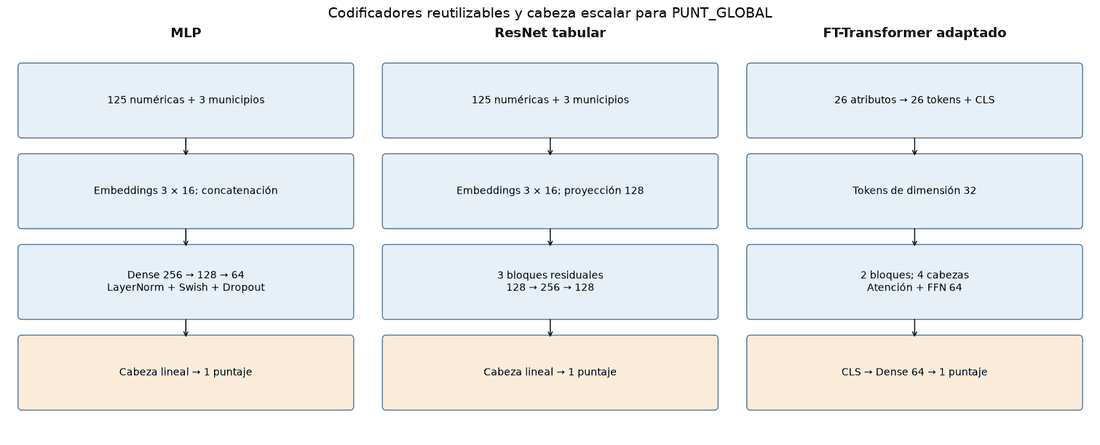

In [40]:
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 3, figsize=(15, 6), layout="constrained")
esquemas = {
    "MLP": ["125 numéricas + 3 municipios", "Embeddings 3 × 16; concatenación", "Dense 256 → 128 → 64\nLayerNorm + Swish + Dropout", "Cabeza lineal → 1 puntaje"],
    "ResNet tabular": ["125 numéricas + 3 municipios", "Embeddings 3 × 16; proyección 128", "3 bloques residuales\n128 → 256 → 128", "Cabeza lineal → 1 puntaje"],
    "FT-Transformer adaptado": ["26 atributos → 26 tokens + CLS", "Tokens de dimensión 32", "2 bloques; 4 cabezas\nAtención + FFN 64", "CLS → Dense 64 → 1 puntaje"],
}
for ax, (nombre, bloques) in zip(axes, esquemas.items()):
    ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis("off"); ax.set_title(nombre, fontsize=13, weight="bold")
    for j, texto in enumerate(bloques):
        y = .88 - j * .23
        ax.add_patch(FancyBboxPatch((.04, y-.11), .92, .17, boxstyle="round,pad=0.01",
                                   facecolor="#e7f0f7" if j < 3 else "#faecd9", edgecolor="#537692"))
        ax.text(.50, y-.025, texto, ha="center", va="center", fontsize=10)
        if j < 3: ax.annotate("", xy=(.50, y-.17), xytext=(.50, y-.115), arrowprops={"arrowstyle": "->"})
fig.suptitle("Codificadores reutilizables y cabeza escalar para PUNT_GLOBAL", fontsize=14)
plt.show()

## **5. Implementación de transferencia y ajuste fino**

El codificador de origen se clona y recibe exactamente los pesos del modelo suministrado. La cabeza nueva se inicializa de forma independiente. En extracción congelada, `trainable=False` impide actualizar el codificador y `training=False` desactiva su Dropout. Al activar ajuste fino se reconstruye la conexión para que Dropout vuelva a seguir el modo de ejecución; se preservan **tanto el codificador como la cabeza del calentamiento** y se compila después de descongelar, con un nuevo optimizador y tasa menor.

El mecanismo es común a las tres familias. La transferencia supervisada de fase 4 exige un checkpoint de origen con actualizaciones reales, esquema compatible, filas de origen autorizadas y huella íntegra. **Copiar pesos de una inicialización solo verifica la implementación; no constituye aprendizaje por transferencia**. La comprobación de esta entrega distingue explícitamente esas dos situaciones y rechaza una inicialización si se intenta usar como checkpoint preentrenado.

In [ ]:
def construir_transferencia(modelo_origen, modo="congelado", seed=42):
    """Copia el encoder recibido y crea una cabeza nueva e independiente.

    En modo congelado solo es entrenable la cabeza. En modo fino también se
    habilita el encoder. Esta función no entrena, no compila y no presupone
    que el modelo de origen tenga pesos aprendidos.
    """
    if modo not in {"congelado", "fino"}:
        raise ValueError("El modo debe ser 'congelado' o 'fino'.")
    keras.utils.set_random_seed(seed)
    origen = modelo_origen.get_layer("encoder")
    encoder = keras.models.clone_model(origen)
    encoder.set_weights(origen.get_weights())
    encoder.trainable = modo == "fino"
    cabeza_original = modelo_origen.get_layer("cabeza_regresion")
    cabeza = keras.models.clone_model(cabeza_original)
    # Los inicializadores de una configuración clonada pueden conservar semilla:
    # se reconstruyen explícitamente para que la cabeza sea nueva en cada semilla.
    for capa in cabeza.layers:
        if isinstance(capa, keras.layers.Dense):
            capa.kernel.assign(keras.initializers.GlorotUniform()(capa.kernel.shape))
            if capa.use_bias:
                capa.bias.assign(ops.zeros_like(capa.bias))
    inputs = {
        "numericas": keras.Input(
            shape=origen.input["numericas"].shape[1:], dtype="float32", name="numericas"
        ),
        "municipios": keras.Input(
            shape=origen.input["municipios"].shape[1:], dtype="int32", name="municipios"
        ),
    }
    # training=False desactiva dropout durante la extracción congelada. En modo
    # fino el estado de entrenamiento se propaga normalmente desde el modelo.
    representacion = encoder(inputs, training=False) if modo == "congelado" else encoder(inputs)
    salida = cabeza(representacion)
    return keras.Model(
        inputs=inputs, outputs=salida, name=f"{modelo_origen.name}_{modo}"
    )


def activar_ajuste_fino(modelo_congelado, lr=3e-5, loss="mse", weight_decay=1e-4):
    """Descongela copiando encoder y cabeza, sin perder el calentamiento.

    Se reconstruye el grafo para que Dropout vuelva a obedecer ``training``;
    una llamada a un encoder con ``training=False`` permanece fijada aunque se
    modifique después su propiedad ``trainable``. Se conserva el estado de
    ambos componentes y se crea un optimizador nuevo después de descongelar.
    """
    encoder_origen = modelo_congelado.get_layer("encoder")
    cabeza_origen = modelo_congelado.get_layer("cabeza_regresion")
    encoder = keras.models.clone_model(encoder_origen)
    encoder.set_weights(encoder_origen.get_weights())
    encoder.trainable = True
    cabeza = keras.models.clone_model(cabeza_origen)
    cabeza.set_weights(cabeza_origen.get_weights())
    cabeza.trainable = True
    inputs = {
        "numericas": keras.Input(
            shape=encoder_origen.input["numericas"].shape[1:],
            dtype="float32",
            name="numericas",
        ),
        "municipios": keras.Input(
            shape=encoder_origen.input["municipios"].shape[1:],
            dtype="int32",
            name="municipios",
        ),
    }
    salida = cabeza(encoder(inputs))
    modelo_fino = keras.Model(
        inputs=inputs,
        outputs=salida,
        name=f"{modelo_congelado.name}_ajuste_fino",
    )
    return compile_model(modelo_fino, lr=lr, loss=loss, weight_decay=weight_decay)

## **6. Verificación ejecutada de la implementación**

Se comprueban formas y tipos de entrada, salida escalar finita, soporte de lotes de distinto tamaño, tratamiento del OOV, gradientes finitos y conectados, integridad tras guardar/recargar y conservación de pesos al copiar, congelar y descongelar. Se calcula un gradiente sobre un lote de entrenamiento para verificar diferenciabilidad, **sin aplicar el gradiente ni ejecutar pasos del optimizador**. Las pérdidas y salidas aleatorias de estas comprobaciones no se reportan como métricas de regresión.

La prueba de transferencia usa las inicializaciones de esta fase como objetos de comprobación. Los artefactos se rotulan `inicializacion_sin_entrenamiento`; el control de carga no los acepta como pesos aprendidos. Los checkpoints entrenados, su procedencia y la variación efectiva de parámetros durante fine-tuning pertenecen al experimento de fase 4.

In [ ]:
def huella_pesos(modelo):
    digest = hashlib.sha256()
    for peso in modelo.get_weights():
        digest.update(str(peso.shape).encode())
        digest.update(peso.tobytes())
    return digest.hexdigest()


def cargar_codificador_preentrenado(ruta, metadatos):
    """Acepta únicamente un checkpoint entrenado en el origen autorizado."""
    requeridos = {"etapa", "actualizaciones", "esquema_sha256", "indices_origen_sha256",
                  "checkpoint_sha256", "usa_filas_reservadas"}
    if not requeridos.issubset(metadatos):
        raise ValueError("Metadatos incompletos del checkpoint de origen.")
    pasos = metadatos["actualizaciones"]
    pasos_validos = isinstance(pasos, (int, np.integer)) and not isinstance(pasos, (bool, np.bool_)) and pasos > 0
    if metadatos["etapa"] != "preentrenamiento_origen" or not pasos_validos:
        raise ValueError("El checkpoint no acredita preentrenamiento; una inicialización no es transferible como aprendizaje.")
    if metadatos["usa_filas_reservadas"] is not False:
        raise ValueError("El checkpoint incorpora filas reservadas.")
    if metadatos["esquema_sha256"] != contrato_experimental["esquema_sha256"]:
        raise ValueError("El esquema o los parámetros de preparación son incompatibles.")
    if metadatos["indices_origen_sha256"] != contrato_experimental["indices_origen_sha256"]:
        raise ValueError("El origen no coincide con las filas autorizadas de entrenamiento.")
    if sha256_archivo(Path(ruta)) != metadatos["checkpoint_sha256"]:
        raise ValueError("La integridad del checkpoint no coincide con su registro.")
    modelo = keras.models.load_model(ruta, compile=False)
    modelo.get_layer("encoder")
    modelo.get_layer("cabeza_regresion")
    return modelo


def verificar_implementacion(modelos, x, y, carpeta):
    """Comprueba interfaces y diferenciabilidad; no actualiza ningún peso."""
    carpeta.mkdir(parents=True, exist_ok=True)
    resultados, artefactos = [], {}
    for familia, modelo in modelos.items():
        antes = huella_pesos(modelo)
        prediccion = modelo(x, training=False).numpy()
        assert prediccion.shape == (len(y), 1) and np.isfinite(prediccion).all()
        uno = {k: v[:1] for k, v in x.items()}
        assert modelo(uno, training=False).shape == (1, 1)
        capa_municipios = modelo.get_layer("encoder").get_layer("embeddings_municipios")
        assert np.count_nonzero(capa_municipios(np.zeros((3, 3), dtype="int32")).numpy()) == 0
        with tf.GradientTape() as tape:
            salida = modelo(x, training=False)
            perdida = tf.reduce_mean(tf.square(tf.convert_to_tensor(y) - salida))
        gradientes = tape.gradient(perdida, modelo.trainable_weights)
        assert np.isfinite(float(perdida)) and all(g is not None for g in gradientes)
        assert all(bool(tf.reduce_all(tf.math.is_finite(g.values if isinstance(g, tf.IndexedSlices) else g)))
                   for g in gradientes)
        assert any(bool(tf.reduce_any(tf.not_equal(g.values if isinstance(g, tf.IndexedSlices) else g, 0)))
                   for g in gradientes)
        assert huella_pesos(modelo) == antes and int(modelo.optimizer.iterations.numpy()) == 0

        ruta = carpeta / f"{familia}_inicial.keras"
        modelo.save(ruta)
        restaurado = keras.models.load_model(ruta, compile=False)
        np.testing.assert_allclose(restaurado(x, training=False).numpy(), prediccion, rtol=1e-6, atol=1e-6)
        assert huella_pesos(restaurado) == antes

        congelado = construir_transferencia(modelo, modo="congelado", seed=SEED + 1)
        compile_model(congelado, lr=3e-4)
        assert not congelado.get_layer("encoder").trainable_weights
        assert huella_pesos(congelado.get_layer("encoder")) == huella_pesos(modelo.get_layer("encoder"))
        assert huella_pesos(congelado.get_layer("cabeza_regresion")) != huella_pesos(modelo.get_layer("cabeza_regresion"))
        # El ajuste fino conserva también la cabeza; no pierde el calentamiento.
        fino = activar_ajuste_fino(congelado, lr=3e-5)
        assert fino.get_layer("encoder").trainable_weights
        assert huella_pesos(fino.get_layer("encoder")) == huella_pesos(congelado.get_layer("encoder"))
        assert huella_pesos(fino.get_layer("cabeza_regresion")) == huella_pesos(congelado.get_layer("cabeza_regresion"))
        np.testing.assert_allclose(fino(x, training=False).numpy(), congelado(x, training=False).numpy(), rtol=1e-6, atol=1e-6)
        with tf.GradientTape() as tape:
            perdida_fina = tf.reduce_mean(tf.square(tf.convert_to_tensor(y) - fino(x, training=False)))
        gradientes_finos = tape.gradient(perdida_fina, fino.get_layer("encoder").trainable_weights)
        assert all(g is not None for g in gradientes_finos)
        assert int(fino.optimizer.iterations.numpy()) == int(congelado.optimizer.iterations.numpy()) == 0

        metadatos = {"etapa": "inicializacion_sin_entrenamiento", "actualizaciones": 0,
                     "esquema_sha256": contrato_experimental["esquema_sha256"],
                     "indices_origen_sha256": contrato_experimental["indices_origen_sha256"],
                     "checkpoint_sha256": sha256_archivo(ruta), "usa_filas_reservadas": False}
        try:
            cargar_codificador_preentrenado(ruta, metadatos)
        except ValueError as error:
            assert "no acredita preentrenamiento" in str(error)
        else:
            raise AssertionError("Se aceptó una inicialización como pesos aprendidos.")
        artefactos[familia] = {**metadatos, "archivo": ruta.name, "pesos_sha256": antes}
        resultados.append({"familia": familia, "salida (B,1) finita": True,
                           "OOV = vector cero": True, "gradientes finitos": True,
                           "recarga idéntica": True, "copia del codificador": True,
                           "congelación y ajuste fino": True, "inicialización rechazada como preentrenada": True,
                           "pasos de optimizador": 0})
    return pd.DataFrame(resultados), artefactos

In [ ]:
# Un lote pequeño de train basta para comprobar interfaces y gradientes.
x_verificacion = {nombre: valor[:32] for nombre, valor in x_comprobacion.items()}
y_verificacion = y_comprobacion[:32]
verificaciones_modelos, artefactos_iniciales = verificar_implementacion(
    modelos_fase3, x_verificacion, y_verificacion, RUTA_FASE3 / "arquitecturas")
display(verificaciones_modelos)
assert verificaciones_modelos["pasos de optimizador"].eq(0).all()
print("Las tres familias aprobaron los controles; ningún peso se optimizó y prueba no se utilizó para modelar.")

## **7. Persistencia, reproducibilidad y cierre de la fase 3**

La ejecución genera el contrato de particiones, la configuración experimental, el plan de 12 combinaciones, el resumen de arquitecturas y las evidencias de funcionamiento en `resultados_fase3`. Las matrices y transformaciones de fase 2 se reutilizan sin cambios. Las huellas del esquema y de las filas de origen/destino permiten comprobar correspondencia antes de cargar un checkpoint aprendido.

Los archivos `.keras` de esta entrega documentan arquitectura e inicialización; no se entregan como modelos predictivos entrenados. Toda definición y generación está contenida en este cuaderno. Para ejecutarlo desde una carpeta vacía solo se requiere el notebook y conexión a internet: se recuperan los datos originales de GitHub y se reconstruyen los resultados locales. No se requieren nuevos datos, pesos privados ni cargas manuales de matrices preparadas.

In [ ]:
evidencia_fase3 = {
    "fase": 3, "fecha_verificacion": "2026-10-26", "entorno": entorno_fase3,
    "modelos": tabla_arquitecturas.to_dict(orient="records"),
    "verificaciones": verificaciones_modelos.to_dict(orient="records"),
    "artefactos": artefactos_iniciales, "pasos_optimizador": 0,
    "filas_train": len(particiones["train"]["y"]),
    "filas_validation": len(particiones["validation"]["y"]),
    "filas_test": len(particiones["test"]["y"]),
    "prueba_utilizada_para_entrenar_o_seleccionar": False,
    "estado_entrega": "Diseño e implementación verificados",
}
for nombre, objeto in [
    ("contrato_experimental.json", contrato_experimental),
    ("configuracion_experimental.json", {**config_experimental, "arquitecturas": CONFIG_MODELOS}),
    ("evidencia_implementacion.json", evidencia_fase3),
]:
    ruta = RUTA_FASE3 / nombre
    ruta.write_text(json.dumps(objeto, ensure_ascii=False, indent=2), encoding="utf-8")
    assert json.loads(ruta.read_text(encoding="utf-8")) == objeto
plan_experimentos.to_csv(RUTA_FASE3 / "plan_experimentos.csv", index=False)
tabla_dominios.to_csv(RUTA_FASE3 / "dominios_por_particion.csv", index=False)
tabla_arquitecturas.to_csv(RUTA_FASE3 / "arquitecturas.csv", index=False)
verificaciones_modelos.to_csv(RUTA_FASE3 / "verificaciones.csv", index=False)
display(Markdown(
    f"**Resultado de la fase 3.** Se conservan {sum(len(p['y']) for p in particiones.values()):,} registros preparados "
    f"y la partición principal. El origen contiene {contrato_experimental['n_origen_train']:,} registros de train y "
    f"el destino {contrato_experimental['n_destino_train']:,}. Se implementaron **{len(modelos_fase3)} familias**, "
    f"**{len(plan_experimentos)} combinaciones experimentales** y el mecanismo de transferencia y ajuste fino. "
    "Las tres arquitecturas aprobaron las comprobaciones de funcionamiento y persistencia, con **0 actualizaciones "
    "de pesos**. El diseño queda definido para ejecutar el entrenamiento y la selección en la fase 4."
))

### **Conclusiones de diseño e implementación**

El experimento compara capacidad densa, conexiones residuales y atención entre atributos sobre una representación común. Los controles de destino, población completa y codificador congelado permiten interpretar el aporte de origen y de la actualización de representaciones sin dar por cierta una mejora. La implementación conserva la escala del puntaje, los extremos válidos y las reglas de preparación ya verificadas.

La separación entre inicialización, preentrenamiento y ajuste fino es explícita en el código y en los artefactos. La fase 3 demuestra que los modelos y sus interfaces funcionan; la calidad predictiva se establecerá con el entrenamiento, la validación y la evaluación final. El holdout sigue siendo interno y aleatorio: los resultados futuros deberán comunicar soporte por cohortes, variabilidad y las limitaciones de disponibilidad anticipada de atributos y de generalización institucional.

| Compromiso | Evidencia de cierre |
|---|---|
| Partición y prevención de fuga | Contrato de filas, dominios disjuntos dentro de train y transformaciones conservadas |
| Diseño acorde con datos y objetivo | Tres familias tabulares, 26 atributos, salida escalar y pérdida de regresión |
| Comparación controlada | 12 combinaciones, referencias constantes, métricas, tasas, semillas y presupuesto definidos |
| Transferencia y fine-tuning | Codificador separable, cabeza nueva, congelación, continuidad del calentamiento y recompilación |
| Implementación reproducible | Lotes correctos, gradientes, OOV nulo, serialización y carga verificadas sin pasos de optimización |

---
# **Fase 4 — Entrenamiento, validación y entrega final**

**Periodo de trabajo:** 29 de octubre–5 de noviembre de 2026. **Entrega:** jueves 5 de noviembre de 2026.

Esta fase entrena las tres familias implementadas, contrasta los cuatro regímenes y selecciona hiperparámetros sin modificar la población, las particiones ni la preparación. El cierre integra la evaluación final, la interpretación de errores y la aplicación de un modelo persistido. Prueba se consulta únicamente después de sellar la configuración elegida mediante validación.

| Objetivo de la fase | Evidencia que produce la ejecución |
|---|---|
| Entrenar y validar modelos | Curvas, checkpoints aprendidos, cambios de pesos y métricas de todas las alternativas |
| Comparar familias y transferencia | Dos paneles, cuatro regímenes, tres semillas y contrastes pareados en destino |
| Seleccionar hiperparámetros | Exploración de tasas; Optuna en la variante seleccionada; confirmación comparable |
| Evaluar y aplicar | Prueba reservada, referencias constantes, análisis por grupos, recarga y ejemplo con contexto sin puntajes |
| Documentar el cierre | Registro de recursos, manifiesto de artefactos, conclusiones y matriz de objetivos |

## **1. Protocolo de entrenamiento y recursos**

Se conserva el protocolo de fase 3: **45 candidatos exploratorios y 45 ejecuciones confirmatorias** antes de Optuna, correspondientes a 15 variantes operativas —el control completo tiene un monitor distinto en cada panel—. Se exploran tres tasas, con hasta 4.000 pasos por candidato, y se confirman las tasas elegidas con semillas **42, 43 y 44**, con hasta 20.000 pasos por repetición. Los topes incluyen todas las etapas de transferencia. Se restaura el menor MAE observado; la paciencia exige una mejora acumulada de 0,1 puntos y admite cuatro controles sin ella. El calentamiento fino conserva su último estado al completar el presupuesto fijo. Cada 500 pasos se valida; también se valida el último bloque parcial de una etapa.

La selección global adicional de esta entrega considera el **MAE global medio de las 15 variantes confirmadas**. Amplía la selección del panel de arquitecturas para permitir que gane también un régimen de transferencia. Conserva los dos paneles originales: arquitectura por MAE global y adaptación por MAE de destino. Una variante adaptada conserva su monitor de destino tanto antes como durante Optuna; el objetivo de Optuna es siempre el MAE global obtenido al restaurar ese checkpoint. No se confunde ese objetivo con el monitor de parada. Una diferencia menor a 0,1 puntos se resuelve por RMSE y luego por costo.

**Optuna:** 24 ensayos TPE, incluida la configuración previa como primer ensayo; poda por mediana tras seis ensayos completos y 1.500 pasos. Se optimizan tasa, decaimiento, dropout y dimensiones/profundidad de la familia seleccionada. El lote 512 y la pérdida MSE permanecen fijos. La búsqueda usa el presupuesto exploratorio y su mejor configuración se vuelve a entrenar desde nuevas inicializaciones con las tres semillas y el presupuesto confirmatorio. Si la configuración previa resulta preferible según la regla establecida, se conserva. La búsqueda adicional beneficia solo al ganador inicial y se informa por separado de la comparación equitativa entre familias.

La implementación está orientada a una **GPU NVIDIA L4**: precisión mixta `float16`, variables y salida en `float32`, escalado dinámico de pérdida, entradas en RAM del host, extracción de lotes con `tf.data`, cuatro hilos de entrada y prefetch. Se utiliza una sola GPU y un ensayo a la vez para evitar competencia de memoria. El lote 512 se mantiene para respetar la comparación; no se fuerza consumo de VRAM sin beneficio medido. Los pasos intentados y las actualizaciones efectivas se registran por separado, porque el escalado de pérdida puede omitir actualizaciones no finitas.

En la ejecución se incorporó una recuperación por etapa en `float32` ante pérdidas o validaciones no finitas. La política conserva las ejecuciones terminadas y documenta cada recuperación; el análisis de la sección 3 identifica las cuatro incidencias observadas en ResNet y su efecto sobre la homogeneidad numérica.

Los checkpoints permiten recuperar etapas interrumpidas y evitar repetir ejecuciones terminadas. La recuperación conserva los pesos, el optimizador, el presupuesto y el historial; no se promete identidad bit a bit del entrenamiento tras una interrupción o entre dispositivos. Las huellas impiden mezclar otro esquema, partición, precisión o configuración. El costo físico cuenta una sola vez los orígenes compartidos y conserva el costo de ensayos podados; el costo conceptual de cada transferencia incluye su preentrenamiento.

Fuentes: [precisión mixta de Keras](https://keras.io/api/mixed_precision/), [escalado de pérdida](https://keras.io/api/optimizers/loss_scale_optimizer/), [persistencia de Optuna](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html) y [poda por mediana](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.pruners.MedianPruner.html).

In [ ]:
import optuna
import platform
import shutil

RUTA_FASE4 = ROOT / "resultados_fase4"
# La comparación completa se ejecuta en GPU. Cambiar a True permite asumir
# explícitamente el costo del mismo protocolo completo en CPU, sin reducir datos.
PERMITIR_ENTRENAMIENTO_COMPLETO_CPU = False
GPU_FASE4 = tf.config.list_physical_devices("GPU")
entorno_fase4 = {
    "Python": sys.version.split()[0], "TensorFlow": tf.__version__, "Keras": keras.__version__,
    "Optuna": optuna.__version__, "plataforma": platform.platform(),
    "CPU_logicas": os.cpu_count(), "GPU": [tf.config.experimental.get_device_details(g).get("device_name", g.name)
                                           for g in GPU_FASE4],
    "precision_entrenamiento": "mixed_float16" if GPU_FASE4 else "float32",
    "RAM_recomendada_GiB": 16, "disco_libre_GiB": round(shutil.disk_usage(ROOT).free/1024**3, 1),
}
display(pd.DataFrame([entorno_fase4]))
if not GPU_FASE4 and not PERMITIR_ENTRENAMIENTO_COMPLETO_CPU:
    raise RuntimeError("La fase 4 completa está configurada para GPU. Active la L4 y reinicie el kernel; "
                       "para ejecutar el mismo experimento en CPU, establezca PERMITIR_ENTRENAMIENTO_COMPLETO_CPU=True.")

## **2. Implementación del entrenamiento y recuperación**

Las siguientes funciones consumen `particiones`, `dominios`, `estado_preprocesamiento` y las arquitecturas de la fase 3. No descargan nuevas fuentes ni vuelven a dividir los datos. Los roles de desarrollo admiten únicamente entrenamiento y validación. Para cada etapa se comprueba que hubo actualizaciones efectivas, que la cabeza cambió, que el codificador congelado permaneció idéntico y que el codificador entrenable se actualizó. La recarga restablece explícitamente la congelación de las capas internas antes de reconstruir el optimizador y recuperar sus momentos; también verifica que ninguna variable del codificador congelado figure entre las entrenables.

In [ ]:
"""Entrenamiento, comparación y optimización reproducibles de Saber 11."""
import gc
import hashlib
import json
import math
import os
import platform
import resource
import shutil
import time
import zipfile
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import optuna

keras = tf.keras


def json_seguro(ruta, objeto):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_suffix(ruta.suffix + '.tmp')
    temporal.write_text(json.dumps(objeto, ensure_ascii=False, indent=2,
                                  allow_nan=False), encoding='utf-8')
    temporal.replace(ruta)


def guardar_modelo_f4(modelo, ruta):
    """Sustituye el checkpoint solo después de cerrar un archivo Keras completo."""
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.stem+'.tmp.keras')
    modelo.save(temporal)
    temporal.replace(ruta)


def cargar_modelo_f4(ruta, compile=True):
    """Recupera precisión, congelación, pesos y optimizador de un archivo Keras.

    Se restaura la política de las capas archivadas antes de crear los modelos
    funcionales y los slots. Esto conserva LossScaleOptimizer al pasar de GPU
    a CPU y evita variables entrenables creadas dentro de un encoder congelado.
    """
    ruta = Path(ruta)
    with zipfile.ZipFile(ruta) as archivo:
        configuracion = json.loads(archivo.read('config.json'))
    politicas = set()
    def leer_politicas(objeto):
        if isinstance(objeto, dict):
            if objeto.get('class_name') == 'DTypePolicy':
                politicas.add(objeto['config']['name'])
            for valor in objeto.values():
                leer_politicas(valor)
        elif isinstance(objeto, list):
            for valor in objeto:
                leer_politicas(valor)
    leer_politicas(configuracion['config'])
    mixtas = politicas & {'mixed_float16', 'mixed_bfloat16'}
    if len(mixtas) > 1:
        raise ValueError('El archivo contiene políticas mixtas incompatibles.')
    politica_archivada = next(iter(mixtas)) if mixtas else 'float32'
    politica_anterior = keras.mixed_precision.global_policy()
    try:
        keras.mixed_precision.set_global_policy(politica_archivada)
        modelo = keras.models.load_model(ruta, compile=False)
        encoder = modelo.get_layer('encoder')
        entrenable = encoder.trainable
        encoder.trainable = not entrenable
        encoder.trainable = entrenable
        if not entrenable:
            variables_encoder = {id(v) for v in encoder.variables}
            if any(id(v) in variables_encoder for v in modelo.trainable_variables):
                raise AssertionError('El modelo recargado expone variables del codificador congelado.')
        if compile and configuracion.get('compile_config'):
            modelo.compile_from_config(configuracion['compile_config'])
            if not modelo.optimizer.built:
                modelo.optimizer.build(modelo.trainable_variables)
            # La carga pública restaura momentum, iteraciones y escala dinámica.
            modelo.load_weights(ruta)
    finally:
        keras.mixed_precision.set_global_policy(politica_anterior)
    return modelo


def sha_archivo(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(8 * 1024**2), b''):
            h.update(bloque)
    return h.hexdigest()


def firma_f4(objeto):
    return hashlib.sha256(json.dumps(objeto, sort_keys=True, ensure_ascii=False,
                                    separators=(',', ':')).encode()).hexdigest()


def metricas_f4(y, pred):
    y, pred = np.asarray(y, dtype='float64').ravel(), np.asarray(pred, dtype='float64').ravel()
    if len(y) == 0 or y.shape != pred.shape or not (np.isfinite(y).all() and np.isfinite(pred).all()):
        raise ValueError('Etiquetas/predicciones vacías, desalineadas o no finitas.')
    error = pred - y
    sst = float(np.sum((y - y.mean())**2))
    return {'n': len(y), 'mae': float(np.mean(np.abs(error))),
            'rmse': float(np.sqrt(np.mean(error**2))),
            'r2': float(1 - np.sum(error**2) / sst) if sst else None,
            'sesgo_pred_menos_real': float(error.mean())}


def huella_pesos(modelo):
    h = hashlib.sha256()
    for peso in modelo.get_weights():
        h.update(peso.tobytes())
    return h.hexdigest()


def estado_generadores_f4(modelo):
    """Persiste semillas/contadores Dropout que .keras no incluye en pesos."""
    return [{'indice': i, 'forma': list(v.shape), 'valor': v.numpy().tolist()}
            for i, v in enumerate(modelo.variables) if v.name == 'seed_generator_state']


def restaurar_generadores_f4(modelo, estados):
    actuales = [(i, v) for i, v in enumerate(modelo.variables) if v.name == 'seed_generator_state']
    if len(actuales) != len(estados):
        raise ValueError('Los generadores aleatorios no coinciden con el checkpoint.')
    for (indice, variable), guardado in zip(actuales, estados):
        if indice != guardado['indice'] or list(variable.shape) != guardado['forma']:
            raise ValueError('El orden de generadores aleatorios no coincide.')
        variable.assign(np.asarray(guardado['valor'], dtype=variable.dtype))


def memoria_f4():
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    salida = {'rss_max_proceso_mib': float(rss / (1024**2 if platform.system() == 'Darwin' else 1024))}
    if tf.config.list_physical_devices('GPU'):
        try:
            salida['gpu_pico_mib'] = float(tf.config.experimental.get_memory_info('GPU:0')['peak']/1024**2)
        except (ValueError, RuntimeError):
            salida['gpu_pico_mib'] = None
    return salida


class MotorSaber11:
    """Solo train/validation durante desarrollo; test requiere una selección sellada."""
    def __init__(self, particiones, dominios, estado, contrato, configuracion, ruta,
                 batch_size=512, eval_batch_size=4096, control_cada=500,
                 paciencia=4, min_delta=.1, precision=None):
        self.particiones, self.dominios, self.estado = particiones, dominios, estado
        self.contrato, self.configuracion = contrato, deepcopy(configuracion)
        self.ruta = Path(ruta); self.ruta.mkdir(parents=True, exist_ok=True)
        self.batch, self.eval_batch = int(batch_size), int(eval_batch_size)
        self.control, self.paciencia, self.min_delta = int(control_cada), int(paciencia), float(min_delta)
        self.precision = precision or ('mixed_float16' if tf.config.list_physical_devices('GPU') else 'float32')
        keras.mixed_precision.set_global_policy(self.precision)
        self.tensores = {}
        self.huella = firma_f4({'contrato': contrato, 'configuracion': configuracion,
            'batch': self.batch, 'control': self.control, 'paciencia': self.paciencia,
            'min_delta': self.min_delta, 'precision': self.precision,
            'version_motor': 5, 'TensorFlow': tf.__version__, 'Keras': keras.__version__})
        existente = self.ruta / 'identidad_experimento.json'
        if existente.exists() and json.loads(existente.read_text())['sha256'] != self.huella:
            raise ValueError('La carpeta contiene otro contrato, precisión o configuración. Use una carpeta nueva.')
        json_seguro(existente, {'sha256': self.huella, 'precision': self.precision,
                    'contrato': contrato, 'configuracion': configuracion,
                    'hardware': {'plataforma': platform.platform(), 'cpu_logicas': os.cpu_count(),
                                 'gpu': [tf.config.experimental.get_device_details(g).get('device_name', g.name)
                                         for g in tf.config.list_physical_devices('GPU')]}})

    def posiciones(self, rol):
        especificaciones = {'train_completo': ('train', None), 'train_origen': ('train', 'origen'),
            'train_destino': ('train', 'destino'), 'validation_completa': ('validation', None),
            'validation_origen': ('validation', 'origen'), 'validation_destino': ('validation', 'destino')}
        if rol not in especificaciones:
            raise ValueError('Rol excluido del desarrollo: ' + rol)
        particion, dominio = especificaciones[rol]
        pos = (np.arange(len(self.particiones[particion]['y']), dtype='int32') if dominio is None
               else np.asarray(self.dominios[particion][dominio], dtype='int32'))
        if not len(pos):
            raise ValueError('Dominio vacío: ' + rol)
        return particion, pos

    def _tensores(self, particion):
        if particion not in self.tensores:
            p = self.particiones[particion]
            with tf.device('/CPU:0'):
                self.tensores[particion] = (tf.convert_to_tensor(p['X_num'], tf.float32),
                    tf.convert_to_tensor(p['X_cat'], tf.int32),
                    tf.convert_to_tensor(np.asarray(p['y']).reshape(-1, 1), tf.float32))
        return self.tensores[particion]

    def dataset(self, rol, seed=42, saltar=0):
        particion, pos = self.posiciones(rol)
        num, cat, y = self._tensores(particion)
        entrenamiento = rol.startswith('train_')
        with tf.device('/CPU:0'):
            ds = tf.data.Dataset.from_tensor_slices(pos)
            if entrenamiento:
                ds = ds.shuffle(len(pos), seed=seed, reshuffle_each_iteration=True)
            ds = ds.batch(self.batch if entrenamiento else self.eval_batch, drop_remainder=False)
            ds = ds.map(lambda idx: ({'numericas': tf.gather(num, idx), 'municipios': tf.gather(cat, idx)},
                                     tf.gather(y, idx)), num_parallel_calls=4, deterministic=True)
            if entrenamiento:
                ds = ds.repeat().skip(int(saltar))
            opciones = tf.data.Options()
            opciones.deterministic = True
            opciones.threading.private_threadpool_size = 4
            return ds.with_options(opciones).prefetch(2)

    def predecir(self, modelo, particion='validation', posiciones=None, sello=None):
        if particion == 'test':
            self.verificar_sello(sello)
        elif particion not in {'train', 'validation'}:
            raise ValueError('Partición desconocida.')
        p = self.particiones[particion]
        pos = np.arange(len(p['y']), dtype='int32') if posiciones is None else np.asarray(posiciones)
        salida = np.empty(len(pos), dtype='float32')
        @tf.function(reduce_retracing=True)
        def inferir(x):
            return modelo(x, training=False)
        for a in range(0, len(pos), self.eval_batch):
            idx = pos[a:a+self.eval_batch]
            x = {'numericas': np.asarray(p['X_num'][idx], dtype='float32'),
                 'municipios': np.asarray(p['X_cat'][idx], dtype='int32')}
            salida[a:a+len(idx)] = np.asarray(inferir(x)).ravel()
        if not np.isfinite(salida).all():
            raise FloatingPointError('Predicciones no finitas.')
        return salida

    def compilar(self, modelo, hp, factor=1.):
        modelo.compile(optimizer=keras.optimizers.AdamW(
            learning_rate=float(hp['lr'])*factor, weight_decay=float(hp.get('weight_decay', 1e-4)),
            clipnorm=1.), loss='mse', metrics=[keras.metrics.MeanAbsoluteError(name='mae'),
            keras.metrics.RootMeanSquaredError(name='rmse')], jit_compile=False,
            steps_per_execution=1, auto_scale_loss=True)
        return modelo

    def _ejemplos(self, rol, pasos):
        _, pos = self.posiciones(rol)
        lotes = math.ceil(len(pos)/self.batch)
        completos, resto = divmod(int(pasos), lotes)
        return completos*len(pos) + min(resto*self.batch, len(pos))

    def entrenar_etapa(self, modelo, rol, monitor, max_pasos, carpeta, hp, seed,
                       etapa, warm=False, trial=None, offset=0):
        """Guarda progreso, optimizador y mejor estado; nunca lee prueba."""
        carpeta = Path(carpeta); carpeta.mkdir(parents=True, exist_ok=True)
        meta = carpeta/'estado.json'; ultimo = carpeta/'ultimo.keras'; mejor = carpeta/'mejor.keras'
        identidad = firma_f4({'experimento': self.huella, 'hp': hp, 'rol': rol, 'monitor': monitor,
            'max_pasos': max_pasos, 'seed': seed, 'etapa': etapa, 'warm': warm})
        estado = {'identidad': identidad, 'terminado': False, 'pasos_intentados': 0,
            'actualizaciones': 0, 'mejor_mae': None, 'referencia_paciencia': None, 'espera': 0,
            'historial': [], 'segundos': 0., 'huella_inicial_encoder': huella_pesos(modelo.get_layer('encoder')),
            'huella_inicial_cabeza': huella_pesos(modelo.get_layer('cabeza_regresion'))}
        if meta.exists():
            estado = json.loads(meta.read_text())
            if estado['identidad'] != identidad:
                raise ValueError('Checkpoint de otra configuración: '+str(carpeta))
            ruta_carga = mejor if estado['terminado'] else ultimo
            if sha_archivo(ruta_carga) != estado['sha_carga']:
                raise ValueError('Checkpoint alterado o incompleto: '+str(ruta_carga))
            modelo = cargar_modelo_f4(ruta_carga)
            restaurar_generadores_f4(modelo, estado[
                'generadores_mejor' if estado['terminado'] else 'generadores_ultimo'])
            if estado['terminado']:
                return modelo, estado
        if etapa == 'cabeza':
            ids_encoder = {id(v) for v in modelo.get_layer('encoder').variables}
            if any(id(v) in ids_encoder for v in modelo.trainable_variables):
                raise AssertionError('La cabeza incluye variables del codificador congelado.')
        base_iter = int(modelo.optimizer.iterations.numpy())
        pasos_iniciales, updates_iniciales = estado['pasos_intentados'], estado['actualizaciones']
        pendientes = int(max_pasos) - pasos_iniciales
        if pendientes < 0:
            raise ValueError('El checkpoint excede el presupuesto de la etapa.')
        debe_entrenar = pendientes > 0 and (warm or estado['espera'] < self.paciencia)
        # Los controles regulares conservan su intervalo; se valida también
        # al agotar un último bloque menor (p. ej., 1.800 pasos: 500+500+500+300).
        motor = self
        segundos_iniciales = estado['segundos']
        inicio = time.perf_counter()
        class Control(keras.callbacks.Callback):
            def __init__(self, bloque):
                super().__init__()
                self.bloque = bloque
            def on_epoch_end(self, epoch, logs=None):
                logs = logs or {}
                valor = float(logs['val_mae'])
                if not np.isfinite(valor) or not np.isfinite(float(logs['loss'])):
                    raise FloatingPointError('Pérdida o validación no finita.')
                estado['pasos_intentados'] += self.bloque
                estado['actualizaciones'] = updates_iniciales+int(self.model.optimizer.iterations.numpy())-base_iter
                if estado['mejor_mae'] is None or valor < estado['mejor_mae']:
                    estado['mejor_mae'] = valor
                    estado['paso_mejor'] = estado['pasos_intentados']
                    guardar_modelo_f4(self.model, mejor)
                    estado['generadores_mejor'] = estado_generadores_f4(self.model)
                if estado['referencia_paciencia'] is None or valor < estado['referencia_paciencia']-motor.min_delta:
                    estado['referencia_paciencia'], estado['espera'] = valor, 0
                else:
                    estado['espera'] += 1
                global_mae = valor if monitor == 'validation_completa' else None
                if trial is not None and monitor != 'validation_completa':
                    pred = motor.predecir(self.model)
                    global_mae = metricas_f4(motor.particiones['validation']['y'], pred)['mae']
                estado['segundos'] = segundos_iniciales+time.perf_counter()-inicio
                estado['historial'].append({'update': offset+estado['pasos_intentados'],
                    'update_etapa': estado['pasos_intentados'], 'loss': float(logs['loss']),
                    'train_mae': float(logs['mae']), 'val_mae': valor, 'val_global_mae': global_mae,
                    'monitor': monitor, 'etapa': etapa,
                    'segundos': estado['segundos']})
                guardar_modelo_f4(self.model, ultimo)
                estado['generadores_ultimo'] = estado_generadores_f4(self.model)
                estado['sha_carga'] = sha_archivo(ultimo)
                json_seguro(meta, estado)
                print(f'  {carpeta.parent.name}/{etapa}: {estado["pasos_intentados"]}/{max_pasos} '
                      f'pasos; MAE({monitor})={valor:.3f}', flush=True)
                if trial is not None and not warm:
                    trial.report(global_mae, step=offset+estado['pasos_intentados'])
                    if trial.should_prune():
                        raise optuna.TrialPruned()
                if not warm and estado['espera'] >= motor.paciencia:
                    self.model.stop_training = True
        bloques_completos, resto = divmod(pendientes, self.control)
        if bloques_completos and debe_entrenar:
            modelo.fit(self.dataset(rol, seed, saltar=pasos_iniciales),
                validation_data=self.dataset(monitor), epochs=bloques_completos,
                steps_per_epoch=self.control, callbacks=[Control(self.control)],
                verbose=0, shuffle=False)
        detenido = not warm and estado['espera'] >= self.paciencia
        if resto and debe_entrenar and not detenido:
            modelo.fit(self.dataset(rol, seed, saltar=estado['pasos_intentados']),
                validation_data=self.dataset(monitor), epochs=1,
                steps_per_epoch=resto, callbacks=[Control(resto)],
                verbose=0, shuffle=False)
        estado['segundos'] = segundos_iniciales+time.perf_counter()-inicio
        # El calentamiento conserva el último estado; las demás etapas restauran
        # el menor MAE observado, incluso mejoras pequeñas inferiores a min_delta.
        if warm:
            shutil.copy2(ultimo, mejor)
            estado['generadores_mejor'] = estado['generadores_ultimo']
        modelo = cargar_modelo_f4(mejor)
        restaurar_generadores_f4(modelo, estado['generadores_mejor'])
        estado.update({'terminado': True, 'sha_carga': sha_archivo(mejor),
            'ejemplos_procesados': self._ejemplos(rol, estado['pasos_intentados']),
            'huella_final_encoder': huella_pesos(modelo.get_layer('encoder')),
            'huella_final_cabeza': huella_pesos(modelo.get_layer('cabeza_regresion')),
            **memoria_f4()})
        estado['encoder_cambio'] = estado['huella_inicial_encoder'] != estado['huella_final_encoder']
        estado['cabeza_cambio'] = estado['huella_inicial_cabeza'] != estado['huella_final_cabeza']
        if estado['actualizaciones'] <= 0:
            raise AssertionError('La etapa no realizó actualizaciones efectivas.')
        if etapa == 'cabeza' and estado['encoder_cambio']:
            raise AssertionError('El codificador congelado cambió.')
        if etapa in {'origen', 'ajuste', 'fino'} and not estado['encoder_cambio']:
            raise AssertionError('El codificador entrenable no cambió.')
        if not estado['cabeza_cambio']:
            raise AssertionError('La cabeza entrenable no cambió.')
        json_seguro(meta, estado)
        return modelo, estado

    def ejecutar(self, familia, regimen, panel, hp, seed, presupuesto, etiqueta, trial=None):
        especificacion = {'familia': familia, 'regimen': regimen, 'panel': panel, 'hp': hp,
            'seed': int(seed), 'presupuesto': presupuesto, 'etiqueta': etiqueta, 'motor': self.huella}
        id_run = f'{etiqueta}_{familia}_{regimen}_{panel}_s{seed}_{firma_f4(especificacion)[:12]}'
        carpeta = self.ruta/'ejecuciones'/id_run
        terminado = carpeta/'resultado.json'
        if terminado.exists():
            salida = json.loads(terminado.read_text())
            if sha_archivo(salida['checkpoint']) != salida['checkpoint_sha256']:
                raise ValueError('El checkpoint no coincide con el resultado.')
            return salida
        if (self.ruta/'seleccion_sellada.json').exists():
            raise ValueError('La selección ya fue sellada: no se permite entrenar nuevas ejecuciones después de prueba.')
        keras.backend.clear_session(); keras.utils.set_random_seed(seed)
        keras.mixed_precision.set_global_policy(self.precision)
        modelo = build_model(familia, self.estado, config=hp.get('arquitectura'), seed=seed)
        self.compilar(modelo, hp)
        arquitectura_params = int(modelo.count_params())
        etapas = []
        monitor_final = 'validation_completa' if panel == 'arquitectura' else 'validation_destino'
        if regimen.startswith('desde_cero'):
            rol = 'train_completo' if regimen == 'desde_cero_completo' else 'train_destino'
            modelo, e = self.entrenar_etapa(modelo, rol, monitor_final, presupuesto['scratch']['ajuste'],
                carpeta/'ajuste', hp, seed, 'ajuste', trial=trial)
            etapas.append(e)
        else:
            # La misma etapa de origen se reutiliza solo con idénticos datos,
            # arquitectura, tasa, semilla, presupuesto, precisión y monitor.
            limites = presupuesto[regimen]
            clave_origen = firma_f4({'motor': self.huella, 'familia': familia, 'hp': hp,
                'seed': seed, 'pasos': limites['origen'], 'monitor': 'validation_origen'})
            origen_dir = self.ruta/'origen'/clave_origen
            modelo, e = self.entrenar_etapa(modelo, 'train_origen', 'validation_origen',
                limites['origen'], origen_dir, hp, seed, 'origen')
            etapas.append(e)
            huella_origen = huella_pesos(modelo.get_layer('encoder'))
            modelo = construir_transferencia(modelo, modo='congelado', seed=seed+1000)
            assert huella_pesos(modelo.get_layer('encoder')) == huella_origen
            assert not modelo.get_layer('encoder').trainable
            self.compilar(modelo, hp)
            modelo, e = self.entrenar_etapa(modelo, 'train_destino', monitor_final,
                limites['cabeza'], carpeta/'cabeza', hp, seed, 'cabeza',
                warm=regimen == 'transferencia_fina',
                trial=trial if regimen == 'transferencia_congelada' else None,
                offset=sum(e['pasos_intentados'] for e in etapas))
            etapas.append(e)
            if regimen == 'transferencia_fina':
                antes = (huella_pesos(modelo.get_layer('encoder')), huella_pesos(modelo.get_layer('cabeza_regresion')))
                modelo = activar_ajuste_fino(modelo, lr=hp['lr']*.1,
                    weight_decay=hp.get('weight_decay', 1e-4))
                # clone_model puede conservar hijas congeladas aunque el Model
                # nuevo marque trainable=True. Se fuerza la propagación completa.
                encoder_fino = modelo.get_layer('encoder')
                encoder_fino.trainable = False
                encoder_fino.trainable = True
                ids_entrenables = {id(v) for v in modelo.trainable_variables}
                if any(id(v) not in ids_entrenables for v in encoder_fino.weights):
                    raise AssertionError('El ajuste fino no habilitó todos los pesos del codificador.')
                assert antes == (huella_pesos(modelo.get_layer('encoder')), huella_pesos(modelo.get_layer('cabeza_regresion')))
                self.compilar(modelo, hp, factor=.1)
                modelo, e = self.entrenar_etapa(modelo, 'train_destino', monitor_final,
                    limites['fino'], carpeta/'fino', hp, seed, 'fino', trial=trial,
                    offset=sum(e['pasos_intentados'] for e in etapas))
                etapas.append(e)
        pred = self.predecir(modelo)
        val = self.particiones['validation']['y']
        target = self.dominios['validation']['destino']
        met = metricas_f4(val, pred); met_destino = metricas_f4(val[target], pred[target])
        carpeta.mkdir(parents=True, exist_ok=True)
        checkpoint = carpeta/'modelo.keras'; guardar_modelo_f4(modelo, checkpoint)
        np.save(carpeta/'pred_validation.npy', pred, allow_pickle=False)
        historial = []
        for e in etapas:
            for h in e['historial']:
                historial.append({**h, 'ejecucion': id_run, 'modelo': familia+' / '+regimen})
        pd.DataFrame(historial).to_csv(carpeta/'historial.csv', index=False)
        salida = {**especificacion, **met, 'metricas_destino': met_destino,
            'ejecucion': id_run, 'checkpoint': str(checkpoint.resolve()),
            'checkpoint_sha256': sha_archivo(checkpoint),
            'pred_validation': str((carpeta/'pred_validation.npy').resolve()),
            'historial': str((carpeta/'historial.csv').resolve()),
            'monitor_final': monitor_final, 'parametros': arquitectura_params,
            'updates_actualizaciones': sum(e['actualizaciones'] for e in etapas),
            'pasos_intentados': sum(e['pasos_intentados'] for e in etapas),
            'ejemplos_procesados': sum(e['ejemplos_procesados'] for e in etapas),
            'segundos': sum(e['segundos'] for e in etapas),
            'etapas': etapas, 'prueba_utilizada': False, **memoria_f4()}
        json_seguro(terminado, salida)
        del modelo; gc.collect()
        return salida

    def verificar_sello(self, sello):
        if not sello or not Path(sello).exists():
            raise ValueError('Prueba requiere selección final sellada.')
        s = json.loads(Path(sello).read_text())
        if s['motor'] != self.huella or firma_f4(s['seleccion']) != s['seleccion_sha256']:
            raise ValueError('El sello no corresponde al experimento.')
        for archivo in s['archivos']:
            if sha_archivo(archivo['ruta']) != archivo['sha256']:
                raise ValueError('Artefacto alterado después de cerrar selección.')
        return s


def variantes_f4():
    filas = []
    for familia in CONFIG_MODELOS:
        filas.append({'familia': familia, 'regimen': 'desde_cero_completo', 'panel': 'arquitectura'})
        for regimen in ['desde_cero_completo', 'desde_cero_destino', 'transferencia_congelada', 'transferencia_fina']:
            filas.append({'familia': familia, 'regimen': regimen, 'panel': 'adaptacion'})
    return filas


def ordenar_candidatos(tabla, metrica='mae'):
    """Empates prácticos <0,1 puntos: RMSE y después costo; regla de fase 3."""
    mejor = float(tabla[metrica].min())
    cerca = tabla[tabla[metrica] < mejor+.1].copy()
    return cerca.sort_values(['rmse', 'segundos', metrica], kind='stable').iloc[0]


def tabla_ejecuciones(resultados):
    return pd.DataFrame([{k: r[k] for k in ['ejecucion', 'familia', 'regimen', 'panel', 'seed',
        'mae', 'rmse', 'r2', 'segundos', 'updates_actualizaciones', 'parametros', 'monitor_final']}
        | {'lr': r['hp']['lr'], 'mae_destino': r['metricas_destino']['mae'],
           'rmse_destino': r['metricas_destino']['rmse'], 'r2_destino': r['metricas_destino']['r2']}
        for r in resultados])


def comparar_f4(motor, tasas=None, semillas=None, piloto=None, confirmacion=None):
    tasas = tasas or motor.configuracion['tasas_base_candidatas']
    semillas = semillas or motor.configuracion['semillas_confirmacion']
    piloto = piloto or motor.configuracion['presupuesto_exploracion']
    confirmacion = confirmacion or motor.configuracion['presupuesto_confirmacion']
    exploracion, repeticiones, elegidos = [], [], []
    for v in variantes_f4():
        candidatos = []
        for lr in tasas:
            hp = {'lr': lr, 'weight_decay': 1e-4, 'arquitectura': deepcopy(CONFIG_MODELOS[v['familia']])}
            r = motor.ejecutar(**v, hp=hp, seed=42, presupuesto=piloto, etiqueta='exploracion')
            exploracion.append(r); candidatos.append(r)
        tabla = tabla_ejecuciones(candidatos)
        metrica = 'mae' if v['panel'] == 'arquitectura' else 'mae_destino'
        tabla['rmse'] = tabla['rmse'] if v['panel'] == 'arquitectura' else tabla['rmse_destino']
        seleccion = ordenar_candidatos(tabla, metrica)
        hp = next(r['hp'] for r in candidatos if r['ejecucion'] == seleccion['ejecucion'])
        elegidos.append({**v, 'hp': hp})
        for seed in semillas:
            repeticiones.append(motor.ejecutar(**v, hp=hp, seed=seed,
                presupuesto=confirmacion, etiqueta='confirmacion'))
    tabla_ejecuciones(exploracion).to_csv(motor.ruta/'exploracion.csv', index=False)
    tabla_ejecuciones(repeticiones).to_csv(motor.ruta/'confirmacion.csv', index=False)
    json_seguro(motor.ruta/'comparacion.json', {'exploracion': exploracion,
        'confirmacion': repeticiones, 'tasas_elegidas': elegidos})
    return exploracion, repeticiones


def resumir_confirmacion(resultados):
    t = tabla_ejecuciones(resultados)
    return t.groupby(['familia', 'regimen', 'panel'], as_index=False).agg(
        semillas=('seed', 'nunique'), mae=('mae', 'mean'), mae_std=('mae', 'std'),
        rmse=('rmse', 'mean'), r2=('r2', 'mean'), mae_destino=('mae_destino', 'mean'),
        mae_destino_std=('mae_destino', 'std'), rmse_destino=('rmse_destino', 'mean'),
        r2_destino=('r2_destino', 'mean'), segundos=('segundos', 'mean'),
        updates_actualizaciones=('updates_actualizaciones', 'mean'))


def sugerir_hp_f4(trial, familia):
    cfg = deepcopy(CONFIG_MODELOS[familia])
    cfg['dropout'] = trial.suggest_float('dropout', 0., .30, step=.05)
    if familia == 'mlp':
        ancho = trial.suggest_categorical('ancho', [128, 256, 384])
        cfg['unidades'] = [ancho, ancho//2, ancho//4]
        cfg['dimension_embedding'] = trial.suggest_categorical('dimension_embedding', [8, 16, 32])
    elif familia == 'resnet':
        cfg['ancho'] = trial.suggest_categorical('ancho', [64, 128, 192])
        cfg['expansion'] = 2*cfg['ancho']
        cfg['bloques'] = trial.suggest_int('bloques', 2, 4)
        cfg['dimension_embedding'] = trial.suggest_categorical('dimension_embedding', [8, 16, 32])
    else:
        cfg['dimension_token'] = trial.suggest_categorical('dimension_token', [24, 32, 48])
        cfg['cabezas'] = 4
        cfg['bloques'] = trial.suggest_int('bloques', 1, 3)
        cfg['unidades_ffn'] = 2*cfg['dimension_token']
        cfg['dropout_atencion'] = trial.suggest_float('dropout_atencion', 0., .15, step=.05)
    return {'lr': trial.suggest_float('lr', 1e-4, 2e-3, log=True),
            'weight_decay': trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True), 'arquitectura': cfg}


def parametros_iniciales_f4(hp, familia):
    c = hp['arquitectura']
    p = {'lr': hp['lr'], 'weight_decay': hp['weight_decay'], 'dropout': c['dropout']}
    if familia == 'mlp':
        p.update(ancho=c['unidades'][0], dimension_embedding=c['dimension_embedding'])
    elif familia == 'resnet':
        p.update(ancho=c['ancho'], bloques=c['bloques'], dimension_embedding=c['dimension_embedding'])
    else:
        p.update(dimension_token=c['dimension_token'], bloques=c['bloques'], dropout_atencion=c['dropout_atencion'])
    return p


def optimizar_f4(motor, confirmados, n_trials=24, presupuesto=None, confirmacion=None, semillas=None):
    resumen = resumir_confirmacion(confirmados)
    ganador = ordenar_candidatos(resumen)
    v = {k: str(ganador[k]) for k in ['familia', 'regimen', 'panel']}
    previos = [r for r in confirmados if all(r[k] == v[k] for k in v)]
    hp_base = previos[0]['hp']
    # Cada número de ensayo recibe un sampler reproducible mediante la API
    # pública. Tanto ejecución continua como reanudada usan este mismo ciclo.
    presupuesto_hpo = presupuesto or motor.configuracion['presupuesto_exploracion']
    presupuesto_confirmacion = confirmacion or motor.configuracion['presupuesto_confirmacion']
    semillas_confirmacion = semillas or motor.configuracion['semillas_confirmacion']
    identidad_estudio = {'motor': motor.huella, 'variante': v, 'base': hp_base,
        'presupuesto_hpo': presupuesto_hpo, 'presupuesto_confirmacion': presupuesto_confirmacion,
        'semillas_confirmacion': semillas_confirmacion, 'espacio_busqueda_version': 1,
        'optuna': optuna.__version__, 'sampler': {'algoritmo': 'TPE', 'semilla_base': 42000,
            'n_startup_trials': 6},
        'pruner': {'algoritmo': 'MedianPruner', 'n_startup_trials': 6,
            'n_warmup_steps': 1500, 'interval_steps': 500}}
    # El total n_trials puede ampliarse sin mezclar espacios ni presupuestos.
    estudio_id = 'saber11_'+firma_f4(identidad_estudio)[:16]
    almacenamiento = 'sqlite:///'+str((motor.ruta/'optuna.sqlite3').resolve())
    def sampler(numero):
        return optuna.samplers.TPESampler(seed=42000+int(numero), n_startup_trials=6)
    def podador():
        return optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=1500, interval_steps=500)
    estudio = optuna.create_study(study_name=estudio_id, storage=almacenamiento,
        load_if_exists=True, direction='minimize', sampler=sampler(0), pruner=podador())
    if not estudio.trials:
        estudio.enqueue_trial(parametros_iniciales_f4(hp_base, v['familia']))
    # Un proceso muerto deja RUNNING en el RDB. Con n_jobs=1 se cierran esos
    # registros como FAIL; las etapas ya guardadas siguen disponibles en disco.
    for t in estudio.get_trials(states=(optuna.trial.TrialState.RUNNING,)):
        estudio.tell(t.number, state=optuna.trial.TrialState.FAIL)
    def reencolar_fallos():
        ensayos = estudio.get_trials()
        referenciados = {t.user_attrs.get('reintento_de') for t in ensayos}
        for fallido in ensayos:
            intento = int(fallido.user_attrs.get('numero_reintento', 0))
            if (fallido.state == optuna.trial.TrialState.FAIL and fallido.params
                    and fallido.number not in referenciados and intento < 2):
                estudio.enqueue_trial(fallido.params, user_attrs={
                    'reintento_de': fallido.number, 'numero_reintento': intento+1})
    reencolar_fallos()
    def objetivo(trial):
        hp = sugerir_hp_f4(trial, v['familia'])
        r = motor.ejecutar(**v, hp=hp, seed=42,
            presupuesto=presupuesto_hpo,
            etiqueta='optuna', trial=trial)
        trial.set_user_attr('ejecucion', r['ejecucion'])
        trial.set_user_attr('hp', hp)
        trial.set_user_attr('rmse', r['rmse'])
        return r['mae']
    restantes = max(0, int(n_trials)-len(estudio.get_trials(states=(optuna.trial.TrialState.COMPLETE,
                                                                 optuna.trial.TrialState.PRUNED))))
    for _ in range(restantes):
        ensayos = estudio.get_trials()
        esperando = [t.number for t in ensayos if t.state == optuna.trial.TrialState.WAITING]
        numero = min(esperando) if esperando else max([t.number for t in ensayos], default=-1)+1
        estudio = optuna.load_study(study_name=estudio_id, storage=almacenamiento,
            sampler=sampler(numero), pruner=podador())
        estudio.optimize(objetivo, n_trials=1, n_jobs=1, gc_after_trial=True)
    hp = estudio.best_trial.user_attrs['hp']
    optimizados = [motor.ejecutar(**v, hp=hp, seed=seed,
        presupuesto=presupuesto_confirmacion,
        etiqueta='optuna_confirmacion') for seed in semillas_confirmacion]
    estudio.trials_dataframe().to_csv(motor.ruta/'optuna_trials.csv', index=False)
    tabla = pd.DataFrame([{'version': nombre,
        'mae': float(np.mean([r['mae'] for r in rs])),
        'mae_std': float(np.std([r['mae'] for r in rs], ddof=1)) if len(rs)>1 else 0.,
        'rmse': float(np.mean([r['rmse'] for r in rs])),
        'segundos': float(np.mean([r['segundos'] for r in rs]))}
        for nombre, rs in [('configuracion_inicial', previos), ('optuna', optimizados)]])
    elegida = ordenar_candidatos(tabla)['version']
    seleccionados = optimizados if elegida == 'optuna' else previos
    # La semilla operativa se fija en 42 antes de consultar prueba, sin escoger
    # la repetición de mejor validación. Las otras semillas cuantifican variación.
    final = next(r for r in seleccionados if r['seed'] == 42)
    fallos = [{'numero': t.number, 'parametros': t.params,
        'reintento_de': t.user_attrs.get('reintento_de'),
        'numero_reintento': t.user_attrs.get('numero_reintento', 0),
        'segundos_transcurridos': ((t.datetime_complete-t.datetime_start).total_seconds()
            if t.datetime_start and t.datetime_complete else None)}
        for t in estudio.get_trials(states=(optuna.trial.TrialState.FAIL,))]
    salida = {'variante': v, 'estudio': estudio.study_name, 'identidad_estudio': identidad_estudio,
        'ensayos_fallidos': fallos, 'max_reintentos_por_ensayo': 2, 'mejores_hp': hp,
        'confirmacion': optimizados, 'comparacion_hpo': tabla.to_dict(orient='records'),
        'version_seleccionada': elegida, 'modelo_final': final,
        'semilla_operativa_predefinida': 42, 'prueba_utilizada': False}
    json_seguro(motor.ruta/'optimizacion.json', salida)
    return estudio, salida


def sellar_seleccion_f4(motor, optimizacion):
    r = optimizacion['modelo_final']
    archivos = [Path(r['checkpoint']), motor.ruta/'comparacion.json', motor.ruta/'optimizacion.json']
    seleccion = {'ejecucion': r['ejecucion'], 'hp': r['hp'], 'familia': r['familia'],
        'regimen': r['regimen'], 'panel': r['panel'], 'seed': r['seed'],
        'regla': 'MAE global medio de validación; empates <0,1 por RMSE/costo; semilla42 fija',
        'sin_reentrenamiento_en_validation': True}
    sello = {'motor': motor.huella, 'seleccion': seleccion, 'seleccion_sha256': firma_f4(seleccion),
             'archivos': [{'ruta': str(p.resolve()), 'sha256': sha_archivo(p)} for p in archivos]}
    ruta = motor.ruta/'seleccion_sellada.json'
    if ruta.exists() and json.loads(ruta.read_text()) != sello:
        raise ValueError('Ya existe otra selección sellada. No reabra prueba con una nueva selección.')
    json_seguro(ruta, sello)
    motor.verificar_sello(ruta)
    return ruta

In [ ]:
motor_fase4 = MotorSaber11(particiones, dominios, estado_preprocesamiento,
    contrato_experimental, config_experimental, RUTA_FASE4,
    batch_size=config_experimental["batch_size"], eval_batch_size=4096,
    control_cada=config_experimental["control_validacion_cada"],
    paciencia=config_experimental["paciencia_controles"],
    min_delta=config_experimental["mejora_minima_mae"])
json_seguro(RUTA_FASE4 / "entorno.json", entorno_fase4)
RUTA_FIGURAS_F4 = RUTA_FASE4 / "figuras"
RUTA_FIGURAS_F4.mkdir(exist_ok=True)
assert len(variantes_f4()) == 15
try:
    motor_fase4.posiciones("test")
except ValueError:
    print("Prueba excluida de los roles de entrenamiento y selección.")
else:
    raise AssertionError("No se permite habilitar prueba durante desarrollo.")

## **3. Entrenamiento comparativo y selección de tasas**

El registro identifica familia, régimen, panel, semilla, tasa, MAE/RMSE/R² global y de destino, pasos, ejemplos y tiempo. Las tasas se eligen dentro del panel correspondiente con los mismos datos y presupuesto exploratorio. Cada confirmación comienza desde una inicialización nueva o su preentrenamiento de origen correspondiente. Los resultados de exploración no se presentan como repeticiones independientes de confirmación.

Las referencias constantes se calculan exclusivamente con entrenamiento. Se informa su desempeño junto a las redes para interpretar cuánto aporta aprender relaciones de contexto. La desviación entre tres semillas describe variabilidad del entrenamiento y no es un intervalo de confianza del error individual.

In [ ]:
# Conserva la caché y aplica un único reintento en float32 por etapa fallida.
import inspect


def convertir_checkpoint_float32_f4(ruta):
    original = cargar_modelo_f4(ruta)
    config = keras.saving.serialize_keras_object(original) if hasattr(keras, 'saving') else keras.utils.serialize_keras_object(original)

    def cambiar(objeto):
        if isinstance(objeto, dict):
            if objeto.get('class_name') == 'DTypePolicy':
                if objeto['config']['name'] in ('mixed_float16', 'mixed_bfloat16', 'float16', 'bfloat16'):
                    objeto['config']['name'] = 'float32'
            for valor in objeto.values():
                cambiar(valor)
        elif isinstance(objeto, list):
            for valor in objeto:
                cambiar(valor)

    config.pop('compile_config', None)
    cambiar(config)
    politica = keras.mixed_precision.global_policy()
    try:
        keras.mixed_precision.set_global_policy('float32')
        convertido = keras.models.model_from_json(json.dumps(config))
        encoder = convertido.get_layer('encoder')
        entrenable = original.get_layer('encoder').trainable
        encoder.trainable = not entrenable
        encoder.trainable = entrenable
        convertido.set_weights(original.get_weights())
        # Se mantiene el optimizador archivado, incluida su escala dinámica.
        compilacion = original.get_compile_config()
        compilacion['optimizer'] = keras.optimizers.serialize(original.optimizer)
        convertido.compile_from_config(compilacion)
        if not convertido.optimizer.built:
            convertido.optimizer.build(convertido.trainable_variables)
        convertido.load_weights(ruta)
        for antes, despues in zip(original.weights, convertido.weights):
            np.testing.assert_array_equal(antes.numpy(), despues.numpy())
        if len(original.optimizer.variables) != len(convertido.optimizer.variables):
            raise AssertionError('La conversión no conservó el optimizador completo.')
        for antes, despues in zip(original.optimizer.variables, convertido.optimizer.variables):
            np.testing.assert_array_equal(antes.numpy(), despues.numpy())
        restaurar_generadores_f4(convertido, estado_generadores_f4(original))
        return convertido
    finally:
        keras.mixed_precision.set_global_policy(politica)


def instalar_recuperacion_float32_f4(motor):
    # Revisa únicamente entrenamiento/validación; no consulta prueba.
    for nombre in ('train', 'validation'):
        for campo in ('X_num', 'y'):
            valores = motor.particiones[nombre][campo]
            for inicio in range(0, len(valores), 100_000):
                if not np.isfinite(valores[inicio:inicio + 100_000]).all():
                    raise ValueError(f'Hay NaN/Inf en {nombre}/{campo}; revisar preparación.')

    clase = type(motor)
    if not hasattr(clase, '_entrenar_etapa_original_f4'):
        clase._entrenar_etapa_original_f4 = clase.entrenar_etapa
    original = clase._entrenar_etapa_original_f4
    firma = inspect.signature(original)

    def con_recuperacion(self, modelo, *args, **kwargs):
        argumentos = firma.bind(self, modelo, *args, **kwargs)
        argumentos.apply_defaults()
        carpeta = Path(argumentos.arguments['carpeta'])
        carpeta.mkdir(parents=True, exist_ok=True)
        meta = carpeta / 'estado.json'
        inicio = carpeta / 'inicio_seguro.keras'
        inicio_rng = carpeta / 'inicio_seguro_rng.json'
        inicio_float32 = carpeta / 'inicio_float32.keras'
        registro = carpeta / 'recuperacion_float32.json'
        if not meta.exists():
            if registro.exists() and inicio_float32.exists():
                modelo = cargar_modelo_f4(inicio_float32)
                restaurar_generadores_f4(modelo, json.loads(inicio_rng.read_text()))
            elif not inicio.exists():
                if not modelo.optimizer.built:
                    modelo.optimizer.build(modelo.trainable_variables)
                guardar_modelo_f4(modelo, inicio)
                json_seguro(inicio_rng, estado_generadores_f4(modelo))
        argumentos.arguments['modelo'] = modelo
        try:
            salida = original(*argumentos.args, **argumentos.kwargs)
        except FloatingPointError as error:
            if registro.exists():
                raise FloatingPointError(
                    f'La etapa sigue fallando tras la recuperación float32: {carpeta}. '
                    'No se repite automáticamente; revisar datos y configuración.'
                ) from error
            estado = json.loads(meta.read_text()) if meta.exists() else None
            fuente = carpeta / 'ultimo.keras' if estado else inicio
            if estado and sha_archivo(fuente) != estado['sha_carga']:
                raise ValueError(f'Checkpoint alterado: {fuente}') from error
            if not fuente.exists():
                raise RuntimeError('No existe un checkpoint seguro para recuperar.') from error
            respaldo = carpeta / 'antes_recuperacion_float32.keras'
            shutil.copy2(fuente, respaldo)
            if estado:
                json_seguro(carpeta / 'antes_recuperacion_float32.json', estado)
            limpio = cargar_modelo_f4(respaldo)
            if not all(np.isfinite(v.numpy()).all() for v in limpio.weights):
                raise FloatingPointError('El checkpoint guardado contiene pesos no finitos.') from error
            rng = estado['generadores_ultimo'] if estado else json.loads(inicio_rng.read_text())
            diagnostico = {}
            traza = error.__traceback__
            while traza:
                if traza.tb_frame.f_code.co_name == 'on_epoch_end':
                    logs = traza.tb_frame.f_locals.get('logs') or {}
                    diagnostico = {k: str(v) for k, v in logs.items()}
                traza = traza.tb_next
            recuperado = convertir_checkpoint_float32_f4(respaldo)
            restaurar_generadores_f4(recuperado, rng)
            if estado:
                guardar_modelo_f4(recuperado, fuente)
                estado['sha_carga'] = sha_archivo(fuente)
                estado['recuperacion_numerica'] = 'float32 desde último control válido'
                json_seguro(meta, estado)
            else:
                guardar_modelo_f4(recuperado, inicio_float32)
            json_seguro(registro, {
                'politica_recuperacion': 'float32', 'error': str(error), 'logs_fallidos': diagnostico,
                'pasos_conservados': estado['pasos_intentados'] if estado else 0,
                'checkpoint_respaldo': str(respaldo.resolve()),
                'nota': 'Cambio de precisión numérica; se conservan pesos, optimizador, semilla e hiperparámetros.'})
            print(f'Recuperación float32: {carpeta}; '
                  f'{estado["pasos_intentados"] if estado else 0} pasos conservados.', flush=True)
            argumentos.arguments['modelo'] = recuperado
            salida = original(*argumentos.args, **argumentos.kwargs)
        if registro.exists():
            salida[1]['recuperacion_numerica'] = json.loads(registro.read_text())
            json_seguro(meta, salida[1])
        return salida

    clase.entrenar_etapa = con_recuperacion
    json_seguro(motor.ruta / 'politica_recuperacion_numerica.json', {
        'politica_inicial': motor.precision,
        'recuperacion': 'Un reintento por etapa en float32 desde el último control válido.',
        'cache_previa': 'Se conservan las ejecuciones terminadas con su precisión original.',
        'comparabilidad': 'Las recuperaciones modifican la precisión de cálculo y se documentan por etapa.'})
    print('Recuperación instalada; caché existente conservada.')


instalar_recuperacion_float32_f4(motor_fase4)


In [50]:
exploracion_fase4, confirmacion_fase4 = comparar_f4(motor_fase4)
tabla_exploracion_fase4 = tabla_ejecuciones(exploracion_fase4)
tabla_confirmacion_fase4 = tabla_ejecuciones(confirmacion_fase4)
resumen_confirmacion_fase4 = resumir_confirmacion(confirmacion_fase4)
assert len(exploracion_fase4) == 45 and len(confirmacion_fase4) == 45
assert resumen_confirmacion_fase4.semillas.eq(3).all() and len(resumen_confirmacion_fase4) == 15
assert not any(r["prueba_utilizada"] for r in exploracion_fase4+confirmacion_fase4)
display(tabla_exploracion_fase4)
display(tabla_confirmacion_fase4)
display(resumen_confirmacion_fase4.sort_values("mae"))
referencias_validation_fase4 = pd.DataFrame([
    {"referencia": nombre, **metricas_f4(particiones["validation"]["y"],
        np.full(len(particiones["validation"]["y"]), valor)),
     "mae_destino": metricas_f4(particiones["validation"]["y"][dominios["validation"]["destino"]],
        np.full(len(dominios["validation"]["destino"]), valor))["mae"]}
    for nombre, valor in referencias_constantes.items()])
display(referencias_validation_fase4)
referencias_validation_fase4.to_csv(RUTA_FASE4/"referencias_validation.csv", index=False)

familia                  regimen         panel  semillas   mae  \
5              mlp      desde_cero_completo    adaptacion         3 29.89   
6              mlp      desde_cero_completo  arquitectura         3 29.93   
8              mlp  transferencia_congelada    adaptacion         3 29.96   
3   ft_transformer  transferencia_congelada    adaptacion         3 30.01   
1   ft_transformer      desde_cero_completo  arquitectura         3 30.06   
0   ft_transformer      desde_cero_completo    adaptacion         3 30.06   
4   ft_transformer       transferencia_fina    adaptacion         3 30.09   
9              mlp       transferencia_fina    adaptacion         3 30.27   
11          resnet      desde_cero_completo  arquitectura         3 30.41   
10          resnet      desde_cero_completo    adaptacion         3 30.41   
13          resnet  transferencia_congelada    adaptacion         3 30.49   
14          resnet       transferencia_fina    adaptacion         3 30.50   
2   ft_tra

referencia       n   mae  rmse    r2  sesgo_pred_menos_real  \
0            media_train  339550 40.44 49.93 -0.00                  -0.05   
1          mediana_train  339550 40.34 50.05 -0.00                  -3.43   
2    media_train_destino  339550 40.46 49.93 -0.00                   0.26   
3  mediana_train_destino  339550 40.34 50.05 -0.00                  -3.43   

   mae_destino  
0        44.87  
1        44.80  
2        44.88  
3        44.80


### Interpretación de la exploración y del presupuesto

Las 15 variantes seleccionaron una tasa base de **0,001**, el mayor valor de la grilla. Esta coincidencia muestra que, con el presupuesto exploratorio de 4.000 pasos, las tasas menores avanzaron con más lentitud; no establece que 0,001 sea un óptimo independiente del presupuesto o del régimen. La elección se confirmó después con tres semillas y un presupuesto máximo cinco veces mayor, conservando datos, particiones y criterios de selección.

La exploración del ajuste fino requiere especial cuidado. Con tasa 0,001, MLP y ResNet terminaron el piloto con MAE de destino de **192,604** y **158,340**, mientras FT-Transformer alcanzó **33,732**. Las historias muestran que, tras los 200 pasos de calentamiento, las cabezas nuevas todavía tenían MAE de **225,642**, **218,962** y **155,612**, respectivamente. Por tanto, esos valores describen adaptaciones todavía incompletas bajo el presupuesto corto y no el desempeño final de las familias. La confirmación amplió el calentamiento a 1.000 pasos y el ajuste fino hasta 9.000, y produjo errores de destino de aproximadamente 32–33 puntos. La comparación final se interpreta a partir de esas confirmaciones; la exploración sigue siendo una aproximación condicionada por su presupuesto.

### Estabilidad numérica y alcance de la comparación

La ejecución utilizó una NVIDIA L4 y una política inicial de precisión mixta. Se registraron **cuatro recuperaciones numéricas**, todas en las confirmaciones ResNet con entrenamiento completo: semillas **43 y 44**, en los paneles de arquitectura y adaptación. La recuperación retomó los últimos controles válidos de **5.000 y 9.000 pasos**, respectivamente, y continuó esas etapas en `float32`, conservando pesos, optimizador e historial. Los registros de cada etapa permiten identificar esta excepción al protocolo de precisión inicial.

Las ejecuciones sin incidencias mantuvieron su precisión original. Además, el checkpoint finalmente restaurado puede preceder a la recuperación: en la semilla 43, el mejor checkpoint de ambos paneles estaba en el paso 5.000; en la semilla 44 del panel de adaptación estaba en el paso 9.000. Por ello, no se presenta la comparación como un experimento con precisión numérica homogénea ni se afirma que todos los checkpoints finales de las etapas recuperadas sean `float32`. Las diferencias entre familias describen el sistema completo ejecutado, incluidas sus medidas de estabilidad; aislar exclusivamente el efecto de la arquitectura requeriría una comparación adicional bajo una política uniforme.


### **3.1. Curvas, comparación de arquitecturas y aporte de la transferencia**

Los paneles se leen por separado y los controles completos conservan su monitor específico. El contraste de transferencia se calcula sobre **MAE de destino**, con las mismas semillas: ajuste fino frente a aprender solo en destino, frente a utilizar todo entrenamiento y frente al codificador congelado. El umbral de mejora sustantiva de un punto es el establecido previamente; una ventaja de transferencia no se presupone.

Las curvas muestran MSE de entrenamiento y MAE de validación en ejes separados. El dropout está activo al entrenar e inactivo al validar. En transferencia, las etapas tienen datos y monitores distintos, por lo que un salto de la curva entre etapas no equivale por sí solo a deterioro del modelo.

In [ ]:
"""Evaluación de regresión y reportes de la fase 4; no entrena ni selecciona con prueba."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def metricas_regresion_f4(y_real, y_pred):
    """Calcula errores en puntos originales, sin recortar la salida de la red."""
    real = np.asarray(y_real, dtype=np.float64).reshape(-1)
    pred = np.asarray(y_pred, dtype=np.float64).reshape(-1)
    if real.shape != pred.shape or not real.size:
        raise ValueError("Real y predicho deben tener igual longitud, mayor que cero.")
    if not np.isfinite(real).all() or not np.isfinite(pred).all():
        raise ValueError("Las métricas requieren etiquetas y predicciones finitas.")
    error = pred - real
    absoluto = np.abs(error)
    sse = float(np.dot(error, error))
    centrado = real - real.mean()
    sst = float(np.dot(centrado, centrado))
    return {
        "n": int(real.size), "mae": float(absoluto.mean()),
        "rmse": float(np.sqrt(sse / real.size)),
        "r2": float(1.0 - sse / sst) if sst > 0 and real.size > 1 else np.nan,
        "sesgo_pred_menos_real": float(error.mean()),
        "residual_media_real_menos_pred": float(-error.mean()),
        "mediana_error_absoluto": float(np.median(absoluto)),
        "p90_error_absoluto": float(np.quantile(absoluto, .90)),
        "p95_error_absoluto": float(np.quantile(absoluto, .95)),
        "max_error_absoluto": float(absoluto.max()),
        "porcentaje_error_hasta_10": float(100 * (absoluto <= 10).mean()),
        "porcentaje_error_hasta_30": float(100 * (absoluto <= 30).mean()),
        "porcentaje_error_hasta_50": float(100 * (absoluto <= 50).mean()),
        "predicciones_fuera_0_500": int(((pred < 0) | (pred > 500)).sum()),
        "porcentaje_predicciones_fuera_0_500": float(100 * ((pred < 0) | (pred > 500)).mean()),
    }


def tabla_metricas_f4(predicciones, columnas=("modelo", "particion")):
    """Resume predicciones ya obtenidas; no decide qué modelo gana en prueba."""
    necesarias = {"id_fila", "y_real", "y_pred", *columnas}
    if not necesarias.issubset(predicciones):
        raise ValueError(f"Faltan columnas de evaluación: {sorted(necesarias - set(predicciones))}")
    if predicciones.duplicated([*columnas, "id_fila"]).any():
        raise ValueError("Existen predicciones repetidas para la misma fila y ejecución.")
    filas = []
    for clave, datos in predicciones.groupby(list(columnas), observed=True, dropna=False, sort=False):
        clave = clave if isinstance(clave, tuple) else (clave,)
        filas.append({**dict(zip(columnas, clave)),
                      **metricas_regresion_f4(datos.y_real, datos.y_pred)})
    return pd.DataFrame(filas)


def metricas_grupos_f4(predicciones, columnas_grupo, min_n=30):
    """Conserva ausencias y reporta soporte; no interpreta brechas como efectos causales."""
    if not {"y_real", "y_pred"}.issubset(predicciones):
        raise ValueError("Se requieren y_real y y_pred.")
    filas = []
    for columna in columnas_grupo:
        if columna not in predicciones:
            continue
        grupos = predicciones[columna].astype(object).where(predicciones[columna].notna(), "Sin información")
        for nombre, datos in predicciones.groupby(grupos, sort=False, observed=True):
            m = metricas_regresion_f4(datos.y_real, datos.y_pred)
            filas.append({"variable": columna, "grupo": str(nombre), **m,
                          "soporte_reducido": m["n"] < min_n})
    return pd.DataFrame(filas)


def metricas_quintiles_f4(predicciones):
    """Quintiles del puntaje observado para diagnóstico, sin intervenir en selección."""
    datos = predicciones.copy()
    quintiles = pd.qcut(datos.y_real, q=5, duplicates="drop")
    datos["quintil_puntaje_real"] = quintiles.astype(str)
    resultado = metricas_grupos_f4(datos, ["quintil_puntaje_real"])
    return resultado


def bootstrap_pareado_mae_f4(pred_a, pred_b, columna_grupo=None,
                              repeticiones=1000, seed=42, lote_bootstrap=16):
    """IC percentil del ΔMAE A−B mediante remuestreo pareado de filas o conglomerados.

    Con instituciones, se remuestrean colegios con reemplazo y se conservan todas
    sus filas; cada réplica se pondera por el número efectivo de registros. Las
    instituciones ausentes se tratan como conglomerados individuales por fila.
    El intervalo describe incertidumbre del holdout interno y no extrapolación
    a instituciones nuevas ni incertidumbre individual de una predicción.
    """
    if repeticiones < 100 or lote_bootstrap <= 0:
        raise ValueError("Se requieren al menos 100 réplicas y lotes positivos.")
    for tabla in [pred_a, pred_b]:
        if not {"id_fila", "y_real", "y_pred"}.issubset(tabla):
            raise ValueError("Faltan columnas para el contraste pareado.")
        if tabla.id_fila.isna().any() or tabla.id_fila.duplicated().any():
            raise ValueError("El contraste requiere una predicción única por id_fila.")
    if set(pred_a.id_fila) != set(pred_b.id_fila):
        raise ValueError("Ambas alternativas deben evaluar exactamente las mismas filas.")
    base = pred_a.set_index("id_fila")
    otro = pred_b.set_index("id_fila").reindex(base.index)
    a_real = np.asarray(base.y_real, dtype=np.float64)
    b_real = np.asarray(otro.y_real, dtype=np.float64)
    if not np.array_equal(a_real, b_real):
        raise ValueError("Las etiquetas reales no coinciden entre alternativas.")
    metricas_regresion_f4(a_real, base.y_pred)
    metricas_regresion_f4(b_real, otro.y_pred)
    diferencia = np.abs(np.asarray(base.y_pred) - a_real) - np.abs(np.asarray(otro.y_pred) - b_real)
    ausentes = 0
    if columna_grupo is None:
        codigos = np.arange(len(base), dtype=np.int32)
        unidad = "registro individual (sin ajuste por institución)"
    else:
        if columna_grupo not in base:
            raise ValueError(f"No existe la columna de conglomerado {columna_grupo}.")
        grupo = base[columna_grupo].astype(object)
        ausentes = int(grupo.isna().sum())
        # Las tuplas impiden confundir un identificador real con el marcador de ausencia.
        claves = [("fila_sin_grupo", str(indice)) if pd.isna(valor)
                  else ("grupo", str(valor)) for indice, valor in grupo.items()]
        codigos, _ = pd.factorize(pd.MultiIndex.from_tuples(claves), sort=False)
        unidad = columna_grupo
    n_grupos = int(codigos.max()) + 1
    if n_grupos < 2:
        raise ValueError("No se puede estimar incertidumbre con un solo conglomerado.")
    sumas = np.bincount(codigos, weights=diferencia, minlength=n_grupos)
    tamanos = np.bincount(codigos, minlength=n_grupos)
    rng = np.random.default_rng(seed)
    probabilidades = np.full(n_grupos, 1.0 / n_grupos)
    replicas = np.empty(repeticiones, dtype=np.float64)
    for inicio in range(0, repeticiones, lote_bootstrap):
        fin = min(inicio + lote_bootstrap, repeticiones)
        multiplicidad = rng.multinomial(n_grupos, probabilidades, size=fin - inicio)
        replicas[inicio:fin] = (multiplicidad @ sumas) / (multiplicidad @ tamanos)
    bajo, alto = np.quantile(replicas, [.025, .975])
    delta = float(diferencia.mean())
    return {
        "delta_mae_A_menos_B": delta, "ic95_inferior": float(bajo), "ic95_superior": float(alto),
        "n": int(len(base)), "n_conglomerados": n_grupos, "unidad_remuestreo": unidad,
        "filas_sin_identificador_grupo": ausentes, "repeticiones": int(repeticiones), "semilla": int(seed),
        "pocos_conglomerados": n_grupos < 30,
        "interpretacion": "A tiene menor MAE" if alto < 0 else
            "B tiene menor MAE" if bajo > 0 else "El intervalo incluye cero",
        "alcance": "IC percentil condicionado al holdout interno y a los pesos fijos; no mide variabilidad del entrenamiento.",
    }


def resumir_semillas_f4(resultados, grupos=("familia", "regimen", "panel")):
    """Promedio, dispersión y soporte de repeticiones confirmatorias."""
    necesarias = {*grupos, "seed", "mae", "rmse", "r2"}
    if not necesarias.issubset(resultados):
        raise ValueError(f"Faltan columnas: {sorted(necesarias - set(resultados))}")
    if resultados.duplicated([*grupos, "seed"]).any():
        raise ValueError("Hay más de una ejecución por configuración y semilla; filtre primero la etapa confirmatoria.")
    filas = []
    for clave, datos in resultados.groupby(list(grupos), observed=True, dropna=False, sort=False):
        clave = clave if isinstance(clave, tuple) else (clave,)
        fila = {**dict(zip(grupos, clave)), "n_semillas": int(datos.seed.nunique())}
        for metrica in ["mae", "rmse", "r2"]:
            fila[f"{metrica}_media"] = float(datos[metrica].mean())
            fila[f"{metrica}_desviacion"] = float(datos[metrica].std(ddof=1)) if len(datos) > 1 else np.nan
        for costo in ["updates_actualizaciones", "segundos"]:
            if costo in datos:
                fila[f"{costo}_media"] = float(datos[costo].mean())
        filas.append(fila)
    return pd.DataFrame(filas)


def graficar_curvas_f4(historial, ejecuciones=None):
    """Pérdida MSE y MAE de validación en ejes separados y con etapas identificadas."""
    if not {"update", "loss", "val_mae", "etapa", "ejecucion"}.issubset(historial):
        raise ValueError("El historial no cumple el contrato de columnas.")
    datos = historial if ejecuciones is None else historial[historial.ejecucion.isin(ejecuciones)]
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
    for (ejecucion, etapa), grupo in datos.groupby(["ejecucion", "etapa"], sort=False, observed=True):
        grupo = grupo.sort_values("update")
        etiqueta = f"{ejecucion} · {etapa}"
        ejes[0].plot(grupo["update"], grupo.loss, label=etiqueta, alpha=.85)
        ejes[1].plot(grupo["update"], grupo.val_mae, label=etiqueta, alpha=.85)
    ejes[0].set(xlabel="Pasos de entrenamiento (intentos)", ylabel="MSE (puntos²)", title="Pérdida de entrenamiento")
    ejes[1].set(xlabel="Pasos de entrenamiento (intentos)", ylabel="MAE (puntos)", title="Validación y parada temprana")
    if len(datos):
        ejes[1].legend(fontsize=7, loc="best")
    for eje in ejes:
        eje.grid(alpha=.2)
    return fig


def graficar_residuos_f4(predicciones, nombre_modelo="Modelo final", seed=42):
    """Densidad observado-predicho, histograma y residuales de un solo modelo."""
    m = metricas_regresion_f4(predicciones.y_real, predicciones.y_pred)
    real = np.asarray(predicciones.y_real, dtype=np.float64)
    pred = np.asarray(predicciones.y_pred, dtype=np.float64)
    residual = real - pred
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4), layout="constrained")
    densidad = ejes[0].hexbin(real, pred, gridsize=60, mincnt=1, bins="log", cmap="viridis")
    extremos = [float(min(real.min(), pred.min())), float(max(real.max(), pred.max()))]
    ejes[0].plot(extremos, extremos, "--", color="#b64c34", label="Predicción exacta")
    ejes[0].set(xlabel="Puntaje observado", ylabel="Puntaje predicho", title=f"{nombre_modelo} · R²={m['r2']:.3f}")
    fig.colorbar(densidad, ax=ejes[0], label="Frecuencia (escala log)")
    ejes[1].hist(residual, bins=70, color="#275d8c", edgecolor="white")
    ejes[1].axvline(0, color="black", linestyle="--", linewidth=1)
    ejes[1].axvline(residual.mean(), color="#d57b22", label=f"Media={residual.mean():+.2f}")
    ejes[1].set(xlabel="Residual (observado − predicho)", ylabel="Registros", title="Distribución de residuales")
    ejes[1].legend(fontsize=8)
    seleccion = np.random.default_rng(seed).choice(len(real), min(5000, len(real)), replace=False)
    ejes[2].scatter(pred[seleccion], residual[seleccion], s=4, alpha=.15, color="#275d8c", rasterized=True)
    ejes[2].axhline(0, color="black", linestyle="--", linewidth=1)
    ejes[2].set(xlabel="Puntaje predicho", ylabel="Residual (observado − predicho)",
                title=f"Residuales · muestra fija de {len(seleccion):,}")
    return fig


def graficar_grupos_f4(tabla_grupos, variable, max_grupos=20):
    """MAE y sesgo por grupo, con tamaños visibles; no ordena modelos con prueba."""
    datos = tabla_grupos[tabla_grupos.variable.eq(variable)].copy()
    if datos.empty:
        raise ValueError(f"No hay resultados para {variable}.")
    omitidos = max(0, len(datos) - max_grupos)
    if omitidos:
        datos = datos.nlargest(max_grupos, "n")
    if variable == "PERIODO":
        datos = datos.sort_values("grupo")
    etiquetas = [f"{g} (n={n:,})" for g, n in zip(datos.grupo, datos.n)]
    posiciones = np.arange(len(datos))
    fig, ejes = plt.subplots(1, 2, figsize=(13, max(3.4, .28 * len(datos) + 1.8)), layout="constrained", sharey=True)
    ejes[0].barh(posiciones, datos.mae, color="#275d8c")
    ejes[1].barh(posiciones, datos.sesgo_pred_menos_real, color="#d57b22")
    ejes[0].set_yticks(posiciones, etiquetas)
    ejes[0].invert_yaxis()
    ejes[0].set(xlabel="MAE (puntos)", title="Magnitud del error")
    ejes[1].set(xlabel="Media de predicho − observado (puntos)", title="Sesgo: positivo = sobreestimación")
    ejes[1].axvline(0, color="black", linewidth=1)
    fig.suptitle(f"Diagnóstico por {variable}" + (f" · {omitidos} grupos de menor soporte omitidos en la figura" if omitidos else ""))
    return fig


def graficar_comparacion_f4(resumen, panel, titulo=None):
    """Puntos y desviación entre semillas sobre una misma métrica/panel."""
    datos = resumen[resumen.panel.eq(panel)].sort_values("mae_media", ascending=False)
    if datos.empty:
        raise ValueError(f"No existen resultados del panel {panel}.")
    etiquetas = datos.familia.astype(str) + " · " + datos.regimen.astype(str)
    fig, eje = plt.subplots(figsize=(11, max(3.5, .35 * len(datos) + 1.6)), layout="constrained")
    eje.errorbar(datos.mae_media, np.arange(len(datos)),
                 xerr=datos.mae_desviacion.fillna(0), fmt="o", color="#275d8c", capsize=3)
    eje.set_yticks(np.arange(len(datos)), etiquetas)
    eje.set(xlabel="MAE medio ± desviación entre semillas (puntos)",
            title=titulo or f"Comparación confirmatoria · {panel}")
    eje.grid(axis="x", alpha=.2)
    return fig


def graficar_optuna_f4(ensayos):
    """Historial y mejor objetivo acumulado; el objetivo proviene de validación."""
    datos = ensayos.copy()
    if not {"number", "value"}.issubset(datos):
        raise ValueError("Se requieren number y value del historial de Optuna.")
    if "state" in datos:
        datos = datos[datos.state.astype(str).str.upper().eq("COMPLETE")]
    datos = datos[np.isfinite(pd.to_numeric(datos.value, errors="coerce"))].sort_values("number")
    if datos.empty:
        raise ValueError("No existen ensayos completos con objetivo finito.")
    fig, eje = plt.subplots(figsize=(10, 4.2), layout="constrained")
    eje.scatter(datos.number, datos.value, color="#275d8c", label="Ensayo completo")
    eje.step(datos.number, np.minimum.accumulate(datos.value.to_numpy()), where="post",
             color="#d57b22", label="Mejor MAE de validación acumulado")
    eje.set(xlabel="Número de ensayo", ylabel="MAE de validación (puntos)", title="Optimización del modelo seleccionado")
    eje.legend()
    eje.grid(alpha=.2)
    return fig


def conclusiones_f4(predicciones_test, nombre_campeon, comparacion_validation=None,
                     resumen_transferencia=None, optimizacion=None, bootstrap=None):
    """Redacta resultados reales; el nombre del campeón llega fijado desde validación.

    resumen_transferencia puede contener familia, delta_mae_fina_menos_destino y
    delta_mae_fina_menos_completo, calculados con las mismas semillas y panel.
    optimizacion puede contener mae_antes y mae_despues de confirmación comparable.
    """
    if "modelo" not in predicciones_test or nombre_campeon not in set(predicciones_test.modelo):
        raise ValueError("El modelo fijado por validación no aparece en la evaluación final.")
    datos = predicciones_test[predicciones_test.modelo.eq(nombre_campeon)]
    if "particion" in datos and not datos.particion.eq("test").all():
        raise ValueError("Las conclusiones finales requieren exclusivamente la reserva test.")
    m = metricas_regresion_f4(datos.y_real, datos.y_pred)
    texto = [
        f"El modelo **{nombre_campeon}**, fijado mediante validación antes de abrir prueba, obtuvo "
        f"**MAE de {m['mae']:.2f} puntos**, **RMSE de {m['rmse']:.2f}** y "
        f"**R² de {m['r2']:.3f}** en **{m['n']:,} registros de prueba**. "
        "Estas métricas describen generalización interna bajo el holdout aleatorio del proyecto; "
        "no acreditan predicción prospectiva ni desempeño en instituciones completamente nuevas."
    ]
    for nombre, grupo in predicciones_test.groupby("modelo", observed=True, sort=False):
        if nombre == nombre_campeon:
            continue
        b = metricas_regresion_f4(grupo.y_real, grupo.y_pred)
        cambio = b["mae"] - m["mae"]
        verbo = "reduce" if cambio >= 0 else "aumenta"
        texto.append(f"Frente a la referencia **{nombre}** (MAE {b['mae']:.2f}), el modelo {verbo} "
                     f"el error absoluto medio en **{abs(cambio):.2f} puntos**. "
                     "La referencia se ajustó solo con entrenamiento.")
    texto.append(
        f"El {m['porcentaje_error_hasta_10']:.1f} % de las predicciones se desvía hasta 10 puntos del observado; "
        f"el {m['porcentaje_error_hasta_30']:.1f} %, hasta 30, y el {m['porcentaje_error_hasta_50']:.1f} %, hasta 50. "
        f"El percentil 95 del error absoluto es **{m['p95_error_absoluto']:.2f} puntos**. "
        "Estas frecuencias son descriptivas y no constituyen intervalos individuales de predicción."
    )
    sesgo = m["sesgo_pred_menos_real"]
    texto.append(
        f"El sesgo medio **predicho − observado** es **{sesgo:+.2f} puntos** "
        f"({'sobreestimación' if sesgo > 0 else 'subestimación' if sesgo < 0 else 'balance exacto'} promedio). "
        "Un sesgo agregado próximo a cero puede coexistir con errores importantes en individuos o subgrupos; "
        "por ello se examinan residuales, cohortes, quintiles del puntaje y grupos de contexto. "
        f"Se registran **{m['predicciones_fuera_0_500']:,} salidas fuera de 0–500**; las métricas conservan esas salidas sin recorte."
    )
    if comparacion_validation is not None and not comparacion_validation.empty:
        familias = sorted(comparacion_validation.familia.unique())
        texto.append(f"La comparación incluye **{len(familias)} familias** ({', '.join(familias)}). "
                     "Los paneles conservan sus métricas global y de destino; la elección final utiliza el MAE global "
                     "medio de las 15 variantes, con RMSE y costo como criterios secundarios. "
                     "La dispersión entre semillas acompaña los promedios; "
                     "una diferencia pequeña no establece por sí sola superioridad estadística.")
    if resumen_transferencia is not None and not resumen_transferencia.empty:
        for fila in resumen_transferencia.to_dict("records"):
            delta = float(fila["delta_mae_fina_menos_destino"])
            efecto = "reduce" if delta < 0 else "aumenta"
            frase = (f"En **{fila['familia']}**, el ajuste fino {efecto} el MAE de destino en "
                     f"**{abs(delta):.2f} puntos** frente a aprender solo en destino. ")
            frase += ("La reducción alcanza el umbral académico previo de 1 punto. " if delta <= -1
                      else "La reducción no alcanza el umbral académico previo de 1 punto. " if delta < 0
                      else "La comparación no respalda una ganancia de transferencia. ")
            if "delta_mae_fina_menos_completo" in fila:
                completo = float(fila["delta_mae_fina_menos_completo"])
                frase += f"Respecto del control con todo train, el ΔMAE es **{completo:+.2f} puntos**. "
            frase += "La conclusión se limita a cohortes y representación disponibles; no se atribuye causalmente al periodo histórico."
            texto.append(frase)
    if optimizacion is not None:
        antes, despues = float(optimizacion["mae_antes"]), float(optimizacion["mae_despues"])
        diferencia = antes - despues
        texto.append(
            f"La confirmación comparable posterior a Optuna cambia el MAE de validación de **{antes:.2f}** "
            f"a **{despues:.2f} puntos** ({diferencia:+.2f} puntos de reducción). "
            + ("La búsqueda reduce el MAE medio observado." if diferencia > 0
               else "La búsqueda no aporta una reducción confirmada del MAE medio.")
            + " La configuración retenida se determina con la regla previa de selección, dispersión y costo; "
            "la búsqueda y su confirmación no consultaron prueba."
        )
    if bootstrap is not None:
        texto.append(
            f"El contraste pareado registra **ΔMAE A−B={bootstrap['delta_mae_A_menos_B']:+.2f}**, "
            f"con IC percentil 95 % **[{bootstrap['ic95_inferior']:+.2f}, {bootstrap['ic95_superior']:+.2f}]** "
            f"al remuestrear **{bootstrap['n_conglomerados']:,} unidades** ({bootstrap['unidad_remuestreo']}). "
            f"{bootstrap['interpretacion']}. El intervalo condiciona los pesos del modelo y el holdout, "
            "y no sustituye la variabilidad entre semillas."
            + (" Hay menos de 30 conglomerados; la inferencia requiere cautela adicional." if bootstrap["pocos_conglomerados"] else "")
        )
    texto.append(
        "El proyecto permite estimar asociaciones predictivas entre contexto y puntaje, conservar la trazabilidad "
        "de datos y transformaciones, comparar redes y separar preentrenamiento, extracción congelada y ajuste fino. "
        "Sus resultados apoyan análisis agregados y exploración académica; el error individual y las brechas "
        "observadas deben acompañar cualquier interpretación. Los atributos disponibles no miden directamente "
        "motivación, prácticas docentes ni trayectoria de aprendizaje, por lo que no se concluye que su ausencia "
        "explique de manera causal el error residual."
    )
    return "\n\n".join(texto)


def matriz_objetivos_f4(evidencias):
    """El cierre se acredita con comprobaciones explícitas, nunca con valores por defecto."""
    reglas = [
        ("1. Contexto, fuente y carga íntegra", "fuente_carga_verificada",
         "Fase 1: fuente identificada, dimensiones y huellas de integridad comprobadas"),
        ("2. Comprensión y preparación", "preparacion_verificada",
         "Fase 2: auditoría de faltantes, duplicados y extremos; transformaciones ajustadas en train"),
        ("3. Arquitecturas y transferencia", "transferencia_verificada",
         "Fases 3–4: codificadores separados, pesos aprendidos en origen, congelación y ajuste fino"),
        ("4. Entrenamiento comparativo", "comparacion_completa",
         "Fase 4: tres familias, cuatro regímenes, referencias constantes y semillas comunes"),
        ("4. Selección de hiperparámetros", "optuna_confirmado",
         "Fase 4: búsqueda Optuna del mejor modelo por validación y confirmación con nuevas inicializaciones"),
        ("5. Evaluación y estudio de errores", "test_evaluado_tras_cierre",
         "Fase 4: MAE, RMSE, R², residuales, cohortes y grupos de la reserva final"),
        ("5. Reproducibilidad y aplicación", "persistencia_y_ejemplo_verificados",
         "Fase 4: modelo y preparación persistidos, predicciones tras recarga y ejemplo verificados"),
    ]
    faltantes = {clave for _, clave, _ in reglas} - set(evidencias)
    if faltantes:
        raise ValueError(f"No se recibieron evidencias de cierre: {sorted(faltantes)}")
    filas = []
    for objetivo, clave, evidencia in reglas:
        valor = evidencias[clave]
        if not isinstance(valor, (bool, np.bool_)):
            raise TypeError(f"La evidencia {clave} debe ser una comprobación booleana.")
        filas.append({"objetivo": objetivo, "verificado": bool(valor), "evidencia": evidencia})
    return pd.DataFrame(filas)

In [ ]:
"""Aplicación y diagnóstico del modelo seleccionado, sin reaprender transformaciones."""
from datetime import datetime, date
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf


def transformar_contexto_f4(datos, estado):
    """Recibe contexto sin resultados del examen; conserva exactamente el esquema F2."""
    frame = datos.copy()
    if frame.columns.duplicated().any() or not len(frame):
        raise ValueError('Se requieren filas y nombres de columna únicos.')
    faltantes = set(estado['imputacion'])-{'EDAD_PRESENTACION', 'SEMESTRE'}-set(frame)
    if faltantes:
        raise ValueError('Faltan predictores requeridos: '+', '.join(sorted(faltantes)))
    geograficas = ['COLE_DEPTO_UBICACION', 'COLE_MCPIO_UBICACION', 'ESTU_DEPTO_PRESENTACION',
                  'ESTU_MCPIO_PRESENTACION', 'ESTU_DEPTO_RESIDE', 'ESTU_MCPIO_RESIDE']
    for c in geograficas:
        if c in frame:
            frame[c] = frame[c].astype('string').str.strip().str.upper().replace('BOGOTA', 'BOGOTÁ')
    # Para un caso nuevo se puede informar la edad aproximada y semestre, o
    # las variables administrativas que permiten derivarlas sin puntajes.
    if 'SEMESTRE' not in frame or 'EDAD_PRESENTACION' not in frame:
        if not {'PERIODO', 'ESTU_FECHANACIMIENTO'}.issubset(frame):
            raise ValueError('Informe edad y semestre, o PERIODO y fecha de nacimiento.')
        periodos = pd.to_numeric(frame.PERIODO, errors='raise').astype('int32')
        periodos = periodos.where(periodos.mod(10).ne(4), periodos-2)
        if (periodos < 20142).any() or not periodos.mod(10).isin([1, 2]).all():
            raise ValueError('Periodo fuera del alcance comparable del proyecto.')
        frame['SEMESTRE'] = periodos.mod(10).astype(str)
        ordinales = []
        for literal in frame.ESTU_FECHANACIMIENTO:
            if pd.isna(literal):
                ordinales.append(np.nan); continue
            try:
                ordinales.append(float(datetime.strptime(str(literal), '%d/%m/%Y').date().toordinal()))
            except (ValueError, TypeError, OverflowError):
                temporal = pd.to_datetime(literal, format='mixed', dayfirst=True, errors='coerce')
                ordinales.append(float(temporal.date().toordinal()) if pd.notna(temporal) else np.nan)
        examen = np.array([date(int(p)//10, 3 if int(p)%10 == 1 else 8, 15).toordinal()
                           for p in periodos], dtype='float64')
        frame['EDAD_PRESENTACION'] = np.round((examen-np.asarray(ordinales))/365.25, 1).astype('float32')
    edad = pd.to_numeric(frame.EDAD_PRESENTACION, errors='coerce')
    frame['EDAD_PRESENTACION'] = edad.where(edad.between(13, 80))
    # El semestre es una categoría textual en F2, incluso si el usuario envía 1/2.
    frame['SEMESTRE'] = frame.SEMESTRE.astype('string')
    imputacion = estado['imputacion']
    valores = {c: frame[c].astype(object).where(frame[c].notna(), spec['valor'])
               for c, spec in imputacion.items()}
    nombres = estado['orden_predictor_numerico']; posicion = {c: j for j, c in enumerate(nombres)}
    num = np.zeros((len(frame), len(nombres)), dtype='float32')
    for c in [*estado['mapas_ordinales'], *estado['mapas_binarios'], 'EDAD_PRESENTACION']:
        if c == 'EDAD_PRESENTACION':
            v = valores[c].to_numpy(dtype='float32')
        else:
            mapa = estado['mapas_ordinales'].get(c, estado['mapas_binarios'].get(c))
            v = valores[c].map(mapa).fillna(0).to_numpy(dtype='float32')
        if c in estado['scaler']['variables']:
            v = (v-estado['scaler']['media_train'][c])/estado['scaler']['escala_train'][c]
        num[:, posicion[c]] = v
    for c, spec in estado['one_hot'].items():
        codigos = pd.Categorical(valores[c], categories=spec['categorias_train']).codes
        for i, columna in enumerate(spec['columnas'], 1):
            num[:, posicion[columna]] = codigos == i
    cat = np.column_stack([valores[c].map(estado['vocabularios_municipio'][c]).fillna(0).to_numpy(dtype='int32')
                           for c in estado['orden_predictor_categorico']])
    if not np.isfinite(num).all():
        raise ValueError('Entradas no finitas después de transformar.')
    return {'numericas': num, 'municipios': cat}


def preparar_paquete_f4(motor, optimizacion, sello):
    motor.verificar_sello(sello)
    r = optimizacion['modelo_final']
    paquete = motor.ruta/'modelo_final'; paquete.mkdir(exist_ok=True)
    shutil.copy2(r['checkpoint'], paquete/'modelo.keras')
    json_seguro(paquete/'preprocesamiento.json', motor.estado)
    tarjeta = {'variable_objetivo': 'PUNT_GLOBAL', 'unidad': 'puntos del examen',
        'familia': r['familia'], 'regimen': r['regimen'], 'panel': r['panel'], 'semilla': 42,
        'hiperparametros': r['hp'], 'metricas_validation': {k: r[k] for k in ['mae', 'rmse', 'r2']},
        'particion': motor.estado['particion'], 'seleccion_sha256': motor.verificar_sello(sello)['seleccion_sha256'],
        'uso': 'Análisis académico agregado; estimación a partir de contexto disponible',
        'limitaciones': ['Holdout interno aleatorio, sin garantía de colegios o cohortes inéditos',
            'Predictores de contexto no determinan causalmente el resultado',
            'No sustituye la evaluación del Icfes ni justifica decisiones individuales de admisión',
            'Los atributos deben estar disponibles antes del puntaje en cualquier uso anticipado'],
        'versiones': {'tensorflow': tf.__version__, 'keras': tf.keras.__version__,
                     'numpy': np.__version__, 'pandas': pd.__version__}}
    json_seguro(paquete/'tarjeta_modelo.json', tarjeta)
    json_seguro(paquete/'manifiesto.json', {'archivos': [
        {'nombre': p.name, 'sha256': sha_archivo(p)} for p in
        [paquete/'modelo.keras', paquete/'preprocesamiento.json', paquete/'tarjeta_modelo.json']]})
    return paquete


def cargar_paquete_f4(paquete):
    paquete = Path(paquete)
    manifiesto = json.loads((paquete/'manifiesto.json').read_text())
    for entrada in manifiesto['archivos']:
        if sha_archivo(paquete/entrada['nombre']) != entrada['sha256']:
            raise ValueError('Artefacto alterado: '+entrada['nombre'])
    modelo = cargar_modelo_f4(paquete/'modelo.keras', compile=False)
    estado = json.loads((paquete/'preprocesamiento.json').read_text())
    return modelo, estado


def aplicar_paquete_f4(paquete, contexto):
    modelo, estado = cargar_paquete_f4(paquete)
    entrada = transformar_contexto_f4(contexto, estado)
    pred = np.asarray(modelo(entrada, training=False)).ravel()
    if not np.isfinite(pred).all():
        raise ValueError('La aplicación produjo valores no finitos.')
    return pd.DataFrame({'puntaje_estimado': pred,
                         'fuera_del_rango_examen': (pred < 0) | (pred > 500)}, index=contexto.index)


def tabla_predicciones_f4(motor, df_limpio, pred, nombre, particion):
    p = motor.particiones[particion]
    meta = df_limpio.iloc[p['indices']]
    tabla = pd.DataFrame({'id_fila': p['indices'], 'y_real': p['y'], 'y_pred': pred,
                          'modelo': nombre, 'particion': particion})
    for c in ['PERIODO', 'COLE_AREA_UBICACION', 'ESTU_GENERO', 'COLE_NATURALEZA', 'SEMESTRE',
              'COLE_COD_DANE_ESTABLECIMIENTO']:
        if c in meta:
            tabla[c] = meta[c].to_numpy()
    return tabla


def analizar_transferencia_f4(confirmados):
    tabla = tabla_ejecuciones(confirmados)
    tabla = tabla[tabla.panel.eq('adaptacion')]
    comparaciones = []
    for familia, grupo in tabla.groupby('familia'):
        pivot = grupo.pivot(index='seed', columns='regimen', values='mae_destino')
        for seed, fila in pivot.iterrows():
            comparaciones.append({'familia': familia, 'seed': seed,
                'delta_mae_fina_menos_destino': fila['transferencia_fina']-fila['desde_cero_destino'],
                'delta_mae_fina_menos_completo': fila['transferencia_fina']-fila['desde_cero_completo'],
                'delta_mae_fina_menos_congelada': fila['transferencia_fina']-fila['transferencia_congelada']})
    pares = pd.DataFrame(comparaciones)
    return pares, pares.groupby('familia', as_index=False).agg(
        delta_mae_fina_menos_destino=('delta_mae_fina_menos_destino', 'mean'),
        dispersion_delta_destino=('delta_mae_fina_menos_destino', 'std'),
        delta_mae_fina_menos_completo=('delta_mae_fina_menos_completo', 'mean'),
        delta_mae_fina_menos_congelada=('delta_mae_fina_menos_congelada', 'mean'))


def metricas_validacion_cohortes_f4(motor, resultados):
    """Desglosa todas las confirmaciones con el mismo soporte temporal."""
    periodos = motor.dominios['validation']['periodos']
    real = motor.particiones['validation']['y']
    filas = []
    for r in resultados:
        pred = np.load(r['pred_validation'], allow_pickle=False)
        for periodo in np.unique(periodos):
            mascara = periodos == periodo
            filas.append({k: r[k] for k in ['familia', 'regimen', 'panel', 'seed']} |
                {'PERIODO': int(periodo), **metricas_f4(real[mascara], pred[mascara])})
    return pd.DataFrame(filas)


def importancia_permutacion_f4(motor, modelo, n=20000, repeticiones=3, seed=42):
    """Permuta variables conceptuales completas en validación; nunca en prueba."""
    p = motor.particiones['validation']
    rng = np.random.default_rng(seed)
    pos = np.sort(rng.choice(len(p['y']), min(n, len(p['y'])), replace=False))
    num, cat = np.asarray(p['X_num'][pos]).copy(), np.asarray(p['X_cat'][pos]).copy()
    def predecir(xn, xc):
        partes = []
        for a in range(0, len(pos), motor.eval_batch):
            partes.append(np.asarray(modelo({'numericas': xn[a:a+motor.eval_batch],
                'municipios': xc[a:a+motor.eval_batch]}, training=False)).ravel())
        return np.concatenate(partes)
    base = metricas_f4(p['y'][pos], predecir(num, cat))['mae']
    nombres = motor.estado['orden_predictor_numerico']; ocupadas = set()
    grupos = []
    for c, spec in motor.estado['one_hot'].items():
        idx = [nombres.index(col) for col in spec['columnas']]
        grupos.append((c, 'numericas', idx)); ocupadas.update(idx)
    grupos += [(c, 'numericas', [j]) for j, c in enumerate(nombres) if j not in ocupadas]
    grupos += [(c, 'municipios', [j]) for j, c in enumerate(motor.estado['orden_predictor_categorico'])]
    resultados = []
    for nombre, tipo, cols in grupos:
        cambios = []
        for _ in range(repeticiones):
            orden = rng.permutation(len(pos))
            xn, xc = num.copy(), cat.copy()
            matriz = xn if tipo == 'numericas' else xc
            matriz[:, cols] = matriz[orden][:, cols]
            cambios.append(metricas_f4(p['y'][pos], predecir(xn, xc))['mae']-base)
        resultados.append({'variable': nombre, 'delta_mae_medio': float(np.mean(cambios)),
            'desviacion_repeticiones': float(np.std(cambios, ddof=1)) if repeticiones>1 else 0.,
            'n_validation': len(pos), 'repeticiones': repeticiones, 'mae_sin_permutar': base})
    return pd.DataFrame(resultados).sort_values('delta_mae_medio', ascending=False)


def inventariar_costos_f4(motor):
    """Costo conceptual por modelo y costo físico sin contar dos veces origen compartido."""
    filas = []
    for ruta in motor.ruta.rglob('estado.json'):
        e = json.loads(ruta.read_text())
        if 'pasos_intentados' not in e:
            continue
        filas.append({'etapa': str(ruta.relative_to(motor.ruta)), 'terminada': e['terminado'],
            'pasos_intentados': e['pasos_intentados'], 'actualizaciones': e['actualizaciones'],
            'segundos': e['segundos'], 'ejemplos': e.get('ejemplos_procesados'),
            'rss_max_proceso_mib': e.get('rss_max_proceso_mib'), 'gpu_pico_mib': e.get('gpu_pico_mib')})
    return pd.DataFrame(filas)

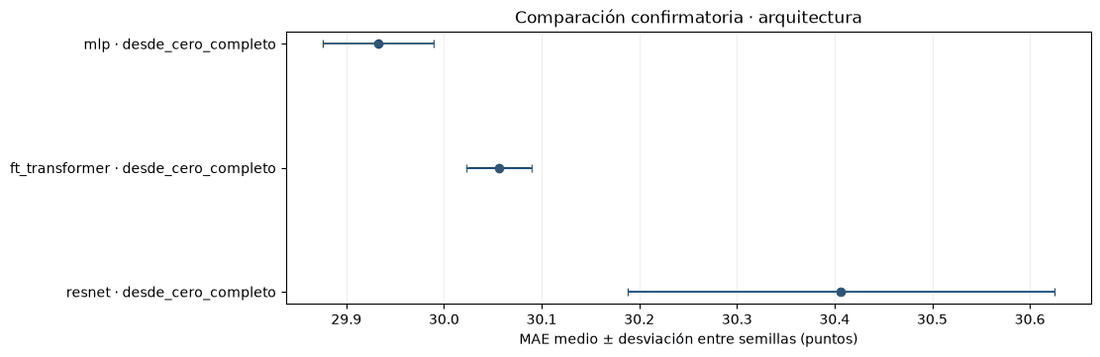

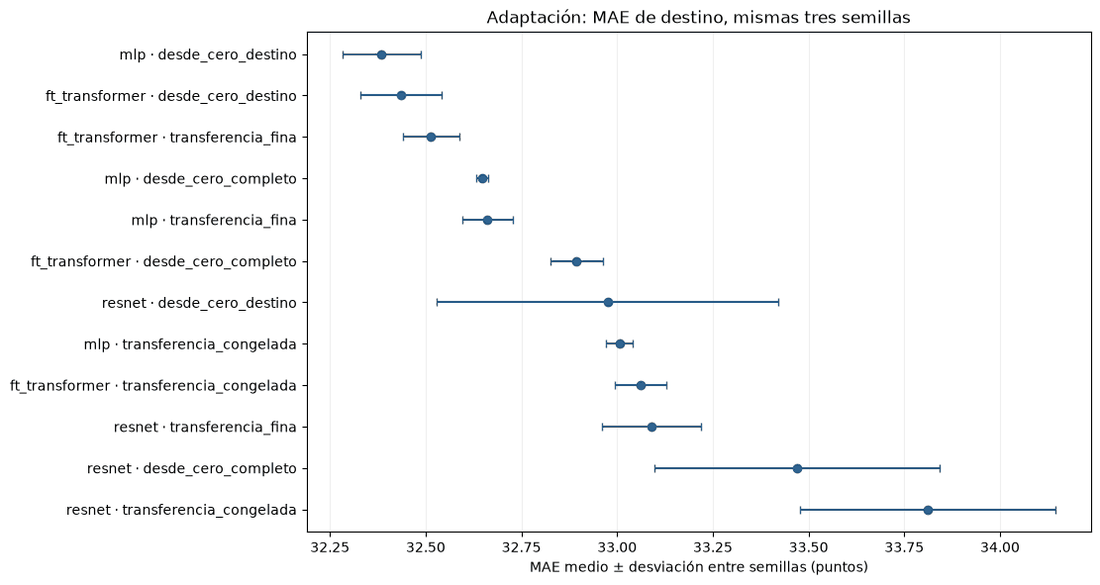

familia  seed  delta_mae_fina_menos_destino  \
0  ft_transformer    42                         -0.05   
1  ft_transformer    43                          0.14   
2  ft_transformer    44                          0.15   
3             mlp    42                          0.23   
4             mlp    43                          0.31   
5             mlp    44                          0.29   
6          resnet    42                          0.57   
7          resnet    43                         -0.39   
8          resnet    44                          0.16   

   delta_mae_fina_menos_completo  delta_mae_fina_menos_congelada  
0                          -0.47                           -0.62  
1                          -0.22                           -0.51  
2                          -0.46                           -0.51  
3                           0.09                           -0.28  
4                          -0.01                           -0.31  
5                          -0.04     

familia  delta_mae_fina_menos_destino  dispersion_delta_destino  \
0  ft_transformer                          0.08                      0.11   
1             mlp                          0.28                      0.04   
2          resnet                          0.11                      0.48   

   delta_mae_fina_menos_completo  delta_mae_fina_menos_congelada  
0                          -0.38                           -0.55  
1                           0.01                           -0.34  
2                          -0.38                           -0.72


familia              regimen       panel  PERIODO      n  \
0    ft_transformer  desde_cero_completo  adaptacion    20142  54364   
1    ft_transformer  desde_cero_completo  adaptacion    20151   2627   
2    ft_transformer  desde_cero_completo  adaptacion    20152  54215   
3    ft_transformer  desde_cero_completo  adaptacion    20161   1357   
4    ft_transformer  desde_cero_completo  adaptacion    20162  54663   
..              ...                  ...         ...      ...    ...   
205          resnet   transferencia_fina  adaptacion    20192  54909   
206          resnet   transferencia_fina  adaptacion    20201   1515   
207          resnet   transferencia_fina  adaptacion    20211   1581   
208          resnet   transferencia_fina  adaptacion    20221   2020   
209          resnet   transferencia_fina  adaptacion    20222  52935   

     mae_medio  mae_desviacion  rmse_medio  r2_medio  
0        26.61            0.17       33.93      0.38  
1        34.25            0.13       

In [53]:
resumen_semillas_global_f4 = resumir_semillas_f4(tabla_confirmacion_fase4)
fig = graficar_comparacion_f4(resumen_semillas_global_f4, "arquitectura")
fig.savefig(RUTA_FIGURAS_F4/"comparacion_arquitecturas.png", dpi=150, bbox_inches="tight")
plt.show()
tabla_destino_f4 = tabla_confirmacion_fase4.copy()
for metrica in ["mae", "rmse", "r2"]:
    tabla_destino_f4[metrica] = tabla_destino_f4[metrica+"_destino"]
resumen_semillas_destino_f4 = resumir_semillas_f4(tabla_destino_f4)
fig = graficar_comparacion_f4(resumen_semillas_destino_f4, "adaptacion",
    titulo="Adaptación: MAE de destino, mismas tres semillas")
fig.savefig(RUTA_FIGURAS_F4/"comparacion_adaptacion.png", dpi=150, bbox_inches="tight")
plt.show()
pares_transferencia_f4, resumen_transferencia_f4 = analizar_transferencia_f4(confirmacion_fase4)
display(pares_transferencia_f4)
display(resumen_transferencia_f4)
pares_transferencia_f4.to_csv(RUTA_FASE4/"transferencia_por_semilla.csv", index=False)
validacion_cohortes_f4 = metricas_validacion_cohortes_f4(motor_fase4, confirmacion_fase4)
validacion_cohortes_f4.to_csv(RUTA_FASE4/"validation_cohortes_por_semilla.csv", index=False)
resumen_cohortes_f4 = validacion_cohortes_f4.groupby(
    ["familia", "regimen", "panel", "PERIODO"], as_index=False).agg(
        n=("n", "first"), mae_medio=("mae", "mean"), mae_desviacion=("mae", "std"),
        rmse_medio=("rmse", "mean"), r2_medio=("r2", "mean"))
display(resumen_cohortes_f4)
resumen_cohortes_f4.to_csv(RUTA_FASE4/"validation_cohortes_resumen.csv", index=False)
for familia in CONFIG_MODELOS:
    runs = [r for r in confirmacion_fase4 if r["familia"] == familia and r["seed"] == 42
            and (r["panel"] == "arquitectura" or r["regimen"] == "transferencia_fina")]
    historia = pd.concat([pd.read_csv(r["historial"]) for r in runs], ignore_index=True)
    historia["ejecucion"] = historia["modelo"]
    fig = graficar_curvas_f4(historia)
    fig.suptitle(f"Entrenamiento confirmatorio · {familia} · semilla 42")
    fig.savefig(RUTA_FIGURAS_F4/f"curvas_{familia}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Comparación de arquitecturas bajo el control completo

| Familia | Parámetros | MAE global, media ± DE | RMSE global medio | R² global medio |
|---|---:|---:|---:|---:|
| MLP | 133.873 | 29,933 ± 0,057 | 37,654 | 0,431 |
| FT-Transformer | 118.529 | 30,056 ± 0,034 | 37,815 | 0,426 |
| ResNet | 268.401 | 30,407 ± 0,218 | 38,173 | 0,415 |

La MLP obtiene el menor MAE global medio en el panel de arquitecturas, con diferencias de **0,124 puntos** frente a FT-Transformer y **0,474** frente a ResNet. FT-Transformer presenta la menor dispersión entre las tres semillas; ResNet combina el mayor error medio y la mayor variación en estas ejecuciones. La mayor cantidad de parámetros de ResNet no se traduce en una mejora bajo el protocolo y la representación evaluados. Estos resultados respaldan la elección de una red densa para este conjunto tabular, sin establecer una superioridad general de la arquitectura ni una diferencia estadísticamente significativa a partir de solo tres semillas.

En este panel, las confirmaciones se detuvieron entre **7.000 y 9.000 pasos** para MLP, **6.000 y 11.000** para ResNet y **5.500 y 6.000** para FT-Transformer. Los mejores checkpoints se ubicaron entre **6.500 y 9.000**, **5.000 y 11.000**, y **4.000 y 5.500** pasos, respectivamente. La parada temprana evitó consumir automáticamente los 20.000 pasos máximos. El contador representa pasos intentados, mientras las actualizaciones efectivas pueden ser ligeramente menores por el escalado dinámico de pérdida.

Las curvas de entrenamiento se calculan con dropout activo, mientras la validación utiliza el modo de inferencia y otro conjunto de observaciones. Que el MAE registrado durante entrenamiento sea mayor que el de validación no prueba por sí solo ausencia de sobreajuste. El contraste de generalización interna se interpreta mediante las métricas calculadas después con el mismo modelo en modo de inferencia y mediante la reserva de prueba, sin utilizar esta última para seleccionar la red.

### Efecto del régimen de entrenamiento en las cohortes de destino

| Familia | Completo | Solo destino | Transferencia congelada | Ajuste fino |
|---|---:|---:|---:|---:|
| MLP | 32,647 ± 0,015 | **32,385 ± 0,102** | 33,006 ± 0,036 | 32,662 ± 0,066 |
| ResNet | 33,470 ± 0,373 | **32,975 ± 0,447** | 33,811 ± 0,333 | 33,089 ± 0,129 |
| FT-Transformer | 32,894 ± 0,069 | **32,436 ± 0,106** | 33,062 ± 0,068 | 32,514 ± 0,074 |

Los valores corresponden al MAE de validación de destino, expresado como media ± desviación estándar entre semillas. En las tres familias, entrenar solo con destino produce el menor MAE medio de ese dominio. Al comparar por semilla, el ajuste fino aumenta el MAE frente al aprendizaje exclusivo en destino en promedio **0,277 puntos para MLP**, **0,114 para ResNet** y **0,078 para FT-Transformer**. MLP presenta ese aumento en las tres semillas; ResNet y FT-Transformer presentan una mejora en una semilla y un aumento en las otras dos. No se observa una ganancia consistente de transferencia respecto de ese control ni se alcanza una reducción media de un punto.

El contraste con la extracción congelada ofrece un resultado distinto: el ajuste fino reduce el MAE de destino en **las nueve parejas familia–semilla**, con reducciones medias de **0,344 puntos en MLP**, **0,722 en ResNet** y **0,548 en FT-Transformer**. Este patrón respalda la utilidad de permitir que la representación preentrenada se adapte, frente a limitar el aprendizaje a una cabeza nueva. Sin embargo, ninguna de esas reducciones medias alcanza un punto y tampoco supera al entrenamiento directo en destino. Por tanto, adaptar el encoder mejora la transferencia congelada en las condiciones evaluadas, pero no acredita que el preentrenamiento aporte una ventaja frente a disponer de datos etiquetados suficientes en destino.

Frente al control completo, el ajuste fino reduce el MAE de destino en **0,380 puntos** tanto en ResNet como en FT-Transformer, mientras MLP cambia apenas **+0,014 puntos**. Esa comparación muestra una mejora parcial respecto de mezclar todas las cohortes, sin modificar la conclusión principal frente al control exclusivo de destino. La interpretación se limita a estos periodos, esta representación y estos presupuestos; no identifica un efecto causal del tiempo ni demuestra que la transferencia sea innecesaria en escenarios con menos etiquetas de destino.

### Diferencia entre seleccionar para toda la población y seleccionar para destino

La selección global considera las 15 variantes y utiliza el MAE global medio de validación. En ese conjunto, el menor promedio corresponde a **MLP entrenada con todo train y monitor de destino: 29,890 ± 0,017 puntos**, con RMSE medio de **37,626**. El control MLP del panel de arquitecturas obtiene **29,933 ± 0,057**. La diferencia de 0,042 puntos está dentro del margen de 0,1 definido para acudir a los criterios secundarios; el RMSE también favorece a la variante retenida. La selección del modelo global no equivale a elegir el menor error en las cohortes de destino: para ese objetivo particular, la MLP entrenada solo en destino alcanza **32,385 ± 0,102**, frente a **32,647 ± 0,015** del control completo seleccionado.

La reserva de validación incluye **281.499 observaciones de origen y 58.051 de destino**, por lo que origen representa aproximadamente el **82,9 %** de las observaciones y recibe ese peso en el MAE global. Un modelo puede mejorar ese promedio y perder desempeño relativo en destino. Esta diferencia explica por qué se mantienen ambos paneles y por qué la elección final se vincula al objetivo global previamente establecido. La separación aleatoria dentro de la población disponible evalúa generalización interna; no convierte la comparación de dominios históricos en una prueba prospectiva sobre cohortes futuras.


## **4. Optimización con Optuna y confirmación del modelo seleccionado**

Se selecciona por MAE global medio la variante más favorable entre las 15 confirmadas, con la regla de desempate fijada. Optuna utiliza únicamente validación y conserva el monitor de parada de esa variante; no modifica las particiones ni las transformaciones. La configuración previa se incluye como primer ensayo para disponer de un control con igual presupuesto de búsqueda.

El estudio, los parámetros, los ensayos completos/podados/fallidos y las métricas se conservan en SQLite y CSV. Al ejecutar nuevamente la celda se retoma el estudio y se completa el número total de ensayos establecido. La semilla del muestreador depende del número de ensayo mediante la API pública de Optuna. La configuración optimizada se confirma con 42, 43 y 44 y se contrasta con la anterior. El modelo operativo utiliza **semilla 42, fijada antes de prueba**, sin elegir la repetición de mejor resultado.

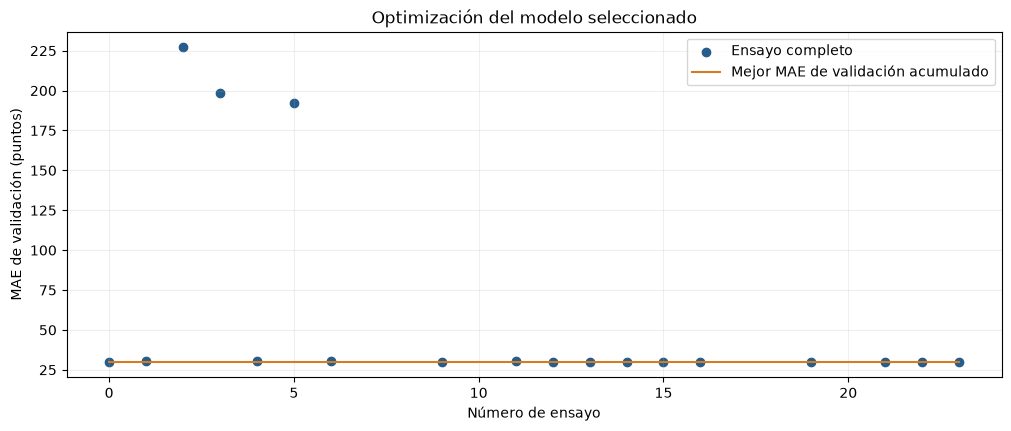

In [54]:
estudio_fase4, optimizacion_fase4 = optimizar_f4(motor_fase4, confirmacion_fase4, n_trials=24)
display(pd.json_normalize(estudio_fase4.best_trial.user_attrs["hp"]))
display(pd.DataFrame(optimizacion_fase4["comparacion_hpo"]))
display(estudio_fase4.trials_dataframe())
fig = graficar_optuna_f4(estudio_fase4.trials_dataframe())
fig.savefig(RUTA_FIGURAS_F4/"optuna.png", dpi=150, bbox_inches="tight")
plt.show()
modelo_final_f4 = optimizacion_fase4["modelo_final"]
print("Variante seleccionada:", optimizacion_fase4["variante"])
print("Configuración retenida:", optimizacion_fase4["version_seleccionada"])
print("Semilla operativa predefinida:", modelo_final_f4["seed"])
sello_seleccion_f4 = sellar_seleccion_f4(motor_fase4, optimizacion_fase4)
assert modelo_final_f4["seed"] == 42
print("Selección cerrada e íntegra; prueba habilitada únicamente para evaluación final.")

### **Interpretación de la búsqueda y decisión final**

 Los 24 ensayos produjeron 18 configuraciones completas y seis podadas, sin fallos. La poda permitió detener alternativas poco prometedoras dentro del presupuesto exploratorio. El mejor ensayo fue el 14: alcanzó un MAE global de 30,043 puntos frente a 30,210 de la configuración inicial con el mismo tope de 4.000 pasos. Mantuvo la arquitectura MLP de 256–128–64 unidades, embedding de dimensión 16 y dropout de 0,10; propuso elevar la tasa de aprendizaje de 0,001 a 0,001968 y reducir el decaimiento de 0,0001 a 0,0000300.

La confirmación con las semillas 42, 43 y 44 y el presupuesto máximo de 20.000 pasos no reprodujo esa ventaja. El MAE global medio pasó de **29,890 ± 0,017** a **29,969 ± 0,077 puntos**, y el RMSE medio de **37,626** a **37,701**. Como la diferencia de MAE es inferior a 0,1 puntos, se aplica la regla de desempate establecida: el menor RMSE favorece la configuración inicial. En consecuencia, **la búsqueda no produjo una mejora confirmada y se conserva la configuración inicial**. La menor duración media de la propuesta no modifica la decisión porque el costo se considera después del RMSE. La búsqueda sobre una sola semilla y un presupuesto corto identifica candidatos, mientras que la confirmación permite comprobar si su ventaja se mantiene; ambas etapas aportan información distinta.

El modelo final es **MLP entrenada desde cero con toda la población de entrenamiento**, con tasa 0,001, decaimiento 0,0001, dropout 0,10, embedding de dimensión 16 y capas densas de 256, 128 y 64 unidades. Pertenece al panel de adaptación y conserva el MAE de destino como monitor de parada. Se utiliza la **semilla 42 fijada antes de consultar prueba**, sin seleccionar retrospectivamente la mejor repetición ni formar un ensamble. Los resultados no respaldan afirmar que Optuna mejoró el desempeño final; sí respaldan la comparación y la retención de la configuración más favorable bajo el protocolo definido.

| Configuración confirmada | MAE global, media ± DE | RMSE global medio | MAE medio de destino |
|---|---:|---:|---:|
| Inicial, retenida | **29,890 ± 0,017** | **37,626** | **32,647** |
| Propuesta por Optuna | 29,969 ± 0,077 | 37,701 | 32,767 |

La mejora de **0,167 puntos** observada entre el ensayo inicial y el mejor ensayo corto se convierte en un **aumento de 0,079 puntos de MAE** al confirmar con el presupuesto mayor y tres semillas. Por ello, el paquete final contiene la configuración inicial retenida. Las desviaciones mostradas describen variación entre esas tres inicializaciones; no son intervalos de confianza.


### **4.1. Importancia de variables y diagnóstico de generalización interna**

La importancia por permutación utiliza una muestra fija de hasta 20.000 registros de **validación** y tres repeticiones. Cada variable conceptual se permuta completa: un bloque one-hot conserva sus categorías válidas y cada municipio se permuta como un índice. Se informa el incremento de MAE respecto de la muestra sin permutar. Las variables correlacionadas pueden compartir o enmascarar importancia; este análisis no mide efectos causales ni se usa para rehacer la selección.

La comparación de error de entrenamiento y validación se hace en modo inferencia; el error de entrenamiento se estima sobre una muestra aleatoria fija de hasta 30.000 registros. Una brecha pequeña no demuestra ausencia de sobreajuste ni representa una cota irreducible de desempeño.

variable  delta_mae_medio  desviacion_repeticiones  \
22        EDAD_PRESENTACION             2.68                     0.07   
4              COLE_JORNADA             2.26                     0.13   
8      FAMI_ESTRATOVIVIENDA             0.59                     0.04   
9       FAMI_EDUCACIONMADRE             0.55                     0.01   
15          COLE_NATURALEZA             0.53                     0.03   
23     COLE_MCPIO_UBICACION             0.50                     0.02   
10      FAMI_EDUCACIONPADRE             0.47                     0.03   
13              ESTU_GENERO             0.44                     0.03   
11        FAMI_CUARTOSHOGAR             0.29                     0.05   
24  ESTU_MCPIO_PRESENTACION             0.29                     0.01   
12       FAMI_PERSONASHOGAR             0.28                     0.06   
0           COLE_CALENDARIO             0.24                     0.02   
2      COLE_DEPTO_UBICACION             0.23                     0.02 

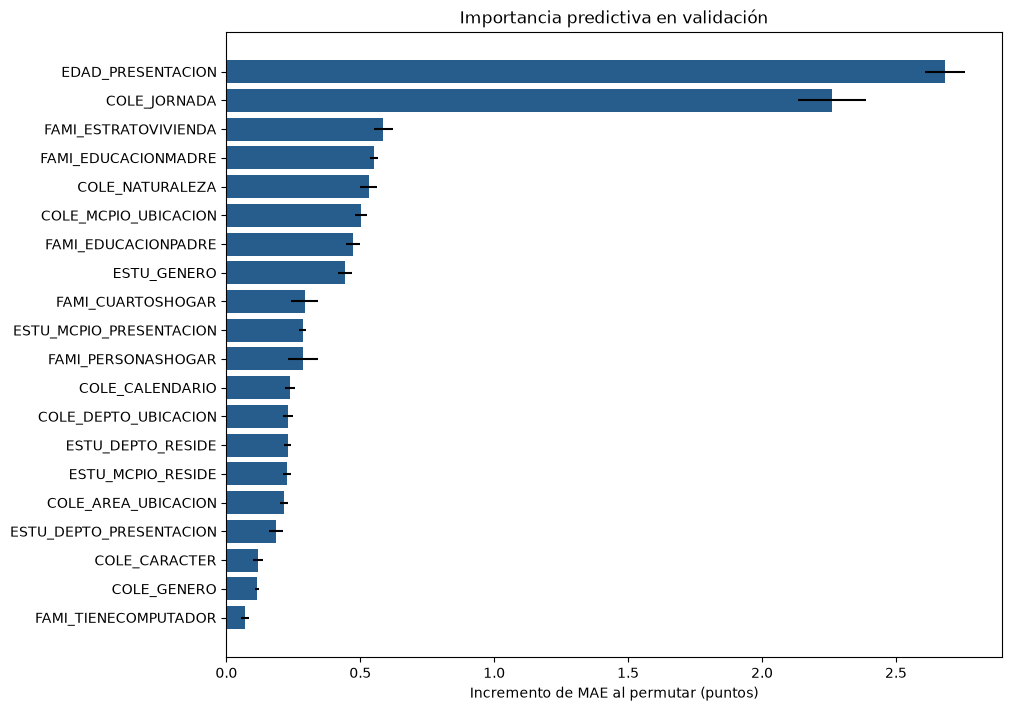

poblacion       n   mae  rmse   r2  \
0  Muestra fija de entrenamiento   30000 29.68 37.40 0.44   
1            Validación completa  339550 29.90 37.66 0.43   

   sesgo_pred_menos_real  
0                  -1.95  
1                  -1.87


In [55]:
modelo_evaluacion_f4 = cargar_modelo_f4(modelo_final_f4["checkpoint"], compile=False)
importancia_f4 = importancia_permutacion_f4(motor_fase4, modelo_evaluacion_f4)
display(importancia_f4)
importancia_f4.to_csv(RUTA_FASE4/"importancia_permutacion_validation.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
imp = importancia_f4.head(20).iloc[::-1]
ax.barh(imp.variable, imp.delta_mae_medio, xerr=imp.desviacion_repeticiones, color="#275d8c")
ax.set(xlabel="Incremento de MAE al permutar (puntos)", title="Importancia predictiva en validación")
fig.savefig(RUTA_FIGURAS_F4/"importancia_validation.png", dpi=150, bbox_inches="tight")
plt.show()
pos_train_f4 = np.sort(np.random.default_rng(42).choice(len(particiones["train"]["y"]),
    min(30000, len(particiones["train"]["y"])), replace=False))
pred_train_f4 = motor_fase4.predecir(modelo_evaluacion_f4, "train", pos_train_f4)
pred_validation_final_f4 = motor_fase4.predecir(modelo_evaluacion_f4)
display(pd.DataFrame([
    {"poblacion": "Muestra fija de entrenamiento", **metricas_f4(particiones["train"]["y"][pos_train_f4], pred_train_f4)},
    {"poblacion": "Validación completa", **metricas_f4(particiones["validation"]["y"], pred_validation_final_f4)}]))

### **Interpretación de la importancia predictiva y la brecha interna**

La edad de presentación y la jornada del colegio concentran los mayores incrementos de error al permutar una variable: **2,68 ± 0,07** y **2,26 ± 0,13 puntos de MAE**, respectivamente. Después aparecen estrato (**0,59**), educación materna (**0,55**), naturaleza del colegio (**0,53**), municipio del colegio (**0,50**) y educación paterna (**0,47**). Estos valores describen cuánto depende este modelo de cada información dentro de una muestra fija de **20.000 registros de validación**, cuyo MAE sin permutar es **30,13**. La desviación corresponde a tres permutaciones, no a un intervalo de confianza sobre la población.

La importancia conjunta del contexto institucional y familiar es coherente con el problema formulado, pero no permite atribuir un aumento de puntaje a modificar una variable. La edad puede resumir trayectorias educativas y condiciones distintas de la edad misma; las categorías de jornada o ubicación también comparten información con otras características. Por esta dependencia, una importancia individual pequeña —por ejemplo, internet: **0,05 puntos**— no demuestra que el atributo carezca de relación con el puntaje ni que una intervención sea irrelevante. Las importancias tampoco deben sumarse como si fueran contribuciones independientes.

En modo inferencia, la muestra fija de **30.000 registros de entrenamiento** presenta **MAE 29,68** y **RMSE 37,40**, frente a **29,90** y **37,66** en validación completa. La brecha aproximada de **0,22 puntos de MAE** es pequeña bajo este particionado. Es una comprobación favorable de consistencia interna, aunque combina una estimación muestral de entrenamiento con toda validación y no demuestra ausencia de sobreajuste. Tampoco cubre colegios nuevos ni aplicaciones futuras, pues la partición es aleatoria y puede compartir instituciones entre conjuntos.


## **5. Evaluación final sobre la reserva de prueba**

El sello anterior fija arquitectura, régimen, parámetros, presupuesto, checkpoint y semilla. Se comprueban sus huellas antes de inferir sobre prueba. No se reentrena con validación ni se sustituye el modelo a partir de estas métricas. Las tres semillas ya cuantificaron variabilidad durante confirmación; la evaluación siguiente corresponde al modelo operativo de semilla 42.

Se reportan MAE, RMSE y R², sesgo, percentiles del error, proporción dentro de ±10/30/50 puntos y salidas fuera del rango del examen **sin recortarlas**. Se acompaña el agregado con origen/destino, periodo, semestre, género, área, naturaleza y quintiles reales. Estos quintiles son diagnósticos posteriores, no predictores ni criterios de selección. R² en un grupo de varianza reducida requiere cautela. En particular, el destino concentra gran parte de sus registros en 2022-2.

El contraste pareado contra la mediana de entrenamiento remuestrea instituciones completas para conservar la dependencia dentro de colegio; las filas sin identificador institucional forman conglomerados individuales. El IC percentil describe incertidumbre condicionada al holdout y a los pesos fijos; no acredita desempeño en instituciones inéditas ni proporciona intervalos individuales de puntaje.

modelo particion       n   mae  rmse    r2  ...  \
0  mlp / desde_cero_completo      test  339584 29.88 37.56  0.43  ...   
1                media_train      test  339584 40.36 49.80 -0.00  ...   
2              mediana_train      test  339584 40.26 49.91 -0.00  ...   
3        media_train_destino      test  339584 40.38 49.80 -0.00  ...   
4      mediana_train_destino      test  339584 40.26 49.91 -0.00  ...   

   max_error_absoluto  porcentaje_error_hasta_10  porcentaje_error_hasta_30  \
0              225.58                      21.01                      57.87   
1              253.38                      14.89                      43.03   
2              250.00                      15.88                      44.24   
3              253.69                      14.89                      43.03   
4              250.00                      15.88                      44.24   

   porcentaje_error_hasta_50  predicciones_fuera_0_500  \
0                      82.01                      

variable            grupo       n   mae  rmse   r2  ...  \
0               dominio           origen  280915 29.30 36.87 0.43  ...   
1               dominio          destino   58669 32.67 40.68 0.43  ...   
2               PERIODO            20172   54624 30.14 37.69 0.40  ...   
3               PERIODO            20162   54557 29.42 36.86 0.39  ...   
4               PERIODO            20192   54920 31.59 39.13 0.42  ...   
5               PERIODO            20222   53455 32.62 40.55 0.39  ...   
6               PERIODO            20181    2017 31.69 39.98 0.60  ...   
7               PERIODO            20142   54335 26.42 33.60 0.39  ...   
8               PERIODO            20152   54110 28.34 36.09 0.41  ...   
9               PERIODO            20221    2047 32.00 40.22 0.58  ...   
10              PERIODO            20151    2584 33.68 42.65 0.63  ...   
11              PERIODO            20161    1249 35.48 44.92 0.35  ...   
12              PERIODO            20171    1289 31.0

variable            grupo      n   mae  rmse     r2  ...  \
0  quintil_puntaje_real   (296.0, 490.0]  67370 45.11 52.52  -3.21  ...   
1  quintil_puntaje_real   (209.0, 237.0]  68974 23.01 29.06 -11.95  ...   
2  quintil_puntaje_real  (-0.001, 209.0]  69239 35.82 42.97  -6.17  ...   
3  quintil_puntaje_real   (237.0, 263.0]  66349 20.05 25.11 -10.13  ...   
4  quintil_puntaje_real   (263.0, 296.0]  67652 25.27 31.06  -9.99  ...   

   porcentaje_error_hasta_10  porcentaje_error_hasta_30  \
0                       9.47                      32.10   
1                      27.44                      70.59   
2                      14.05                      45.57   
3                      30.93                      76.58   
4                      23.34                      64.81   

   porcentaje_error_hasta_50  predicciones_fuera_0_500  \
0                      59.45                         0   
1                      91.53                         0   
2                      74.45       

delta_mae_A_menos_B  ic95_inferior  ic95_superior       n  n_conglomerados  \
0               -10.38         -10.70         -10.06  339584            11345   

               unidad_remuestreo  filas_sin_identificador_grupo  repeticiones  \
0  COLE_COD_DANE_ESTABLECIMIENTO                             13          1000   

   semilla  pocos_conglomerados     interpretacion  \
0       42                False  A tiene menor MAE   

                                                                 alcance  
0  IC percentil condicionado al holdout interno y a los pesos fijos; ...


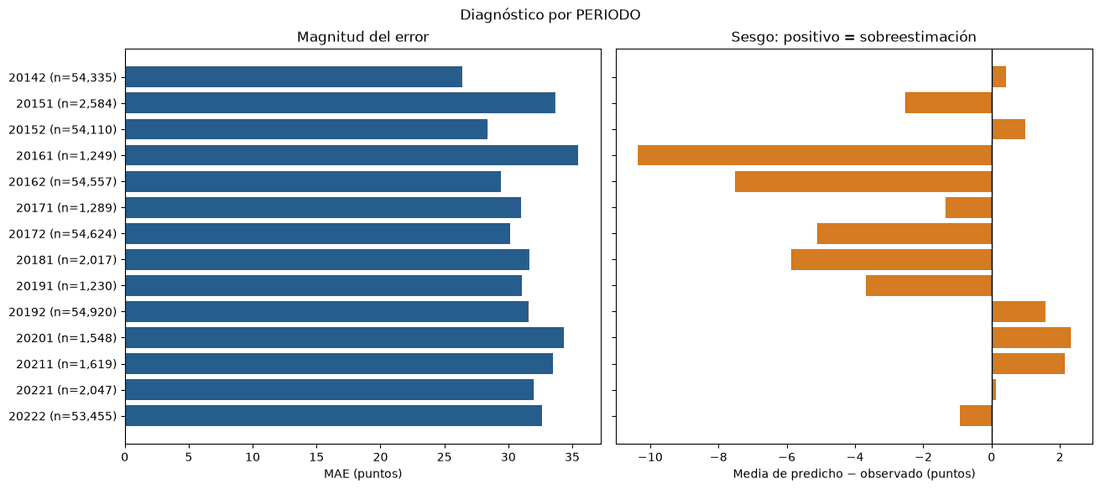

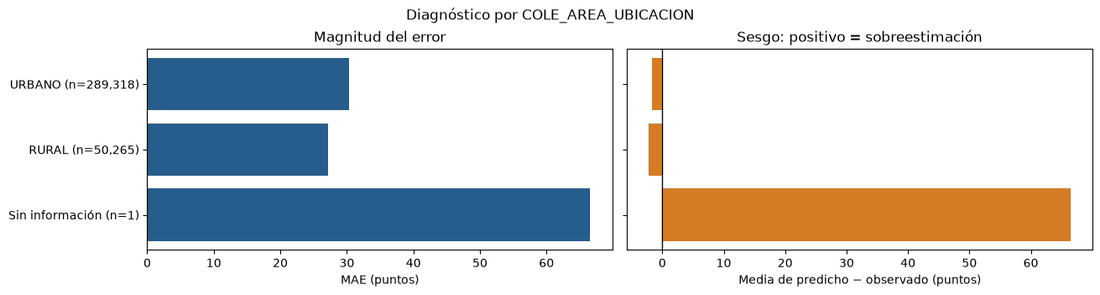

In [56]:
motor_fase4.verificar_sello(sello_seleccion_f4)
pred_test_final_f4 = motor_fase4.predecir(modelo_evaluacion_f4, "test", sello=sello_seleccion_f4)
nombre_final_f4 = modelo_final_f4["familia"]+" / "+modelo_final_f4["regimen"]
tabla_test_campeon_f4 = tabla_predicciones_f4(motor_fase4, df_limpio,
    pred_test_final_f4, nombre_final_f4, "test")
tabla_test_campeon_f4["dominio"] = np.where(tabla_test_campeon_f4.PERIODO <= 20192, "origen", "destino")
predicciones_test_f4 = pd.concat([tabla_test_campeon_f4]+[
    tabla_predicciones_f4(motor_fase4, df_limpio,
        np.full(len(particiones["test"]["y"]), valor, dtype="float32"), nombre, "test")
    for nombre, valor in referencias_constantes.items()], ignore_index=True)
metricas_test_f4 = tabla_metricas_f4(predicciones_test_f4)
grupos_test_f4 = metricas_grupos_f4(tabla_test_campeon_f4,
    ["dominio", "PERIODO", "SEMESTRE", "ESTU_GENERO", "COLE_AREA_UBICACION", "COLE_NATURALEZA"])
quintiles_test_f4 = metricas_quintiles_f4(tabla_test_campeon_f4)
display(metricas_test_f4)
display(grupos_test_f4)
display(quintiles_test_f4)
referencia_bootstrap_f4 = predicciones_test_f4[predicciones_test_f4.modelo.eq("mediana_train")]
bootstrap_final_f4 = bootstrap_pareado_mae_f4(tabla_test_campeon_f4, referencia_bootstrap_f4,
    columna_grupo="COLE_COD_DANE_ESTABLECIMIENTO", repeticiones=1000, seed=42)
display(pd.DataFrame([bootstrap_final_f4]))
predicciones_test_f4.to_parquet(RUTA_FASE4/"predicciones_test.parquet", index=False)
metricas_test_f4.to_csv(RUTA_FASE4/"metricas_test.csv", index=False)
grupos_test_f4.to_csv(RUTA_FASE4/"metricas_test_grupos.csv", index=False)
quintiles_test_f4.to_csv(RUTA_FASE4/"metricas_test_quintiles.csv", index=False)
json_seguro(RUTA_FASE4/"bootstrap_test.json", bootstrap_final_f4)
fig = graficar_residuos_f4(tabla_test_campeon_f4, nombre_final_f4)
fig.savefig(RUTA_FIGURAS_F4/"residuos_test.png", dpi=150, bbox_inches="tight")
plt.show()
for variable in ["PERIODO", "COLE_AREA_UBICACION", "ESTU_GENERO", "COLE_NATURALEZA"]:
    fig = graficar_grupos_f4(grupos_test_f4, variable)
    fig.savefig(RUTA_FIGURAS_F4/f"test_{variable}.png", dpi=150, bbox_inches="tight")
    plt.show()

### **Interpretación del desempeño en prueba**

El MLP seleccionado obtiene **MAE 29,88**, **RMSE 37,56** y **R² 0,431** en los **339.584 registros de prueba**. La mediana de entrenamiento, referencia adecuada para MAE, alcanza **40,26 puntos**: la reducción es de **10,38 puntos, equivalente al 25,79 %**. Frente a la media de entrenamiento, el RMSE disminuye de **49,80 a 37,56 puntos** (**24,58 %**). Las dos comparaciones muestran que las entradas de contexto aportan capacidad predictiva frente a una estimación constante. El R² indica una reducción del error cuadrático respecto de predecir la media observada de prueba; no expresa un porcentaje de estudiantes acertados.

El contraste pareado por instituciones produce **ΔMAE = −10,38 puntos** y un **IC percentil del 95 % [−10,70; −10,06]**. Las **1.000 réplicas** remuestrean **11.345 conglomerados**; los **13 registros sin identificador institucional** se incluyen como unidades individuales. El intervalo está completamente por debajo de cero y respalda una reducción de MAE frente a la mediana dentro de esta reserva. Su alcance está condicionado a los pesos ya fijados y al holdout disponible: no incorpora el proceso de volver a entrenar la red ni transforma la prueba en una evaluación de instituciones inéditas.

El desempeño medio debe acompañarse de su distribución. El **57,87 %** de las predicciones queda a una distancia máxima de **30 puntos**, y el **82,01 %**, de **50 puntos**; por tanto, alrededor del **17,99 %** supera este último margen. El percentil 95 del error absoluto es **73,61 puntos** y el máximo alcanza **225,58**. Aunque las **339.584 salidas** permanecen dentro de 0–500 sin recortarse, el rango válido no garantiza precisión individual. El sesgo predicho menos observado es **−1,78 puntos**: una subestimación media pequeña puede coexistir con errores amplios de signo opuesto.

### **Heterogeneidad por dominio y contexto**

| Grupo de prueba | Registros | MAE | Sesgo predicho − observado |
|---|---:|---:|---:|
| Origen | 280.915 | 29,30 | −2,00 |
| Destino | 58.669 | 32,67 | −0,72 |
| Género femenino | 184.792 | 28,52 | −1,51 |
| Género masculino | 154.486 | 31,50 | −2,10 |
| Colegio rural | 50.265 | 27,14 | −2,28 |
| Colegio urbano | 289.318 | 30,35 | −1,69 |
| Colegio oficial | 246.022 | 29,08 | −1,93 |
| Colegio no oficial | 93.561 | 31,98 | −1,40 |

El destino presenta **3,37 puntos más de MAE** que el origen. Esta diferencia confirma la conveniencia de informar ambos dominios, pero no constituye una evaluación prospectiva: ambos están representados en el entrenamiento completo. Además, **53.455 de los 58.669 registros de destino (91,11 %)** corresponden a 2022-2, por lo que el promedio está dominado por esa cohorte. En las cohortes de prueba, el MAE va de **26,42 en 2014-2** a **35,48 en 2016-1**; los soportes distintos deben acompañar esa lectura. El semestre 1 obtiene **32,86**, frente a **29,75** en semestre 2, y reúne solo **13.583 registros**.

El menor MAE rural u oficial describe errores absolutos menores en esos subconjuntos, no ausencia de desigualdad educativa ni una garantía de equidad del modelo. Género, área y naturaleza contienen poblaciones y distribuciones de puntaje diferentes; las métricas no aíslan el efecto de pertenecer a un grupo. Las categorías de área y naturaleza sin información tienen **un solo registro**, por lo que su error de **66,55 puntos** se conserva como evidencia de soporte insuficiente y no se generaliza. Para género sin información el soporte es **306**; tampoco debe tener el mismo peso interpretativo que los grupos mayoritarios.

### **Errores en los extremos del puntaje**

| Quintil del puntaje observado | Registros | MAE | Sesgo predicho − observado |
|---|---:|---:|---:|
| 0–209 | 69.239 | 35,82 | +34,89 |
| >209–237 | 68.974 | 23,01 | +15,23 |
| >237–263 | 66.349 | 20,05 | −0,07 |
| >263–296 | 67.652 | 25,27 | −17,05 |
| >296–490 | 67.370 | 45,11 | −43,23 |

El modelo aproxima mejor los puntajes centrales y muestra un patrón de acercamiento al centro: **sobreestima los resultados bajos y subestima los altos**. El quintil superior acumula el mayor MAE y una subestimación media de **43,23 puntos**; en el inferior, la sobreestimación media es de **34,89**. Este patrón explica por qué el sesgo global relativamente pequeño no basta para describir la calidad del modelo y limita su uso para identificar con precisión casos extremos. Los quintiles se forman con el resultado observado después de inferir: sirven para diagnóstico, no pueden utilizarse como una variable disponible antes del examen. Sus R² negativos se interpretan junto con el estrechamiento de la varianza del objetivo dentro de cada intervalo y no sustituyen el R² global.


## **6. Persistencia y aplicación con contexto sin puntajes**

El paquete conserva el modelo `.keras`, los parámetros de preparación, una tarjeta de uso y un manifiesto SHA-256. La recarga utiliza las clases registradas en fase 3 y no vuelve a ajustar ninguna transformación. Se verifican las entradas reconstruidas contra las matrices preparadas y las predicciones antes/después de guardar. Los códigos municipales desconocidos se asignan a OOV 0.

El ejemplo toma cinco registros de prueba fijados por su posición y retira el puntaje global y los resultados de áreas antes de construir la entrada. La edad se deriva nuevamente de fecha y periodo con la regla documentada. El valor observado se añade a la tabla solo después de inferir para ilustrar el error. El paquete estima puntajes y no reemplaza el examen ni autoriza decisiones individuales de admisión.

In [ ]:
paquete_final_f4 = preparar_paquete_f4(motor_fase4, optimizacion_fase4, sello_seleccion_f4)
modelo_recargado_f4, estado_recargado_f4 = cargar_paquete_f4(paquete_final_f4)
pos_ejemplo_f4 = np.arange(5, dtype="int32")
indices_ejemplo_f4 = particiones["test"]["indices"][pos_ejemplo_f4]
contexto_ejemplo_f4 = df_limpio.iloc[indices_ejemplo_f4].drop(
    columns=[TARGET, *LEAKAGE_COLS, "EDAD_PRESENTACION", "SEMESTRE"], errors="ignore").copy()
entradas_ejemplo_f4 = transformar_contexto_f4(contexto_ejemplo_f4, estado_recargado_f4)
assert np.array_equal(entradas_ejemplo_f4["numericas"], particiones["test"]["X_num"][pos_ejemplo_f4])
assert np.array_equal(entradas_ejemplo_f4["municipios"], particiones["test"]["X_cat"][pos_ejemplo_f4])
pred_antes_f4 = np.asarray(modelo_evaluacion_f4(entradas_ejemplo_f4, training=False)).ravel()
pred_despues_f4 = np.asarray(modelo_recargado_f4(entradas_ejemplo_f4, training=False)).ravel()
assert np.allclose(pred_antes_f4, pred_despues_f4, rtol=0, atol=1e-5)
ejemplo_aplicacion_f4 = aplicar_paquete_f4(paquete_final_f4, contexto_ejemplo_f4)
ejemplo_aplicacion_f4["puntaje_observado"] = particiones["test"]["y"][pos_ejemplo_f4]
ejemplo_aplicacion_f4["error_absoluto"] = abs(ejemplo_aplicacion_f4.puntaje_estimado-ejemplo_aplicacion_f4.puntaje_observado)
display(ejemplo_aplicacion_f4.reset_index(drop=True))
ejemplo_aplicacion_f4.reset_index(drop=True).to_csv(RUTA_FASE4/"ejemplo_aplicacion.csv", index=False)
print("Preparación, integridad del paquete y predicciones tras recarga: verificadas.")

### **Interpretación de la aplicación del modelo persistido**

La ejecución verifica que la transformación reconstruida coincide con las matrices preparadas y que las predicciones del modelo recargado coinciden con las del modelo anterior al guardado, dentro de la tolerancia fijada (**10⁻⁵ puntos**). La comprobación valida el flujo de persistencia y aplicación con el preprocesamiento aprendido; las cinco observaciones ilustrativas se fijaron por posición, sin escoger casos de menor error.

Los resultados muestran tanto aciertos aproximados como limitaciones: para un puntaje observado de **206**, se estiman **214,40** (**8,40 puntos** de error); para **350**, se estiman **269,24** (**80,76 puntos** de error), y para **190**, **264,50** (**74,50 puntos** de error). La amplitud de estos errores es compatible con el diagnóstico de los extremos. Esta demostración acredita que el paquete puede aplicarse a información de contexto sin incluir los puntajes como entrada; cinco casos no constituyen otra evaluación de desempeño. El modelo es un resultado académico para explorar asociaciones y apoyar análisis agregados, con los límites de precisión y cobertura documentados.


### **6.1. Recursos y trazabilidad de la ejecución**

El entrenamiento se ejecutó en **Linux con NVIDIA L4**, Python 3.11.17, TensorFlow 2.21.0, Keras 3.15.1 y Optuna 4.9.0. El entorno reportó **16 CPU lógicas**. Se mantuvo el lote de 512, una ejecución a la vez y la alimentación de minilotes con `tf.data`. La precisión inicial fue mixta; las cuatro recuperaciones de ResNet se documentan en la sección 3. La MLP retenida no necesitó recuperación numérica.

El inventario de **153 etapas** conserva **644.000 pasos intentados**, **642.839 actualizaciones efectivas** y **2,726 horas acumuladas**. Los orígenes compartidos se cuentan una sola vez. Las seis etapas sin marca de terminación corresponden a ensayos podados por Optuna: su costo se conserva y no representan trabajo pendiente de la entrega. La diferencia entre pasos y actualizaciones efectivas se registra porque el escalado de pérdida puede omitir actualizaciones con gradientes no finitos.

Las 2,726 horas corresponden al tiempo guardado de entrenamiento y validación por etapa. No equivalen a la duración total de la sesión ni a horas facturadas: el inventario no incluye necesariamente los bloques fallidos descartados, las esperas o las operaciones externas a esas etapas. El máximo RSS registrado del proceso fue **13.259,94 MiB**, aproximadamente **12,95 GiB**. El pico informado por el asignador de TensorFlow para GPU fue **443,86 MiB**; esa cifra no representa toda la memoria ocupada en el dispositivo.

El sello fija la variante, configuración y semilla antes de evaluar prueba. Las huellas de los registros de comparación y optimización coinciden con las declaradas en el sello, y el manifiesto del paquete identifica el checkpoint final. La ejecución registrada verifica la integridad y la equivalencia de las predicciones tras recarga. Las tablas, configuraciones e historiales permiten reconstruir las decisiones de selección; la matriz siguiente reúne las comprobaciones del proyecto.


## **7. Conclusiones generales y cumplimiento de objetivos**

El cierre siguiente se calcula a partir de las métricas obtenidas en esta ejecución. Distingue el aporte de las redes frente a referencias, la transferencia frente a sus controles y el efecto de Optuna tras confirmación. La matriz de cumplimiento exige evidencia computada, sin marcar como logrado un objetivo por haber definido únicamente su código.

**Límites de interpretación:** el holdout es interno y aleatorio, las instituciones pueden repetirse entre particiones y el preprocesamiento conoce los predictores de todo entrenamiento. Las cohortes no cubren todos los periodos, el soporte de destino es desigual y los atributos describen contexto, no mecanismos causales del aprendizaje. El error agregado no acredita precisión uniforme por grupo ni convierte una estimación en un resultado oficial del examen.
La numeración 1–5 de la matriz corresponde a los **cinco objetivos específicos del proyecto**, definidos en la fase 1. Su cumplimiento se organiza en las cuatro fases de entrega; la evaluación y la aplicación se completan en la fase 4.


In [58]:
from IPython.display import Markdown
comparacion_hpo_f4 = pd.DataFrame(optimizacion_fase4["comparacion_hpo"]).set_index("version")
texto_conclusiones_f4 = conclusiones_f4(predicciones_test_f4, nombre_final_f4,
    comparacion_validation=resumen_confirmacion_fase4,
    resumen_transferencia=resumen_transferencia_f4,
    optimizacion={"mae_antes": comparacion_hpo_f4.loc["configuracion_inicial", "mae"],
                  "mae_despues": comparacion_hpo_f4.loc["optuna", "mae"]},
    bootstrap=bootstrap_final_f4)
display(Markdown(texto_conclusiones_f4))
evidencias_cierre_f4 = {
    "fuente_carga_verificada": auditoria["rows"] == 7109704 and auditoria["columns_count"] == 51
        and auditoria["source_unchanged_during_audit"],
    "preparacion_verificada": bool(auditoria_preprocesamiento["filas_disjuntas_y_cobertura_completa"]
        and auditoria_preprocesamiento["scaler_solo_train"] and auditoria_preprocesamiento["vocabularios_solo_train"]),
    "transferencia_verificada": all(r["etapas"][-1]["encoder_cambio"]
        for r in confirmacion_fase4 if r["regimen"] == "transferencia_fina")
        and all(not r["etapas"][1]["encoder_cambio"] for r in confirmacion_fase4
                if r["regimen"].startswith("transferencia")),
    "comparacion_completa": len(confirmacion_fase4) == 45 and resumen_confirmacion_fase4.semillas.eq(3).all(),
    "optuna_confirmado": len(optimizacion_fase4["confirmacion"]) == 3 and sum(
        t.state in {optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED}
        for t in estudio_fase4.trials) >= 24,
    "test_evaluado_tras_cierre": motor_fase4.verificar_sello(sello_seleccion_f4) is not None
        and len(tabla_test_campeon_f4) == len(particiones["test"]["y"]),
    "persistencia_y_ejemplo_verificados": bool(np.allclose(pred_antes_f4, pred_despues_f4, rtol=0, atol=1e-5)),
}
matriz_cierre_f4 = matriz_objetivos_f4(evidencias_cierre_f4)
display(matriz_cierre_f4)
assert matriz_cierre_f4.verificado.all()
costos_fase4 = inventariar_costos_f4(motor_fase4)
display(costos_fase4)
print("Costo físico registrado (horas):", round(costos_fase4.segundos.sum()/3600, 3))
print("Pasos intentados / actualizaciones efectivas:", int(costos_fase4.pasos_intentados.sum()),
      "/", int(costos_fase4.actualizaciones.sum()))
costos_fase4.to_csv(RUTA_FASE4/"costos_etapas.csv", index=False)
matriz_cierre_f4.to_csv(RUTA_FASE4/"cumplimiento_objetivos.csv", index=False)
(RUTA_FASE4/"conclusiones.md").write_text(texto_conclusiones_f4, encoding="utf-8")
json_seguro(RUTA_FASE4/"cierre.json", {"evidencias": {k: bool(v) for k, v in evidencias_cierre_f4.items()},
    "modelo_final": nombre_final_f4, "ejecucion": modelo_final_f4["ejecucion"],
    "seleccion_sha256": motor_fase4.verificar_sello(sello_seleccion_f4)["seleccion_sha256"],
    "metricas_test_archivo": "metricas_test.csv", "objetivos_cumplidos": bool(matriz_cierre_f4.verificado.all())})
# Paquetes de inferencia, respaldo completo y reportes compactos para revisión.
shutil.make_archive(str(ROOT/"modelo_saber11_final"), "zip", RUTA_FASE4, "modelo_final")
shutil.make_archive(str(ROOT/"resultados_saber11_fase4"), "zip", RUTA_FASE4)
from zipfile import ZipFile, ZIP_DEFLATED
with ZipFile(ROOT/"resumen_saber11_fase4.zip", "w", compression=ZIP_DEFLATED) as resumen_zip_f4:
    for ruta in sorted(RUTA_FASE4.rglob("*")):
        if ruta.is_file() and ruta.suffix in {".csv", ".json", ".md", ".png"}:
            resumen_zip_f4.write(ruta, ruta.relative_to(RUTA_FASE4))
print("Paquetes generados en", ROOT)
print("modelo_saber11_final.zip · resultados_saber11_fase4.zip · resumen_saber11_fase4.zip")

El modelo **mlp / desde_cero_completo**, fijado mediante validación antes de abrir prueba, obtuvo **MAE de 29.88 puntos**, **RMSE de 37.56** y **R² de 0.431** en **339,584 registros de prueba**. Estas métricas describen generalización interna bajo el holdout aleatorio del proyecto; no acreditan predicción prospectiva ni desempeño en instituciones completamente nuevas.

Frente a la referencia **media_train** (MAE 40.36), el modelo reduce el error absoluto medio en **10.48 puntos**. La referencia se ajustó solo con entrenamiento.

Frente a la referencia **mediana_train** (MAE 40.26), el modelo reduce el error absoluto medio en **10.38 puntos**. La referencia se ajustó solo con entrenamiento.

Frente a la referencia **media_train_destino** (MAE 40.38), el modelo reduce el error absoluto medio en **10.50 puntos**. La referencia se ajustó solo con entrenamiento.

Frente a la referencia **mediana_train_destino** (MAE 40.26), el modelo reduce el error absoluto medio en **10.38 puntos**. La referencia se ajustó solo con entrenamiento.

El 21.0 % de las predicciones se desvía hasta 10 puntos del observado; el 57.9 %, hasta 30, y el 82.0 %, hasta 50. El percentil 95 del error absoluto es **73.61 puntos**. Estas frecuencias son descriptivas y no constituyen intervalos individuales de predicción.

El sesgo medio **predicho − observado** es **-1.78 puntos** (subestimación promedio). Un sesgo agregado próximo a cero puede coexistir con errores importantes en individuos o subgrupos; por ello se examinan residuales, cohortes, quintiles del puntaje y grupos de contexto. Se registran **0 salidas fuera de 0–500**; las métricas conservan esas salidas sin recorte.

La comparación incluye **3 familias** (ft_transformer, mlp, resnet). Los paneles conservan sus métricas global y de destino; la elección final utiliza el MAE global medio de las 15 variantes, con RMSE y costo como criterios secundarios. La dispersión entre semillas acompaña los promedios; una diferencia pequeña no establece por sí sola superioridad estadística.

En **ft_transformer**, el ajuste fino aumenta el MAE de destino en **0.08 puntos** frente a aprender solo en destino. La comparación no respalda una ganancia de transferencia. Respecto del control con todo train, el ΔMAE es **-0.38 puntos**. La conclusión se limita a cohortes y representación disponibles; no se atribuye causalmente al periodo histórico.

En **mlp**, el ajuste fino aumenta el MAE de destino en **0.28 puntos** frente a aprender solo en destino. La comparación no respalda una ganancia de transferencia. Respecto del control con todo train, el ΔMAE es **+0.01 puntos**. La conclusión se limita a cohortes y representación disponibles; no se atribuye causalmente al periodo histórico.

En **resnet**, el ajuste fino aumenta el MAE de destino en **0.11 puntos** frente a aprender solo en destino. La comparación no respalda una ganancia de transferencia. Respecto del control con todo train, el ΔMAE es **-0.38 puntos**. La conclusión se limita a cohortes y representación disponibles; no se atribuye causalmente al periodo histórico.

La confirmación comparable posterior a Optuna cambia el MAE de validación de **29.89** a **29.97 puntos** (-0.08 puntos de reducción). La búsqueda no aporta una reducción confirmada del MAE medio. La configuración retenida se determina con la regla previa de selección, dispersión y costo; la búsqueda y su confirmación no consultaron prueba.

El contraste pareado registra **ΔMAE A−B=-10.38**, con IC percentil 95 % **[-10.70, -10.06]** al remuestrear **11,345 unidades** (COLE_COD_DANE_ESTABLECIMIENTO). A tiene menor MAE. El intervalo condiciona los pesos del modelo y el holdout, y no sustituye la variabilidad entre semillas.

El proyecto permite estimar asociaciones predictivas entre contexto y puntaje, conservar la trazabilidad de datos y transformaciones, comparar redes y separar preentrenamiento, extracción congelada y ajuste fino. Sus resultados apoyan análisis agregados y exploración académica; el error individual y las brechas observadas deben acompañar cualquier interpretación. Los atributos disponibles no miden directamente motivación, prácticas docentes ni trayectoria de aprendizaje, por lo que no se concluye que su ausencia explique de manera causal el error residual.


objetivo  verificado  \
0  1. Contexto, fuente y carga íntegra        True   
1         2. Comprensión y preparación        True   
2     3. Arquitecturas y transferencia        True   
3         4. Entrenamiento comparativo        True   
4      4. Selección de hiperparámetros        True   
5   5. Evaluación y estudio de errores        True   
6     5. Reproducibilidad y aplicación        True   

                                                               evidencia  
0  Fase 1: fuente identificada, dimensiones y huellas de integridad c...  
1  Fase 2: auditoría de faltantes, duplicados y extremos; transformac...  
2  Fases 3–4: codificadores separados, pesos aprendidos en origen, co...  
3  Fase 4: tres familias, cuatro regímenes, referencias constantes y ...  
4  Fase 4: búsqueda Optuna del mejor modelo por validación y confirma...  
5  Fase 4: MAE, RMSE, R², residuales, cohortes y grupos de la reserva...  
6  Fase 4: modelo y preparación persistidos, predicciones tras recarg...

### **Respuesta a la pregunta del proyecto y conclusiones finales**

La información socioeconómica, familiar, institucional y geográfica permite mejorar la estimación del puntaje frente a una referencia constante dentro de la población analizada. La MLP retenida obtiene **29,88 puntos de MAE** y **37,56 de RMSE**, con **R² de 0,431**. Frente a la mediana de entrenamiento, la reducción de MAE es de **10,38 puntos (25,79 %)**. Este resultado acredita capacidad predictiva interna; no determina causalmente el desempeño ni demuestra precisión suficiente para tomar decisiones individuales.

La pregunta sobre reutilizar representaciones tiene una respuesta acotada por la comparación: **el preentrenamiento seguido de ajuste fino no aporta una reducción media frente a entrenar solo con destino** en ninguna de las tres familias. Sí reduce el MAE frente a congelar el codificador en las nueve parejas familia–semilla, lo que muestra el valor de adaptar la representación dentro del esquema de transferencia evaluado. La hipótesis de una mejora adicional por transferencia no queda respaldada frente al control más pertinente. Haber implementado y contrastado ese mecanismo permite resolver el objetivo experimental aunque la mejor alternativa final se haya entrenado desde cero.

La selección final responde al **error global de validación**, donde origen reúne aproximadamente el 82,9 % de los registros. Por eso se conserva la MLP con todo entrenamiento y monitor de destino, aunque la MLP ajustada solo en destino presenta menor error medio en ese dominio. Los dos paneles hacen visible esa diferencia de objetivos y evitan confundir la mejor solución global con la mejor solución para un subconjunto.

La búsqueda Optuna produjo una propuesta favorable con presupuesto exploratorio corto, pero su confirmación aumentó el MAE global medio de **29,890 a 29,969 puntos**. Se conservó la configuración inicial, con capas de **256–128–64 unidades**, embeddings de dimensión **16**, dropout **0,10**, tasa **0,001** y decaimiento **0,0001**. La semilla operativa **42** estaba fijada antes de abrir prueba. El proceso de optimización aportó evidencia para decidir qué configuración conservar; no produjo una mejora confirmada del modelo final.

El error no es uniforme. En prueba, destino presenta un **MAE de 32,67 puntos**, frente a **29,30** en origen; además, 2022-2 concentra el **91,11 %** del destino. La sobreestimación de puntajes bajos y la subestimación de altos alcanzan sesgos medios de **+34,89 y −43,23 puntos** en los quintiles extremos. Estas diferencias, junto con el percentil 95 del error absoluto de **73,61 puntos**, limitan una interpretación centrada únicamente en el promedio global. Las variables de mayor importancia por permutación fueron edad y jornada; su utilidad predictiva no identifica efectos de una intervención sobre ellas.

Los cinco objetivos quedan sustentados por la fuente y carga verificadas; la preparación documentada y ajustada solo en entrenamiento; el diseño de las tres familias y sus mecanismos de transferencia; la comparación con referencias y la selección de hiperparámetros; y la evaluación reservada, el análisis de errores y la aplicación del modelo persistido. La conservación de extremos válidos, el tratamiento de duplicados y faltantes y la exclusión de resultados del examen de las entradas se mantienen hasta la evaluación final.

El alcance corresponde a un **holdout interno aleatorio**. No se midió desempeño en cohortes futuras completas o colegios totalmente inéditos; el preprocesamiento utiliza los predictores de todo entrenamiento y la adaptación no representa un escenario estrictamente prospectivo. Las cuatro recuperaciones numéricas de ResNet también impiden atribuir diferencias pequeñas exclusivamente a la arquitectura bajo precisión uniforme. Una evaluación temporal o por instituciones separadas sería una extensión del estudio, necesaria para fundamentar esos usos adicionales. El producto entregado permite reproducir el análisis y aplicar el modelo a contexto compatible, con las restricciones de cobertura y precisión individual aquí documentadas.


## **Bibliografía**

- Agresti, A. (2010). *Analysis of ordinal categorical data* (2nd ed.). Wiley. https://doi.org/10.1002/9780470594001

- Aguinis, H., Gottfredson, R. K., & Joo, H. (2013). Best-practice recommendations for defining, identifying, and handling outliers. *Organizational Research Methods, 16*(2), 270–301. https://doi.org/10.1177/1094428112470848

- Bedard, K., & Dhuey, E. (2006). The persistence of early childhood maturity: International evidence of long-run age effects. *The Quarterly Journal of Economics, 121*(4), 1437–1472. https://doi.org/10.1093/qje/121.4.1437

- Cerquera Losada, O. H., Cano Barrera, J. R., & Gómez Segura, C. F. (2016). Factores asociados al logro académico en regiones desarrolladas y en desarrollo de Colombia: Una aproximación a partir de un modelo de combinación de corte transversal. *Revista Historia de la Educación Colombiana, 19*(19), 167–201. https://doi.org/10.22267/rhec.161919.19

- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS. https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf

- Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

- GitHub. (s. f.). *About large files on GitHub*. Recuperado el 14 de octubre de 2026, de https://docs.github.com/en/repositories/working-with-files/managing-large-files/about-large-files-on-github

- GitHub. (s. f.). *About releases*. Recuperado el 14 de octubre de 2026, de https://docs.github.com/en/repositories/releasing-projects-on-github/about-releases

- Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research, 3*, 1157–1182.

- Hancock, J. T., & Khoshgoftaar, T. M. (2020). Survey on categorical data for neural networks. *Journal of Big Data, 7*(1), 28. https://doi.org/10.1186/s40537-020-00305-w

- Huang, X., Khetan, A., Cvitkovic, M., & Karnin, Z. (2020). *TabTransformer: Tabular data modeling using contextual embeddings* [Prepublicación]. arXiv. https://doi.org/10.48550/arXiv.2012.06678

- Instituto Colombiano para la Evaluación de la Educación. (2014). *Resolución 503 de 2014*. https://normograma.icfes.gov.co/compilacion/docs/resolucion_icfes_0503_2014.htm

- Instituto Colombiano para la Evaluación de la Educación. (2020a). *Resolución 268 de 2020*. https://normograma.icfes.gov.co/compilacion/docs/resolucion_icfes_0268_2020.htm

- Instituto Colombiano para la Evaluación de la Educación. (2020b). *Resolución 507 de 2020*. https://normograma.icfes.gov.co/compilacion/docs/resolucion_icfes_0507_2020.htm

- Instituto Colombiano para la Evaluación de la Educación. (s. f.). *Informe de gestión 2021*. https://www.icfes.gov.co/wp-content/uploads/2024/12/Informe-de-Gestion-2021-1.pdf

- Instituto Colombiano para la Evaluación de la Educación. (2026). *Guía de orientación Saber 11.º 2026-2*. https://www.icfes.gov.co/wp-content/uploads/2026/03/17-marzo-guia-de-orientacion-saber-11-2026-2.pdf

- Instituto Colombiano para la Evaluación de la Educación. (s. f.). *Resultados únicos Saber 11* [Conjunto de datos]. Datos Abiertos de Colombia. Recuperado el 14 de octubre de 2026, de https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/about_data

- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579

- Keras. (s. f.). *Embedding layer*. Recuperado el 19 de octubre de 2026, de https://keras.io/api/layers/core_layers/embedding/

- Kim, M. J., Grinsztajn, L., & Varoquaux, G. (2024). CARTE: Pretraining and transfer for tabular learning. En R. Salakhutdinov, Z. Kolter, K. Heller, A. Weller, N. Oliver, J. Scarlett, & F. Berkenkamp (Eds.), *Proceedings of the 41st International Conference on Machine Learning* (Vol. 235, pp. 23843–23866). PMLR. https://proceedings.mlr.press/v235/kim24d.html

- Levin, R., Cherepanova, V., Schwarzschild, A., Bansal, A., Bruss, C. B., Goldstein, T., Wilson, A. G., & Goldblum, M. (2023). *Transfer learning with deep tabular models*. International Conference on Learning Representations. https://arxiv.org/abs/2206.15306

- Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley.

- Mosquera-Mosquera, J. C., Artamónova, I., & Mosquera-Artamonov, J. D. (2024). Desigualdad en el sistema educativo colombiano durante la pandemia de covid-19 vista desde análisis de la prueba Saber 11. *Revista Educación en Ingeniería, 19*(38), 1–11. https://doi.org/10.26507/rei.v19n38.1309

- Organisation for Economic Co-operation and Development. (2019). *Resultados PISA 2018: Colombia*. https://www.oecd.org/content/dam/oecd/en/about/programmes/edu/pisa/publications/national-reports/pisa-2018/featured-country-specific-overviews/PISA2018_CN_COL_ESP.pdf

- Rahm, E., & Do, H. H. (2000). Data cleaning: Problems and current approaches. *IEEE Data Engineering Bulletin, 23*(4), 3–13.

- Rodríguez Rosero, D. D., Ordoñez Ortega, R. E., & Hidalgo-Villota, M. E. (2021). Determinantes del rendimiento académico de la educación media en el departamento de Nariño, Colombia. *Lecturas de Economía*, (94), 87–126. https://doi.org/10.17533/udea.le.n94a341834

- Romero, C., & Ventura, S. (2020). Educational data mining and learning analytics: An updated survey. *WIREs Data Mining and Knowledge Discovery, 10*(3), e1355. https://doi.org/10.1002/widm.1355

- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581

- scikit-learn developers. (s. f.). *Common pitfalls and recommended practices*. Recuperado el 19 de octubre de 2026, de https://scikit-learn.org/stable/common_pitfalls.html

- scikit-learn developers. (s. f.). *StandardScaler*. Recuperado el 19 de octubre de 2026, de https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

- Sirin, S. R. (2005). Socioeconomic status and academic achievement: A meta-analytic review. *Review of Educational Research, 75*(3), 417–453. https://doi.org/10.3102/00346543075003417

- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.

- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

- Wang, Z., Dai, Z., Póczos, B., & Carbonell, J. (2019). Characterizing and avoiding negative transfer. En *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition* (pp. 11293–11302). https://openaccess.thecvf.com/content_CVPR_2019/html/Wang_Characterizing_and_Avoiding_Negative_Transfer_CVPR_2019_paper.html

- SciPy developers. (s. f.). *ttest_ind_from_stats*. Recuperado el 19 de octubre de 2026, de https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind_from_stats.html

- Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*. https://arxiv.org/abs/2106.11959

- Keras. (s. f.). *Transfer learning & fine-tuning*. Recuperado el 26 de octubre de 2026, de https://keras.io/guides/transfer_learning/

- Keras. (s. f.). *Python & NumPy utilities: PyDataset*. Recuperado el 26 de octubre de 2026, de https://keras.io/api/utils/python_utils/#pydataset-class

- Keras. (s. f.). *Whole model saving & loading*. Recuperado el 26 de octubre de 2026, de https://keras.io/api/models/model_saving_apis/model_saving_and_loading/

- Piech, C., Bassen, J., Huang, J., Ganguli, S., Sahami, M., Guibas, L. J., & Sohl-Dickstein, J. (2015). Deep knowledge tracing. *Advances in Neural Information Processing Systems, 28*. https://proceedings.neurips.cc/paper_files/paper/2015/hash/bac9162b47c56fc8a4d2a519803d51b3-Abstract.html

- Prior Labs. (s. f.). *Model versions*. Recuperado el 26 de octubre de 2026, de https://docs.priorlabs.ai/models

- Prior Labs. (s. f.). *Accessing model weights*. Recuperado el 26 de octubre de 2026, de https://docs.priorlabs.ai/models/accessing-model-weights

- Prior Labs. (s. f.). *Fine-tuning*. Recuperado el 26 de octubre de 2026, de https://docs.priorlabs.ai/capabilities/fine-tuning

- TensorFlow. (s. f.). *Install TensorFlow with pip*. Recuperado el 26 de octubre de 2026, de https://www.tensorflow.org/install/pip


**Entrenamiento y optimización.**

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). *Optuna: A next-generation hyperparameter optimization framework*. Proceedings of the 25th ACM SIGKDD. https://arxiv.org/abs/1907.10902

Keras. (s. f.-a). *Loss Scale Optimizer*. https://keras.io/api/optimizers/loss_scale_optimizer/

Keras. (s. f.-b). *Mixed precision*. https://keras.io/api/mixed_precision/

Optuna. (s. f.-a). *MedianPruner*. https://optuna.readthedocs.io/en/stable/reference/generated/optuna.pruners.MedianPruner.html

Optuna. (s. f.-b). *Saving/Resuming Study with RDB Backend*. https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html
